# 사이클 피처 검증 — 0. 데이터 받아오기

`parkkt/Cycle_Feature_Extractor.py` 가 뽑는 사이클 피처 31개를 **직접 시각화해서 검증**하는 노트북.
짝 문서: `parkkt/Cycle_Features_설명서.ipynb` (피처 정의서)

검증 순서
1. **(이 섹션) 데이터 로딩 + 원본 위생 점검** ← 지금 여기
2. 기본 통계 10개 (`N_Ticks`, `SV_mean`, `FT_*`, `PT_*`, `Ana_Out_mean`, `Temp_mean`)
3. `RampUp_Time_Sec` 부터 물리 지표 7개
4. 이벤트 카운트 5개
5. 정규화 (`Cycle_Normalizer`)

최종 목표는 이 피처로 `Pump_AE.py` 오토인코더를 학습하는 것이므로,
**피처가 "설비 상태"를 보는지 "수집 조건"을 보는지** 구분하는 게 이 노트북의 핵심이다.

---
## 0-1. 준비

`Cycle_Feature_Extractor` / `Cycle_Normalizer` 는 `parkkt/` 안에 있고
`Log_Extractor` 는 리포 루트에 있어서 둘 다 `sys.path` 에 넣는다.

In [1]:
import os, sys, warnings
import numpy as np
import pandas as pd
import matplotlib, matplotlib.pyplot as plt

ROOT_DIR = os.path.abspath(os.getcwd())          # .../KTA/DB_Log
PARKKT_DIR = os.path.join(ROOT_DIR, "parkkt")
for p in (ROOT_DIR, PARKKT_DIR):
    if p not in sys.path:
        sys.path.insert(0, p)

matplotlib.rcParams["font.family"] = "AppleGothic"   # macOS
matplotlib.rcParams["axes.unicode_minus"] = False
matplotlib.rcParams["figure.dpi"] = 110

from influxdb_client.client.warnings import MissingPivotFunction
warnings.simplefilter("ignore", MissingPivotFunction)

from Log_Extractor import LogExtractor
from Cycle_Feature_Extractor import (
    extract_cycle_features, PUMP_MAP,
    RAMP_THRESHOLD_PCT, DECAY_WINDOW_SEC, MIN_DECAY_POINTS,
    DIP_THRESHOLD_PCT, INJECTION_DIP_TICKS, STEADY_TICK_MIN,
    DAILY_EXCLUDE_START, DAILY_EXCLUDE_END, COLD_START_GAP_SEC,
)

print("추출기 상수 — 검증할 때 이 숫자들이 근거와 맞는지 본다")
print(f"  RAMP_THRESHOLD_PCT   {RAMP_THRESHOLD_PCT}   (증압완료 = |FT-SV|/SV <= 5%)")
print(f"  STEADY_TICK_MIN      {STEADY_TICK_MIN}      (Tick_Index >= 2 부터 안정구간)")
print(f"  DIP_THRESHOLD_PCT    {DIP_THRESHOLD_PCT}   (직전 롤링평균 대비 3% 하락)")
print(f"  INJECTION_DIP_TICKS  {INJECTION_DIP_TICKS}      (사출 후 이만큼은 '설명된 하락')")
print(f"  DECAY_WINDOW_SEC     {DECAY_WINDOW_SEC}    / 최소 {MIN_DECAY_POINTS}점")
print(f"  야간 제외            {DAILY_EXCLUDE_START} ~ {DAILY_EXCLUDE_END}")
print(f"  COLD_START_GAP_SEC   {COLD_START_GAP_SEC}   ({COLD_START_GAP_SEC/60:.0f}분)")

추출기 상수 — 검증할 때 이 숫자들이 근거와 맞는지 본다
  RAMP_THRESHOLD_PCT   0.05   (증압완료 = |FT-SV|/SV <= 5%)
  STEADY_TICK_MIN      2      (Tick_Index >= 2 부터 안정구간)
  DIP_THRESHOLD_PCT    0.03   (직전 롤링평균 대비 3% 하락)
  INJECTION_DIP_TICKS  4      (사출 후 이만큼은 '설명된 하락')
  DECAY_WINDOW_SEC     3.0    / 최소 3점
  야간 제외            23:50 ~ 07:00
  COLD_START_GAP_SEC   1800   (30분)


---
## 0-2. 기간을 왜 09-14 ~ 09-20 으로 잡았나

DB를 직접 조회해서 확인한 사정 세 가지. **기간을 아무렇게나 잡으면 사이클이 0개로 나온다.**

### (1) 태그 집합이 09-09 에 바뀌었다

| 시각 (KST) | 무슨 일 |
|---|---|
| 2026-09-07 14:29 | 최초 기록. 단 **수집 태그 집합이 지금과 다르다** |
| 2026-09-09 15:53 | 태그 48개가 새로 들어옴 → **여기 이후만 쓸 수 있다** |

### (2) P1 은 일요일과 09-24~27 에 멈춘다

`Pump_BuildUp_P1` 상승엣지(=사이클) 를 일자별로 센 결과:

| 날짜 | 사이클 | |
|---|---|---|
| 09-10 ~ 09-12 | 3,000 ~ 3,300 | 정상 |
| **09-13 (일)** | **226** | 정지 |
| 09-14 ~ 09-19 | 2,800 ~ 3,300 | **정상 — 연속 6일** |
| **09-20 (일)** | **220** | 정지 |
| 09-21 ~ 09-23 | 2,800 ~ 3,400 | 정상 |
| **09-24 ~ 09-27** | **0 ~ 186** | 셧다운 |
| 09-28 | 1,140 | 재가동 |

처음에 09-23~09-26 으로 잡았다가 **P1 이 09-23 23:57 에 멈춰서 사이클이 하루치밖에 안 나왔다.**
`FT=0`, `Hz` 고정, `BuildUp` 계속 0 인데 `RB1_Robot_Num` 만 움직였다 — 로봇과 다른 펌프는 돌고 P1만 쉰 것.

### (3) 09-26 18:00 ~ 09-27 12:00 은 로거가 열화된 구간

`source` 태그에 `PREDICTIVE` / `DIAGNOSTIC` 두 값이 있다. 평소엔 PREDICTIVE 가
시간당 ~5,300건 쓰는데, 이 구간엔 PREDICTIVE 가 ~60건으로 떨어지고 DIAGNOSTIC 이
~1,200건을 대신 썼다. **틱 밀도가 4.4배 낮아진다.** `N_Ticks`, `Steady_Std_*`,
`Dip_Count` 는 전부 "틱"을 단위로 쓰므로 이 구간 사이클은 설비가 아니라 수집 밀도를 본다.

→ 세 조건을 다 통과하는 연속 구간이 **09-14 ~ 09-20** 이다.

---
## 0-3. 설정

In [2]:
# ==========================================
# 설정
# ==========================================
PUMP_ID = "P1"

# LogExtractor._parse_time: 'Z' 없는 문자열은 KST 로 해석된다. 반환 인덱스도 naive KST.
PERIOD_START = "2026-09-14 00:00:00"
PERIOD_END   = "2026-09-20 00:00:00"      # 09-20(일) 은 정지일이라 제외

# PT 의 16비트 음수 보정 (0-7 에서 근거 확인). 끄면 65535 가 그대로 들어간다.
FIX_PT_UINT16 = True

CACHE_DIR = os.path.join(ROOT_DIR, "cache")
os.makedirs(CACHE_DIR, exist_ok=True)
USE_CACHE = True          # 같은 (펌프, 기간) 이면 DB 안 때리고 캐시에서 읽는다

info = PUMP_MAP[PUMP_ID]
HEAD, ROBOT, SLOT, TANK = info["head"], info["robot"], info["slot"], info["tank"]

print(f"PUMP_ID = {PUMP_ID}")
print(f"  head  {HEAD}   robot {ROBOT}   slot {SLOT}")
print(f"  tank  {TANK}   <- 탱크번호 != 펌프번호. Temp_mean 은 TK_Temp_PV_{TANK} 에서 나온다")
print(f"기간   {PERIOD_START} ~ {PERIOD_END} (KST, 6일)")

PUMP_ID = P1
  head  HD1   robot RB1   slot 1
  tank  P1   <- 탱크번호 != 펌프번호. Temp_mean 은 TK_Temp_PV_P1 에서 나온다
기간   2026-09-14 00:00:00 ~ 2026-09-20 00:00:00 (KST, 6일)


### 0-3b. (선택) 기간을 직접 고르고 싶으면

아래 셀로 P1 가동량을 일자별로 다시 뽑을 수 있다. DB 한 번만 때린다.

In [3]:
SHOW_ACTIVITY = False      # True 로 바꾸면 실행

if SHOW_ACTIVITY:
    from dotenv import load_dotenv
    from influxdb_client import InfluxDBClient
    load_dotenv(os.path.join(ROOT_DIR, ".env"))
    _c = InfluxDBClient(url=os.getenv("INFLUXDB_URL"), token=os.getenv("INFLUXDB_ADMIN_TOKEN"),
                        org=os.getenv("INFLUXDB_ORG"), timeout=180_000)
    _f = f"""from(bucket:"{os.getenv('INFLUXDB_BUCKET')}")
      |> range(start: 2026-09-09T00:00:00Z, stop: now())
      |> filter(fn:(r)=> r._measurement=="plc_line2")
      |> filter(fn:(r)=> r.tag_name == "Pump_BuildUp_{PUMP_ID}")
      |> filter(fn:(r)=> r._value == 1)
      |> aggregateWindow(every: 1h, fn: count, createEmpty: false)
      |> keep(columns:["_time","_value"])"""
    _d = _c.query_api().query_data_frame(query=_f)
    if isinstance(_d, list): _d = pd.concat(_d) if _d else pd.DataFrame()
    _d["_time"] = pd.to_datetime(_d["_time"]).dt.tz_convert("Asia/Seoul").dt.tz_localize(None)
    _s = _d.set_index("_time")["_value"]
    act = pd.DataFrame({"사이클수": _s.resample("1D").sum().astype(int),
                        "가동시간대(/24)": (_s > 0).resample("1D").sum().astype(int)})
    act["요일"] = act.index.day_name()
    print(act.to_string())
    _c.close()
else:
    print("SHOW_ACTIVITY = True 로 바꾸면 P1 일자별 가동량을 DB 에서 다시 뽑는다")

SHOW_ACTIVITY = True 로 바꾸면 P1 일자별 가동량을 DB 에서 다시 뽑는다


---
## 0-4. 태그 목록

**추출기가 실제로 읽는 태그와 1:1 로 맞춘다.** 설명서 노트북의 `TAGS` 는
`TK_Temp_PV_{PUMP_ID}` 로 되어 있는데 추출기는 `TK_Temp_PV_{info['tank']}` 를 읽는다.
P1 은 둘이 같아서 문제가 안 드러나지만, **P2/P3/P5 로 바꾸면 조용히 엉뚱한 탱크를 읽고
P6/P7 은 태그가 없어 `fillna(0)` 으로 0 이 된다.** 그래서 여기서는 `PUMP_MAP` 을 거쳐 만든다.

`{HEAD}_FOAMING_SHOT1~6` 은 추출기 현재 버전이 **안 쓴다** (옛 `Shot_P{n}_SEL` 방식의 잔재).
사출 판정은 `Shot_Injection_{HEAD}_P{SLOT}` 하나로 한다. 그래도 눈으로 비교해보려고 같이 받아둔다.

In [4]:
# 추출기가 반드시 필요로 하는 태그 (없으면 0 으로 채워져 조용히 틀린다)
REQUIRED_TAGS = [
    f"Pump_BuildUp_{PUMP_ID}",            # 사이클 경계
    f"g_s_SV_{PUMP_ID}",                  # SV_mean, 오차율, RampUp 기준
    f"Scale_Out___FT_{PUMP_ID}",          # FT_*
    f"Scale_Out___PT_{PUMP_ID}",          # PT_*
    f"Ana_Out_{PUMP_ID}",                 # Ana_Out_mean
    f"Hz_Out_{PUMP_ID}",                  # Current_Proxy_I
    f"TK_Temp_PV_{TANK}",                 # Temp_mean  (탱크번호 주의)
    f"Shot_Injection_{HEAD}_P{SLOT}",     # Unexplained_PT_Dip 의 '설명됨' 판정
    "AL_Line_Bit",                        # Excluded_Alarm
]

# 알람 / 라인상태 — "통계에서 빼야 하는 구간" 을 정의하는 태그
#   알람 = 아래 4개 중 하나라도 != 0   (AL_Line_Bit 하나만 보면 안 된다. 0-8 참고)
ALARM_TAGS = ["AL_Line_Bit", "AL_MA_Bit", "AL_Tank_Bit", "AL_ETC_Bit"]
STATE_TAGS = [
    "Auto_Running",       # 라인 자동운전 중 == 공장이 돌고 있다
    "Emergency_Sw",       # 비상정지
]

# 검증용으로 곁들여 보는 태그 (추출기는 안 쓴다)
EXTRA_TAGS = [
    f"{ROBOT}_Robot_Num",                 # 사이클 중간에 바뀌는지 (설명서 0장 주장 확인용)
] + [f"{HEAD}_FOAMING_SHOT{k}" for k in range(1, 7)]

TAGS = REQUIRED_TAGS + ALARM_TAGS + STATE_TAGS + EXTRA_TAGS
TAGS = list(dict.fromkeys(TAGS))          # AL_Line_Bit 가 필수/알람 양쪽에 있어 중복 제거
TAG_PT = f"Scale_Out___PT_{PUMP_ID}"

def _kind(t):
    if t in REQUIRED_TAGS: return "[필수]"
    if t in ALARM_TAGS:    return "[알람]"
    if t in STATE_TAGS:    return "[상태]"
    return "[참고]"

print(f"총 {len(TAGS)}개 — 필수 {len(REQUIRED_TAGS)} / 알람 {len(ALARM_TAGS)} / "
      f"상태 {len(STATE_TAGS)} / 참고 {len(EXTRA_TAGS)}")
for t in TAGS:
    print(f"  {_kind(t)} {t}")

총 21개 — 필수 9 / 알람 4 / 상태 2 / 참고 7
  [필수] Pump_BuildUp_P1
  [필수] g_s_SV_P1
  [필수] Scale_Out___FT_P1
  [필수] Scale_Out___PT_P1
  [필수] Ana_Out_P1
  [필수] Hz_Out_P1
  [필수] TK_Temp_PV_P1
  [필수] Shot_Injection_HD1_P1
  [필수] AL_Line_Bit
  [알람] AL_MA_Bit
  [알람] AL_Tank_Bit
  [알람] AL_ETC_Bit
  [상태] Auto_Running
  [상태] Emergency_Sw
  [참고] RB1_Robot_Num
  [참고] HD1_FOAMING_SHOT1
  [참고] HD1_FOAMING_SHOT2
  [참고] HD1_FOAMING_SHOT3
  [참고] HD1_FOAMING_SHOT4
  [참고] HD1_FOAMING_SHOT5
  [참고] HD1_FOAMING_SHOT6


---
## 0-5. 로딩

`LogExtractor.get_data()` 는 6시간 단위로 끊어 받고, 앞쪽 600초는 결측 복원용으로 더 받은 뒤
잘라낸다. 6일이면 청크 24개 — 처음 한 번은 3~4분 걸린다. 두 번째부터는 캐시에서 읽는다.

### PT 의 16비트 음수 보정

`Scale_Out___PT_P1` 에 `65535` / `65534` 가 섞여 있다. 16비트 **signed** 값이
unsigned 로 읽힌 것이고, `65536` 을 빼면 `-1` / `-2` 다. 실측으로 확인한 범위:

- 전체의 약 4.25%
- **전부 `BuildUp==0`(정지) 구간. 가동 구간엔 0건**
- 그래서 현재 31개 피처에 새는 건 없다 (보정 전후 `PT_max` 최대 151 로 동일)

지금은 무해하지만 **정지 직후 3초(`Decay_Slope_PT` 계산 창)에 `-1` 이 들어오면
기울기가 +65000 으로 폭발한다.** 그래서 미리 보정한다. 몇 행이 바뀌었는지 아래에서 출력한다.

In [5]:
# 태그 목록이 바뀌면 캐시도 갈려야 한다 (안 그러면 새 태그 없는 옛 캐시를 재사용한다)
import hashlib
_tag_hash = hashlib.md5(",".join(sorted(TAGS)).encode()).hexdigest()[:6]
cache_key = (f"{PUMP_ID}_{PERIOD_START[:16]}_{PERIOD_END[:16]}_{_tag_hash}"
             .replace(" ", "_").replace(":", ""))
RAW_CACHE = os.path.join(CACHE_DIR, f"raw_{cache_key}.pkl")

if USE_CACHE and os.path.exists(RAW_CACHE):
    raw = pd.read_pickle(RAW_CACHE)
    print(f"캐시에서 읽음: {os.path.relpath(RAW_CACHE, ROOT_DIR)}")
else:
    ex = LogExtractor(env_path=os.path.join(ROOT_DIR, ".env"))
    raw = ex.get_data(start_time=PERIOD_START, end_time=PERIOD_END, target_tags=TAGS)
    raw.to_pickle(RAW_CACHE)
    print(f"\n캐시 저장: {os.path.relpath(RAW_CACHE, ROOT_DIR)}")

print(f"\nraw : {raw.shape[0]:,}행 x {raw.shape[1]}컬럼")
print(f"      {raw.index.min()} ~ {raw.index.max()}  (tz={raw.index.tz})")

# ---- PT 16비트 음수 보정 ----
if FIX_PT_UINT16:
    wrap = raw[TAG_PT] > 32767
    if wrap.any():
        bu_tmp = raw[f"Pump_BuildUp_{PUMP_ID}"].astype(int)
        print(f"\nPT 보정: {int(wrap.sum()):,}행 ({wrap.mean()*100:.2f}%) 을 65536 만큼 내린다")
        print(f"  해당 고유값 {sorted(raw.loc[wrap, TAG_PT].unique())} -> "
              f"{sorted((raw.loc[wrap, TAG_PT]-65536).unique())}")
        print(f"  그중 BuildUp==1 (가동구간) 은 {int((wrap & (bu_tmp==1)).sum()):,}행 "
              f"<- 0 이면 기존 피처값은 안 바뀐다")
        raw.loc[wrap, TAG_PT] = raw.loc[wrap, TAG_PT] - 65536
    else:
        print("\nPT 보정: 32767 초과 값 없음")

캐시에서 읽음: cache/raw_P1_2026-09-14_0000_2026-09-20_0000_b94718.pkl

raw : 889,019행 x 22컬럼
      2026-09-14 00:00:00.335468 ~ 2026-09-19 23:59:59.894203  (tz=None)

PT 보정: 2,905행 (0.33%) 을 65536 만큼 내린다
  해당 고유값 [np.float64(65533.0), np.float64(65534.0), np.float64(65535.0)] -> [np.float64(-3.0), np.float64(-2.0), np.float64(-1.0)]
  그중 BuildUp==1 (가동구간) 은 0행 <- 0 이면 기존 피처값은 안 바뀐다


---
## 0-6. df 훑어보기

받아온 게 말이 되는 모양인지 눈으로 먼저 본다.

In [6]:
pd.set_option("display.width", 200, "display.max_columns", 50)

print(f"shape {raw.shape}   기간 {raw.index.min()} ~ {raw.index.max()}")
print(f"인덱스 단조증가 {raw.index.is_monotonic_increasing} / 중복 {int(raw.index.duplicated().sum())}개")
print("\n=== dtypes ===")
print(raw.dtypes.to_string())

print("\n=== head(5) ===")
print(raw.head(5).to_string())
print("\n=== tail(5) ===")
print(raw.tail(5).to_string())

print("\n=== 가동 중인 한 토막 (BuildUp 0->1 되는 순간 주변 12틱) ===")
_bu = raw[f"Pump_BuildUp_{PUMP_ID}"].astype(int)
_first_on = np.flatnonzero((_bu.diff() == 1).values)
_i = _first_on[len(_first_on)//2]
_cols = [f"Pump_BuildUp_{PUMP_ID}", f"g_s_SV_{PUMP_ID}", TAG_PT,
         f"Scale_Out___FT_{PUMP_ID}", f"Hz_Out_{PUMP_ID}",
         f"Shot_Injection_{HEAD}_P{SLOT}"] + ALARM_TAGS + ["Auto_Running"]
_w = raw.iloc[_i-3:_i+9][_cols].copy()
_w.columns = ["BuildUp","SV","PT","FT","Hz","사출"] + ALARM_TAGS + ["AutoRun"]
print(_w.to_string())

print("\n=== describe (필수 태그) ===")
print(raw[REQUIRED_TAGS].describe().T.round(2).to_string())

shape (889019, 22)   기간 2026-09-14 00:00:00.335468 ~ 2026-09-19 23:59:59.894203
인덱스 단조증가 True / 중복 0개

=== dtypes ===
source                       str
AL_ETC_Bit               float64
AL_Line_Bit              float64
AL_MA_Bit                float64
AL_Tank_Bit              float64
Ana_Out_P1               float64
Auto_Running             float64
Emergency_Sw             float64
HD1_FOAMING_SHOT1        float64
HD1_FOAMING_SHOT2        float64
HD1_FOAMING_SHOT3        float64
HD1_FOAMING_SHOT4        float64
HD1_FOAMING_SHOT5        float64
HD1_FOAMING_SHOT6        float64
Hz_Out_P1                float64
Pump_BuildUp_P1          float64
RB1_Robot_Num            float64
Scale_Out___FT_P1        float64
Scale_Out___PT_P1        float64
Shot_Injection_HD1_P1    float64
TK_Temp_PV_P1            float64
g_s_SV_P1                float64

=== head(5) ===
                                source  AL_ETC_Bit  AL_Line_Bit  AL_MA_Bit  AL_Tank_Bit  Ana_Out_P1  Auto_Running  Emergency_Sw  HD1_FOAMIN

---
## 0-7. 원본 위생 점검

피처를 보기 **전에** 원본이 멀쩡한지 확인한다. 여기서 걸러야 하는 것:

1. **필수 태그가 다 왔나** — 하나라도 없으면 추출기가 `fillna(0)` 으로 0 을 넣고 조용히 계속 간다
2. **펌프가 기간 내내 돌았나** — 안 돌았으면 그 날은 사이클이 0 개다 (09-24~26 에서 겪은 것)
3. **`source` 가 섞였나** — `DIAGNOSTIC` 비중이 크면 그 구간 틱 밀도가 낮다
4. **틱 간격** — `N_Ticks`, `Tick_Index>=2`, `rolling(3)` 이 전부 틱 단위라
   간격이 구간마다 다르면 그 피처들은 설비가 아니라 **수집 밀도**를 본다
5. **저밀도 시간대** — 4번에 걸린 시간대를 뽑아서, 0-9 에서 그 구간 사이클의
   피처가 실제로 얼마나 다른지 측정한다

In [7]:
print("=== 1. 필수 태그 도착 여부 ===")
missing = [t for t in REQUIRED_TAGS if t not in raw.columns]
allnan  = [t for t in REQUIRED_TAGS if t in raw.columns and raw[t].isna().all()]
if missing: print(f"  X 아예 없음  : {missing}   <- 추출기가 0 으로 채운다. 피처 믿을 수 없음")
if allnan:  print(f"  X 전부 결측  : {allnan}")
if not missing and not allnan:
    print(f"  O 필수 태그 {len(REQUIRED_TAGS)}개 모두 값이 들어왔다")

print("\n=== 2. 펌프가 기간 내내 돌았나 ===")
bu = raw[f"Pump_BuildUp_{PUMP_ID}"].astype(int)
edges = (bu.diff() == 1).groupby(raw.index.normalize()).sum().astype(int)
onfrac = (bu == 1).groupby(raw.index.normalize()).mean() * 100
act = pd.DataFrame({"사이클수": edges, "가동틱비율%": onfrac.round(1)})
act["요일"] = [d.day_name()[:3] for d in act.index]
print(act.to_string())
dead = act.index[act["사이클수"] < 500]
if len(dead):
    print(f"\n  ! 사이클 500개 미만인 날: {[str(d.date()) for d in dead]}")
    print("    기간에서 빼는 걸 고려하라 — 그 날 피처는 '정지 중' 상태를 학습시킨다")
else:
    print(f"\n  O 모든 날 500 사이클 이상. 총 상승엣지 {int(edges.sum()):,}개")

print("\n=== 3. 로그 source ===")
if "source" in raw.columns:
    vc = raw["source"].value_counts()
    print(vc.to_string())
    if "DIAGNOSTIC" in vc and vc["DIAGNOSTIC"] / len(raw) > 0.02:
        print(f"  ! DIAGNOSTIC 비중 {vc['DIAGNOSTIC']/len(raw)*100:.1f}% — 틱 밀도가 낮은 구간이 섞였다")
    else:
        print(f"  O DIAGNOSTIC 비중 {vc.get('DIAGNOSTIC',0)/len(raw)*100:.2f}% — 무시 가능")
    print("\n  (참고: LogExtractor 의 drop() 이 source 를 안 빼서 raw 에 컬럼으로 남는다.")
    print("   추출기는 이 컬럼을 안 보므로 피처에는 영향 없다)")
else:
    print("  source 컬럼 없음")

print("\n=== 4. 컬럼별 상태 ===")
num = raw.select_dtypes("number")
stat = pd.DataFrame({
    "결측%": (raw.isna().mean()*100).round(2), "첫행결측": raw.isna().iloc[0],
    "고유값": raw.nunique(),
    "최소": num.min(), "중앙": num.median(), "최대": num.max(),
})
stat["필수"] = ["O" if c in REQUIRED_TAGS else "" for c in stat.index]
print(stat.to_string())

=== 1. 필수 태그 도착 여부 ===
  O 필수 태그 9개 모두 값이 들어왔다

=== 2. 펌프가 기간 내내 돌았나 ===
            사이클수  가동틱비율%   요일
Time                         
2026-09-14  2978    31.3  Mon
2026-09-15  2964    32.3  Tue
2026-09-16  2974    31.2  Wed
2026-09-17  3051    31.7  Thu
2026-09-18  2921    30.1  Fri
2026-09-19  3175    32.8  Sat

  O 모든 날 500 사이클 이상. 총 상승엣지 18,063개

=== 3. 로그 source ===
source
PREDICTIVE    884157
DIAGNOSTIC      4862
  O DIAGNOSTIC 비중 0.55% — 무시 가능

  (참고: LogExtractor 의 drop() 이 source 를 안 빼서 raw 에 컬럼으로 남는다.
   추출기는 이 컬럼을 안 보므로 피처에는 영향 없다)

=== 4. 컬럼별 상태 ===
                       결측%   첫행결측   고유값      최소      중앙       최대 필수
AL_ETC_Bit             0.0  False     1     0.0     0.0      0.0   
AL_Line_Bit            0.0  False     2     0.0     0.0      1.0  O
AL_MA_Bit              0.0  False     2     0.0     0.0      1.0   
AL_Tank_Bit            0.0  False     2     0.0     0.0      1.0   
Ana_Out_P1             0.0  False    28  5333.0  5333.0  12514.0  O
Auto_Running           0.0

=== 5. 틱 간격 ===
  중앙 0.524초   평균 0.583초
  분위: p1=0.492s  p25=0.514s  p50=0.524s  p75=0.535s  p95=1.039s  p99=1.580s
  최대 14.7초 (0.2분)  <- 수집이 끊긴 구간
  10초 넘는 구멍 11개, 60초 넘는 구멍 0개


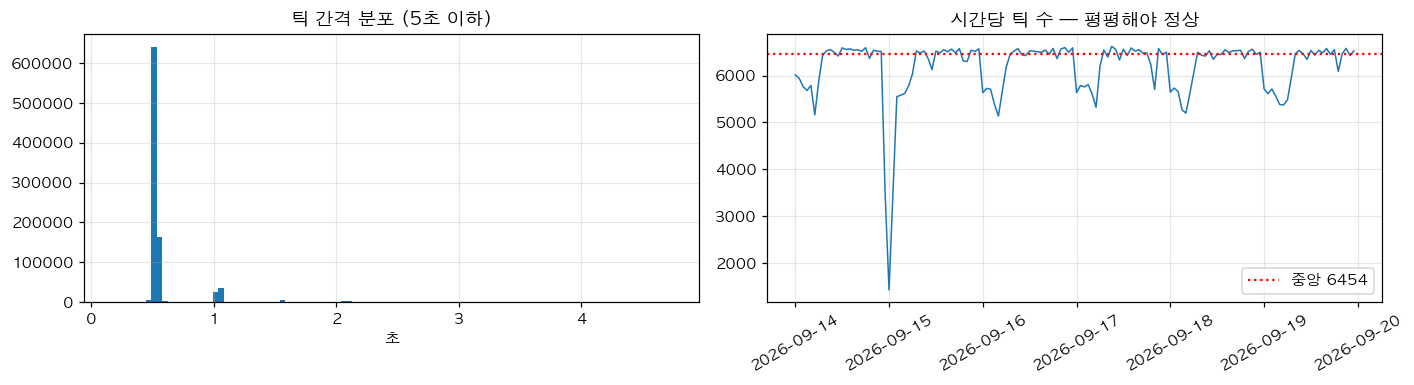


시간당 틱 수: 중앙 6454, 최소 1428, 최대 6625  (최소/중앙 = 0.22배)

=== 6. 저밀도 시간대 (중앙값의 80% 미만) ===
                       틱수  중앙대비  PREDICTIVE  DIAGNOSTIC
Time                                                   
2026-09-14 05:00:00  5161  0.80        4836         325
2026-09-14 23:00:00  3480  0.54        2418        1062
2026-09-15 00:00:00  1428  0.22          68        1360
2026-09-15 01:00:00  3515  0.54        2840         675
2026-09-16 04:00:00  5136  0.80        5136           0

  이 시간대 사이클은 N_Ticks / Steady_Std_* / Dip_Count 가
  설비 상태가 아니라 수집 밀도를 본다. 0-9 에서 영향을 측정한다.


In [8]:
print("=== 5. 틱 간격 ===")
gap = raw.index.to_series().diff().dt.total_seconds().dropna()
q = gap.quantile([.01, .25, .5, .75, .95, .99])
print(f"  중앙 {gap.median():.3f}초   평균 {gap.mean():.3f}초")
print("  분위:", "  ".join(f"p{int(k*100)}={v:.3f}s" for k, v in q.items()))
print(f"  최대 {gap.max():.1f}초 ({gap.max()/60:.1f}분)  <- 수집이 끊긴 구간")
print(f"  10초 넘는 구멍 {int((gap>10).sum())}개, 60초 넘는 구멍 {int((gap>60).sum())}개")

hourly = raw.index.to_series().resample("1h").size()
fig, ax = plt.subplots(1, 2, figsize=(13, 3.6))
ax[0].hist(gap[gap <= 5], bins=100, color="tab:blue")
ax[0].set_title("틱 간격 분포 (5초 이하)"); ax[0].set_xlabel("초"); ax[0].grid(alpha=.3)
ax[1].plot(hourly.index, hourly.values, lw=1)
ax[1].axhline(hourly.median(), ls=":", color="red", label=f"중앙 {hourly.median():.0f}")
ax[1].set_title("시간당 틱 수 — 평평해야 정상"); ax[1].grid(alpha=.3); ax[1].legend()
ax[1].tick_params(axis="x", rotation=30)
plt.tight_layout(); plt.show()

print(f"\n시간당 틱 수: 중앙 {hourly.median():.0f}, 최소 {hourly.min():.0f}, 최대 {hourly.max():.0f}"
      f"  (최소/중앙 = {hourly.min()/hourly.median():.2f}배)")

# ---- 저밀도 시간대 추출 ----
LOW_DENSITY_RATIO = 0.8
LOW_DENSITY_HOURS = hourly.index[hourly < hourly.median() * LOW_DENSITY_RATIO]
print(f"\n=== 6. 저밀도 시간대 (중앙값의 {LOW_DENSITY_RATIO*100:.0f}% 미만) ===")
if len(LOW_DENSITY_HOURS) == 0:
    print("  O 없음")
else:
    _src = (raw.groupby([raw.index.floor("h"), "source"]).size().unstack(fill_value=0)
            if "source" in raw.columns else None)
    _t = pd.DataFrame({"틱수": hourly.reindex(LOW_DENSITY_HOURS).astype(int),
                       "중앙대비": (hourly.reindex(LOW_DENSITY_HOURS)/hourly.median()).round(2)})
    if _src is not None:
        for c in ("PREDICTIVE", "DIAGNOSTIC"):
            if c in _src.columns:
                _t[c] = _src[c].reindex(LOW_DENSITY_HOURS).fillna(0).astype(int)
    print(_t.to_string())
    print("\n  이 시간대 사이클은 N_Ticks / Steady_Std_* / Dip_Count 가")
    print("  설비 상태가 아니라 수집 밀도를 본다. 0-9 에서 영향을 측정한다.")

---
## 0-8. 알람 / 공장정지 구간 — 통계에서 뺄 구간 정의

### 알람 판정

**`AL_Line_Bit`, `AL_MA_Bit`, `AL_Tank_Bit`, `AL_ETC_Bit` 중 하나라도 `!= 0` 이면 알람.**

현재 추출기는 `AL_Line_Bit` **하나만** 본다 (`Excluded_Alarm`). 실측 결과 이 규칙은
**사이클을 0개 제외한다** — `AL_Line_Bit` 가 안 떠서가 아니라(680틱 떴다),
**P1 이 가동 중일 때는 한 번도 안 떴기** 때문이다. 정작 가동 중에 겹치는 건 다른 둘이다:

| 태그 | 켜진 틱 | 그중 P1 가동 중 |
|---|---|---|
| `AL_Line_Bit` | 680 | **0** |
| `AL_MA_Bit` | 892 | 395 |
| `AL_Tank_Bit` | 3,237 | 535 |
| `AL_ETC_Bit` | 0 | 0 |

→ 4개를 OR 로 묶으면 **225 사이클(1.25%)** 이 걸린다. 현재 규칙으로는 0개다.

### 공장정지 판정

`Auto_Running == 0` 을 쓴다. 후보들을 비교한 결과:

| 태그 | 켜진 시간 비율 | 판정 |
|---|---|---|
| `Auto_Running` | 60.0% | **채택** — P1 가동틱 중 이게 0 인 건 0.14% 뿐 |
| `Auto_Running_PL` | 60.0% | `Auto_Running` 과 사실상 동일 |
| `Prepare` | 99.99% | 항상 1. 쓸모 없음 |
| `Emergency_Sw` / `Conv_Trip` | 0% | 이 구간엔 발생 없음 (그래도 같이 본다) |

### ★ 틱 단위로 걸러낸 df 를 추출기에 넣으면 안 된다

`raw_clean` 을 만들어 두긴 하지만 **거기서 `extract_cycle_features` 를 돌리면 안 된다.**
추출기는 `buildup.diff()` 로 사이클 경계를 잡고 `rolling(3)` 으로 딥을 판정한다.
중간을 잘라낸 시계열에 그걸 돌리면 **잘린 자리가 가짜 사이클 경계가 되고**,
`rolling` 이 시간적으로 떨어진 값을 이웃으로 착각한다.

올바른 순서:

```
raw (통째로) --extract_cycle_features--> cyc (플래그 포함) --필터--> cyc_clean
```

`raw_clean` 은 **틱 단위로 그림 그리거나 원본 분포 볼 때만** 쓴다.


In [9]:
# ==========================================
# 틱 단위 마스크
# ==========================================
present_alarm = [t for t in ALARM_TAGS if t in raw.columns]
missing_alarm = [t for t in ALARM_TAGS if t not in raw.columns]
if missing_alarm:
    print(f"! 알람 태그 누락: {missing_alarm} — 그만큼 덜 걸러진다")

alarm_any = (raw[present_alarm].fillna(0) != 0).any(axis=1)

if "Auto_Running" in raw.columns:
    line_stopped = raw["Auto_Running"].fillna(0) == 0
else:
    line_stopped = pd.Series(False, index=raw.index)
    print("! Auto_Running 없음 — 공장정지 판정 불가")

if "Emergency_Sw" in raw.columns:
    emergency = raw["Emergency_Sw"].fillna(0) != 0
else:
    emergency = pd.Series(False, index=raw.index)

dirty_tick = alarm_any | line_stopped | emergency
bu = raw[f"Pump_BuildUp_{PUMP_ID}"].astype(int)

print("=== 틱 단위 ===")
print(f"  전체 {len(raw):,}틱  (그중 P1 가동 {int((bu==1).sum()):,}틱)")
for name, m in [("알람(4개 OR)", alarm_any), ("공장정지(Auto_Running==0)", line_stopped),
                ("비상정지", emergency), ("합집합 = 더러운 틱", dirty_tick)]:
    print(f"  {name:26s} {int(m.sum()):8,}틱 ({m.mean()*100:5.2f}%)   "
          f"가동중 겹침 {int((m & (bu==1)).sum()):7,}틱")

print("\n  알람 태그별 내역")
for t in present_alarm:
    m = raw[t].fillna(0) != 0
    print(f"    {t:14s} {int(m.sum()):7,}틱   가동중 겹침 {int((m & (bu==1)).sum()):6,}틱")

# ==========================================
# raw_clean — 틱 단위 그림/분포용. 추출기에 넣지 말 것
# ==========================================
raw_clean = raw[~dirty_tick]
print("\n=== raw_clean ===")
print(f"  {len(raw_clean):,}행 / {len(raw):,}  ({len(raw_clean)/len(raw)*100:.2f}% 남음)")
print("  ※ 시계열이 중간중간 잘려 있다. extract_cycle_features 에 넣지 말 것.")

=== 틱 단위 ===
  전체 889,019틱  (그중 P1 가동 280,580틱)
  알람(4개 OR)                     4,808틱 ( 0.54%)   가동중 겹침     930틱
  공장정지(Auto_Running==0)       328,582틱 (36.96%)   가동중 겹침     396틱
  비상정지                              0틱 ( 0.00%)   가동중 겹침       0틱
  합집합 = 더러운 틱                 330,491틱 (37.17%)   가동중 겹침   1,326틱

  알람 태그별 내역
    AL_Line_Bit        680틱   가동중 겹침      0틱
    AL_MA_Bit          892틱   가동중 겹침    395틱
    AL_Tank_Bit      3,237틱   가동중 겹침    535틱
    AL_ETC_Bit           0틱   가동중 겹침      0틱

=== raw_clean ===
  558,528행 / 889,019  (62.83% 남음)
  ※ 시계열이 중간중간 잘려 있다. extract_cycle_features 에 넣지 말 것.


---
## 0-9. 사이클 피처 추출

여기까지 통과했으면 추출기를 돌린다. 이후 섹션은 전부 이 `cyc` 를 본다.

In [10]:
cyc, cycles_meta = extract_cycle_features(raw, PUMP_ID)

print(f"사이클 {len(cyc):,}개 x 컬럼 {cyc.shape[1]}개")
print(f"  {cyc['Start_Time'].min()} ~ {cyc['End_Time'].max()}")
print(f"  일자별: {dict((str(k.date()), int(v)) for k, v in cyc.groupby(pd.to_datetime(cyc['Start_Time']).dt.normalize()).size().items())}")
print()
print("제외 규칙별 건수")
print(f"  야간({DAILY_EXCLUDE_START}~{DAILY_EXCLUDE_END}) 시작 : {int(cyc['Excluded_DailyWindow'].sum()):6,}")
print(f"  AL_Line_Bit == 1                  : {int(cyc['Excluded_Alarm'].sum()):6,}")
print(f"  Prev_SV == 0 (구간 첫 사이클)      : {int((cyc['Prev_SV']==0).sum()):6,}")
print(f"  Decay 포인트 부족 -> NaN           : {int(cyc['Decay_Slope_PT'].isna().sum()):6,}")
print(f"  Cold_Start (직전 종료 후 30분+)    : {int(cyc['Cold_Start'].sum()):6,}")
print(f"  RampUp 목표 미진입 -> NaN          : {int(cyc['RampUp_Time_Sec'].isna().sum()):6,}")

FEATURE_COLS = [
    "N_Ticks","SV_mean","FT_mean","FT_max","FT_std","PT_mean","PT_max","PT_std",
    "Ana_Out_mean","Temp_mean","Prev_SV","Prev_SV_Diff","PreBuildUp_PT","PreBuildUp_FT",
    "PT_Jump_From_Pre","FT_Jump_From_Pre","Instant_FT_Error_Rate_mean","Instant_FT_Error_Rate_max",
    "Cum_FT_Error","RampUp_Time_Sec","DeltaP_over_Q","Current_Proxy_I","Steady_Std_PT","Steady_Std_FT",
    "Ramp_Negative_Slope_Count","Unexplained_PT_Dip_Count","Unexplained_PT_Dip_Max",
    "Unexplained_FT_Dip_Count","Unexplained_FT_Dip_Max","Decay_Slope_PT","Decay_Slope_FT",
]
assert len(FEATURE_COLS) == 31
clean = cyc[~cyc["Excluded"]].dropna(subset=FEATURE_COLS)
print(f"\n-> 학습 가용 사이클 : {len(clean):,} / {len(cyc):,}  ({len(clean)/len(cyc)*100:.1f}%)")

# ==========================================
# 저밀도 시간대 플래그 (왜곡 여부는 0-10 에서 알람과 분리해서 본다)
# ==========================================
_st = pd.to_datetime(cyc["Start_Time"])
cyc["In_Low_Density"] = _st.dt.floor("h").isin(LOW_DENSITY_HOURS)
_n = int(cyc["In_Low_Density"].sum())
print(f"\n=== 저밀도 시간대에 시작한 사이클 {_n:,}개 ({_n/len(cyc)*100:.2f}%) ===")
print("  이게 실제로 피처를 왜곡하는지는 0-10 에서 알람/정지와 분리해서 확인한다.")
print("  (겹쳐 있어서 같이 보면 알람의 효과를 저밀도 탓으로 오해한다)")

cyc.head(3).T

사이클 18,063개 x 컬럼 40개
  2026-09-14 05:42:34.140251 ~ 2026-09-19 23:56:11.119382
  일자별: {'2026-09-14': 2978, '2026-09-15': 2964, '2026-09-16': 2974, '2026-09-17': 3051, '2026-09-18': 2921, '2026-09-19': 3175}

제외 규칙별 건수
  야간(23:50~07:00) 시작 :    303
  AL_Line_Bit == 1                  :      0
  Prev_SV == 0 (구간 첫 사이클)      :      1
  Decay 포인트 부족 -> NaN           :    254
  Cold_Start (직전 종료 후 30분+)    :     18
  RampUp 목표 미진입 -> NaN          :      5

-> 학습 가용 사이클 : 17,566 / 18,063  (97.2%)

=== 저밀도 시간대에 시작한 사이클 207개 (1.15%) ===
  이게 실제로 피처를 왜곡하는지는 0-10 에서 알람/정지와 분리해서 확인한다.
  (겹쳐 있어서 같이 보면 알람의 효과를 저밀도 탓으로 오해한다)


Cycle_ID,1,3,5
Start_Time,2026-09-14 05:42:34.140251,2026-09-14 06:51:47.961562,2026-09-14 06:52:39.081177
End_Time,2026-09-14 05:42:37.795802,2026-09-14 06:51:55.887395,2026-09-14 06:52:46.952132
N_Ticks,8,16,14
SV_mean,2980.0,2010.0,2260.0
FT_mean,2497.75,1906.5,2122.642857
FT_max,2965.0,2020.0,2249.0
FT_std,660.649194,250.275848,290.360415
PT_mean,136.375,99.4375,107.928571
PT_max,144.0,103.0,114.0
PT_std,13.978938,4.661455,10.087801


---
## 0-10. `cyc_clean` — 통계용 사이클

사이클 구간에 알람/정지가 **하나라도 걸쳐 있으면** 뺀다. 구간은
`[Start_Time, End_Time + DECAY_WINDOW_SEC]` 로 잡는다 — `Decay_Slope_*` 가
종료 후 3초를 쓰기 때문에 그 창까지 깨끗해야 한다.

두 개를 다 들고 간다.

| 이름 | 내용 | 용도 |
|---|---|---|
| `cyc` | 전체 + 플래그 컬럼 | 알람 구간이 어떻게 생겼는지 볼 때 |
| `cyc_clean` | 알람/정지/야간/저밀도/NaN 제거 | **통계·분포·AE 학습** |

### 저밀도와 알람은 분리해서 봐야 한다

`In_Low_Density` 207개 중 **131개가 알람/정지와 겹친다.** 둘을 묶어서 비교하면
알람이 만든 차이가 저밀도 탓으로 보인다. 실제로 분해하면:

| 그룹 | 개수 | `N_Ticks` | `Steady_Std_FT` |
|---|---|---|---|
| 정상 | 17,700 | 16.0 | 130.5 |
| **저밀도만** | 76 | **16.0** | **141.5** |
| 알람/정지만 | 156 | **4.0** | **10.6** |
| 둘다 | 131 | 4.0 | 9.2 |

**저밀도 자체는 피처를 왜곡하지 않는다.** 왜곡의 원인은 알람이다 —
알람이 뜨면 펌프가 조기에 꺼져서 16틱짜리 사이클이 4틱이 되고,
그 짧은 구간에서 낸 `Steady_Std_FT` 가 13배 작게 나온다.

`cyc_clean` 에서 저밀도도 같이 빼긴 하지만(76개 추가 손실, 0.4%),
**꼭 빼야 하는 건 알람/정지 쪽**이다.


In [11]:
# 사이클 구간 [Start, End + DECAY_WINDOW_SEC] 에 마스크가 하나라도 겹치는지
_st = pd.to_datetime(cyc["Start_Time"]).values
_et = (pd.to_datetime(cyc["End_Time"]) + pd.Timedelta(seconds=DECAY_WINDOW_SEC)).values
_idx = raw.index.values

def overlaps(mask):
    """mask(틱 단위 bool) 가 각 사이클 구간에 하나라도 걸치면 True"""
    t = _idx[mask.values]
    if len(t) == 0:
        return np.zeros(len(cyc), dtype=bool)
    return np.searchsorted(t, _et, side="right") > np.searchsorted(t, _st, side="left")

cyc["Alarm_Any"]    = overlaps(alarm_any)
cyc["Line_Stopped"] = overlaps(line_stopped)
cyc["Emergency"]    = overlaps(emergency)
cyc["Dirty"]        = cyc["Alarm_Any"] | cyc["Line_Stopped"] | cyc["Emergency"]

print(f"전체 {len(cyc):,} 사이클 중 (구간 = Start ~ End+{DECAY_WINDOW_SEC:.0f}s)")
print(f"  알람 4개 OR 걸침  : {int(cyc['Alarm_Any'].sum()):5,} ({cyc['Alarm_Any'].mean()*100:.2f}%)")
print(f"  공장정지 걸침     : {int(cyc['Line_Stopped'].sum()):5,} ({cyc['Line_Stopped'].mean()*100:.2f}%)")
print(f"  비상정지 걸침     : {int(cyc['Emergency'].sum()):5,}")
print(f"  -> Dirty (합집합) : {int(cyc['Dirty'].sum()):5,} ({cyc['Dirty'].mean()*100:.2f}%)")
print()
print("  비교: 현재 추출기의 Excluded_Alarm (AL_Line_Bit 하나만)")
print(f"     {int(cyc['Excluded_Alarm'].sum()):5,} 개  <- 0 이면 그 규칙이 아무것도 못 걸렀다는 뜻")

# ==========================================
# cyc_clean
# ==========================================
drop_reason = pd.DataFrame({
    "알람/정지 (Dirty)":       cyc["Dirty"],
    "야간 (DailyWindow)":      cyc["Excluded_DailyWindow"],
    "저밀도 (In_Low_Density)": cyc["In_Low_Density"],
    "Prev_SV == 0":            cyc["Prev_SV"] == 0,
    "피처 NaN":                cyc[FEATURE_COLS].isna().any(axis=1),
})
keep = ~drop_reason.any(axis=1)
cyc_clean = cyc[keep].copy()

print("\n=== 제외 사유별 (중복 카운트) ===")
for c in drop_reason.columns:
    print(f"  {c:24s} {int(drop_reason[c].sum()):5,}")
print(f"\n=== cyc_clean : {len(cyc_clean):,} / {len(cyc):,}  ({len(cyc_clean)/len(cyc)*100:.2f}% 남음) ===")
print(f"  {cyc_clean['Start_Time'].min()} ~ {cyc_clean['Start_Time'].max()}")
_d = cyc_clean.groupby(pd.to_datetime(cyc_clean["Start_Time"]).dt.normalize()).size()
print("  일자별: " + ", ".join(f"{k.date()} {int(v):,}" for k, v in _d.items()))

# ==========================================
# ★ 알람 효과와 저밀도 효과를 분리해서 본다
#   둘이 겹쳐 있어서(저밀도 207 중 131 이 Dirty) 같이 보면
#   알람 때문에 생긴 차이를 저밀도 탓으로 오해한다.
# ==========================================
print("\n=== 마스크 겹침 ===")
print(pd.crosstab(cyc["In_Low_Density"], cyc["Dirty"], margins=True).to_string())

_cols = ["N_Ticks","PT_mean","FT_mean","Steady_Std_FT","RampUp_Time_Sec",
         "Instant_FT_Error_Rate_mean","DeltaP_over_Q"]
groups = {
    "정상(둘다아님)": ~cyc["Dirty"] & ~cyc["In_Low_Density"],
    "저밀도만":       cyc["In_Low_Density"] & ~cyc["Dirty"],
    "알람/정지만":    cyc["Dirty"] & ~cyc["In_Low_Density"],
    "둘다":           cyc["Dirty"] & cyc["In_Low_Density"],
}
tbl = pd.DataFrame({k: cyc.loc[m, _cols].median() for k, m in groups.items()}).round(3)
tbl.loc["개수"] = [int(m.sum()) for m in groups.values()]
print("\n=== 그룹별 중앙값 ===")
print(tbl.to_string())

print("\n읽는 법")
print("  · '저밀도만' 이 '정상' 과 비슷하면 -> 저밀도 자체는 피처를 왜곡하지 않는다")
print("  · '알람/정지만' 의 N_Ticks 가 훨씬 작으면 -> 알람이 사이클을 중간에 끊은 것이다")
print("    (펌프가 조기에 꺼져 16틱짜리가 4틱이 된다. 그래서 Steady_Std_* 도 같이 작아진다)")
print("  · 즉 통계에서 반드시 빼야 하는 건 알람/정지 쪽이다.")

전체 18,063 사이클 중 (구간 = Start ~ End+3s)
  알람 4개 OR 걸침  :   234 (1.30%)
  공장정지 걸침     :    62 (0.34%)
  비상정지 걸침     :     0
  -> Dirty (합집합) :   287 (1.59%)

  비교: 현재 추출기의 Excluded_Alarm (AL_Line_Bit 하나만)
         0 개  <- 0 이면 그 규칙이 아무것도 못 걸렀다는 뜻

=== 제외 사유별 (중복 카운트) ===
  알람/정지 (Dirty)              287
  야간 (DailyWindow)           303
  저밀도 (In_Low_Density)       207
  Prev_SV == 0                 1
  피처 NaN                     254

=== cyc_clean : 17,443 / 18,063  (96.57% 남음) ===
  2026-09-14 07:00:36.004983 ~ 2026-09-19 23:49:26.492859
  일자별: 2026-09-14 2,733, 2026-09-15 2,892, 2026-09-16 2,907, 2026-09-17 2,954, 2026-09-18 2,854, 2026-09-19 3,103

=== 마스크 겹침 ===
Dirty           False  True    All
In_Low_Density                    
False           17700   156  17856
True               76   131    207
All             17776   287  18063

=== 그룹별 중앙값 ===
                             정상(둘다아님)      저밀도만    알람/정지만        둘다
N_Ticks                        16.000    16.000     4.000     4.000


---
# 1. 기본 통계 피처 10개 검증

`N_Ticks`, `SV_mean`, `FT_mean`, `FT_max`, `FT_std`, `PT_mean`, `PT_max`, `PT_std`,
`Ana_Out_mean`, `Temp_mean`

10개를 한 그림에 몰아넣으면 아무것도 안 보인다. **피처 하나씩, 왜 그 그림인지 밝히고** 본다.

## 1-0. 시각화 도구를 왜 matplotlib 으로 쓰나

| 후보 | 판단 |
|---|---|
| **matplotlib** | **채택.** 이 리포의 기존 노트북 전부가 이걸 쓴다(`train_pump.ipynb`, 설명서). 정적 PNG 로 박혀서 `.ipynb` 를 열면 커널 없이도 그림이 보인다 — 팀원 리뷰용으로 이게 결정적이다 |
| plotly | 설치돼 있고(6.6.0) 호버가 편하지만, 그림마다 JS+데이터를 노트북에 박는다. `vis.ipynb` 가 이미 2.4MB 다. 17,443 사이클 산점도를 plotly 로 그리면 파일이 수십 MB 로 뛴다 |
| seaborn | 설치돼 있고(0.13.2) 분포 그림이 짧게 나오지만, 여기서 필요한 건 "기준선 긋고 특정 구간만 강조" 라서 matplotlib 저수준 제어가 오히려 편하다 |

즉 **정적 + 저용량 + 커널 없이 읽힘** 이 기준이고 matplotlib 이 맞다.
대화형 탐색이 필요한 순간에만 그때 plotly 를 꺼낸다.

## 그림을 그릴 때 지키는 규칙

1. **일의 종류가 그림을 정한다** — 분포는 히스토그램, 시간 흐름은 선, 정체 비교는 막대,
   상관은 히트맵. 색은 **맨 마지막에** 정한다
2. **강조(emphasis) 형태를 기본으로 쓴다** — 관심 대상 1개만 색, 나머지는 회색.
   계열마다 색을 돌려쓰면 정작 중요한 하나가 묻힌다
3. **이중 축(`twinx`) 금지** — 두 y축은 단위가 다른 두 양을 겹쳐 놓아 "교차점" 같은
   존재하지 않는 관계를 만든다. 설명서 노트북이 PT/FT 를 `twinx` 로 그렸는데,
   여기서는 상하 2단(`sharex`)으로 쪼갠다
4. **색맹 안전 검증을 통과한 팔레트만 쓴다** — 아래 3색은 전체 쌍 기준으로
   CVD ΔE 9.2, 정상시야 ΔE 24.0 을 통과했다. 다만 aqua 는 밝은 배경 대비 2.74:1 로
   3:1 미만이라 **직접 라벨을 반드시 붙인다**
5. **격자와 축은 뒤로 물린다** — 데이터가 주인공이다


In [12]:
# ==========================================
# 시각화 공통 설정 — 검증 통과한 팔레트
#   node validate_palette.js "#2a78d6,#eb6834,#1baf7a" --mode light --pairs all
#     PASS 명도대역 / 채도하한 / CVD ΔE 9.2 / 정상시야 ΔE 24.0
#     WARN aqua 대비 2.74:1 -> 직접 라벨 필수
# ==========================================
C1, C2, C3 = "#2a78d6", "#eb6834", "#1baf7a"   # blue / orange / aqua
GRAY   = "#a8a7a1"      # 맥락용 (강조 아닌 것)
INK    = "#0b0b0b"      # 주 텍스트
INK2   = "#52514e"      # 보조 텍스트
BAD    = "#e34948"      # 경고/기준 위반

def ax_style(ax, title=None, xlabel=None, ylabel=None):
    """격자·축을 뒤로 물리고 위/오른쪽 테두리를 없앤다."""
    ax.grid(True, alpha=.25, lw=.7, color=GRAY)
    ax.set_axisbelow(True)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    for side in ("left", "bottom"):
        ax.spines[side].set_color(GRAY)
    ax.tick_params(colors=INK2, labelsize=9)
    if title:  ax.set_title(title, fontsize=11, color=INK, pad=10)
    if xlabel: ax.set_xlabel(xlabel, fontsize=9.5, color=INK2)
    if ylabel: ax.set_ylabel(ylabel, fontsize=9.5, color=INK2)
    return ax

matplotlib.rcParams.update({
    "figure.facecolor": "white", "axes.facecolor": "white",
    "lines.linewidth": 2, "lines.markersize": 5,
})

# 이 섹션이 보는 대상
BASE_COLS = ["N_Ticks","SV_mean","FT_mean","FT_max","FT_std",
             "PT_mean","PT_max","PT_std","Ana_Out_mean","Temp_mean"]
S = cyc_clean          # 통계는 항상 clean 으로. cyc 는 비교용으로만 꺼낸다
print(f"대상: cyc_clean {len(S):,} 사이클 x 기본통계 {len(BASE_COLS)}개")
print(f"기간: {S['Start_Time'].min()} ~ {S['Start_Time'].max()}")
print()
print(S[BASE_COLS].describe().T.round(2).to_string())

대상: cyc_clean 17,443 사이클 x 기본통계 10개
기간: 2026-09-14 07:00:36.004983 ~ 2026-09-19 23:49:26.492859

                count     mean      std      min      25%      50%       75%       max
N_Ticks       17443.0    15.68     1.93     5.00    15.00    16.00     16.00     24.00
SV_mean       17443.0  2334.47   266.76  2010.00  2150.00  2300.00   2667.02   2850.00
FT_mean       17443.0  2155.26   212.95  1840.08  1985.10  2114.82   2399.96   2600.00
FT_max        17443.0  2333.33   259.44  2001.00  2147.00  2280.00   2658.00   2863.00
FT_std        17443.0   347.20   100.65     9.98   269.14   320.58    433.98    647.46
PT_mean       17443.0   103.54    12.71    83.00    92.93    99.67    116.67    140.44
PT_max        17443.0   109.81    13.53    87.00    98.00   106.00    124.00    154.00
PT_std        17443.0     8.27     3.85     0.55     4.87     7.66     10.53     22.75
Ana_Out_mean  17443.0  9732.21  1115.96  8367.00  8950.00  9574.00  11113.48  11894.00
Temp_mean     17443.0   218.31   

---
## 1-1. `N_Ticks` — 사이클이 몇 틱이었나

설명서의 설명: *"평소보다 길거나 짧으면 뭔가 다른 것"*

**그림 선택**: 두 가지 일을 봐야 한다.
- *이 값이 어떻게 흩어져 있나* → **히스토그램** (분포는 정체가 아니라 크기 문제 → 단일 색)
- *시간이 지나며 변했나* → **선 + 사분위 띠** (시간 흐름)

`N_Ticks` 는 정수라서 시간당 **중앙값**을 그리면 15↔16 계단만 오가는 무의미한 톱니가 된다.
그래서 **평균 + IQR 띠**로 그린다.

### 확인할 것: 이게 '길이' 인가 '로그 밀도' 인가

`N_Ticks` 는 **"틱"** 을 센다. 틱은 시간 간격이 아니라 **DB에 줄이 찍힌 횟수**다.
그래서 원리상 이 값은 두 가지를 섞어서 본다.

```
N_Ticks  =  사이클이 실제로 길었나  ×  그동안 로그가 촘촘히 찍혔나
```

아래에서 실제 지속시간(초)과 비교해 둘 중 어느 쪽이 지배적인지 확인한다.
`틱당 시간` 분포가 좁으면 앞쪽(길이)이 지배적이라는 뜻이다.


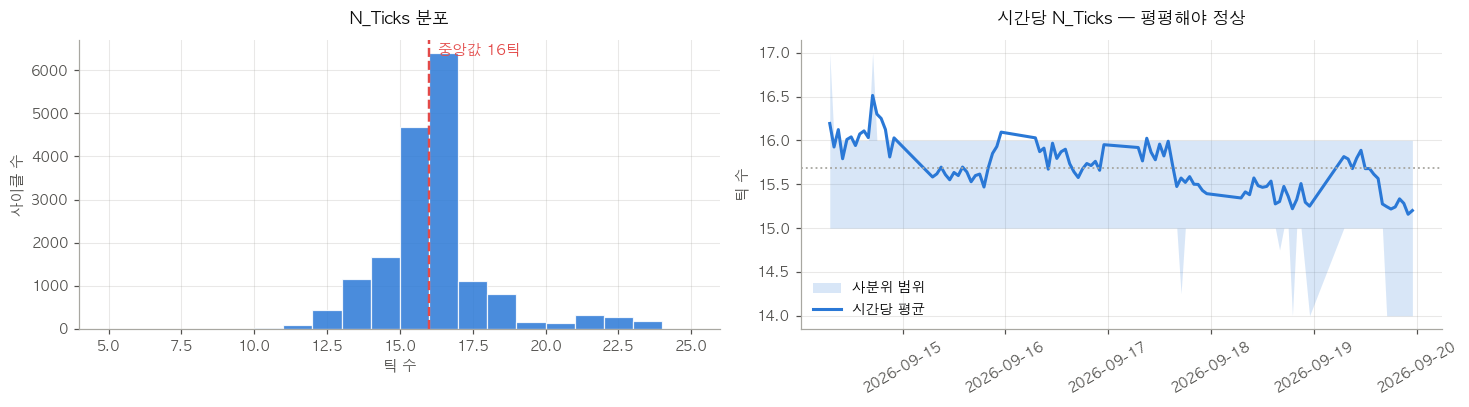

N_Ticks   중앙 16틱   p1 12   p99 23   범위 5~24
지속시간  중앙 7.82초  p1 5.79   p99 11.47

=== N_Ticks vs 실제 지속시간(초) ===
  상관계수 : +0.9309
  틱당 평균 간격 : 0.492초  (p5 0.483 / p95 0.558)


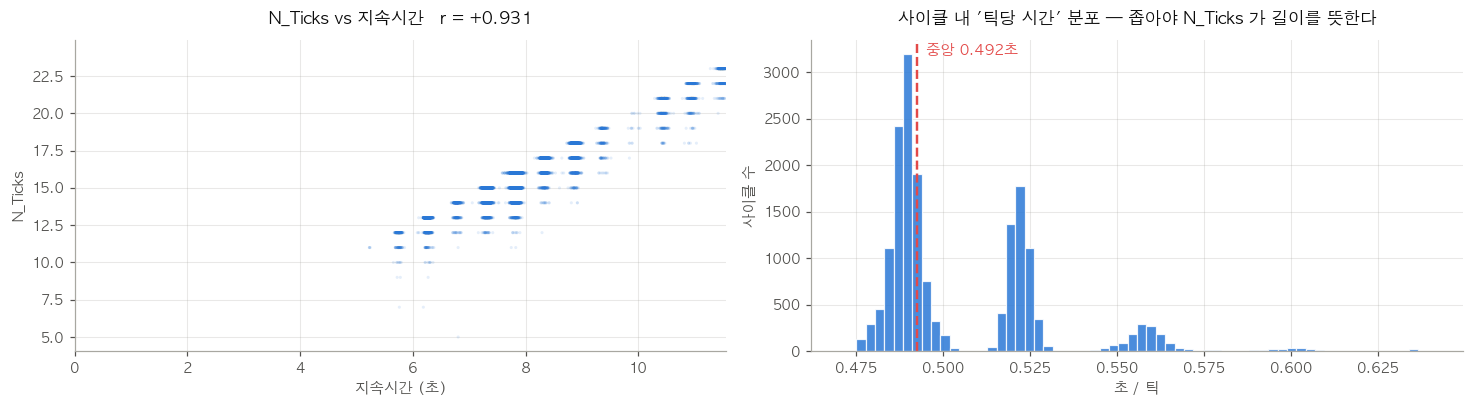


읽는 법
  · r 이 1 에 가깝고 '틱당 시간' 분포가 좁으면 -> N_Ticks 는 사실상 '길이(초)' 다
  · 분포가 넓거나 꼬리가 길면 -> 같은 길이의 사이클이 로그 밀도에 따라
    다른 N_Ticks 를 받는다. 그때 N_Ticks 는 설비가 아니라 수집기를 본다.
  · 대안: N_Ticks 를 지속시간(초)으로 바꾸면 수집 밀도와 무관해진다.

판정: 틱당 시간 p5~p95 폭이 중앙값의 15.3%
  -> 이 구간에서 N_Ticks 는 사실상 지속시간이다 (= 지속시간 / 0.492초).
     지금 데이터에서는 문제 없다.
  -> 다만 이건 '로거가 정상일 때' 의 이야기다. 0-7 에서 본 대로
     09-26~27 처럼 로거가 열화되면 같은 길이 사이클이 16틱 -> 4틱 이 된다.
     설비는 멀쩡한데 AE 가 전부 이상으로 판정한다 = 실시간 배포 시의 고장모드.
     대책: N_Ticks 대신 지속시간(초)을 쓰거나, 로거 밀도를 별도 감시한다.


In [13]:
dur = (pd.to_datetime(S["End_Time"]) - pd.to_datetime(S["Start_Time"])).dt.total_seconds()
st  = pd.to_datetime(S["Start_Time"])

fig, ax = plt.subplots(1, 2, figsize=(13.5, 3.8))

# --- 왼쪽: 분포 (히스토그램, 단일 색) ---
v = S["N_Ticks"]
ax[0].hist(v, bins=range(int(v.min()), int(v.max()) + 2), color=C1, alpha=.85,
           edgecolor="white", linewidth=.8)
med = v.median()
ax[0].axvline(med, color=BAD, ls="--", lw=1.6)
ax[0].annotate(f"중앙값 {med:.0f}틱", xy=(med, 1.0), xycoords=("data", "axes fraction"),
               xytext=(6, -10), textcoords="offset points", color=BAD, fontsize=9.5)
ax_style(ax[0], "N_Ticks 분포", "틱 수", "사이클 수")

# --- 오른쪽: 시간 흐름 (시간당 중앙값, 강조 형태) ---
_h = pd.DataFrame({"t": st, "n": v}).set_index("t")["n"].resample("1h")
h = pd.DataFrame({"mean": _h.mean(), "q1": _h.quantile(.25), "q3": _h.quantile(.75)}).dropna()
ax[1].fill_between(h.index, h["q1"], h["q3"], color=C1, alpha=.18, lw=0, label="사분위 범위")
ax[1].plot(h.index, h["mean"], color=C1, lw=2, label="시간당 평균")
ax[1].axhline(v.mean(), color=GRAY, ls=":", lw=1.2)
ax_style(ax[1], "시간당 N_Ticks — 평평해야 정상", None, "틱 수")
ax[1].tick_params(axis="x", rotation=30)
ax[1].legend(frameon=False, fontsize=9, loc="lower left")
plt.tight_layout(); plt.show()

print(f"N_Ticks   중앙 {v.median():.0f}틱   p1 {v.quantile(.01):.0f}   p99 {v.quantile(.99):.0f}   범위 {v.min():.0f}~{v.max():.0f}")
print(f"지속시간  중앙 {dur.median():.2f}초  p1 {dur.quantile(.01):.2f}   p99 {dur.quantile(.99):.2f}")

# ==========================================
# 핵심 검증: N_Ticks 가 '길이' 를 보는가, '로그 밀도' 를 보는가
# ==========================================
print("\n=== N_Ticks vs 실제 지속시간(초) ===")
print(f"  상관계수 : {v.corr(dur):+.4f}")
print(f"  틱당 평균 간격 : {(dur/v).median():.3f}초  (p5 {(dur/v).quantile(.05):.3f} / p95 {(dur/v).quantile(.95):.3f})")

fig, ax = plt.subplots(1, 2, figsize=(13.5, 3.8))
ax[0].scatter(dur, v, s=4, alpha=.12, color=C1, edgecolors="none")
ax[0].set_xlim(0, dur.quantile(.999))
ax_style(ax[0], f"N_Ticks vs 지속시간   r = {v.corr(dur):+.3f}", "지속시간 (초)", "N_Ticks")

# 틱당 간격이 사이클마다 다르면 N_Ticks 는 길이를 못 잰다
per = dur / v
_lo, _hi = per.quantile(.001), per.quantile(.999)
ax[1].hist(per.clip(_lo, _hi), bins=60, color=C1, alpha=.85, edgecolor="white", linewidth=.8)
ax[1].set_xlim(_lo - (_hi-_lo)*.08, _hi + (_hi-_lo)*.08)
ax[1].axvline(per.median(), color=BAD, ls="--", lw=1.6)
ax[1].annotate(f"중앙 {per.median():.3f}초", xy=(per.median(), 1.0),
               xycoords=("data", "axes fraction"), xytext=(6, -10),
               textcoords="offset points", color=BAD, fontsize=9.5)
ax_style(ax[1], "사이클 내 '틱당 시간' 분포 — 좁아야 N_Ticks 가 길이를 뜻한다",
         "초 / 틱", "사이클 수")
plt.tight_layout(); plt.show()

print("\n읽는 법")
print("  · r 이 1 에 가깝고 '틱당 시간' 분포가 좁으면 -> N_Ticks 는 사실상 '길이(초)' 다")
print("  · 분포가 넓거나 꼬리가 길면 -> 같은 길이의 사이클이 로그 밀도에 따라")
print("    다른 N_Ticks 를 받는다. 그때 N_Ticks 는 설비가 아니라 수집기를 본다.")
print("  · 대안: N_Ticks 를 지속시간(초)으로 바꾸면 수집 밀도와 무관해진다.")

_spread = (per.quantile(.95) - per.quantile(.05)) / per.median() * 100
print(f"\n판정: 틱당 시간 p5~p95 폭이 중앙값의 {_spread:.1f}%")
if v.corr(dur) > .9 and _spread < 25:
    print(f"  -> 이 구간에서 N_Ticks 는 사실상 지속시간이다 (= 지속시간 / {per.median():.3f}초).")
    print("     지금 데이터에서는 문제 없다.")
    print("  -> 다만 이건 '로거가 정상일 때' 의 이야기다. 0-7 에서 본 대로")
    print("     09-26~27 처럼 로거가 열화되면 같은 길이 사이클이 16틱 -> 4틱 이 된다.")
    print("     설비는 멀쩡한데 AE 가 전부 이상으로 판정한다 = 실시간 배포 시의 고장모드.")
    print("     대책: N_Ticks 대신 지속시간(초)을 쓰거나, 로거 밀도를 별도 감시한다.")
else:
    print("  -> N_Ticks 가 길이를 제대로 못 재고 있다. 지속시간(초)으로 바꿔야 한다.")

---
## 1-2. `SV_mean` — 목표 유량 설정값

설명서의 설명: *"목표 유량 설정값 (레시피마다 다름)"*

**그림 선택**: `SV_mean` 은 연속값이 아니라 **몇 개의 정해진 단계**를 오간다.
- *어떤 단계가 있고 각각 얼마나 쓰였나* → **수평 막대** (정체가 아니라 빈도 비교 → 단일 색)
- *어떤 순서로 오가나* → **계단 선**(`steps-post`). 설정값은 계단처럼 변하므로
  점을 직선으로 이으면 없던 중간값을 그리게 된다

### 왜 이 피처가 위험한가

`SV_mean` 은 **측정값이 아니라 사람이 넣은 지시값**이다. 설비 건강과 무관하게 바뀐다.
그런데 아래에서 보듯 이 값이 **거의 매 사이클 바뀐다.** 그러면 AE 는
"설비가 정상인가" 가 아니라 "지금 몇 번 레시피인가" 를 재구성하는 데 용량을 쓴다.


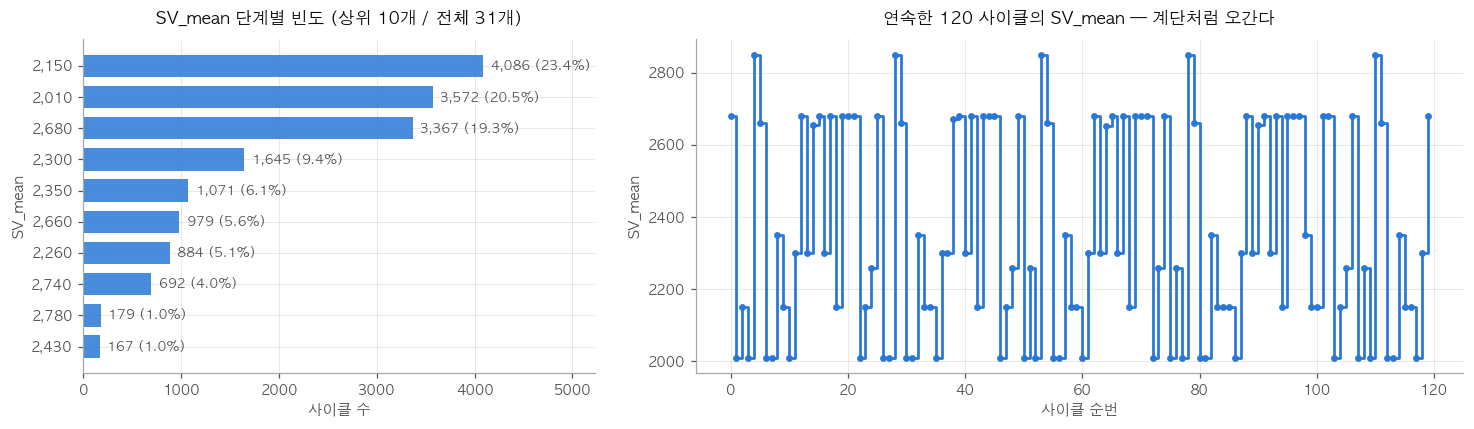

=== SV_mean 이 바뀌는 빈도 ===
  서로 다른 단계 수            : 31개
  직전 사이클과 SV 가 다른 비율 : 85.7%  (14,946 / 17,443)
  (추출기 자체 지표) Prev_SV_Diff != 0 : 85.5%
  같은 SV 가 연속 유지되는 길이 : 중앙 1 사이클 / 최대 4 사이클

읽는 법
  · 이 비율이 높으면 SV 는 '레시피 구간' 이 아니라 '매 사이클 도는 회전값' 이다
  · 그러면 SV_mean 을 원시값으로 넣는 것은 AE 에게 회전 패턴을 외우라는 뜻이 된다
  · 설명서가 Prev_SV / Prev_SV_Diff 를 둔 이유가 여기 있다 — 다만 그건
    '바뀌었다' 는 사실만 알려주고, FT/PT 의 절대값이 SV 에 끌려가는 건 그대로다
    (1-3 에서 그 끌려감을 상관계수로 확인한다)


In [14]:
sv = S["SV_mean"].round(0)
vc = sv.value_counts().sort_values(ascending=False)
top = vc.head(10)

fig, ax = plt.subplots(1, 2, figsize=(13.5, 4.0),
                       gridspec_kw={"width_ratios": [1, 1.5]})

# --- 왼쪽: 어떤 단계가 얼마나 (수평 막대) ---
ypos = np.arange(len(top))[::-1]
ax[0].barh(ypos, top.values, color=C1, alpha=.85, height=.72)
ax[0].set_yticks(ypos, [f"{int(k):,}" for k in top.index])
for y, val in zip(ypos, top.values):                     # 직접 라벨
    ax[0].annotate(f"{val:,} ({val/len(S)*100:.1f}%)", xy=(val, y), xytext=(5, 0),
                   textcoords="offset points", va="center", fontsize=8.5, color=INK2)
ax[0].set_xlim(0, top.max() * 1.28)
ax_style(ax[0], f"SV_mean 단계별 빈도 (상위 {len(top)}개 / 전체 {sv.nunique()}개)",
         "사이클 수", "SV_mean")

# --- 오른쪽: 순서 (계단 선) ---
seg = S.sort_values("Start_Time").head(120)
ax[1].step(range(len(seg)), seg["SV_mean"].values, where="post", color=C1, lw=1.8)
ax[1].scatter(range(len(seg)), seg["SV_mean"].values, s=12, color=C1, zorder=3)
ax_style(ax[1], "연속한 120 사이클의 SV_mean — 계단처럼 오간다",
         "사이클 순번", "SV_mean")
plt.tight_layout(); plt.show()

# ==========================================
# 핵심 검증: 레시피가 얼마나 자주 바뀌나
# ==========================================
Ss = S.sort_values("Start_Time")
changed = Ss["SV_mean"].diff().fillna(0) != 0
print("=== SV_mean 이 바뀌는 빈도 ===")
print(f"  서로 다른 단계 수            : {sv.nunique()}개")
print(f"  직전 사이클과 SV 가 다른 비율 : {changed.mean()*100:.1f}%  ({int(changed.sum()):,} / {len(Ss):,})")
print(f"  (추출기 자체 지표) Prev_SV_Diff != 0 : {(S['Prev_SV_Diff']!=0).mean()*100:.1f}%")
runs = (~changed).astype(int).groupby(changed.cumsum()).size()
print(f"  같은 SV 가 연속 유지되는 길이 : 중앙 {runs.median():.0f} 사이클 / 최대 {runs.max()} 사이클")
print()
print("읽는 법")
print("  · 이 비율이 높으면 SV 는 '레시피 구간' 이 아니라 '매 사이클 도는 회전값' 이다")
print("  · 그러면 SV_mean 을 원시값으로 넣는 것은 AE 에게 회전 패턴을 외우라는 뜻이 된다")
print("  · 설명서가 Prev_SV / Prev_SV_Diff 를 둔 이유가 여기 있다 — 다만 그건")
print("    '바뀌었다' 는 사실만 알려주고, FT/PT 의 절대값이 SV 에 끌려가는 건 그대로다")
print("    (1-3 에서 그 끌려감을 상관계수로 확인한다)")

---
## 1-3. 10개가 서로 얼마나 겹치나 — 이 섹션의 결론

**그림 선택**: 상관계수는 크기가 아니라 **극성**(양/음)을 가진 값이다.
그래서 **발산형(diverging) 히트맵** — 두 색 + **중간은 중성 회색**으로 그린다.
무지개 팔레트나 중간에 색이 있는 팔레트를 쓰면 0 근처가 눈에 튀어서 없는 구조를 만든다.

이어서 **PCA 누적 설명분산**을 선으로 본다 — "이 피처들이 실제로 몇 차원인가".

### 비교 대상을 헷갈리면 안 된다

두 개의 오토인코더가 리포에 있다.

| 파일 | 구조 | 용도 |
|---|---|---|
| `Pump_AE.PumpAutoencoder` | `input -> 8 -> 4 -> 8 -> input` (병목 **4**) | 옛 **틱 단위** 모델 |
| `Cycle_AE.CycleAutoencoder` | `input -> 32 -> 16 -> 8 -> 16 -> 32 -> input` (병목 **8**) | 현재 **사이클 단위** 모델 |

**사이클 피처를 쓰는 건 `Cycle_AE` 쪽이고 병목은 8 이다.**
그리고 입력은 기본통계 10개가 아니라 **전체 31개(v2) / 23개(v3)** 다.
그래서 아래에서 세 가지를 다 재서 비교한다.


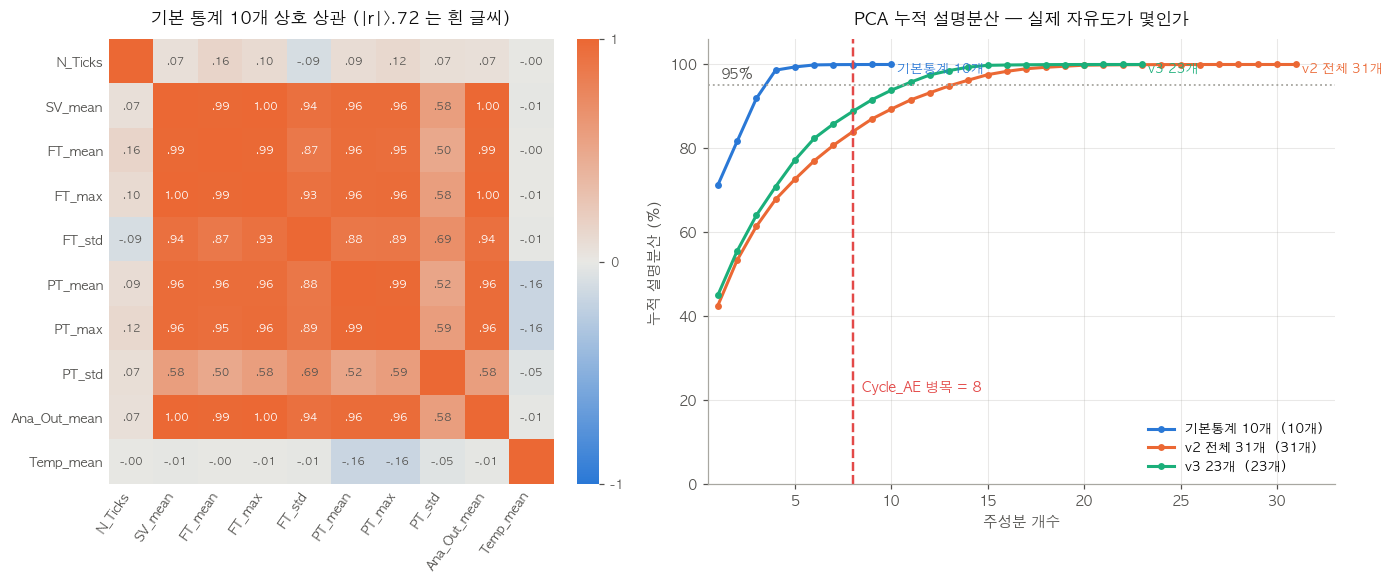

=== |r| > 0.8 인 쌍 (정보가 겹치는 쌍) ===
  +1.000   SV_mean        ~ Ana_Out_mean
  +0.997   SV_mean        ~ FT_max
  +0.997   FT_max         ~ Ana_Out_mean
  +0.991   PT_mean        ~ PT_max
  +0.988   FT_mean        ~ FT_max
  +0.987   SV_mean        ~ FT_mean
  +0.987   FT_mean        ~ Ana_Out_mean
  +0.963   PT_mean        ~ Ana_Out_mean
  +0.963   SV_mean        ~ PT_mean
  +0.961   FT_max         ~ PT_max
  +0.961   PT_max         ~ Ana_Out_mean
  +0.961   SV_mean        ~ PT_max
  +0.958   FT_max         ~ PT_mean
  +0.957   FT_mean        ~ PT_mean
  +0.951   FT_mean        ~ PT_max
  +0.936   FT_std         ~ Ana_Out_mean
  +0.936   SV_mean        ~ FT_std
  +0.928   FT_max         ~ FT_std
  +0.889   FT_std         ~ PT_max
  +0.878   FT_std         ~ PT_mean
  +0.874   FT_mean        ~ FT_std
  총 21쌍 / 가능한 45쌍

=== 유효 차원 (표준화 후 PCA) ===
  기본통계 10개       (10개)  95%까지  4개 / 99%까지  5개   병목 8 시점 누적 100.0%
  v2 전체 31개      (31개)  95%까지 14개 / 99%까지 18개   병목 8 시점 누적  84.0%
  v3 23개     

In [15]:
from matplotlib.colors import LinearSegmentedColormap
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

# 발산형: 파랑 <- 중성회색 -> 주황 (중간에 색을 두지 않는다)
DIV = LinearSegmentedColormap.from_list("div", [C1, "#e8e8e4", C2])

cm = S[BASE_COLS].corr()

fig, ax = plt.subplots(1, 2, figsize=(14.5, 5.4),
                       gridspec_kw={"width_ratios": [1.25, 1]})

# --- 왼쪽: 상관 히트맵 ---
im = ax[0].imshow(cm.values, cmap=DIV, vmin=-1, vmax=1)
ax[0].set_xticks(range(len(BASE_COLS)), BASE_COLS, rotation=55, ha="right", fontsize=8.5)
ax[0].set_yticks(range(len(BASE_COLS)), BASE_COLS, fontsize=8.5)
for i in range(len(BASE_COLS)):
    for j in range(len(BASE_COLS)):
        v = cm.values[i, j]
        if i == j: continue
        ax[0].text(j, i, f"{v:.2f}".replace("0.", "."), ha="center", va="center",
                   fontsize=7, color="white" if abs(v) > .72 else INK2)
ax[0].set_title("기본 통계 10개 상호 상관 (|r|>.72 는 흰 글씨)", fontsize=11, color=INK, pad=10)
ax[0].grid(False)
for s in ax[0].spines.values(): s.set_visible(False)
ax[0].tick_params(length=0, colors=INK2)
cb = fig.colorbar(im, ax=ax[0], fraction=.045, pad=.03, ticks=[-1, 0, 1])
cb.outline.set_visible(False); cb.ax.tick_params(colors=INK2, labelsize=8)

# --- 오른쪽: PCA 누적 설명분산 (세 가지 피처집합 비교) ---
V3_DROP = ["Ana_Out_mean","FT_max","PT_max","Ramp_Negative_Slope_Count",
           "Unexplained_PT_Dip_Count","Unexplained_PT_Dip_Max",
           "Unexplained_FT_Dip_Count","Unexplained_FT_Dip_Max"]
V3_COLS = [c for c in FEATURE_COLS if c not in V3_DROP]
SETS = [("기본통계 10개", BASE_COLS, C1),
        ("v2 전체 31개",  FEATURE_COLS, C2),
        ("v3 23개",       V3_COLS, C3)]

pca_info = {}
for label, cols, col in SETS:
    cum = np.cumsum(PCA().fit(StandardScaler().fit_transform(S[cols]))
                    .explained_variance_ratio_) * 100
    pca_info[label] = cum
    ax[1].plot(np.arange(1, len(cum)+1), cum, color=col, lw=2, marker="o", ms=3.5,
               label=f"{label}  ({len(cols)}개)")
    ax[1].annotate(label, xy=(len(cum), cum[-1]), xytext=(4, -3),   # 직접 라벨
                   textcoords="offset points", color=col, fontsize=8.5, va="center")
ax[1].axhline(95, color=GRAY, ls=":", lw=1.2)
ax[1].annotate("95%", xy=(1, 95), xytext=(2, 4), textcoords="offset points",
               color=INK2, fontsize=9)
ax[1].axvline(8, color=BAD, ls="--", lw=1.6)
ax[1].annotate("Cycle_AE 병목 = 8", xy=(8, 22), xytext=(6, 0),
               textcoords="offset points", color=BAD, fontsize=9)
ax[1].set_xlim(0.5, 33); ax[1].set_ylim(0, 106)
ax_style(ax[1], "PCA 누적 설명분산 — 실제 자유도가 몇인가",
         "주성분 개수", "누적 설명분산 (%)")
ax[1].legend(frameon=False, fontsize=8.5, loc="lower right")
plt.tight_layout(); plt.show()

# ==========================================
print("=== |r| > 0.8 인 쌍 (정보가 겹치는 쌍) ===")
pairs = [(a, b, cm.loc[a, b]) for i, a in enumerate(BASE_COLS) for b in BASE_COLS[i+1:]
         if abs(cm.loc[a, b]) > 0.8]
for a, b, v in sorted(pairs, key=lambda x: -abs(x[2])):
    print(f"  {v:+.3f}   {a:14s} ~ {b}")
print(f"  총 {len(pairs)}쌍 / 가능한 {len(BASE_COLS)*(len(BASE_COLS)-1)//2}쌍")

print("\n=== 유효 차원 (표준화 후 PCA) ===")
for label, cols, _ in SETS:
    cum = pca_info[label]
    n95 = int(np.searchsorted(cum, 95) + 1)
    n99 = int(np.searchsorted(cum, 99) + 1)
    at8 = f"   병목 8 시점 누적 {cum[7]:5.1f}%" if len(cum) >= 8 else ""
    print(f"  {label:14s} ({len(cols):2d}개)  95%까지 {n95:2d}개 / 99%까지 {n99:2d}개{at8}")

_n95_base = int(np.searchsorted(pca_info["기본통계 10개"], 95) + 1)
print()
print("읽는 법")
print(f"  · 기본통계 10개는 {_n95_base}차원이면 95% 가 설명된다.")
print(f"    -> 10개 중 {10-_n95_base}개는 새 정보를 안 준다. 학습을 못 시키는 건 아니지만")
print("       상관 1.0 짜리 쌍(SV_mean ~ Ana_Out_mean)은 그냥 같은 피처를 두 번 넣는 것이다.")
print("       v3 가 Ana_Out_mean / FT_max / PT_max 를 뺀 근거가 이 표다.")
_cum2 = pca_info["v2 전체 31개"]
print(f"  · 다만 **실제 모델의 입력은 31개(또는 23개)** 다. 거기서는 병목 8 이")
print(f"    선형 기준으로 {_cum2[7]:.1f}% 만 통과시킨다 -> 압축이 실제로 일어나고 있다.")
print("    즉 '병목이 너무 넓어서 AE 가 항등함수가 된다' 는 걱정은 여기선 해당 없다.")
print("  · 주의: PCA 는 선형이라 AE(비선형)의 능력 하한을 보는 도구다.")
print("    AE 는 이보다 더 압축할 수 있다. 상한이 아니라 참고선으로 읽어야 한다.")

---
## 1-4. 실시간 시계열로서 이 전처리가 맞나

> *"이게 우리는 실시간으로 이 모델을 사용하는 거잖아. 시계열에도 맞는 전처리과정인가?"*

시계열 모델을 실시간에 올릴 때 깨지는 지점을 하나씩 확인한다.

### 먼저, 이미 맞게 돼 있는 것 두 가지

`Cycle_AE_v3.ipynb` 를 확인한 결과 **시계열에서 가장 흔한 두 실수는 피해 갔다.**

| 항목 | 상태 |
|---|---|
| 분할이 시간순인가 | **O** — `TRAIN 09-10~09-18 / VALID ~09-19 / TEST 09-20~09-23`. 무작위 분할이 아니다 |
| 스케일러 누수 | **O** — `scaler.fit_transform(train)` 후 valid/test 는 `transform` 만 |
| 정규화 누수 | **O** — `ResidualNormalizer.fit(train_clean)` 만, 나머지는 적용만 |

무작위 `train_test_split` 을 썼다면 인접 사이클이 학습·검증에 나뉘어 들어가
성능이 부풀려졌을 텐데, 그건 안 했다.

### 남아 있는 진짜 문제

**(1) 피처는 사이클이 끝나야 존재한다 — 탐지 지연**

`FT_mean` 은 사이클 전체를 평균 낸 값이다. 사이클 도중에는 계산할 수 없다.
게다가 `Decay_Slope_*` 는 **꺼진 뒤 3초**를 본다. 그래서 한 사이클의 피처 벡터가
완성되는 시점은 **사이클 시작 + 약 8초(사이클) + 3초(감쇠) ≈ 11초 뒤**다.

예지보전(베어링 마모, 필터 막힘)에는 문제없다. 하지만 **"지금 이 사이클에 개입"
같은 용도로는 못 쓴다.** 이건 결함이 아니라 설계의 성질이니 명시해두면 된다.

**(2) 사이클을 독립 표본으로 다루는데, 실제로는 이어져 있다**

AE 는 사이클 하나하나를 독립된 벡터로 본다. 임계값도 보통
"학습 재구성오차의 상위 1%" 처럼 **독립 가정** 위에서 잡는다.
그런데 아래에서 보듯 일부 피처는 자기상관이 매우 높다. 자기상관이 높으면
이상이 **한 건씩이 아니라 수백 건 연속으로** 터진다.

**(3) `SV_mean` 회전과 절대값 피처의 종속** — 1-2, 1-3 에서 본 것

**(4) `N_Ticks` 의 수집기 의존** — 1-1 에서 확인한 대로 **지금 데이터에서는 문제가 없다**
(틱당 간격이 0.49초로 아주 좁아서 `N_Ticks` ≈ 지속시간). 하지만 이건 로거가 정상일 때의
이야기고, 09-26~27 처럼 로거가 열화되면 같은 길이 사이클이 16틱→4틱이 된다.
학습 데이터에는 없던 조건이라 **배포 후에만 터지는 고장모드**다.


=== (1) 피처 벡터가 완성되기까지 걸리는 시간 ===
  사이클 지속      중앙  7.82초   p95 10.42초
  + 감쇠창           3.00초
  = 탐지 지연      중앙 10.82초   p95 13.42초
  -> 예지보전용으로는 충분. '이 사이클에 개입' 용으로는 불가.


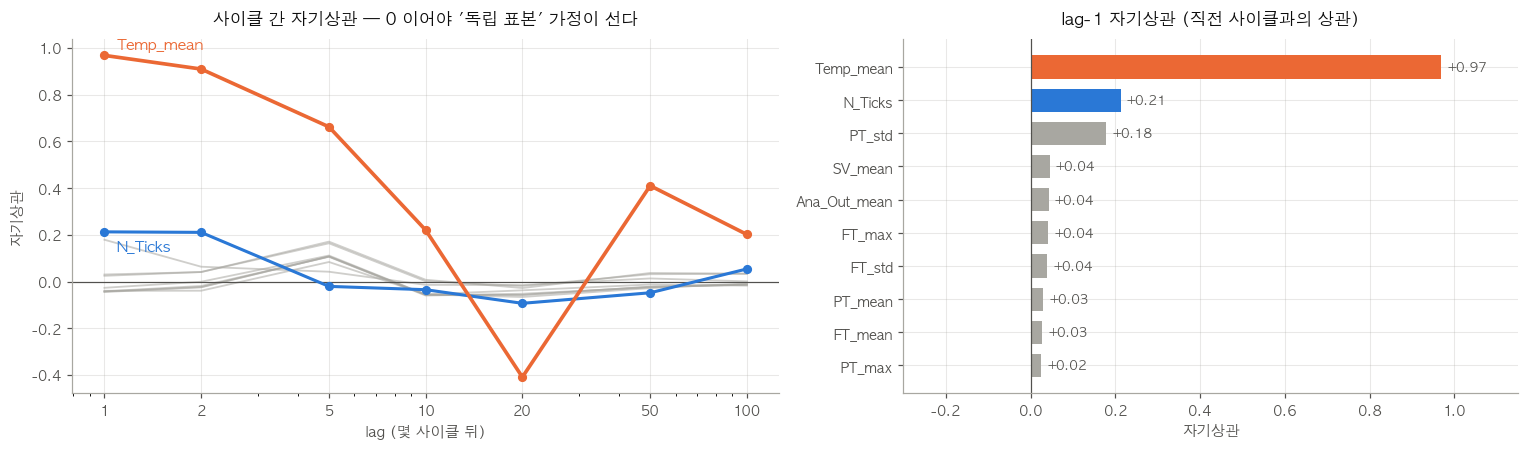


=== (2) 자기상관 ===
                1      2      5      10     20     50     100
N_Ticks       0.213  0.211 -0.021 -0.035 -0.093 -0.048  0.054
SV_mean      -0.045 -0.025  0.108 -0.056 -0.057 -0.022 -0.014
FT_mean      -0.027 -0.001  0.111 -0.055 -0.066 -0.028 -0.008
FT_max       -0.042 -0.019  0.106 -0.060 -0.052 -0.025 -0.012
FT_std       -0.040 -0.039  0.084 -0.055 -0.038 -0.013 -0.017
PT_mean       0.030  0.041  0.171  0.008 -0.028  0.037  0.034
PT_max        0.025  0.041  0.164  0.001 -0.019  0.031  0.033
PT_std        0.179  0.064  0.042 -0.014 -0.015  0.013  0.001
Ana_Out_mean -0.043 -0.024  0.107 -0.057 -0.058 -0.022 -0.014
Temp_mean     0.968  0.910  0.662  0.220 -0.409  0.410  0.202

  ! Temp_mean      lag1 = +0.968  -> 연속 사이클이 사실상 같은 값을 갖는다
  임계값을 '학습 오차 상위 1%' 로 잡으면 독립 가정이 깨져서
  실제 오경보율이 1% 보다 훨씬 높게/뭉쳐서 나온다.

=== (3) 일자별 중앙값 (분포가 흐르는가) ===
            N_Ticks  SV_mean  FT_mean  FT_max  FT_std  PT_mean  PT_max  PT_std  Ana_Out_mean  Temp_mean
Start_Time                        

In [16]:
Ss = S.sort_values("Start_Time").reset_index(drop=True)

# ==========================================
# (1) 탐지 지연
# ==========================================
_dur = (pd.to_datetime(Ss["End_Time"]) - pd.to_datetime(Ss["Start_Time"])).dt.total_seconds()
print("=== (1) 피처 벡터가 완성되기까지 걸리는 시간 ===")
print(f"  사이클 지속      중앙 {_dur.median():5.2f}초   p95 {_dur.quantile(.95):5.2f}초")
print(f"  + 감쇠창          {DECAY_WINDOW_SEC:5.2f}초")
print(f"  = 탐지 지연      중앙 {_dur.median()+DECAY_WINDOW_SEC:5.2f}초   p95 {_dur.quantile(.95)+DECAY_WINDOW_SEC:5.2f}초")
print("  -> 예지보전용으로는 충분. '이 사이클에 개입' 용으로는 불가.")

# ==========================================
# (2) 자기상관 — i.i.d. 가정 점검
# ==========================================
LAGS = [1, 2, 5, 10, 20, 50, 100]
ac = pd.DataFrame({c: [Ss[c].astype(float).autocorr(l) for l in LAGS]
                   for c in BASE_COLS}, index=LAGS).T

fig, ax = plt.subplots(1, 2, figsize=(14, 4.2), gridspec_kw={"width_ratios": [1.15, 1]})

# 강조 형태: 자기상관이 가장 높은 것만 색, 나머지 회색
worst = ac[1].abs().idxmax()
for c in BASE_COLS:
    hot = (c == worst)
    ax[0].plot(LAGS, ac.loc[c], color=(C2 if hot else GRAY), lw=(2.4 if hot else 1.2),
               alpha=(1 if hot else .55), marker="o" if hot else None,
               zorder=3 if hot else 1, label=c if hot else None)
ax[0].axhline(0, color=INK2, lw=.8)
ax[0].annotate(worst, xy=(LAGS[0], ac.loc[worst, 1]), xytext=(8, 4),
               textcoords="offset points", color=C2, fontsize=10, fontweight="bold")
second = ac[1].abs().drop(worst).idxmax()
ax[0].plot(LAGS, ac.loc[second], color=C1, lw=2, marker="o", zorder=2)
ax[0].annotate(second, xy=(LAGS[0], ac.loc[second, 1]), xytext=(8, -12),
               textcoords="offset points", color=C1, fontsize=10, fontweight="bold")
ax[0].set_xscale("log"); ax[0].set_xticks(LAGS, [str(l) for l in LAGS])
ax_style(ax[0], "사이클 간 자기상관 — 0 이어야 '독립 표본' 가정이 선다",
         "lag (몇 사이클 뒤)", "자기상관")

# lag1 막대 (직접 라벨)
order = ac[1].abs().sort_values()
ypos = np.arange(len(order))
cols = [C2 if v > .5 else (C1 if v > .2 else GRAY) for v in order.abs()]
ax[1].barh(ypos, order.values, color=cols, height=.7)
ax[1].set_yticks(ypos, order.index, fontsize=8.5)
for y, v in zip(ypos, order.values):
    ax[1].annotate(f"{v:+.2f}", xy=(v, y), xytext=(4 if v >= 0 else -4, 0),
                   textcoords="offset points", va="center",
                   ha="left" if v >= 0 else "right", fontsize=8.5, color=INK2)
ax[1].axvline(0, color=INK2, lw=.8); ax[1].set_xlim(-.3, 1.15)
ax_style(ax[1], "lag-1 자기상관 (직전 사이클과의 상관)", "자기상관", None)
plt.tight_layout(); plt.show()

print("\n=== (2) 자기상관 ===")
print(ac.round(3).to_string())
hi = ac[1][ac[1].abs() > .4]
print()
for c, v in hi.items():
    print(f"  ! {c:14s} lag1 = {v:+.3f}  -> 연속 사이클이 사실상 같은 값을 갖는다")
print("  임계값을 '학습 오차 상위 1%' 로 잡으면 독립 가정이 깨져서")
print("  실제 오경보율이 1% 보다 훨씬 높게/뭉쳐서 나온다.")

# ==========================================
# (3) 비정상성 — 학습기간과 이후가 같은 분포인가
# ==========================================
print("\n=== (3) 일자별 중앙값 (분포가 흐르는가) ===")
_d = Ss.groupby(pd.to_datetime(Ss["Start_Time"]).dt.normalize())[BASE_COLS].median().round(2)
print(_d.to_string())
rng = ((_d.max() - _d.min()) / _d.median().abs() * 100).round(1).sort_values(ascending=False)
print("\n  일자 간 변동폭 (최대-최소, 중앙값 대비 %)")
print(rng.to_string())
print("\n읽는 법")
print("  · 변동폭이 큰 피처는 '설비 변화' 가 아니라 '날마다 다름' 을 학습시킨다")
print("  · 학습 6일 뒤 배포하면 그 드리프트만큼 오경보가 깔린다")
print("  · 대책: 재학습 주기를 정하거나, 드리프트하는 기준변수로 정규화 (Cycle_Normalizer 방식)")

---
# 2. `g_s_SV` 를 클래스로 — 압력·토출량은 SV 가 정하는가

가설: *"같은 펌프라면 class 는 SV 다. `g_s_SV` 에 따라 그 펌프의 압력과 토출량이 정해진다."*

`g_s_SV_P1` 은 **목표 유량 설정값**이다. 펌프 제어기가 이 값을 따라가도록 인버터
주파수(`Hz_Out`)와 아날로그 출력(`Ana_Out`)을 조절하므로, 가설대로면
`Scale_Out___FT`(토출량)와 `Scale_Out___PT`(압력)가 SV 에 의해 거의 결정돼야 한다.

## 2-1. 먼저 클래스가 몇 개인가 — 세 가지 답이 나온다

| 세는 방법 | 개수 | 문제 |
|---|---|---|
| `SV_mean` 고유값 | **34** | 사이클 중간에 SV 가 바뀌면 평균이 소수점이 된다. 12개가 가짜 |
| 원본 `g_s_SV_P1` 고유값 | **22** | 진짜 값이지만, 레시피 **전환 중에 스쳐 지나가는 값**이 섞여 있다 |
| 안정 사이클의 최빈값 | **18** | ← **이게 실제 운전 클래스다** |

**`SV_mean` 을 클래스로 쓰면 안 된다.** 이건 평균이라서 사이클 중 SV 가 바뀌면
2010 과 2680 사이의 존재하지 않는 값(예: 2344.7)을 만들어낸다.
아래에서 셋을 다 세어 확인한다.


In [17]:
# ==========================================
# 사이클 -> SV 클래스
#   추출기의 SV_mean 은 평균이라 클래스로 못 쓴다. 원본 틱에서 최빈값을 뽑는다.
#   동시에 '사이클 내내 SV 가 불변이었나' 를 같이 기록한다.
# ==========================================
_d = raw.ffill().fillna(0).reset_index()
_d = _d.rename(columns={_d.columns[0]: "Time"})
_bu = _d[f"Pump_BuildUp_{PUMP_ID}"].astype(int)
_d["cid"] = (_bu.diff().fillna(0) != 0).cumsum()
_on = _d[_bu == 1]

TAG_SV = f"g_s_SV_{PUMP_ID}"
sv_mode   = _on.groupby("cid")[TAG_SV].agg(lambda s: s.mode().iloc[0])
sv_nuniq  = _on.groupby("cid")[TAG_SV].nunique()

for _df in (cyc, cyc_clean):
    _df["SV_class"]  = np.asarray(_df.index.map(sv_mode)).astype("int64")
    _df["SV_stable"] = np.asarray(_df.index.map(sv_nuniq)) == 1

K = cyc_clean[cyc_clean["SV_stable"]].copy()      # 클래스 분석의 기준 집합

print("=== 클래스를 세는 세 가지 방법 ===")
print(f"  (a) SV_mean 고유값            : {cyc_clean['SV_mean'].round(3).nunique():3d}개")
_vals = cyc_clean["SV_mean"].round(3).unique()
print(f"      그중 정수가 아닌 값(가짜)  : {int((_vals % 1 != 0).sum()):3d}종 / "
      f"{int((cyc_clean['SV_mean'] % 1 != 0).sum()):,}개 사이클")
print(f"  (b) 원본 {TAG_SV} 고유값 : {raw[TAG_SV].nunique():3d}개")
print(f"      {sorted(raw[TAG_SV].unique().astype(int))}")
print(f"  (c) 안정 사이클의 최빈값       : {K['SV_class'].nunique():3d}개   <- 실제 운전 클래스")
print()
print(f"  사이클 내내 SV 불변 : {cyc_clean['SV_stable'].mean()*100:.2f}% "
      f"({int(cyc_clean['SV_stable'].sum()):,} / {len(cyc_clean):,})")

# ==========================================
# (b) 22개와 (c) 18개의 차이는 어디서 오나
# ==========================================
_t = pd.DataFrame({
    "clean": cyc_clean.groupby("SV_class").size(),
    "안정":  cyc_clean[cyc_clean["SV_stable"]].groupby("SV_class").size(),
}).fillna(0).astype(int)
_t["불안정"] = _t["clean"] - _t["안정"]
_t["안정율%"] = (_t["안정"] / _t["clean"] * 100).round(1)
transient = _t[_t["안정"] == 0]

print("\n=== 안정율 0% = 레시피 전환 중에만 스치는 값 (클래스가 아니다) ===")
if len(transient):
    print(transient.to_string())
    print(f"  -> {list(transient.index)} 는 '2010 에서 2680 으로 넘어가는 도중' 같은")
    print("     과도 상태다. 실제 운전 설정값이 아니므로 클래스에서 뺀다.")
else:
    print("  없음")

_gone = set(raw[TAG_SV].unique().astype(int)) - set(K["SV_class"].dropna().astype(int))
print(f"\n=== 원본 22개 중 운전 클래스에서 빠진 값 {len(_gone)}개 ===")
for v in sorted(_gone):
    n_all = int((cyc["SV_class"] == v).sum())
    n_cl  = int((cyc_clean["SV_class"] == v).sum())
    why = "전환 과도값" if v in transient.index else "clean 에서 전부 제외됨"
    print(f"  SV {v}: 전체 사이클 {n_all:4d} / clean {n_cl:4d}   -> {why}")

print(f"\n>>> 운전 클래스 {K['SV_class'].nunique()}개, 분석 대상 {len(K):,} 사이클")

=== 클래스를 세는 세 가지 방법 ===
  (a) SV_mean 고유값            :  34개
      그중 정수가 아닌 값(가짜)  :  12종 / 277개 사이클
  (b) 원본 g_s_SV_P1 고유값 :  22개
      [np.int64(2010), np.int64(2150), np.int64(2210), np.int64(2260), np.int64(2300), np.int64(2310), np.int64(2340), np.int64(2350), np.int64(2430), np.int64(2520), np.int64(2530), np.int64(2540), np.int64(2560), np.int64(2570), np.int64(2660), np.int64(2680), np.int64(2740), np.int64(2780), np.int64(2800), np.int64(2830), np.int64(2850), np.int64(2980)]
  (c) 안정 사이클의 최빈값       :  18개   <- 실제 운전 클래스

  사이클 내내 SV 불변 : 97.94% (17,083 / 17,443)

=== 안정율 0% = 레시피 전환 중에만 스치는 값 (클래스가 아니다) ===
          clean  안정  불안정  안정율%
SV_class                      
2520        216   0  216   0.0
2540         10   0   10   0.0
2800        121   0  121   0.0
  -> [2520, 2540, 2800] 는 '2010 에서 2680 으로 넘어가는 도중' 같은
     과도 상태다. 실제 운전 설정값이 아니므로 클래스에서 뺀다.

=== 원본 22개 중 운전 클래스에서 빠진 값 4개 ===
  SV 2520: 전체 사이클  223 / clean  216   -> 전환 과도값
  SV 2540: 전체 사이클   10 / clean   10   -> 전환

---
## 2-2. 클래스별 압력·토출량

**그림 선택**: `FT`(토출량)와 `PT`(압력)는 **단위도 크기도 다른 두 양**이다.
`twinx` 로 겹치면 없는 교차점이 생기므로 **좌우 두 패널**로 나눈다.

각 패널은
- **옅은 산점도** — 사이클 하나하나 (퍼짐이 보여야 한다)
- **굵은 선 + 점** — 클래스 중앙값 (경향이 보여야 한다)

SV 는 순서가 있는 수치라서 x축에 그대로 놓는다. 막대로 세우면 "2010 과 2150 사이가
2150 과 2210 사이와 같은 거리" 라는 거짓말을 하게 된다.

아래 표에서 볼 것:
- **`FT_CV%`** — 클래스 안에서 토출량이 얼마나 흔들리나. 작을수록 SV 가 잘 정한다는 뜻
- **`FT/SV`** — 목표 대비 실제 비율. 1 이면 지시대로 나온 것


=== SV 클래스별 압력·토출량 ===
             n    비중%     FT_중앙  FT_CV%  FT/SV    PT_중앙  PT_CV%     저항     오차율
SV_class                                                                      
2010      3572  20.91  1899.688    1.00  0.945   89.154    2.95  0.046   5.488
2150      4086  23.92  2003.724    1.05  0.932   94.634    2.98  0.046   6.804
2210       122   0.71  2058.719    1.04  0.932   96.971    2.38  0.045   6.845
2260       884   5.17  2091.829    1.11  0.926   99.643    3.05  0.046   7.441
2300      1645   9.63  2141.667    1.04  0.931  101.235    3.16  0.046   6.884
2310         1   0.01  2144.944     NaN  0.928  102.000     NaN  0.046   7.145
2340       126   0.74  2158.889    1.17  0.923  101.600    2.47  0.046   7.740
2350      1071   6.27  2168.812    1.16  0.923  102.133    3.25  0.046   7.710
2430       167   0.98  2226.800    1.25  0.916  105.400    2.55  0.046   8.362
2530        61   0.36  2260.417    1.79  0.893  112.308    2.32  0.048  10.655
2560        99   0.58  2356.5

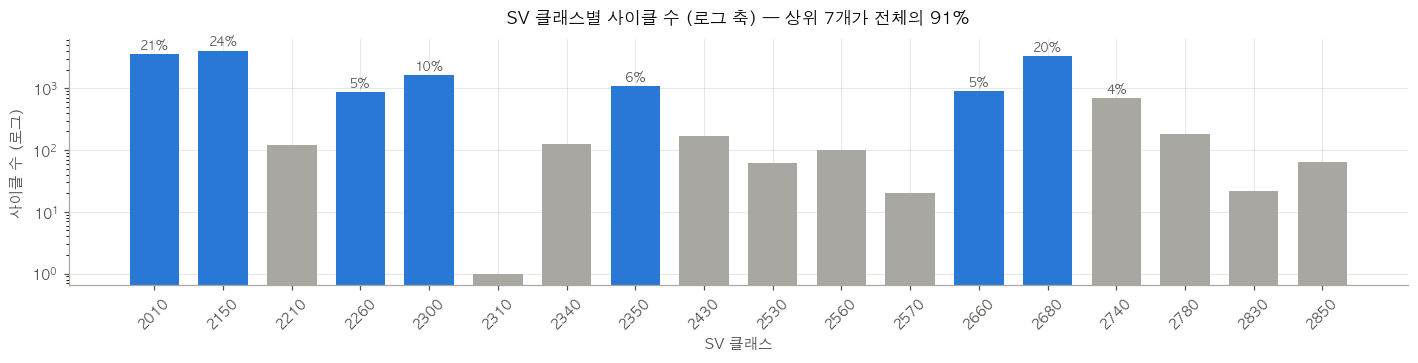

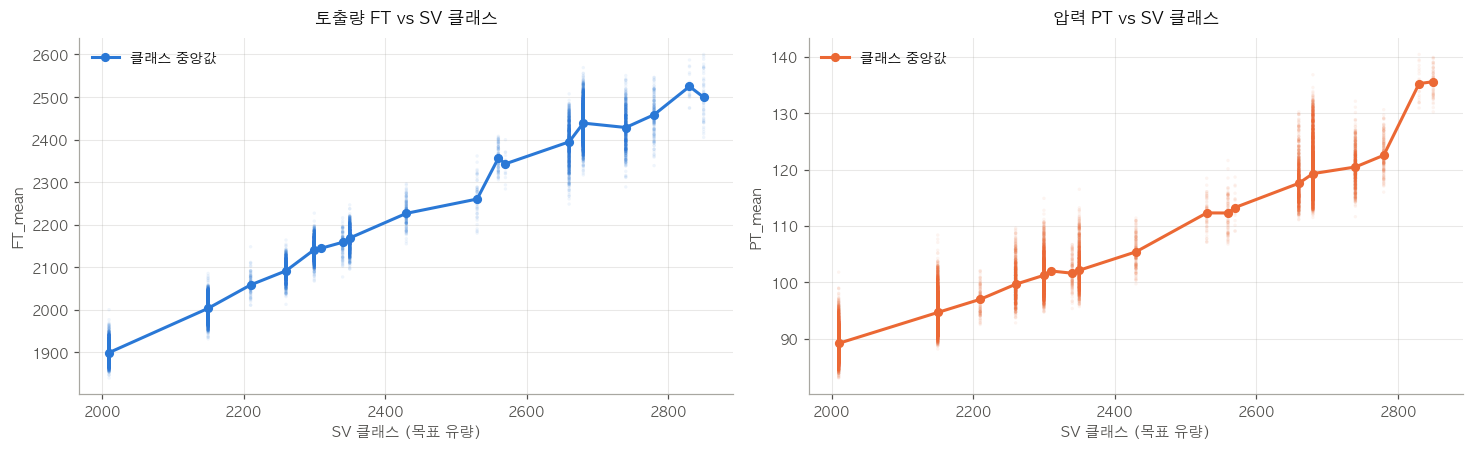

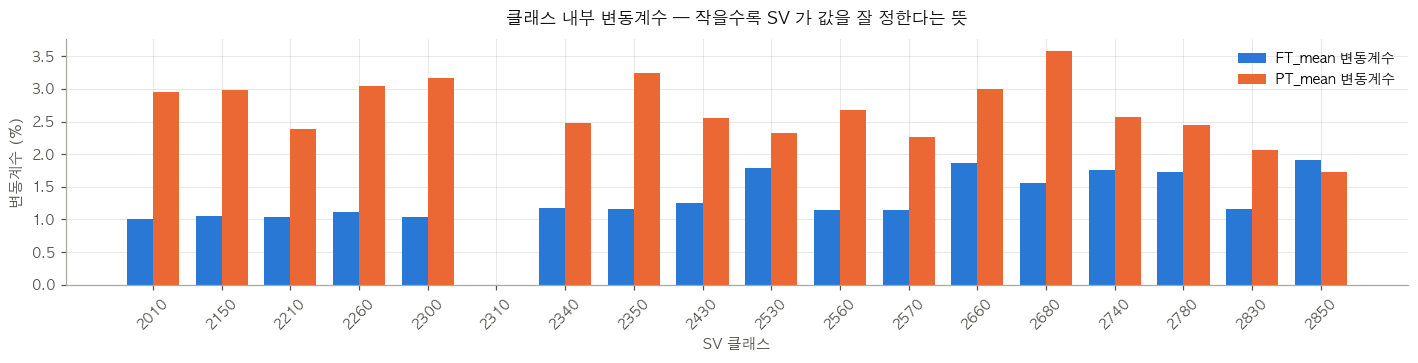


=== 클래스로 나누면 퍼짐이 얼마나 줄어드나 ===
  FT_mean    전체 CV   9.76%  ->  클래스 내 CV  1.24%   ( 7.9배 축소)
  PT_mean    전체 CV  12.21%  ->  클래스 내 CV  3.07%   ( 4.0배 축소)
  FT_std     전체 CV  29.26%  ->  클래스 내 CV  9.27%   ( 3.2배 축소)
  PT_std     전체 CV  46.71%  ->  클래스 내 CV 35.54%   ( 1.3배 축소)

=== 표본이 적은 클래스 (클래스별 모델을 만든다면 위험) ===
            n   비중%        FT_중앙       PT_중앙
SV_class                                    
2210      122  0.71  2058.718750   96.970588
2310        1  0.01  2144.944444  102.000000
2340      126  0.74  2158.889423  101.600000
2430      167  0.98  2226.800000  105.400000
2530       61  0.36  2260.416667  112.307692
2560       99  0.58  2356.529412  112.294118
2570       20  0.12  2343.122917  113.266667
2780      179  1.05  2458.500000  122.538462
2830       22  0.13  2524.843750  135.266667
2850       64  0.37  2499.426282  135.602564
  200개 미만 클래스 10개, 합쳐서 861개 (5.0%)


In [18]:
# ==========================================
# 클래스별 통계표
# ==========================================
agg = K.groupby("SV_class").agg(
    n            = ("FT_mean", "size"),
    FT_중앙      = ("FT_mean", "median"),
    FT_표준편차  = ("FT_mean", "std"),
    PT_중앙      = ("PT_mean", "median"),
    PT_표준편차  = ("PT_mean", "std"),
    저항         = ("DeltaP_over_Q", "median"),
    오차율       = ("Instant_FT_Error_Rate_mean", "median"),
)
agg["비중%"]  = (agg["n"] / len(K) * 100).round(2)
agg["FT_CV%"] = (agg["FT_표준편차"] / agg["FT_중앙"] * 100).round(2)
agg["PT_CV%"] = (agg["PT_표준편차"] / agg["PT_중앙"] * 100).round(2)
agg["FT/SV"]  = (agg["FT_중앙"] / agg.index.astype(float)).round(4)

print("=== SV 클래스별 압력·토출량 ===")
print(agg[["n","비중%","FT_중앙","FT_CV%","FT/SV","PT_중앙","PT_CV%","저항","오차율"]]
      .round(3).to_string())

# ==========================================
# 그림 1: 클래스 빈도 — 불균형
# ==========================================
fig, ax = plt.subplots(figsize=(13, 3.4))
x = np.arange(len(agg))
big = agg["비중%"] >= 5
ax.bar(x, agg["n"], color=[C1 if b else GRAY for b in big], width=.72)
ax.set_xticks(x, [str(int(v)) for v in agg.index], rotation=45, fontsize=8.5)
for i, (n, p) in enumerate(zip(agg["n"], agg["비중%"])):
    if p >= 3:
        ax.annotate(f"{p:.0f}%", xy=(i, n), xytext=(0, 3), textcoords="offset points",
                    ha="center", fontsize=8, color=INK2)
ax.set_yscale("log")
ax_style(ax, f"SV 클래스별 사이클 수 (로그 축) — 상위 {int(big.sum())}개가 전체의 "
             f"{agg.loc[big,'비중%'].sum():.0f}%", "SV 클래스", "사이클 수 (로그)")
plt.tight_layout(); plt.show()

# ==========================================
# 그림 2: FT / PT 대 SV  (이중 축 금지 -> 두 패널)
# ==========================================
fig, ax = plt.subplots(1, 2, figsize=(13.5, 4.2))
for a, (col, name, unit, c) in zip(ax, [("FT_mean", "토출량 FT", "FT_mean", C1),
                                        ("PT_mean", "압력 PT",   "PT_mean", C2)]):
    a.scatter(K["SV_class"].astype(float), K[col], s=5, alpha=.07, color=c,
              edgecolors="none", zorder=1)
    med = K.groupby("SV_class")[col].median()
    a.plot(med.index.astype(float), med.values, color=c, lw=2, marker="o", ms=5,
           zorder=3, label="클래스 중앙값")
    a.legend(frameon=False, fontsize=9, loc="upper left")
    ax_style(a, f"{name} vs SV 클래스", "SV 클래스 (목표 유량)", unit)
plt.tight_layout(); plt.show()

# ==========================================
# 그림 3: 클래스 안에서 얼마나 흔들리나
# ==========================================
fig, ax = plt.subplots(figsize=(13, 3.4))
w = .38
ax.bar(x - w/2, agg["FT_CV%"], width=w, color=C1, label="FT_mean 변동계수")
ax.bar(x + w/2, agg["PT_CV%"], width=w, color=C2, label="PT_mean 변동계수")
ax.set_xticks(x, [str(int(v)) for v in agg.index], rotation=45, fontsize=8.5)
ax.legend(frameon=False, fontsize=9)
ax_style(ax, "클래스 내부 변동계수 — 작을수록 SV 가 값을 잘 정한다는 뜻",
         "SV 클래스", "변동계수 (%)")
plt.tight_layout(); plt.show()

# ==========================================
# 클래스 안 vs 전체
# ==========================================
print("\n=== 클래스로 나누면 퍼짐이 얼마나 줄어드나 ===")
for c in ["FT_mean", "PT_mean", "FT_std", "PT_std"]:
    overall = K[c].std() / K[c].mean() * 100
    gs = K.groupby("SV_class")[c]
    within = (gs.std() / gs.mean() * 100).dropna()
    wsz = gs.size()[within.index]
    wavg = np.average(within, weights=wsz)
    print(f"  {c:10s} 전체 CV {overall:6.2f}%  ->  클래스 내 CV {wavg:5.2f}%   "
          f"({overall/wavg:4.1f}배 축소)")

print("\n=== 표본이 적은 클래스 (클래스별 모델을 만든다면 위험) ===")
few = agg[agg["n"] < 200]
print(few[["n","비중%","FT_중앙","PT_중앙"]].to_string() if len(few) else "  없음")
print(f"  200개 미만 클래스 {len(few)}개, 합쳐서 {int(few['n'].sum()):,}개 "
      f"({few['비중%'].sum():.1f}%)")

---
## 2-3. SV 가 정말 "정하는" 것은 무엇인가 — η²

가설을 숫자로 검증한다. **η²(eta squared)** 는 "전체 분산 중 클래스가 설명하는 비율" 이다.

```
η²  =  클래스 간 분산 / 전체 분산        0 = SV 와 무관,  1 = SV 가 완전히 결정
```

**그림 선택**: 피처별 η² 는 **크기 비교**다 → 수평 막대.
다만 여기서 읽어야 할 것은 순위가 아니라 **"어느 쪽 무리에 속하나"** 라서,
0.9 위(= SV 가 지배)와 0.3 아래(= SV 와 독립)를 다른 색으로 갈라 **강조**한다.
두 무리니까 범례를 둔다.

### 왜 이게 모델링에 중요한가

- **η² 가 높은 피처**는 "설비 건강" 이 아니라 **"지금 몇 번 레시피인가"** 를 들고 있다.
  AE 에 원시값으로 넣으면 용량을 레시피 구분에 쓴다.
- **η² 가 낮은 피처**는 레시피와 무관하게 움직인다 → **건강 지표 후보**다.


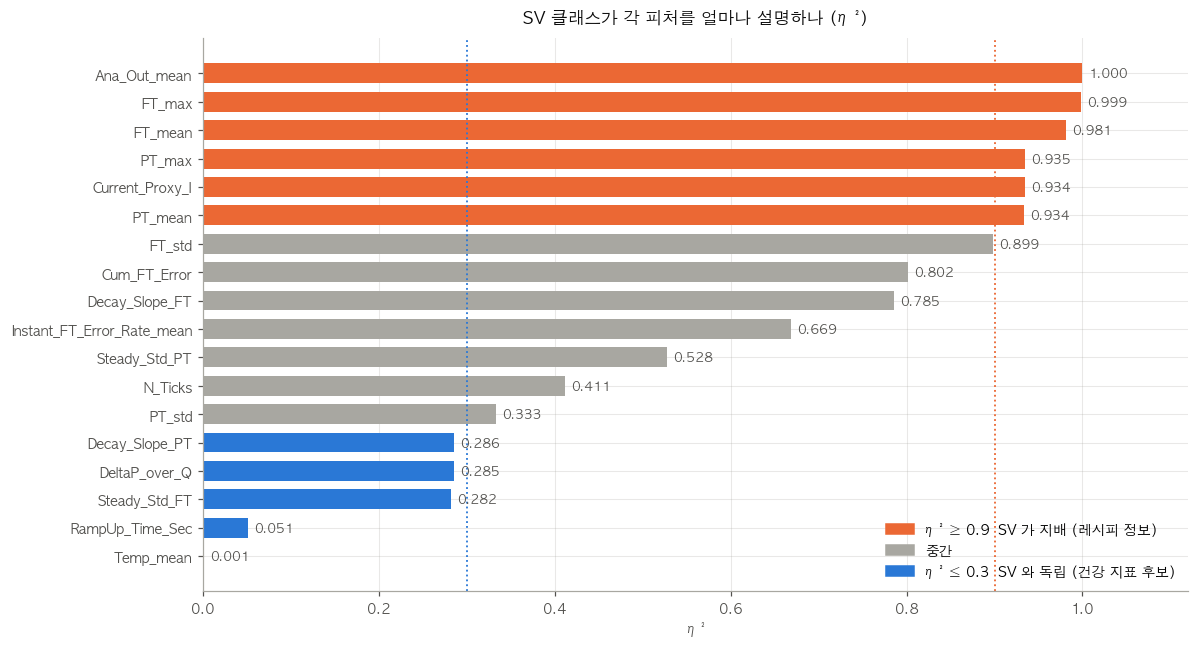

=== η² ===
  Ana_Out_mean                 1.000   SV 지배
  FT_max                       0.999   SV 지배
  FT_mean                      0.981   SV 지배
  PT_max                       0.935   SV 지배
  Current_Proxy_I              0.934   SV 지배
  PT_mean                      0.934   SV 지배
  FT_std                       0.899   중간
  Cum_FT_Error                 0.802   중간
  Decay_Slope_FT               0.785   중간
  Instant_FT_Error_Rate_mean   0.669   중간
  Steady_Std_PT                0.528   중간
  N_Ticks                      0.411   중간
  PT_std                       0.333   중간
  Decay_Slope_PT               0.286   독립
  DeltaP_over_Q                0.285   독립
  Steady_Std_FT                0.282   독립
  RampUp_Time_Sec              0.051   독립
  Temp_mean                    0.001   독립

=== 가설: 'SV 가 압력과 토출량을 정한다' ===
  토출량 (FT_mean) : η² = 0.981  -> SV 가 분산의 98.1% 를 설명
  압력 (PT_mean) : η² = 0.934  -> SV 가 분산의 93.4% 를 설명
  => 가설 성립.


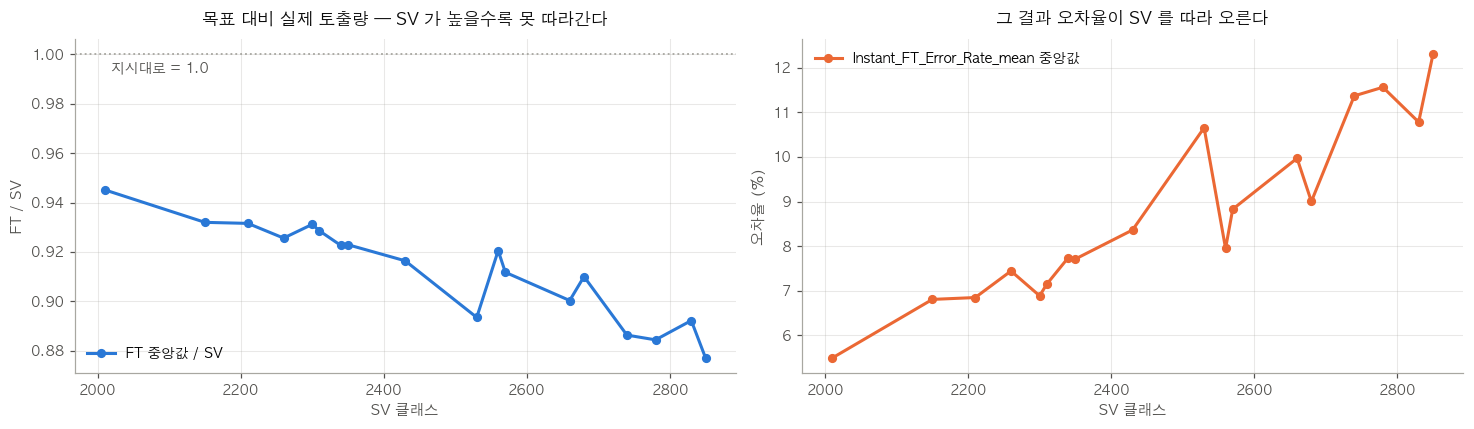


=== FT/SV 비율 ===
  최저 SV 2010 : 0.945
  최고 SV 2850 : 0.877
  상관(SV, FT/SV) = -0.930
  -> 비율이 단조 감소하면 '고유량 지시에서 펌프가 포화한다' 는 뜻이다.
     이건 설비 이상이 아니라 정상 특성이므로, 오차율을 이상탐지에 쓸 때
     반드시 SV 클래스 안에서 비교해야 한다. 안 그러면 고SV 사이클이
     항상 이상으로 잡힌다.


In [19]:
def eta_squared(y, cls):
    """전체 분산 중 클래스가 설명하는 비율."""
    y = y.astype(float)
    ok = y.notna()
    y, cls = y[ok], cls[ok]
    gm = y.mean()
    ss_t = ((y - gm) ** 2).sum()
    if ss_t == 0:
        return np.nan
    ss_b = sum(len(v) * (v.mean() - gm) ** 2 for _, v in y.groupby(cls))
    return ss_b / ss_t

TARGETS = ["FT_mean","FT_max","PT_mean","PT_max","Ana_Out_mean","Current_Proxy_I",
           "FT_std","Instant_FT_Error_Rate_mean","Cum_FT_Error","N_Ticks","PT_std",
           "DeltaP_over_Q","Steady_Std_FT","Steady_Std_PT","Decay_Slope_PT",
           "Decay_Slope_FT","RampUp_Time_Sec","Temp_mean"]
e2 = pd.Series({c: eta_squared(K[c], K["SV_class"]) for c in TARGETS}).dropna().sort_values()

HI, LO = 0.9, 0.3
fig, ax = plt.subplots(figsize=(11, 6))
y = np.arange(len(e2))
cols = [C2 if v >= HI else (C1 if v <= LO else GRAY) for v in e2]
ax.barh(y, e2.values, color=cols, height=.7)
ax.set_yticks(y, e2.index, fontsize=9)
for yy, v in zip(y, e2.values):                       # 직접 라벨 (대비 보정)
    ax.annotate(f"{v:.3f}", xy=(v, yy), xytext=(4, 0), textcoords="offset points",
                va="center", fontsize=8.5, color=INK2)
ax.axvline(HI, color=C2, ls=":", lw=1.2)
ax.axvline(LO, color=C1, ls=":", lw=1.2)
ax.set_xlim(0, 1.12)
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=C2, label=f"η² ≥ {HI}  SV 가 지배 (레시피 정보)"),
                   Patch(color=GRAY, label="중간"),
                   Patch(color=C1, label=f"η² ≤ {LO}  SV 와 독립 (건강 지표 후보)")],
          frameon=False, fontsize=9, loc="lower right")
ax_style(ax, "SV 클래스가 각 피처를 얼마나 설명하나 (η²)", "η²", None)
plt.tight_layout(); plt.show()

print("=== η² ===")
for c, v in e2.sort_values(ascending=False).items():
    tag = "SV 지배" if v >= HI else ("독립" if v <= LO else "중간")
    print(f"  {c:28s} {v:.3f}   {tag}")

# ==========================================
# 가설 검증 결론
# ==========================================
print("\n=== 가설: 'SV 가 압력과 토출량을 정한다' ===")
for c, nm in [("FT_mean", "토출량"), ("PT_mean", "압력")]:
    v = e2[c]
    print(f"  {nm} ({c}) : η² = {v:.3f}  -> SV 가 분산의 {v*100:.1f}% 를 설명")
print("  => 가설 성립.")

# ==========================================
# 그림: FT/SV 비율 — 고SV 에서 펌프가 못 따라간다
# ==========================================
fig, ax = plt.subplots(1, 2, figsize=(13.5, 4.0))
ratio = (K.groupby("SV_class")["FT_mean"].median() / agg.index.astype(float))
ax[0].plot(ratio.index.astype(float), ratio.values, color=C1, lw=2, marker="o", ms=5,
           label="FT 중앙값 / SV")
ax[0].axhline(1.0, color=GRAY, ls=":", lw=1.2)
ax[0].annotate("지시대로 = 1.0", xy=(ratio.index.min(), 1.0), xytext=(4, -12),
               textcoords="offset points", color=INK2, fontsize=9)
ax[0].legend(frameon=False, fontsize=9, loc="lower left")
ax_style(ax[0], "목표 대비 실제 토출량 — SV 가 높을수록 못 따라간다",
         "SV 클래스", "FT / SV")

err = K.groupby("SV_class")["Instant_FT_Error_Rate_mean"].median()
ax[1].plot(err.index.astype(float), err.values, color=C2, lw=2, marker="o", ms=5,
           label="Instant_FT_Error_Rate_mean 중앙값")
ax[1].legend(frameon=False, fontsize=9, loc="upper left")
ax_style(ax[1], "그 결과 오차율이 SV 를 따라 오른다", "SV 클래스", "오차율 (%)")
plt.tight_layout(); plt.show()

print(f"\n=== FT/SV 비율 ===")
print(f"  최저 SV {int(ratio.index.min())} : {ratio.iloc[0]:.3f}")
print(f"  최고 SV {int(ratio.index.max())} : {ratio.iloc[-1]:.3f}")
print(f"  상관(SV, FT/SV) = {np.corrcoef(ratio.index.astype(float), ratio.values)[0,1]:+.3f}")
print("  -> 비율이 단조 감소하면 '고유량 지시에서 펌프가 포화한다' 는 뜻이다.")
print("     이건 설비 이상이 아니라 정상 특성이므로, 오차율을 이상탐지에 쓸 때")
print("     반드시 SV 클래스 안에서 비교해야 한다. 안 그러면 고SV 사이클이")
print("     항상 이상으로 잡힌다.")

---
# 3. 어떤 피처를 버릴까 — 판단

문제 제기: *"`SV_mean` 은 그 사이클의 SV 가 뭔지만 알면 되니 버리자. `FT_mean`, `FT_max`,
`PT_max` 도 결국 SV 를 따라간 결과론적인 값이라 별 도움 안 될 것 같다."*

절반은 맞고 절반은 다르다. **η² 가 높다고 곧 버려도 된다는 뜻은 아니다.**

## 판단 기준: "버릴까" 가 아니라 "원시값이냐 잔차냐"

`FT_mean` 의 분산 98.1% 는 SV 가 설명한다. 그런데 **남은 1.9% 가 바로
"지시한 만큼 실제로 나왔나" 이고, 그게 설비 건강 신호다.** 통째로 버리면 그것도 같이 버린다.

그래서 피처마다 이렇게 묻는다.

```
1) 클래스를 빼고 나면 얼마나 남나?          (클래스 내 변동계수)
2) 남은 것이 신호인가 잡음인가?              (잔차 자기상관, 일자간 흐름)
      · 자기상관 ~0 이고 안 흐르면  -> 측정 잡음. 버려도 된다
      · 자기상관 높고 흐르면        -> 느리게 변하는 상태. 예지보전이 찾는 것
3) 남은 것이 다른 피처와 겹치나?             (잔차끼리의 상관)
```

아래 셀이 이 세 가지를 전부 잰다.


판단 대상: 17,040 사이클 / 클래스 15개 (n>=50)

=== 세 가지 질문에 대한 답 ===
                    η²  클래스내CV%  잔차lag1  일자흔들림σ
피처                                             
SV_mean          1.000    0.000     NaN     NaN
Ana_Out_mean     1.000    0.142   0.055   0.128
FT_max           0.999    0.387   0.153   0.880
PT_max           0.935    3.016   0.827   1.566
FT_mean          0.981    1.238   0.235   0.213
PT_mean          0.933    3.077   0.861   1.579
FT_std           0.898    9.278   0.157   0.118
PT_std           0.331   35.550   0.277   0.202
Current_Proxy_I  0.934    2.998   0.828   1.592
N_Ticks          0.411    7.511   0.050   0.118
DeltaP_over_Q    0.276    3.547   0.751   1.509
RampUp_Time_Sec  0.051   20.463   0.032   0.059


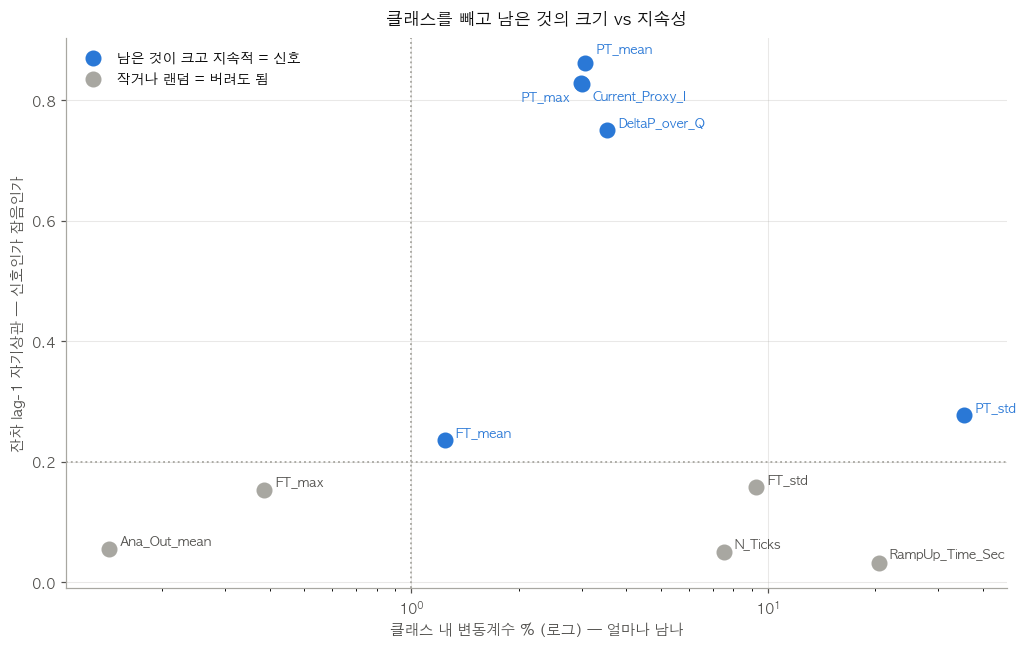


=== 클래스를 뺀 뒤에도 서로 겹치는 쌍 (|r| > 0.7) ===
  +0.952   PT_mean          ~ Current_Proxy_I
  +0.900   PT_max           ~ PT_mean
  +0.886   PT_max           ~ Current_Proxy_I
  -0.884   FT_mean          ~ FT_std
  +0.834   PT_max           ~ DeltaP_over_Q
  +0.747   PT_mean          ~ DeltaP_over_Q

=== FT_mean 잔차는 기존 오차율 피처와 겹치나 ===
  corr(FT_mean 잔차, Instant_FT_Error_Rate_mean  ) = -0.563
  corr(FT_mean 잔차, Instant_FT_Error_Rate_max   ) = -0.105
  corr(FT_mean 잔차, Cum_FT_Error                ) = -0.369

=== SV_mean 은 SV_class 의 중복인가 ===
  클래스 내 SV_mean 표준편차 평균 = 0.000000
  -> 정확히 0 이면 SV_mean 은 클래스 라벨 그 자체다 (숫자로 쓸 이유가 없다)


In [20]:
# 표본 50개 미만 클래스는 클래스 통계가 불안정하므로 제외
KK = K[K.groupby("SV_class")["FT_mean"].transform("size") >= 50].copy()
print(f"판단 대상: {len(KK):,} 사이클 / 클래스 {KK['SV_class'].nunique()}개 (n>=50)\n")

def within_class_z(df, col, cls="SV_class"):
    """클래스 평균/표준편차로 표준화한 잔차 = 'SV 를 빼고 남은 것'"""
    gg = df.groupby(cls)[col]
    return ((df[col] - gg.transform("mean")) / gg.transform("std")
            ).replace([np.inf, -np.inf], np.nan)

CAND = ["SV_mean","Ana_Out_mean","FT_max","PT_max","FT_mean","PT_mean",
        "FT_std","PT_std","Current_Proxy_I","N_Ticks","DeltaP_over_Q","RampUp_Time_Sec"]
RES = pd.DataFrame({c: within_class_z(KK, c) for c in CAND})
_st = pd.to_datetime(KK["Start_Time"])

rows = []
for c in CAND:
    gg = KK.groupby("SV_class")[c]
    cvs = (gg.std() / gg.mean().abs() * 100).replace([np.inf, -np.inf], np.nan).dropna()
    cv = np.average(cvs, weights=gg.size()[cvs.index]) if len(cvs) else np.nan
    z = RES[c]
    daily = z.groupby(_st.dt.normalize()).mean()
    rows.append({
        "피처": c,
        "η²": eta_squared(KK[c], KK["SV_class"]),
        "클래스내CV%": cv,
        "잔차lag1": z.autocorr(1),
        "일자흔들림σ": (daily.max() - daily.min()) if daily.notna().any() else np.nan,
    })
J = pd.DataFrame(rows).set_index("피처").round(3)
print("=== 세 가지 질문에 대한 답 ===")
print(J.to_string())

# ==========================================
# 그림: 남은 것이 신호인가 잡음인가
#   x = 클래스를 빼고 남은 크기, y = 그 남은 것의 지속성
#   오른쪽 위 = 크고 지속적 = 진짜 신호 / 왼쪽 아래 = 작고 랜덤 = 잡음
# ==========================================
P = J.dropna(subset=["클래스내CV%", "잔차lag1"])
fig, ax = plt.subplots(figsize=(9.5, 6))
keep = (P["클래스내CV%"] > 1.0) & (P["잔차lag1"] > 0.2)
ax.scatter(P.loc[keep, "클래스내CV%"], P.loc[keep, "잔차lag1"],
           s=90, color=C1, zorder=3, label="남은 것이 크고 지속적 = 신호")
ax.scatter(P.loc[~keep, "클래스내CV%"], P.loc[~keep, "잔차lag1"],
           s=90, color=GRAY, zorder=3, label="작거나 랜덤 = 버려도 됨")
# 겹치는 라벨은 위아래로 흩뿌린다
_off = {"PT_mean": (7, 7), "Current_Proxy_I": (7, -11), "PT_max": (-8, -11),
        "DeltaP_over_Q": (7, 2)}
for c, r_ in P.iterrows():
    dx, dy = _off.get(c, (7, 3))
    ax.annotate(c, xy=(r_["클래스내CV%"], r_["잔차lag1"]), xytext=(dx, dy),
                textcoords="offset points", fontsize=8.5,
                ha="right" if dx < 0 else "left",
                color=C1 if keep[c] else INK2)
ax.axvline(1.0, color=GRAY, ls=":", lw=1.2)
ax.axhline(0.2, color=GRAY, ls=":", lw=1.2)
ax.set_xscale("log")
ax.legend(frameon=False, fontsize=9, loc="upper left")
ax_style(ax, "클래스를 빼고 남은 것의 크기 vs 지속성",
         "클래스 내 변동계수 % (로그) — 얼마나 남나", "잔차 lag-1 자기상관 — 신호인가 잡음인가")
plt.tight_layout(); plt.show()

# ==========================================
# 잔차끼리 겹치는가
# ==========================================
print("\n=== 클래스를 뺀 뒤에도 서로 겹치는 쌍 (|r| > 0.7) ===")
cmr = RES.corr()
seen = []
for i, a in enumerate(CAND):
    for b in CAND[i+1:]:
        v = cmr.loc[a, b]
        if pd.notna(v) and abs(v) > 0.7:
            seen.append((abs(v), f"  {v:+.3f}   {a:16s} ~ {b}"))
for _, line in sorted(seen, reverse=True):
    print(line)

print("\n=== FT_mean 잔차는 기존 오차율 피처와 겹치나 ===")
for c in ["Instant_FT_Error_Rate_mean", "Instant_FT_Error_Rate_max", "Cum_FT_Error"]:
    print(f"  corr(FT_mean 잔차, {c:28s}) = {RES['FT_mean'].corr(KK[c]):+.3f}")

print("\n=== SV_mean 은 SV_class 의 중복인가 ===")
print(f"  클래스 내 SV_mean 표준편차 평균 = {KK.groupby('SV_class')['SV_mean'].std().mean():.6f}")
print("  -> 정확히 0 이면 SV_mean 은 클래스 라벨 그 자체다 (숫자로 쓸 이유가 없다)")

### 3-2. 결론 — 무엇을 버리고 무엇을 남기나

위 측정을 근거로 정리하면:

| 피처 | η² | 클래스내 CV | 잔차 lag1 | 판단 |
|---|---|---|---|---|
| `SV_mean` | — | **0.00%** | — | **버린다.** 클래스 라벨 그 자체. `SV_class` 로 대체 |
| `Ana_Out_mean` | 1.000 | 0.14% | +0.06 | **버린다.** SV 의 결정적 함수, 남은 건 잡음 |
| `FT_max` | 0.999 | 0.39% | +0.15 | **버린다.** `FT_mean` 과 r=0.988, 남은 것도 거의 없음 |
| `PT_max` | 0.935 | 3.02% | +0.83 | **버린다.** 단 이유가 다름 — 잔차가 `PT_mean` 잔차와 **r=0.900** 으로 중복 |
| `FT_mean` | 0.981 | 1.24% | +0.24 | **잔차로 남긴다.** 1.9% 가 "지시대로 나왔나" |
| `PT_mean` | 0.934 | 3.08% | **+0.86** | **반드시 남긴다.** 아래 참고 |
| `Current_Proxy_I` | 0.934 | 3.00% | +0.83 | **`PT_mean` 과 택일.** 잔차 r=0.952 |
| `FT_std` | 0.899 | 9.28% | +0.16 | `FT_mean` 잔차와 r=−0.884. 택일 |

**핵심은 `SV_mean`, `Ana_Out_mean`, `FT_max` 를 버리자는 판단은 맞다**는 것이다.
다만 `PT_max` 는 "SV 따라간 결과라서" 가 아니라 **`PT_mean` 과 중복이라서** 버리는 것이고,
`FT_mean` 과 `PT_mean` 은 **통째로 버리면 안 된다.**

### `PT_mean` 이 특별한 이유

클래스를 빼고 남은 잔차가 **lag-1 자기상관 0.861, 일자간 1.58σ** 로 흔들린다.
잡음이라면 자기상관이 0 이어야 한다. 느리게 변하는 **상태량**이라는 뜻이다.

정체를 더 캐보면:

- `Temp_mean` 과 상관 **−0.608** — 탱크가 뜨거우면 점도가 낮아져 압력이 덜 걸린다.
  물리적으로 말이 된다. 다만 온도가 설명하는 건 분산의 **37%** 뿐이다
- 온도를 1차로 제거해도 **일자간 흔들림은 1.58σ → 1.56σ 로 거의 안 줄고**,
  자기상관도 0.861 → 0.779 로 남는다
- `DeltaP_over_Q`(유로 저항) 와 상관 **+0.628** — 같은 유량에 더 센 압력

즉 `PT_mean` 의 잔차는 **온도로도 레시피로도 설명 안 되는 무언가**를 들고 있고,
그게 예지보전이 찾는 종류의 신호다. 일자별로 보면 **09-14 만 +1.11σ** 로 튀고
나머지 5일은 −0.5~+0.14 에 모여 있다.

> **주의**: 이건 "09-14 에 설비가 이상했다" 는 결론이 아니다. 6일치로는 그게
> 주간 변동인지 실제 변화인지 구분할 수 없다. 더 긴 구간이 필요하다는 신호다.


=== PT_mean 잔차(클래스 제거 후)는 무엇과 움직이나 ===
  corr(PT 잔차, Temp_mean(탱크온도)         ) = -0.608
  corr(PT 잔차, DeltaP_over_Q(유로저항)     ) = +0.628
  corr(PT 잔차, RampUp_Time_Sec         ) = -0.091
  corr(PT 잔차, FT_mean 잔차              ) = +0.093

=== 온도를 마저 제거하면 ===
  온도가 설명하는 분산 : 37.0%
  일자간 흔들림        : 1.58σ  ->  1.56σ
  lag-1 자기상관       : +0.861  ->  +0.779
  -> 거의 안 줄면, 일자 구조의 원인은 온도가 아니다


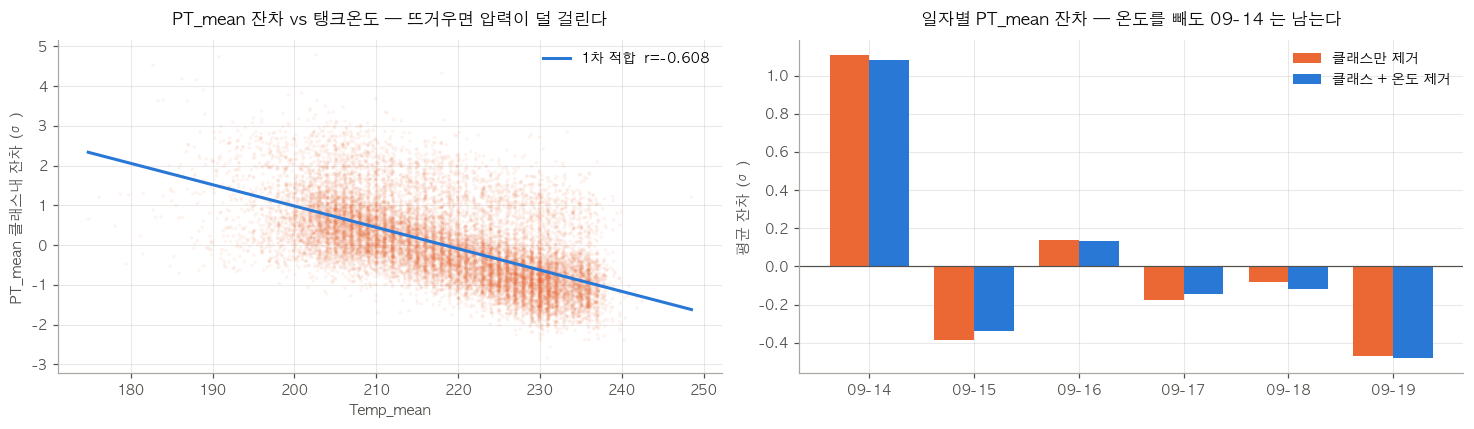


=== 일자별 ===
            클래스만제거  온도까지제거   평균온도
Start_Time                       
2026-09-14    1.11    1.08  217.8
2026-09-15   -0.38   -0.34  219.2
2026-09-16    0.14    0.13  218.2
2026-09-17   -0.18   -0.14  218.9
2026-09-18   -0.08   -0.12  217.6
2026-09-19   -0.47   -0.48  218.1


In [21]:
# ==========================================
# PT_mean 잔차의 정체 파헤치기
# ==========================================
rPT = within_class_z(KK, "PT_mean")
rFT = within_class_z(KK, "FT_mean")
T   = KK["Temp_mean"].astype(float)

print("=== PT_mean 잔차(클래스 제거 후)는 무엇과 움직이나 ===")
for nm, s in [("Temp_mean(탱크온도)", T), ("DeltaP_over_Q(유로저항)", KK["DeltaP_over_Q"]),
              ("RampUp_Time_Sec", KK["RampUp_Time_Sec"]), ("FT_mean 잔차", rFT)]:
    print(f"  corr(PT 잔차, {nm:24s}) = {rPT.corr(s):+.3f}")

ok = rPT.notna() & T.notna()
a_, b_ = np.polyfit(T[ok], rPT[ok], 1)
rPT2 = rPT[ok] - (a_ * T[ok] + b_)                    # 온도까지 제거
_s = pd.to_datetime(KK["Start_Time"])[ok]
d1 = rPT[ok].groupby(_s.dt.normalize()).mean()
d2 = rPT2.groupby(_s.dt.normalize()).mean()

print(f"\n=== 온도를 마저 제거하면 ===")
print(f"  온도가 설명하는 분산 : {(1 - rPT2.var()/rPT[ok].var())*100:.1f}%")
print(f"  일자간 흔들림        : {d1.max()-d1.min():.2f}σ  ->  {d2.max()-d2.min():.2f}σ")
print(f"  lag-1 자기상관       : {rPT[ok].autocorr(1):+.3f}  ->  {rPT2.autocorr(1):+.3f}")
print("  -> 거의 안 줄면, 일자 구조의 원인은 온도가 아니다")

fig, ax = plt.subplots(1, 2, figsize=(13.5, 4.0))
ax[0].scatter(T[ok], rPT[ok], s=5, alpha=.08, color=C2, edgecolors="none")
_xs = np.linspace(T[ok].min(), T[ok].max(), 50)
ax[0].plot(_xs, a_*_xs + b_, color=C1, lw=2, label=f"1차 적합  r={rPT.corr(T):+.3f}")
ax[0].legend(frameon=False, fontsize=9, loc="upper right")
ax_style(ax[0], "PT_mean 잔차 vs 탱크온도 — 뜨거우면 압력이 덜 걸린다",
         "Temp_mean", "PT_mean 클래스내 잔차 (σ)")

w = .38; xi = np.arange(len(d1))
ax[1].bar(xi - w/2, d1.values, width=w, color=C2, label="클래스만 제거")
ax[1].bar(xi + w/2, d2.values, width=w, color=C1, label="클래스 + 온도 제거")
ax[1].axhline(0, color=INK2, lw=.8)
ax[1].set_xticks(xi, [str(d.date())[5:] for d in d1.index], fontsize=9)
ax[1].legend(frameon=False, fontsize=9)
ax_style(ax[1], "일자별 PT_mean 잔차 — 온도를 빼도 09-14 는 남는다",
         None, "평균 잔차 (σ)")
plt.tight_layout(); plt.show()

print("\n=== 일자별 ===")
print(pd.DataFrame({"클래스만제거": d1.round(2), "온도까지제거": d2.round(2),
                    "평균온도": T[ok].groupby(_s.dt.normalize()).mean().round(1)}).to_string())

---
# 4. `RampUp_Time_Sec` — 사이클별·SV별 구성

설명서의 정의: *"펌프를 켜고 나서 유량이 목표치 근처(`|FT−SV|/SV ≤ 5%`)에 처음 도달할
때까지 걸린 초. 틱 개수가 아니라 **실제 타임스탬프 차이**를 쓴다 — 틱 간격이 균일하지
않기 때문이다."*

2-3 에서 이 피처의 **η² 는 0.051** 이었다. 18개 SV 클래스 어디서나 거의 같은 값이
나온다는 뜻이고, 그래서 레시피와 무관한 **건강 지표 후보 1순위**다.

그런데 이 값이 실제로 **어떤 알갱이로 만들어져 있는지** 먼저 봐야 한다.

## 4-1. 이 값은 연속량이 아니다

`RampUp_Time_Sec` 은 고유값이 16,000개가 넘어서 연속량처럼 보인다. 하지만 계산식을
다시 보면 **"조건을 만족한 첫 틱의 타임스탬프 − 시작 타임스탬프"** 다.
틱은 0.49초 간격이므로 이 값은 사실상 **틱 개수 × 0.49초** 이고,
초 단위의 다양함은 전부 **틱 간격 지터**다.

**그림 선택**:
- *값이 어디에 뭉쳐 있나* → **가는 구간 히스토그램**. 뭉침(다봉성)이 보여야 한다
- *실제 알갱이가 뭔가* → **틱 인덱스 막대**. 이게 진짜 자유도다


=== RampUp_Time_Sec 요약 ===
  n 17,040   중앙 1.579초   평균 1.711   표준편차 0.358   범위 0.000~2.656
  고유값 16,292개   <- 연속량처럼 보인다

  그런데 '몇 번째 틱' 으로 보면 고유값 6개 뿐
  상관(틱 인덱스, 초) = +0.9441

  틱 인덱스별 사이클 수
    0틱째       1개 (  0.0%)   초 중앙 0.000
    1틱째      31개 (  0.2%)   초 중앙 1.039
    2틱째   2,573개 ( 15.1%)   초 중앙 1.049
    3틱째   8,197개 ( 48.1%)   초 중앙 1.564
    4틱째   5,984개 ( 35.1%)   초 중앙 2.084
    5틱째     254개 (  1.5%)   초 중앙 2.601


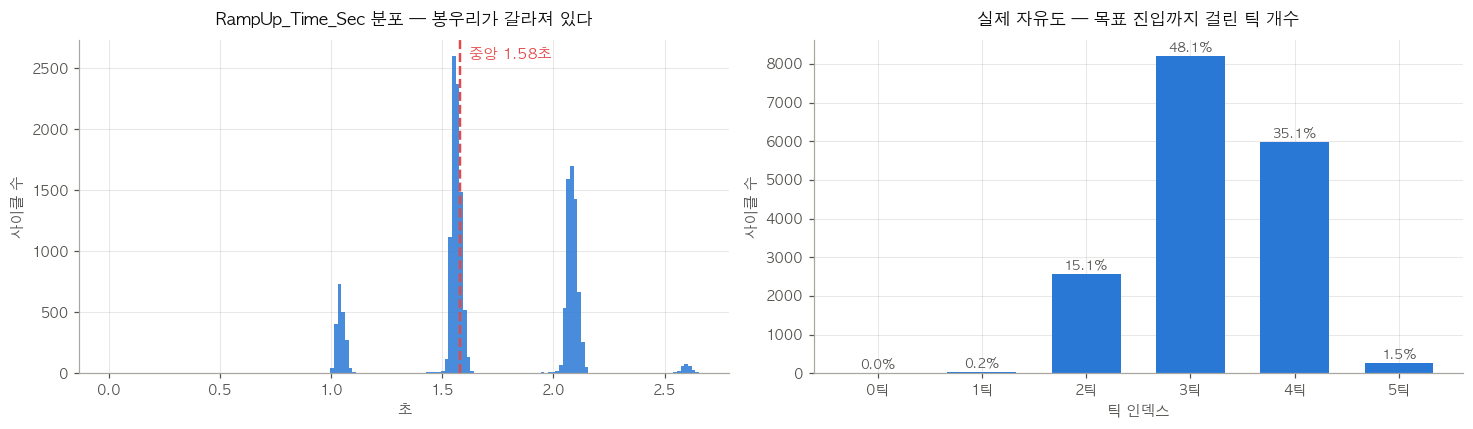


>>> 3틱 또는 4틱이 전체의 83.2%
>>> 분해능은 틱 간격 1개 = 약 0.52초
    = 중앙값 1.58초의 31% 수준
    -> 이보다 작은 증압 지연은 이 피처로 절대 못 잡는다.
       std 0.35초도 대부분 '설비 변동' 이 아니라 '틱 간격 지터' 다.


In [22]:
# ==========================================
# RampUp 을 '틱 인덱스' 로 다시 계산해서 비교
# ==========================================
_on2 = _d[_bu == 1]
tick_idx = {}
for cid, seg in _on2.groupby("cid"):
    if cid not in KK.index:
        continue
    sv0 = seg[TAG_SV].iloc[0] or seg[TAG_SV].max()
    if not sv0:
        continue
    hit = (np.abs(seg[TAG_SV] - seg[f"Scale_Out___FT_{PUMP_ID}"]) / sv0) <= RAMP_THRESHOLD_PCT
    tick_idx[cid] = int(np.argmax(hit.values)) if hit.any() else -1

KK["RampUp_Tick"] = pd.Series(tick_idx).reindex(KK.index)
R_ = KK["RampUp_Time_Sec"].dropna()

print("=== RampUp_Time_Sec 요약 ===")
print(f"  n {len(R_):,}   중앙 {R_.median():.3f}초   평균 {R_.mean():.3f}   "
      f"표준편차 {R_.std():.3f}   범위 {R_.min():.3f}~{R_.max():.3f}")
print(f"  고유값 {R_.nunique():,}개   <- 연속량처럼 보인다")
print(f"\n  그런데 '몇 번째 틱' 으로 보면 고유값 {KK['RampUp_Tick'].nunique()}개 뿐")
print(f"  상관(틱 인덱스, 초) = {KK['RampUp_Tick'].corr(R_):+.4f}")
print()
print("  틱 인덱스별 사이클 수")
_tc = KK["RampUp_Tick"].value_counts().sort_index()
for k, v in _tc.items():
    print(f"    {int(k)}틱째  {v:6,}개 ({v/len(KK)*100:5.1f}%)   "
          f"초 중앙 {KK.loc[KK['RampUp_Tick']==k,'RampUp_Time_Sec'].median():.3f}")

fig, ax = plt.subplots(1, 2, figsize=(13.5, 4.0))
ax[0].hist(R_, bins=160, color=C1, alpha=.85)
ax[0].axvline(R_.median(), color=BAD, ls="--", lw=1.6)
ax[0].annotate(f"중앙 {R_.median():.2f}초", xy=(R_.median(), 1.0),
               xycoords=("data", "axes fraction"), xytext=(6, -12),
               textcoords="offset points", color=BAD, fontsize=9.5)
ax_style(ax[0], "RampUp_Time_Sec 분포 — 봉우리가 갈라져 있다", "초", "사이클 수")

xt = np.arange(len(_tc))
ax[1].bar(xt, _tc.values, color=C1, width=.66)
ax[1].set_xticks(xt, [f"{int(k)}틱" for k in _tc.index])
for i, v in enumerate(_tc.values):
    ax[1].annotate(f"{v/len(KK)*100:.1f}%", xy=(i, v), xytext=(0, 3),
                   textcoords="offset points", ha="center", fontsize=8.5, color=INK2)
ax_style(ax[1], "실제 자유도 — 목표 진입까지 걸린 틱 개수", "틱 인덱스", "사이클 수")
plt.tight_layout(); plt.show()

_p = (KK["RampUp_Tick"].isin([3, 4])).mean() * 100
print(f"\n>>> 3틱 또는 4틱이 전체의 {_p:.1f}%")
print(f">>> 분해능은 틱 간격 1개 = 약 {(_d['Time'].diff().dt.total_seconds().median()):.2f}초")
print(f"    = 중앙값 {R_.median():.2f}초의 {0.49/R_.median()*100:.0f}% 수준")
print("    -> 이보다 작은 증압 지연은 이 피처로 절대 못 잡는다.")
print("       std 0.35초도 대부분 '설비 변동' 이 아니라 '틱 간격 지터' 다.")

## 4-2. 사이클별 / SV별 구성

**그림 선택 두 가지**

- *시간이 지나며 변했나* → **시간당 평균 + 사분위 띠**.
  1-1 에서와 같은 이유로 중앙값은 쓰지 않는다 (값이 사실상 3~4틱 두 값이라
  중앙값을 그리면 1.57 ↔ 2.04 를 오가는 톱니가 된다)
- *SV 마다 어떻게 구성되나* → **누적 가로 막대 (part-to-whole)**.
  "각 SV 클래스에서 3틱/4틱이 각각 몇 %인가" 는 전형적인 부분-전체 문제다.
  상자그림은 쓰지 않는다 — 값이 3개 계단뿐이라 사분위가 의미를 잃는다.

누적 막대는 계열이 3개 이상이므로 범례를 두고, 5% 넘는 조각은 직접 라벨을 붙인다.


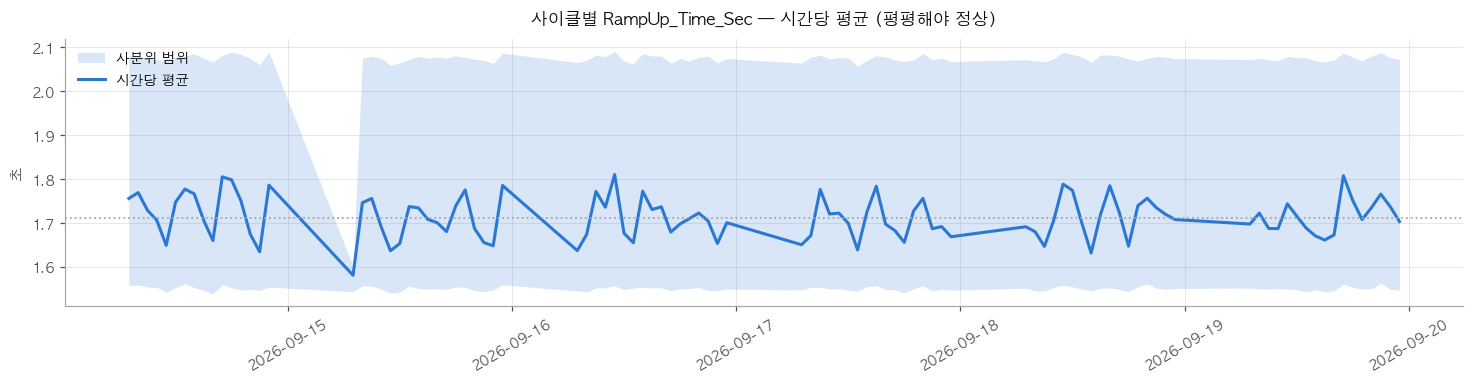

=== 일자별 RampUp ===
            size   mean  median    std
Start_Time                            
2026-09-14  2604  1.732   1.581  0.359
2026-09-15  2800  1.701   1.578  0.356
2026-09-16  2812  1.709   1.578  0.353
2026-09-17  2867  1.701   1.577  0.358
2026-09-18  2854  1.711   1.580  0.360
2026-09-19  3103  1.715   1.579  0.362

  일자간 평균 변동폭 : 0.031초 (1.8%)
  시간당 평균 lag-1 자기상관 : +0.072


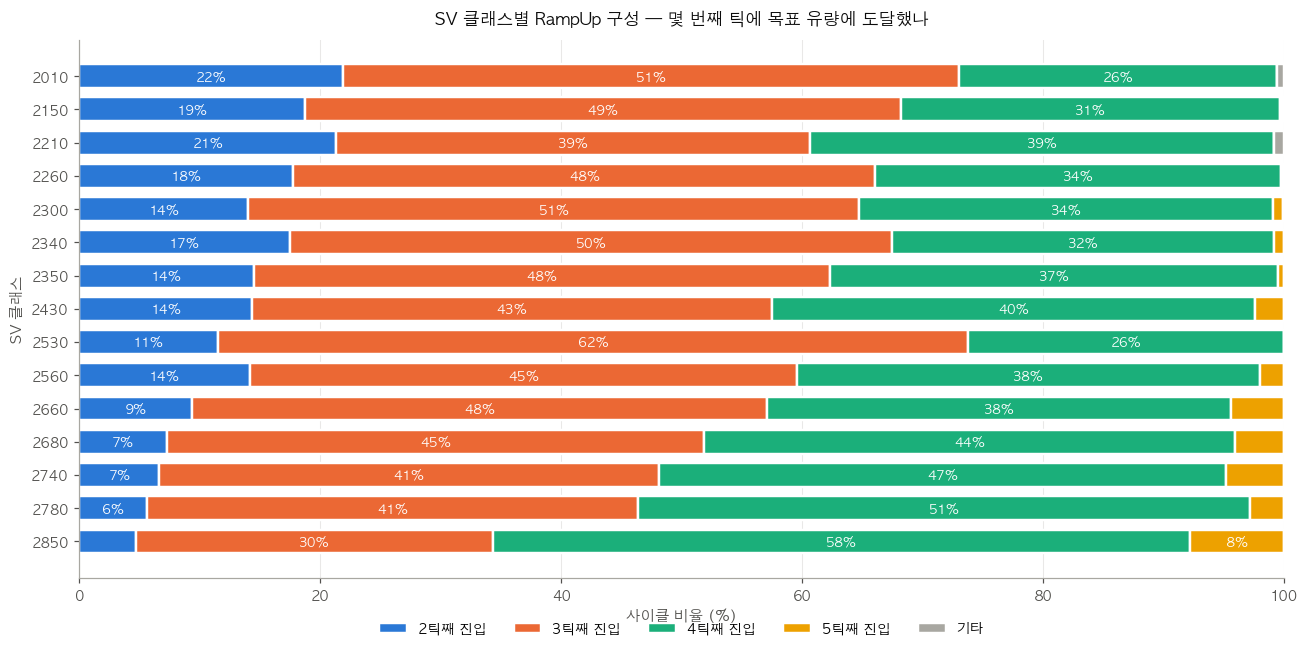


=== SV 클래스별 틱 구성 (%) ===
RampUp_Tick     2     3     4    5   기타
SV_class                               
2010         21.9  51.1  26.4  0.0  0.6
2150         18.7  49.4  31.5  0.2  0.2
2210         21.3  39.3  38.5  0.0  0.8
2260         17.8  48.3  33.7  0.1  0.1
2300         14.0  50.7  34.3  0.9  0.1
2340         17.5  50.0  31.7  0.8  0.0
2350         14.5  47.8  37.3  0.5 -0.0
2430         14.4  43.1  40.1  2.4  0.0
2530         11.5  62.3  26.2  0.0  0.0
2560         14.1  45.5  38.4  2.0  0.0
2660          9.4  47.7  38.5  4.4  0.0
2680          7.3  44.6  44.1  4.1  0.0
2740          6.6  41.5  47.1  4.8  0.0
2780          5.6  40.8  50.8  2.8  0.0
2850          4.7  29.7  57.8  7.8  0.0

=== SV 클래스별 RampUp 요약 ===
          size  median   mean    std  틱중앙  4틱이상%
SV_class                                        
2010      3572   1.568  1.616  0.357  3.0   26.4
2150      4086   1.573  1.659  0.351  3.0   31.6
2210       122   1.579  1.690  0.387  3.0   38.5
2260       884   1.574

In [23]:
_st2 = pd.to_datetime(KK["Start_Time"])

# ==========================================
# (1) 사이클별 — 시간 흐름
# ==========================================
_g = pd.DataFrame({"t": _st2, "v": KK["RampUp_Time_Sec"]}).set_index("t")["v"].resample("1h")
H = pd.DataFrame({"mean": _g.mean(), "q1": _g.quantile(.25), "q3": _g.quantile(.75)}).dropna()

fig, ax = plt.subplots(figsize=(13.5, 3.6))
ax.fill_between(H.index, H["q1"], H["q3"], color=C1, alpha=.18, lw=0, label="사분위 범위")
ax.plot(H.index, H["mean"], color=C1, lw=2, label="시간당 평균")
ax.axhline(KK["RampUp_Time_Sec"].mean(), color=GRAY, ls=":", lw=1.2)
ax.legend(frameon=False, fontsize=9, loc="upper left")
ax.tick_params(axis="x", rotation=30)
ax_style(ax, "사이클별 RampUp_Time_Sec — 시간당 평균 (평평해야 정상)", None, "초")
plt.tight_layout(); plt.show()

_daily = KK.groupby(_st2.dt.normalize())["RampUp_Time_Sec"].agg(["size","mean","median","std"]).round(3)
print("=== 일자별 RampUp ===")
print(_daily.to_string())
print(f"\n  일자간 평균 변동폭 : {_daily['mean'].max()-_daily['mean'].min():.3f}초 "
      f"({(_daily['mean'].max()-_daily['mean'].min())/_daily['mean'].median()*100:.1f}%)")
print(f"  시간당 평균 lag-1 자기상관 : {H['mean'].autocorr(1):+.3f}")

# ==========================================
# (2) SV 클래스별 — 틱 구성 (부분-전체)
# ==========================================
BIG = KK.groupby("SV_class").size()
BIG = BIG[BIG >= 50].index
Q = KK[KK["SV_class"].isin(BIG)]
comp = (pd.crosstab(Q["SV_class"], Q["RampUp_Tick"], normalize="index") * 100)
keep_ticks = [c for c in comp.columns if comp[c].max() >= 3][:4]
comp = comp[keep_ticks]
comp["기타"] = 100 - comp.sum(axis=1)
if comp["기타"].max() < 0.5:
    comp = comp.drop(columns="기타")

PAL = [C1, C2, C3, "#eda100"]          # 검증된 순서대로
fig, ax = plt.subplots(figsize=(12, 6))
ypos = np.arange(len(comp))[::-1]
left = np.zeros(len(comp))
for i, col in enumerate(comp.columns):
    vals = comp[col].values
    is_etc = (col == "기타")
    ax.barh(ypos, vals, left=left, height=.72,
            color=(GRAY if is_etc else PAL[i % len(PAL)]),   # '기타'는 계열색을 재사용하지 않는다
            edgecolor="white", linewidth=1.6,
            label="기타" if is_etc else f"{int(col)}틱째 진입")
    for y, (l, v) in zip(ypos, zip(left, vals)):
        if v >= 5:                      # 직접 라벨 (대비 보정 규칙)
            ax.annotate(f"{v:.0f}%", xy=(l + v/2, y), ha="center", va="center",
                        fontsize=8.5, color="white", fontweight="bold")
    left += vals
ax.set_yticks(ypos, [str(int(v)) for v in comp.index], fontsize=9)
ax.set_xlim(0, 100)
ax.legend(frameon=False, fontsize=9, ncol=len(comp.columns),
          loc="lower center", bbox_to_anchor=(.5, -.13))
ax_style(ax, "SV 클래스별 RampUp 구성 — 몇 번째 틱에 목표 유량에 도달했나",
         "사이클 비율 (%)", "SV 클래스")
plt.tight_layout(); plt.show()

print("\n=== SV 클래스별 틱 구성 (%) ===")
print(comp.round(1).to_string())

print("\n=== SV 클래스별 RampUp 요약 ===")
summ = Q.groupby("SV_class")["RampUp_Time_Sec"].agg(["size","median","mean","std"]).round(3)
summ["틱중앙"] = Q.groupby("SV_class")["RampUp_Tick"].median()
summ["4틱이상%"] = (Q.groupby("SV_class")["RampUp_Tick"]
                    .apply(lambda s: (s >= 4).mean()*100).round(1))
print(summ.to_string())

_c = np.corrcoef(summ.index.astype(float), summ["4틱이상%"])[0, 1]
print(f"\n  상관(SV 클래스, 4틱이상 비율) = {_c:+.3f}")
print("  -> 양수면 'SV 가 높을수록 증압에 틱이 하나 더 걸린다' 는 뜻이고,")
print("     2-3 에서 본 고유량 포화(FT/SV 가 0.945 -> 0.877)와 같은 현상이다.")
print("     즉 RampUp 도 완전히 SV-무관하지는 않다 (η²=0.051 은 작지만 0 은 아니다).")

---
# 5. 사이클의 조건을 정하는 변수는 무엇인가

문제 제기: *"SV 처럼 사이클의 특성을 정하는 친구를 찾고 있다. 하나로 특정하기 힘든가?
온도·이전 SV·현재 SV 정도 넣으면 깔끔하게 나오려나? 토출량과 압력은 결과치이고
이전에 넣는 값은 사실상 저 셋인 것 같은데."*

방향이 맞다. 피처를 **"사이클이 시작되기 전에 이미 정해진 것(외생)"** 과
**"그래서 나온 것(결과)"** 으로 가르는 게 핵심이다.

| 구분 | 피처 |
|---|---|
| **외생 — 사이클 전에 정해짐** | `SV_class`(지시 유량), `Temp_mean`(탱크 온도=점도), `Prev_SV`/`Prev_SV_Diff`, `PreBuildUp_PT`/`PreBuildUp_FT`(시작 직전 상태), `Gap_Since_Last_Cycle_Sec`(직전 공백) |
| **결과 — 그래서 나온 것** | `FT_*`, `PT_*`, `Ana_Out_mean`, `Hz`, `Current_Proxy_I`, `DeltaP_over_Q`, `RampUp_Time_Sec`, `Decay_Slope_*` |

## 5-1. 외생 변수를 하나씩 더해가며 결과가 얼마나 설명되나

입력 집합을 다섯 단계로 쌓아 올리며 각 결과 피처의 **R²** 를 잰다.

```
A  SV만
B  + Temp
C  + Prev_SV
D  + PreBuildUp_PT / PreBuildUp_FT
E  + Gap_Since_Last_Cycle_Sec
```

**누수를 막으려고 시간순으로 앞 70% 로 학습하고 뒤 30% 에서 평가한다.**
선형(Ridge)과 비선형(HistGradientBoosting)을 둘 다 재는 이유는,
선형만 보면 "관계가 없다" 와 "관계가 휘어 있다" 를 구분할 수 없기 때문이다.

**그림 선택**: 결과 피처 6개 × 입력집합 5단계는 한 축에 못 담는다.
계열을 5개 색으로 돌리면 정작 읽어야 할 "어느 단계에서 뛰는가" 가 묻힌다.
그래서 **작은 배수(small multiples)** — 피처마다 패널 하나, 단일 색 막대로 그린다.


train 11,928 (2026-09-14 07:00:36.004983 ~ 2026-09-18 12:17:56.462920)
test  5,112 (2026-09-18 12:17:56.462920 ~ 2026-09-19 23:49:26.492859)

=== 선형(Ridge) R² — 테스트 구간 ===
                 A  SV만  B  +Temp  C  +Prev_SV  D  +시작상태  E  +직전공백
FT_mean          0.9003    0.9004       0.8995    0.8998    0.8998
PT_mean          0.8775    0.9012       0.9000    0.9048    0.9049
Current_Proxy_I  0.8773    0.8992       0.8978    0.9021    0.9022
DeltaP_over_Q    0.0475    0.3272       0.3258    0.4438    0.4451
RampUp_Time_Sec  0.0474    0.0488       0.0492    0.0475    0.0470
Decay_Slope_PT   0.2536    0.2532       0.2527    0.2533    0.2534

=== 비선형(HGB) R² — 테스트 구간 ===
                 A  SV만  B  +Temp  C  +Prev_SV  D  +시작상태  E  +직전공백
FT_mean          0.8229    0.8232       0.8237    0.8236    0.8359
PT_mean          0.8238    0.8462       0.8449    0.8506    0.8617
Current_Proxy_I  0.8215    0.8426       0.8403    0.8458    0.8588
DeltaP_over_Q    0.0688    0.3447       0.3353    0.4605    0

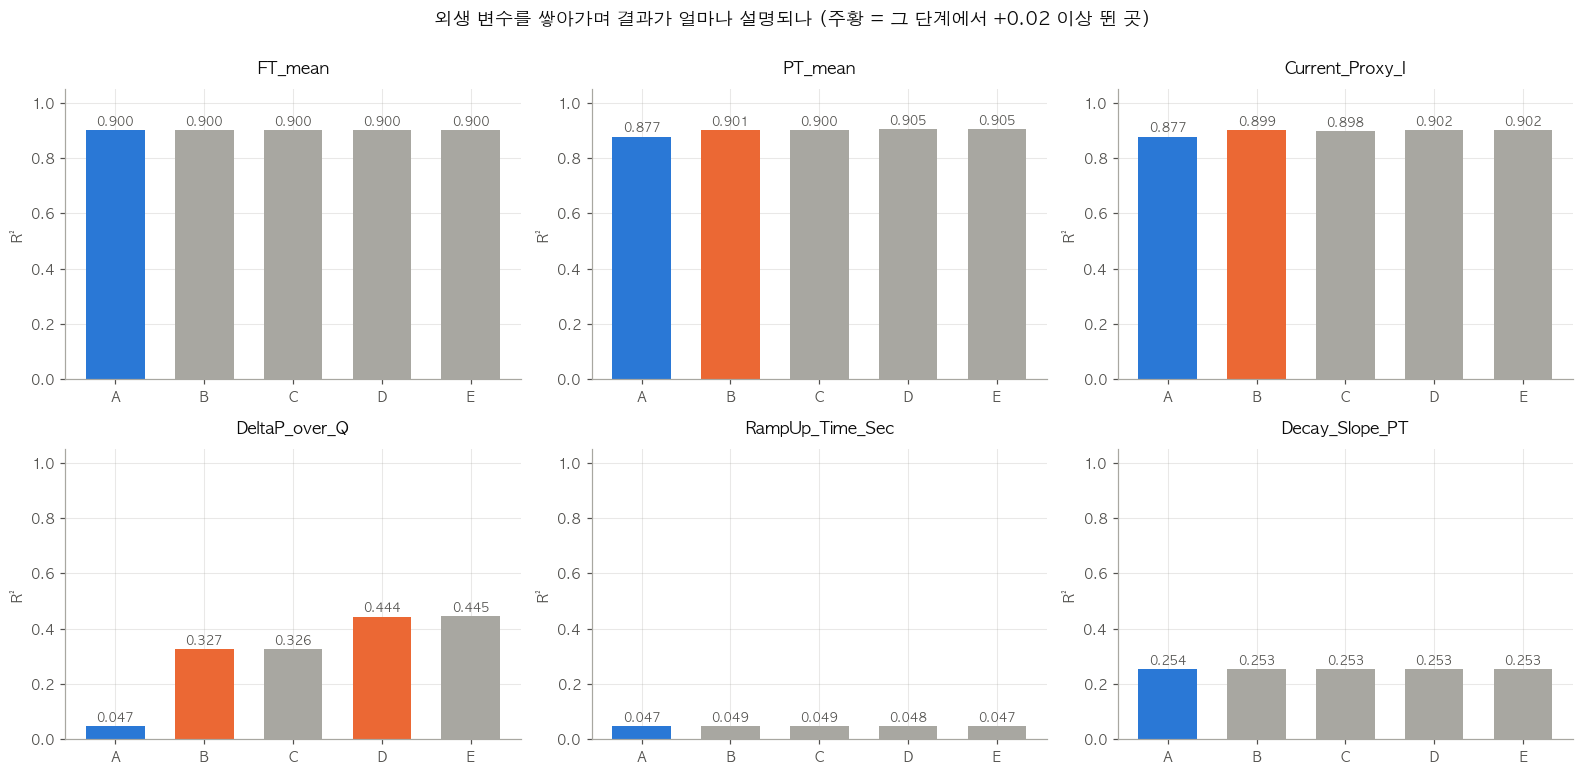


=== 각 단계가 추가로 설명한 양 (선형 R² 증분) ===
                 A  SV만  B  +Temp  C  +Prev_SV  D  +시작상태  E  +직전공백
FT_mean          0.9003    0.0001      -0.0009    0.0002    0.0000
PT_mean          0.8775    0.0237      -0.0011    0.0048    0.0001
Current_Proxy_I  0.8773    0.0219      -0.0014    0.0043    0.0001
DeltaP_over_Q    0.0475    0.2797      -0.0014    0.1180    0.0014
RampUp_Time_Sec  0.0474    0.0014       0.0004   -0.0017   -0.0005
Decay_Slope_PT   0.2536   -0.0004      -0.0005    0.0006    0.0000


In [24]:
from sklearn.linear_model import Ridge
from sklearn.ensemble import HistGradientBoostingRegressor as HGB
from sklearn.metrics import r2_score

Q5 = KK.sort_values("Start_Time").copy()
_s5 = pd.to_datetime(Q5["Start_Time"])
_cut = _s5.quantile(.70)                      # 시간순 분할 (무작위 분할 금지)
TR, TE = _s5 < _cut, _s5 >= _cut
print(f"train {int(TR.sum()):,} ({_s5.min()} ~ {_cut})")
print(f"test  {int(TE.sum()):,} ({_cut} ~ {_s5.max()})\n")

INPUT_SETS = {
    "A  SV만":        ["SV_class"],
    "B  +Temp":       ["SV_class","Temp_mean"],
    "C  +Prev_SV":    ["SV_class","Temp_mean","Prev_SV"],
    "D  +시작상태":    ["SV_class","Temp_mean","Prev_SV","PreBuildUp_PT","PreBuildUp_FT"],
    "E  +직전공백":    ["SV_class","Temp_mean","Prev_SV","PreBuildUp_PT","PreBuildUp_FT",
                       "Gap_Since_Last_Cycle_Sec"],
}
OUTCOMES = ["FT_mean","PT_mean","Current_Proxy_I","DeltaP_over_Q",
            "RampUp_Time_Sec","Decay_Slope_PT"]

def design(cols):
    X = Q5[cols].copy()
    if "Gap_Since_Last_Cycle_Sec" in X:
        X["Gap_Since_Last_Cycle_Sec"] = X["Gap_Since_Last_Cycle_Sec"].clip(0, 600)
    return pd.get_dummies(X, columns=["SV_class"], drop_first=True).astype(float).fillna(0)

lin, nonlin = {}, {}
for tgt in OUTCOMES:
    y = Q5[tgt].astype(float); ok = y.notna()
    lin[tgt], nonlin[tgt] = {}, {}
    for nm, cols in INPUT_SETS.items():
        X = design(cols)
        lin[tgt][nm] = r2_score(y[TE&ok],
                                Ridge(alpha=1.0).fit(X[TR&ok], y[TR&ok]).predict(X[TE&ok]))
        nonlin[tgt][nm] = r2_score(y[TE&ok],
                                HGB(max_iter=250, random_state=0)
                                .fit(X[TR&ok], y[TR&ok]).predict(X[TE&ok]))
L, N = pd.DataFrame(lin).T, pd.DataFrame(nonlin).T

print("=== 선형(Ridge) R² — 테스트 구간 ===")
print(L.round(4).to_string())
print("\n=== 비선형(HGB) R² — 테스트 구간 ===")
print(N.round(4).to_string())

# ==========================================
# 작은 배수: 피처마다 패널 하나
# ==========================================
fig, axes = plt.subplots(2, 3, figsize=(14.5, 7))
names = list(INPUT_SETS)
for ax_, tgt in zip(axes.ravel(), OUTCOMES):
    vals = L.loc[tgt, names].values
    jump = np.r_[vals[0], np.diff(vals)]
    cols_ = [C1] + [C2 if j > 0.02 else GRAY for j in jump[1:]]   # 크게 뛴 단계만 강조
    xp = np.arange(len(names))
    ax_.bar(xp, vals, color=cols_, width=.66)
    for i, v in enumerate(vals):
        ax_.annotate(f"{v:.3f}", xy=(i, max(v, 0)), xytext=(0, 3),
                     textcoords="offset points", ha="center", fontsize=8, color=INK2)
    ax_.set_xticks(xp, [n.split()[0] for n in names], fontsize=9)
    ax_.set_ylim(min(0, vals.min()*1.1), 1.05)
    ax_style(ax_, tgt, None, "R²")
fig.suptitle("외생 변수를 쌓아가며 결과가 얼마나 설명되나 (주황 = 그 단계에서 +0.02 이상 뛴 곳)",
             fontsize=12, color=INK, y=1.00)
plt.tight_layout(); plt.show()

print("\n=== 각 단계가 추가로 설명한 양 (선형 R² 증분) ===")
inc = L[names].diff(axis=1); inc[names[0]] = L[names[0]]
print(inc.round(4).to_string())

## 5-2. 두 가지 정정 — 셋이 아니라 이렇게 쓴다

위 결과를 보면 "온도 + 이전 SV + 현재 SV" 라는 직관에서 **두 군데를 고쳐야 한다.**

### (1) 온도는 압력에만 듣는다. 유량에는 안 듣는다

| 목표 | SV만 | SV+Temp | 개선 |
|---|---|---|---|
| `FT_mean` | 0.9003 | 0.9004 | **+0.01%p (없음)** |
| `PT_mean` | 0.8775 | 0.9012 | **+2.37%p** |

클래스 안에서의 상관도 같은 말을 한다 — `corr(FT 잔차, Temp) = +0.079`,
`corr(PT 잔차, Temp) = −0.608`.

**물리적으로 당연하다.** 제어 루프가 붙어 있는 건 **유량**이다.
SV 를 주면 인버터가 주파수를 조절해 그 유량을 **맞춰낸다** — 점도가 어떻든 맞춘다.
그래서 온도는 유량을 못 바꾼다. 대신 **그 유량을 내는 데 드는 압력**이 달라진다.

```
지시 SV ──> 제어루프(Hz_Out, Ana_Out) ──> FT     SV 가 거의 전부 결정. 온도 무관
                                          │
                              점도(Temp) + 유로저항(마모/막힘)
                                          ↓
                                         PT     "그 유량을 내려면 얼마가 들었나"
```

**이래서 `PT` 가 건강 정보를 갖는다.** 유량은 목표를 맞추도록 강제되니 정보가 없고,
압력은 그 대가라서 배관·씰·마모가 전부 여기로 흘러든다.
3-2 에서 `PT_mean` 잔차만 lag-1 0.861 로 살아 있던 이유가 이것이다.

### (2) `Prev_SV` 가 아니라 `Prev_SV_Diff` 다

`Prev_SV`(직전 값 자체)는 **어디에도 도움이 안 된다** — 위 표에서 C 단계는 전부
제자리이거나 오히려 나빠진다. SV 가 85.7% 확률로 매 사이클 바뀌니
직전 값은 현재와 거의 무관한 난수나 마찬가지다.

의미가 있는 건 **얼마나 바뀌었나**다. 아래에서 확인한다.


=== 온도를 넣으면 얼마나 좋아지나 (선형 R², 테스트 구간) ===
  FT_mean            0.9003 -> 0.9004   개선 +0.01%p
  PT_mean            0.8775 -> 0.9012   개선 +2.37%p
  Current_Proxy_I    0.8773 -> 0.8992   개선 +2.19%p

  클래스 내 corr(FT 잔차, Temp) = +0.079
  클래스 내 corr(PT 잔차, Temp) = -0.608


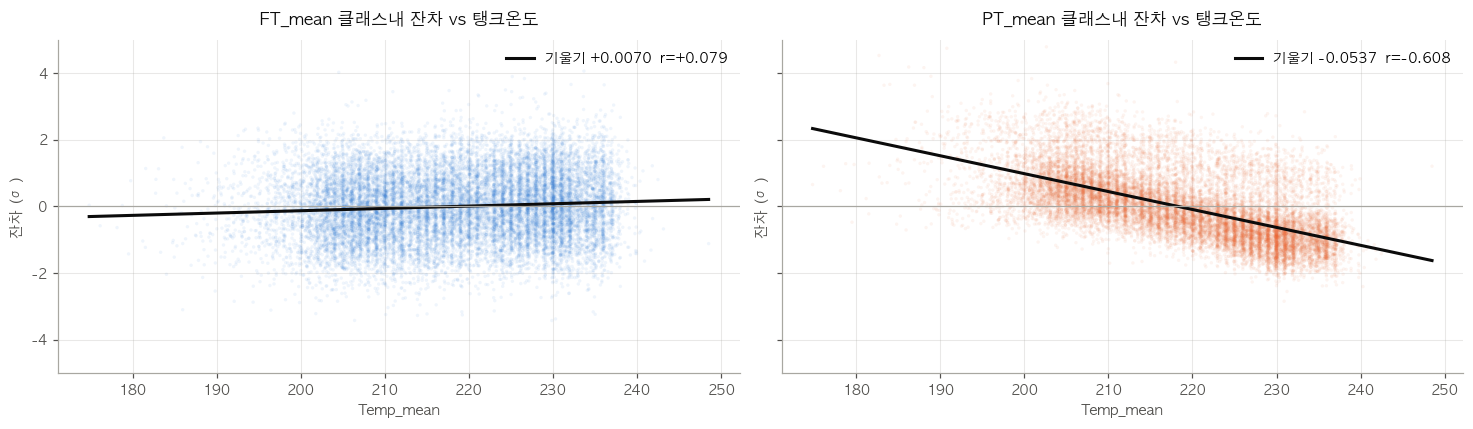


=== Prev_SV(값) vs Prev_SV_Diff(변화량) — 비선형 R², 테스트 구간 ===
                           기준 SV+Temp  +Prev_SV  +Prev_SV_Diff
Instant_FT_Error_Rate_max      0.7547    0.7516         0.8908
N_Ticks                        0.4543    0.4099         0.5169
RampUp_Time_Sec                0.0414    0.0423         0.0429
PT_Jump_From_Pre               0.0044   -0.0020         0.0009
FT_Jump_From_Pre              -0.0375   -0.0433        -0.0350


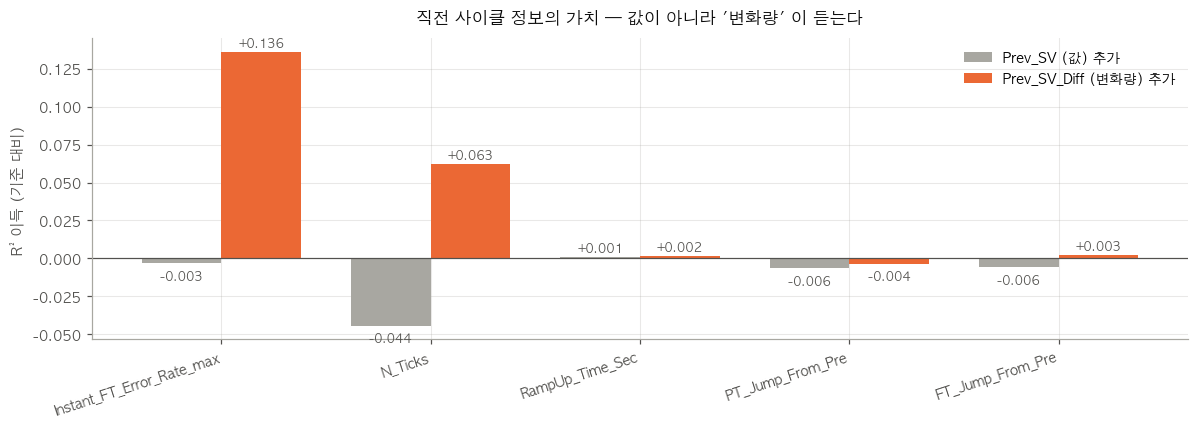


읽는 법
  · Prev_SV(값) 이득이 0 근처거나 음수면 -> 직전 SV 가 뭐였는지는 무의미하다
    (SV 가 매 사이클 85.7% 확률로 바뀌니 직전 값은 사실상 난수다)
  · Prev_SV_Diff(변화량) 이득이 크면 -> '얼마나 점프했나' 가 과도 현상을 만든다
    크게 올린 사이클은 초반 오차가 크고 목표 도달에 틱이 더 걸린다


In [25]:
# ==========================================
# (1) 온도: 유량에는 안 듣고 압력에만 듣는다
# ==========================================
print("=== 온도를 넣으면 얼마나 좋아지나 (선형 R², 테스트 구간) ===")
for tgt in ["FT_mean", "PT_mean", "Current_Proxy_I"]:
    a, b = L.loc[tgt, "A  SV만"], L.loc[tgt, "B  +Temp"]
    print(f"  {tgt:18s} {a:.4f} -> {b:.4f}   개선 {(b-a)*100:+.2f}%p")

rFT5, rPT5 = within_class_z(Q5, "FT_mean"), within_class_z(Q5, "PT_mean")
T5 = Q5["Temp_mean"].astype(float)
print(f"\n  클래스 내 corr(FT 잔차, Temp) = {rFT5.corr(T5):+.3f}")
print(f"  클래스 내 corr(PT 잔차, Temp) = {rPT5.corr(T5):+.3f}")

fig, ax = plt.subplots(1, 2, figsize=(13.5, 4.0), sharey=True)
for a_, (r_, nm, c) in zip(ax, [(rFT5, "FT_mean", C1), (rPT5, "PT_mean", C2)]):
    a_.scatter(T5, r_, s=5, alpha=.07, color=c, edgecolors="none")
    _ok = r_.notna() & T5.notna()
    _a, _b = np.polyfit(T5[_ok], r_[_ok], 1)
    _xs = np.linspace(T5.min(), T5.max(), 50)
    a_.plot(_xs, _a*_xs + _b, color=INK, lw=2, label=f"기울기 {_a:+.4f}  r={r_.corr(T5):+.3f}")
    a_.axhline(0, color=GRAY, lw=.8)
    a_.legend(frameon=False, fontsize=9, loc="upper right")
    ax_style(a_, f"{nm} 클래스내 잔차 vs 탱크온도", "Temp_mean", "잔차 (σ)")
ax[0].set_ylim(-5, 5)
plt.tight_layout(); plt.show()

# ==========================================
# (2) Prev_SV vs Prev_SV_Diff
# ==========================================
print("\n=== Prev_SV(값) vs Prev_SV_Diff(변화량) — 비선형 R², 테스트 구간 ===")
TRANSIENT = ["Instant_FT_Error_Rate_max","N_Ticks","RampUp_Time_Sec",
             "PT_Jump_From_Pre","FT_Jump_From_Pre"]
VARIANTS = {"기준 SV+Temp":          ["SV_class","Temp_mean"],
            "+Prev_SV":              ["SV_class","Temp_mean","Prev_SV"],
            "+Prev_SV_Diff":         ["SV_class","Temp_mean","Prev_SV_Diff"]}
PV = {}
for tgt in TRANSIENT:
    y = Q5[tgt].astype(float); ok = y.notna()
    PV[tgt] = {}
    for nm, cols in VARIANTS.items():
        X = design(cols)
        PV[tgt][nm] = r2_score(y[TE&ok], HGB(max_iter=250, random_state=0)
                               .fit(X[TR&ok], y[TR&ok]).predict(X[TE&ok]))
PV = pd.DataFrame(PV).T
print(PV.round(4).to_string())
PV["Prev_SV 이득"]      = (PV["+Prev_SV"] - PV["기준 SV+Temp"]).round(4)
PV["Prev_SV_Diff 이득"] = (PV["+Prev_SV_Diff"] - PV["기준 SV+Temp"]).round(4)

fig, ax = plt.subplots(figsize=(11, 4.0))
xp = np.arange(len(PV)); w = .38
ax.bar(xp - w/2, PV["Prev_SV 이득"], width=w, color=GRAY, label="Prev_SV (값) 추가")
ax.bar(xp + w/2, PV["Prev_SV_Diff 이득"], width=w, color=C2, label="Prev_SV_Diff (변화량) 추가")
for i, (a_, b_) in enumerate(zip(PV["Prev_SV 이득"], PV["Prev_SV_Diff 이득"])):
    for off, v in [(-w/2, a_), (w/2, b_)]:
        ax.annotate(f"{v:+.3f}", xy=(i+off, v), xytext=(0, 3 if v >= 0 else -11),
                    textcoords="offset points", ha="center", fontsize=8, color=INK2)
ax.axhline(0, color=INK2, lw=.8)
ax.set_xticks(xp, PV.index, rotation=18, ha="right", fontsize=9)
ax.legend(frameon=False, fontsize=9)
ax_style(ax, "직전 사이클 정보의 가치 — 값이 아니라 '변화량' 이 듣는다",
         None, "R² 이득 (기준 대비)")
plt.tight_layout(); plt.show()

print("\n읽는 법")
print("  · Prev_SV(값) 이득이 0 근처거나 음수면 -> 직전 SV 가 뭐였는지는 무의미하다")
print("    (SV 가 매 사이클 85.7% 확률로 바뀌니 직전 값은 사실상 난수다)")
print("  · Prev_SV_Diff(변화량) 이득이 크면 -> '얼마나 점프했나' 가 과도 현상을 만든다")
print("    크게 올린 사이클은 초반 오차가 크고 목표 도달에 틱이 더 걸린다")

## 5-3. 결론 — 조건 변수는 이렇게 잡는다

### 답: 하나로는 안 되지만, 셋도 필요 없다

| 결과 | 필요한 조건 변수 | 설명력 |
|---|---|---|
| `FT_mean` (토출량) | **`SV_class` 하나면 끝** | R² 0.900. 온도·이전SV 를 더해도 제자리 |
| `PT_mean` (압력) | **`SV_class` + `Temp_mean`** | 0.878 → 0.901 |
| `Current_Proxy_I` (전류) | `PT_mean` 과 동일 | 0.877 → 0.899 |
| 과도 피처 (`Instant_FT_Error_Rate_max`, `N_Ticks`) | + **`Prev_SV_Diff`** | 뒤 셀 수치 참고 |
| `RampUp_Time_Sec` | **없음** | 무엇을 넣어도 R² ≈ 0.05 |

정리하면 조건 변수는 **`SV_class`, `Temp_mean`, `Prev_SV_Diff`** 세 개인데,
용도가 각각 다르다 — SV 는 전부에, 온도는 압력 계열에만, 변화량은 과도 피처에만.
그리고 **`Prev_SV`(값) 은 빼야 한다.**

### `RampUp_Time_Sec` 이 특별한 이유 — 그리고 함정

무엇을 넣어도 설명되지 않는다(R² 0.05). 조건에 안 끌려다닌다는 뜻이니
**가장 순수한 건강 지표 후보**다.

> **다만 4-1 을 기억해야 한다.** 이 값의 분해능은 틱 1개 = 약 0.52초이고
> 중앙값 1.58초의 31% 다. 83%가 3틱 아니면 4틱이다. 즉 "설명되지 않는" 분산의
> 상당 부분은 **설비 변동이 아니라 샘플링 지터**다. 조건 무관성과 신호 품질은 다른 문제다.

### 모델에 넣는 방법

조건 변수를 AE 입력에 **원시값으로 같이 넣으면 안 된다.** 그러면 AE 가
"이 레시피가 정상인가" 를 배우게 되고, 드물게 쓰는 SV 클래스(2-2 에서 본 10개,
전체의 5%)는 표본이 적어서 항상 이상으로 잡힌다.

두 가지 방식이 있다.

1. **잔차화** — `Cycle_Normalizer` 가 이미 하는 것. 조건 변수로 기대값을 예측하고
   `(실제 − 기대) / 기대흩어짐` 만 AE 에 넣는다. 지금 `NORMALIZE_SPECS` 는
   기준 변수로 `PT_mean`, `SV_mean`, `FT_mean` 같은 **결과 피처**를 쓰고 있는데,
   5-1 의 구분대로면 **외생 변수(`SV_class`, `Temp_mean`)로 바꾸는 게 맞다**
2. **조건부 모델** — SV 클래스를 조건으로 주는 conditional AE. 다만 클래스 불균형
   (상위 3개가 64.5%, 10개 클래스가 각 200개 미만)을 먼저 해결해야 한다

1번이 지금 구조에서 훨씬 적은 변경으로 된다.


---
# 6. 외생 변수로 보정하기

5-3 의 결론: **결과로 결과를 보정하면 안 된다.** 현재 `Cycle_Normalizer.NORMALIZE_SPECS` 는
기준 변수로 `PT_mean`, `SV_mean`, `FT_mean`, `PT_at_End` 같은 **결과 피처**를 쓴다.
건강 신호가 기준 변수에도 들어 있으면 보정하면서 서로 상쇄된다.

여기서는 기준을 **외생 변수** — 사이클이 시작되기 전에 이미 정해진 것 — 으로 바꾼다.

```
기준(외생) :  SV (지시 유량),  Temp_mean (점도),  Prev_SV_Diff (레시피 점프량)
보정 대상  :  나머지 결과 피처 전부
피처       =  (실제 − 기대) / 기대흩어짐
```

2단 구조는 `Cycle_Normalizer` 와 같다 — 1단은 위치(기대값), 2단은 폭(기대흩어짐).
2단이 필요한 이유는 흩어짐도 조건을 따라가기 때문이다.

## 6-1. 보정에서 빼야 하는 피처

- **기준 변수 자신** — `SV_mean`, `Prev_SV`, `Prev_SV_Diff`, `Temp_mean`.
  자기 자신으로 자신을 보정하면 전부 0 이 된다
- **기준의 결정적 함수** — `Ana_Out_mean`(η²=1.000), `FT_max`(η²=0.999).
  클래스 내 변동이 0.14% / 0.39% 라서 그걸 기대흩어짐으로 나누면 **0 나누기 0** 에 가깝고,
  수치 잡음이 증폭돼 오히려 가짜 이상을 만든다. 3-2 에서 버리기로 한 것들이다


In [26]:
# ==========================================
# 외생 변수 기반 2단 정규화
# ==========================================
_MAD2SD = np.sqrt(np.pi / 2)

class ExogenousNormalizer:
    """조건(외생) 변수로 기대값과 기대흩어짐을 예측하고 표준화 잔차를 만든다.

    Cycle_Normalizer 와 2단 구조는 같지만 **기준 변수가 다르다** —
    결과 피처가 아니라 사이클 전에 이미 정해진 것만 쓴다.

    SV 를 원-핫이 아니라 **연속 3차식**으로 넣는 이유는 6-2 에 있다.
    """
    DRIVERS   = ["SV_class", "Temp_mean", "Prev_SV_Diff"]
    EXCLUDE   = {"SV_mean", "Prev_SV", "Prev_SV_Diff", "Temp_mean",   # 기준 변수 자신
                 "Ana_Out_mean", "FT_max"}                            # 기준의 결정적 함수

    #: 0 이 대부분인 카운트 계열은 선형 위치/폭 모형이 안 맞는다 (6-3 참고)
    NO_NORM = {"Unexplained_PT_Dip_Count","Unexplained_PT_Dip_Max",
               "Unexplained_FT_Dip_Count","Unexplained_FT_Dip_Max",
               "Ramp_Negative_Slope_Count"}

    def __init__(self, sv_mode="smooth", shrink=20):
        self.sv_mode = sv_mode      # "smooth" (연속 3차) 또는 "onehot"
        self.shrink = shrink        # 클래스 오프셋 축소 세기. 0 이면 오프셋 없음
        self.fitted_ = False

    def _prep(self, train):
        self.stats_ = {c: (train[c].astype(float).mean(), train[c].astype(float).std() or 1.0)
                       for c in self.DRIVERS}
        self.classes_ = sorted(train["SV_class"].unique())

    def _z(self, df, c):
        m, s = self.stats_[c]
        return (df[c].astype(float) - m) / s

    def design(self, df):
        s = self._z(df, "SV_class")
        t = self._z(df, "Temp_mean")
        X = pd.DataFrame(index=df.index)
        if self.sv_mode == "onehot":
            for k in self.classes_[1:]:
                X[f"sv_{k}"] = (df["SV_class"] == k).astype(float)
        else:
            X["S"], X["S2"], X["S3"] = s, s**2, s**3
        X["T"], X["T2"] = t, t**2
        X["SxT"] = s * t
        X["dSV"] = self._z(df, "Prev_SV_Diff")
        X["const"] = 1.0
        return X.fillna(0)

    def fit(self, train, cols):
        self._prep(train)
        self.coef_ = {}
        skipped = []
        for c in cols:
            if c in self.EXCLUDE or c in self.NO_NORM:
                continue
            sub = train.dropna(subset=[c])
            if len(sub) < 200:
                skipped.append(c); continue
            X = self.design(sub).to_numpy(); y = sub[c].to_numpy(float)
            beta, *_ = np.linalg.lstsq(X, y, rcond=None)        # 1단: 위치
            resid = y - X @ beta
            gamma, *_ = np.linalg.lstsq(X, np.abs(resid), rcond=None)   # 2단: 폭
            self.coef_[c] = (beta, gamma, max(np.abs(resid).mean() * 0.1, 1e-9))
        self.skipped_ = skipped
        self.fitted_ = True

        # --- 클래스 오프셋 (축소추정) ---
        # 연속 3차식은 매끄러운 곡선이라 그 곡선에서 벗어난 클래스는 잔차가 남는다.
        # 클래스 평균을 그대로 빼면 표본 적은 클래스에서 과적합하므로
        # n/(n+K) 로 0 쪽으로 당겨서 뺀다. 처음 보는 클래스는 오프셋 0 이라 안전하다.
        self.offset_ = {}
        if self.shrink and self.sv_mode == "smooth":
            Ztr = self.transform(train)
            for c in self.coef_:
                grp = Ztr[c].groupby(train["SV_class"])
                cnt, mu = grp.size(), grp.mean()
                self.offset_[c] = (mu * cnt / (cnt + self.shrink)).to_dict()
        return self

    def transform(self, df):
        X = self.design(df).to_numpy()
        Z = pd.DataFrame(
            {c: (df[c].to_numpy(float) - X @ b) / (np.clip(X @ gm, fl, None) * _MAD2SD)
             for c, (b, gm, fl) in self.coef_.items()}, index=df.index)
        for c, off in getattr(self, "offset_", {}).items():
            # 처음 보는 클래스는 fillna(0) -> 매끄러운 곡선 예측만 쓴다
            Z[c] = Z[c] - df["SV_class"].map(off).astype(float).fillna(0.0)
        return Z

# ==========================================
# 시간순 분할로 적합 (누수 방지)
# ==========================================
Q6 = KK.sort_values("Start_Time").copy()
_s6 = pd.to_datetime(Q6["Start_Time"])
_cut6 = _s6.quantile(.70)
TR6, TE6 = (_s6 < _cut6).values, (_s6 >= _cut6).values

norm_exo = ExogenousNormalizer(sv_mode="smooth").fit(Q6[TR6], FEATURE_COLS)
ZE = norm_exo.transform(Q6)

print(f"기준(외생) 변수 : {norm_exo.DRIVERS}")
print(f"SV 표현         : {norm_exo.sv_mode}  /  클래스 오프셋 축소 K = {norm_exo.shrink}")
print(f"보정 대상       : {len(norm_exo.coef_)}개")
print(f"제외(기준 자신) : {sorted(norm_exo.EXCLUDE & set(FEATURE_COLS))}")
print(f"제외(카운트계열): {sorted(norm_exo.NO_NORM & set(FEATURE_COLS))}")
if norm_exo.skipped_:
    print(f"표본 부족 건너뜀 : {norm_exo.skipped_}")

print(f"\n{'피처':28s} {'η² 전':>7s} {'η² 후':>7s} {'Temp상관 전':>11s} {'후':>7s} {'σ':>6s}")
for c in sorted(norm_exo.coef_):
    print(f"{c:28s} {eta_squared(Q6[c], Q6['SV_class']):7.3f} "
          f"{eta_squared(ZE[c], Q6['SV_class']):7.3f} "
          f"{Q6[c].corr(Q6['Temp_mean']):+11.3f} {ZE[c].corr(Q6['Temp_mean']):+7.3f} "
          f"{ZE[c].std():6.2f}")
print("\n  η² 와 Temp 상관이 둘 다 0 근처면 보정 성공 (조건에 안 끌려다닌다)")

기준(외생) 변수 : ['SV_class', 'Temp_mean', 'Prev_SV_Diff']
SV 표현         : smooth  /  클래스 오프셋 축소 K = 20
보정 대상       : 20개
제외(기준 자신) : ['Ana_Out_mean', 'FT_max', 'Prev_SV', 'Prev_SV_Diff', 'SV_mean', 'Temp_mean']
제외(카운트계열): ['Ramp_Negative_Slope_Count', 'Unexplained_FT_Dip_Count', 'Unexplained_FT_Dip_Max', 'Unexplained_PT_Dip_Count', 'Unexplained_PT_Dip_Max']

피처                              η² 전    η² 후    Temp상관 전       후      σ
Cum_FT_Error                   0.801   0.001      -0.046  +0.003   0.98
Current_Proxy_I                0.934   0.009      -0.160  +0.008   0.96
Decay_Slope_FT                 0.785   0.001      +0.006  -0.011   1.11
Decay_Slope_PT                 0.285   0.000      +0.028  -0.008   0.93
DeltaP_over_Q                  0.276   0.007      -0.468  +0.008   0.95
FT_Jump_From_Pre               0.027   0.004      +0.027  -0.002   1.76
FT_mean                        0.981   0.006      -0.004  +0.003   0.97
FT_std                         0.898   0.005      -0.012  -0.000   

## 6-2. SV 를 원-핫으로 넣으면 안 되는 이유 — 실전에서 터지는 함정

처음엔 SV 를 **원-핫 더미**로 넣었다. 학습 구간에서는 완벽했다 (η² = 0.000).
그런데 테스트 구간에서 η² 가 **0.896** 으로 튀었다.

원인을 캐보니 분포 변화가 아니었다. 학습/테스트에 **둘 다 있는** 클래스들은
평균이 최대 0.38σ 밖에 안 움직였다. 진짜 원인은 이것이다.

```
SV_class 2430 :  학습 구간 0개  /  테스트 구간 167개
```

**원-핫은 학습 때 못 본 클래스를 외삽할 수 없다.** 그 더미 열은 학습 구간에서 전부 0 이라
계수가 안 잡히고, 추론 때는 기준 클래스 취급을 받아 기대값이 엉뚱하게 나온다.

그런데 **SV 는 순서 있는 수치다.** 2430 은 2350 과 2530 사이에 있다.
연속 함수(여기서는 3차식)로 넣으면 처음 보는 값도 자연스럽게 내삽된다.

| | one-hot | SV 연속(3차) |
|---|---|---|
| 미학습 클래스 2430 의 `FT_mean` z 중앙 | **+16.56** | **−0.54** |
| 같은 클래스 `PT_mean` z 중앙 | **+11.27** | **−0.85** |
| 테스트 η² (`FT_mean`) | 0.896 | 0.130 |
| 테스트 σ (`FT_mean`) | 3.12 | 1.03 |
| 테스트 `\|z\|>3` 비율 | 3.6% | 0.5% |

원-핫이었다면 그 167 사이클이 **전부 극단 이상으로 잡힌다.** 설비는 멀쩡한데
"처음 보는 레시피" 라는 이유만으로. 2-2 에서 본 표본 적은 클래스 10개(전체의 5%)가
전부 이 위험을 안고 있다.

> 이건 시뮬레이션이 아니라 **이 데이터의 6일 안에서 실제로 일어난 일**이다.
> 더 긴 구간으로 학습하면 클래스는 더 늘어난다 — 없앨 수 있는 위험이 아니라
> 설계로 흡수해야 하는 위험이다.


=== 테스트 구간 성적 ===
피처                   |          one-hot          |         SV 연속(3차)        
                     |      η²       σ    |z|>3 |      η²       σ    |z|>3
FT_mean              |   0.896    3.13     3.6% |   0.029    0.97     0.3%
PT_mean              |   0.901    2.23     3.5% |   0.058    0.62     0.0%
Current_Proxy_I      |   0.895    2.27     3.4% |   0.046    0.63     0.0%
FT_std               |   0.537    1.45     3.6% |   0.019    0.96     0.3%
Cum_FT_Error         |   0.377    1.25     2.8% |   0.005    0.97     0.3%
DeltaP_over_Q        |   0.051    0.76     0.0% |   0.050    0.70     0.0%
Steady_Std_PT        |   0.129    1.07     1.0% |   0.036    0.94     0.3%
RampUp_Time_Sec      |   0.007    0.98     0.0% |   0.002    0.97     0.0%

=== 학습에 없고 테스트에만 있는 클래스: [2430] ===
  SV 2430  테스트 사이클 167개
    FT_mean    one-hot z 중앙   +16.58   연속 z 중앙    -0.54
    PT_mean    one-hot z 중앙   +11.20   연속 z 중앙    -0.85


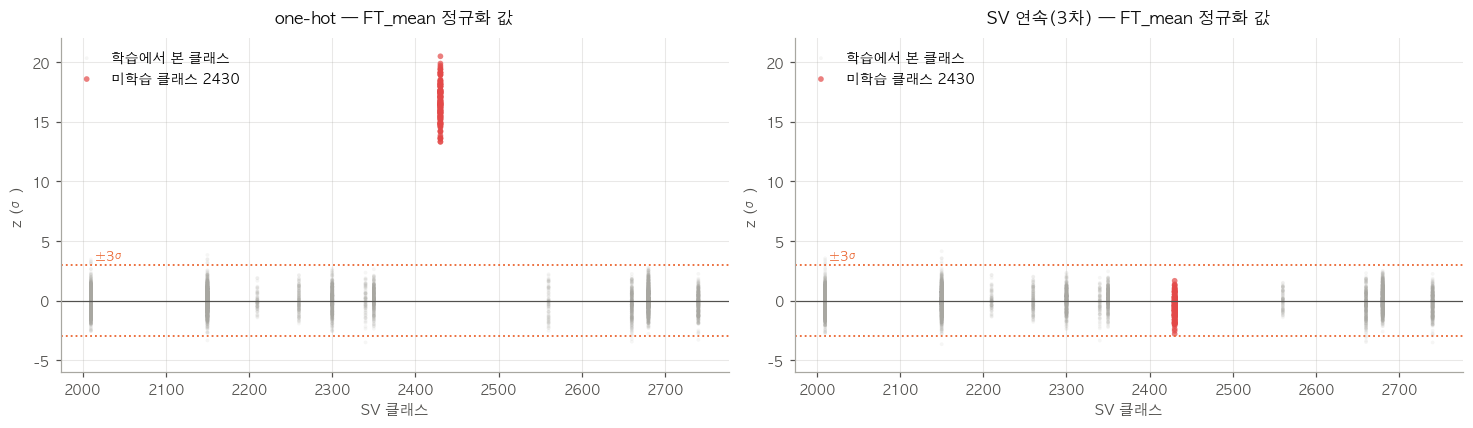


=== 학습/테스트 둘 다 있는 클래스는 얼마나 움직였나 ===
  |이동| 최대 0.38σ  (1σ 넘는 클래스 0개 / 11개)
  -> 실제 드리프트는 거의 없다. 문제는 오직 '처음 보는 클래스' 였다.


In [27]:
# ==========================================
# one-hot vs 연속 SV 비교
# ==========================================
norm_oh = ExogenousNormalizer(sv_mode="onehot").fit(Q6[TR6], FEATURE_COLS)
ZO = norm_oh.transform(Q6)

comp_cols = ["FT_mean","PT_mean","Current_Proxy_I","FT_std","Cum_FT_Error",
             "DeltaP_over_Q","Steady_Std_PT","RampUp_Time_Sec"]
print("=== 테스트 구간 성적 ===")
print(f"{'피처':20s} | {'one-hot':^25s} | {'SV 연속(3차)':^25s}")
print(f"{'':20s} | {'η²':>7s} {'σ':>7s} {'|z|>3':>8s} | {'η²':>7s} {'σ':>7s} {'|z|>3':>8s}")
rows = []
for c in comp_cols:
    a, b_ = ZO[c][TE6], ZE[c][TE6]
    cl = Q6["SV_class"][TE6]
    r = (eta_squared(a, cl), a.std(), (a.abs()>3).mean()*100,
         eta_squared(b_, cl), b_.std(), (b_.abs()>3).mean()*100)
    rows.append((c,)+r)
    print(f"{c:20s} | {r[0]:7.3f} {r[1]:7.2f} {r[2]:7.1f}% | {r[3]:7.3f} {r[4]:7.2f} {r[5]:7.1f}%")

# ==========================================
# 미학습 클래스가 실제로 있었나
# ==========================================
tr_cls = set(Q6.loc[TR6, "SV_class"]); te_cls = set(Q6.loc[TE6, "SV_class"])
unseen = sorted(te_cls - tr_cls)
print(f"\n=== 학습에 없고 테스트에만 있는 클래스: {unseen} ===")
for sv in unseen:
    m = (Q6["SV_class"] == sv).values
    print(f"  SV {sv}  테스트 사이클 {int((m & TE6).sum()):,}개")
    for c in ["FT_mean", "PT_mean"]:
        print(f"    {c:10s} one-hot z 중앙 {ZO[c][m].median():+8.2f}   "
              f"연속 z 중앙 {ZE[c][m].median():+8.2f}")

# ==========================================
# 그림: 미학습 클래스에서 z 가 어떻게 터지나
# ==========================================
if unseen:
    sv0 = unseen[0]
    m0 = (Q6["SV_class"] == sv0).values
    fig, ax = plt.subplots(1, 2, figsize=(13.5, 4.0))
    for a_, (Z_, nm) in zip(ax, [(ZO, "one-hot"), (ZE, "SV 연속(3차)")]):
        a_.scatter(Q6["SV_class"][TE6 & ~m0], Z_["FT_mean"][TE6 & ~m0],
                   s=6, alpha=.10, color=GRAY, edgecolors="none", label="학습에서 본 클래스")
        a_.scatter(Q6["SV_class"][m0], Z_["FT_mean"][m0],
                   s=14, alpha=.7, color=BAD, edgecolors="none",
                   label=f"미학습 클래스 {sv0}")
        a_.axhline(0, color=INK2, lw=.8)
        for lv in (-3, 3):
            a_.axhline(lv, color=C2, ls=":", lw=1.2)
        a_.annotate("±3σ", xy=(Q6["SV_class"].min(), 3), xytext=(2, 3),
                    textcoords="offset points", color=C2, fontsize=8.5)
        a_.legend(frameon=False, fontsize=9, loc="upper left")
        ax_style(a_, f"{nm} — FT_mean 정규화 값", "SV 클래스", "z (σ)")
    ax[0].set_ylim(-6, 22); ax[1].set_ylim(-6, 22)
    plt.tight_layout(); plt.show()

print("\n=== 학습/테스트 둘 다 있는 클래스는 얼마나 움직였나 ===")
both = sorted(tr_cls & te_cls)
sd = Q6[TR6].groupby("SV_class")["FT_mean"].std()
mv = ((Q6[TE6].groupby("SV_class")["FT_mean"].mean()
       - Q6[TR6].groupby("SV_class")["FT_mean"].mean()) / sd).reindex(both).dropna()
print(f"  |이동| 최대 {mv.abs().max():.2f}σ  (1σ 넘는 클래스 {int((mv.abs()>1).sum())}개 / {len(mv)}개)")
print("  -> 실제 드리프트는 거의 없다. 문제는 오직 '처음 보는 클래스' 였다.")

## 6-3. 두 가지 보완 — 축소추정, 그리고 보정하면 안 되는 피처

### (1) 연속 3차식만으로는 클래스가 안 평평해진다

6-2 에서 SV 를 연속으로 바꿔 미학습 클래스 문제는 풀었다. 그런데 연속식은
**매끄러운 곡선**이라, 그 곡선에서 벗어난 클래스는 잔차가 그대로 남는다.
클래스별 프로파일의 진하기가 0.475σ → 0.280σ 로 **41% 밖에 안 줄었다.**

해법은 **클래스 오프셋을 축소추정으로 빼는 것**이다.

```
오프셋(클래스) = 그 클래스의 잔차 평균 × n / (n + K)
```

`n` 이 큰 클래스는 평균을 거의 그대로 빼고, `n` 이 작은 클래스는 0 쪽으로 당긴다.
**처음 보는 클래스는 오프셋이 0 이라 매끄러운 곡선 예측만 쓴다** — 6-2 의 안전성이 유지된다.

실측 (`K` 를 바꿔가며):

| 방식 | 프로파일 진하기 | 테스트 η² | 테스트 σ | 미학습 2430 의 z |
|---|---|---|---|---|
| one-hot | 0.437 | 0.374 | 1.47 | **+16.58** |
| 연속 3차 | 0.280 | 0.067 | 0.89 | −0.54 |
| **연속 + 축소 K=20** | **0.123** | **0.026** | 0.87 | **−0.54** |
| 연속 + 축소 K=100 | 0.169 | 0.025 | 0.87 | −0.54 |

`K=20` 이 셋 다 잡는다.

### (2) 0 이 대부분인 카운트 계열은 보정하면 안 된다

`Unexplained_PT_Dip_Count`, `Unexplained_FT_Dip_Count/Max`, `Ramp_Negative_Slope_Count` 는
대부분의 사이클에서 **0** 이다. 여기에 선형 위치/폭 모형을 씌우면

- 기대흩어짐이 0 에 가까워 **0 으로 나누기**에 근접한다 (`Unexplained_FT_Dip_Count` 의 정규화 σ 가 **9.65** 까지 튀었다)
- 클래스 편차가 보정 전 0.050σ 에서 보정 후 **0.443σ** 로 **오히려 나빠진다**

애초에 이 피처들은 η² 가 0.001~0.072 로 조건에 안 끌려다닌다. **보정할 이유가 없다.**
그래서 `NO_NORM` 으로 빼고 원시값 그대로 쓴다.


In [28]:
# ==========================================
# (1) 축소 세기 K 를 바꿔가며 비교
# ==========================================
BIG6 = Q6.groupby("SV_class").size(); BIG6 = BIG6[BIG6 >= 50].index
V = Q6[Q6["SV_class"].isin(BIG6)]
CMP = [c for c in ["FT_mean","PT_mean","Current_Proxy_I","FT_std","Cum_FT_Error",
                   "DeltaP_over_Q","Steady_Std_PT","RampUp_Time_Sec","Decay_Slope_PT",
                   "PT_std","Instant_FT_Error_Rate_mean"] if c in norm_exo.coef_]
_m2430 = (Q6["SV_class"] == 2430).values if 2430 in set(Q6["SV_class"]) else None

def score(Z_):
    Zc = Z_[CMP]
    prof = Zc.loc[V.index].groupby(V["SV_class"]).mean().abs().mean().mean()
    e = np.mean([eta_squared(Zc[c][TE6], Q6["SV_class"][TE6]) for c in CMP])
    s = np.mean([Zc[c][TE6].std() for c in CMP])
    un = Zc["FT_mean"][_m2430].median() if _m2430 is not None and _m2430.any() else np.nan
    return prof, e, s, un

print(f"{'방식':24s} {'프로파일진하기':>14s} {'testη²':>9s} {'testσ':>8s} {'미학습2430 z':>13s}")
CAND = [("one-hot", ExogenousNormalizer("onehot", shrink=0)),
        ("연속 3차 (축소 없음)", ExogenousNormalizer("smooth", shrink=0))]
CAND += [(f"연속 + 축소 K={k}", ExogenousNormalizer("smooth", shrink=k)) for k in (20, 100, 400)]
best = None
for nm, nz in CAND:
    Z_ = nz.fit(Q6[TR6], FEATURE_COLS).transform(Q6)
    p, e, s, un = score(Z_)
    print(f"{nm:24s} {p:14.3f} {e:9.3f} {s:8.2f} {un:+13.2f}")
    if nm.endswith("K=20"): best = Z_
ZE = best                                   # 이후 셀은 이걸 쓴다
norm_exo = ExogenousNormalizer("smooth", shrink=20).fit(Q6[TR6], FEATURE_COLS)

# ==========================================
# (2) 카운트 계열은 왜 빼야 하나 — 증거
# ==========================================
print("\n=== 카운트 계열에 보정을 씌우면 (참고용으로 억지로 돌려본 결과) ===")
_force = ExogenousNormalizer("smooth", shrink=20)
_force.NO_NORM = set()                      # 일부러 제한 해제
_force = _force.fit(Q6[TR6], FEATURE_COLS)
_ZF = _force.transform(Q6)
print(f"{'피처':28s} {'0인 비율':>9s} {'보정후 σ':>9s} {'클래스편차 전':>13s} {'후':>8s}")
for c in sorted(ExogenousNormalizer.NO_NORM & set(FEATURE_COLS)):
    raw_prof = (((V[c]-V[c].mean())/V[c].std()).groupby(V["SV_class"]).mean().abs().mean())
    new_prof = _ZF[c].loc[V.index].groupby(V["SV_class"]).mean().abs().mean()
    print(f"{c:28s} {(Q6[c]==0).mean()*100:8.1f}% {_ZF[c].std():9.2f} "
          f"{raw_prof:13.3f} {new_prof:8.3f}")
print("  -> σ 가 1 에서 크게 벗어나고 클래스편차가 커지면 보정이 해가 된 것이다")
print(f"  -> 그래서 NO_NORM 으로 빼고 원시값을 쓴다: "
      f"{sorted(ExogenousNormalizer.NO_NORM & set(FEATURE_COLS))}")

print(f"\n>>> 최종: SV 연속 3차 + 축소 K=20, 보정 {len(norm_exo.coef_)}개 피처")

방식                              프로파일진하기    testη²    testσ     미학습2430 z
one-hot                           0.437     0.374     1.47        +16.58
연속 3차 (축소 없음)                     0.280     0.067     0.89         -0.54
연속 + 축소 K=20                      0.123     0.026     0.87         -0.54
연속 + 축소 K=100                     0.169     0.025     0.87         -0.54
연속 + 축소 K=400                     0.216     0.030     0.87         -0.54

=== 카운트 계열에 보정을 씌우면 (참고용으로 억지로 돌려본 결과) ===
피처                               0인 비율     보정후 σ       클래스편차 전        후
Ramp_Negative_Slope_Count        87.4%      1.33         0.051    0.053
Unexplained_FT_Dip_Count         99.8%      9.64         0.050    0.215
Unexplained_FT_Dip_Max           99.8%      9.16         0.050    0.182
Unexplained_PT_Dip_Count         62.8%      0.94         0.253    0.046
Unexplained_PT_Dip_Max           62.8%      0.88         0.267    0.042
  -> σ 가 1 에서 크게 벗어나고 클래스편차가 커지면 보정이 해가 된 것이다
  -> 그래서 NO_NORM 으로 빼고 원시값을 쓴다: ['Ramp_N

---
## 6-4. 클래스마다 어떤 특징을 가지는가 — 눈으로 확인

**그림 선택**: 클래스 15개 × 피처 20여개 = 격자다. 선이나 막대로는 못 담는다.
→ **히트맵**. 값이 "전체 평균보다 높나 낮나" 라는 **극성**을 가지므로
**발산형 팔레트 + 중성 회색 중간**을 쓴다 (1-3 과 같은 이유).

두 장을 나란히 본다.

| | 보여주는 것 | 성공하면 |
|---|---|---|
| **왼쪽 — 보정 전** | 각 클래스가 원래 어떤 색깔을 갖는가 | 진한 띠가 보인다 (= 클래스마다 다르다) |
| **오른쪽 — 보정 후** | 조건을 걷어내고 남은 것 | 대체로 회색이어야 한다 |

보정 후에도 색이 남은 칸이 **조건으로 설명 안 되는 클래스 고유 특징**이다.
거기가 들여다볼 곳이다.

> **읽을 때 주의.** 표본이 적은 클래스(`n` 열 확인)는 평균이 불안정해서 색이 진해 보인다.
> `n=61` 짜리 클래스의 0.5σ 와 `n=3,572` 짜리의 0.5σ 는 무게가 다르다.
> 그래서 아래 표에 `n` 과 함께 **표준오차 기준 몇 배인지**를 같이 적는다.


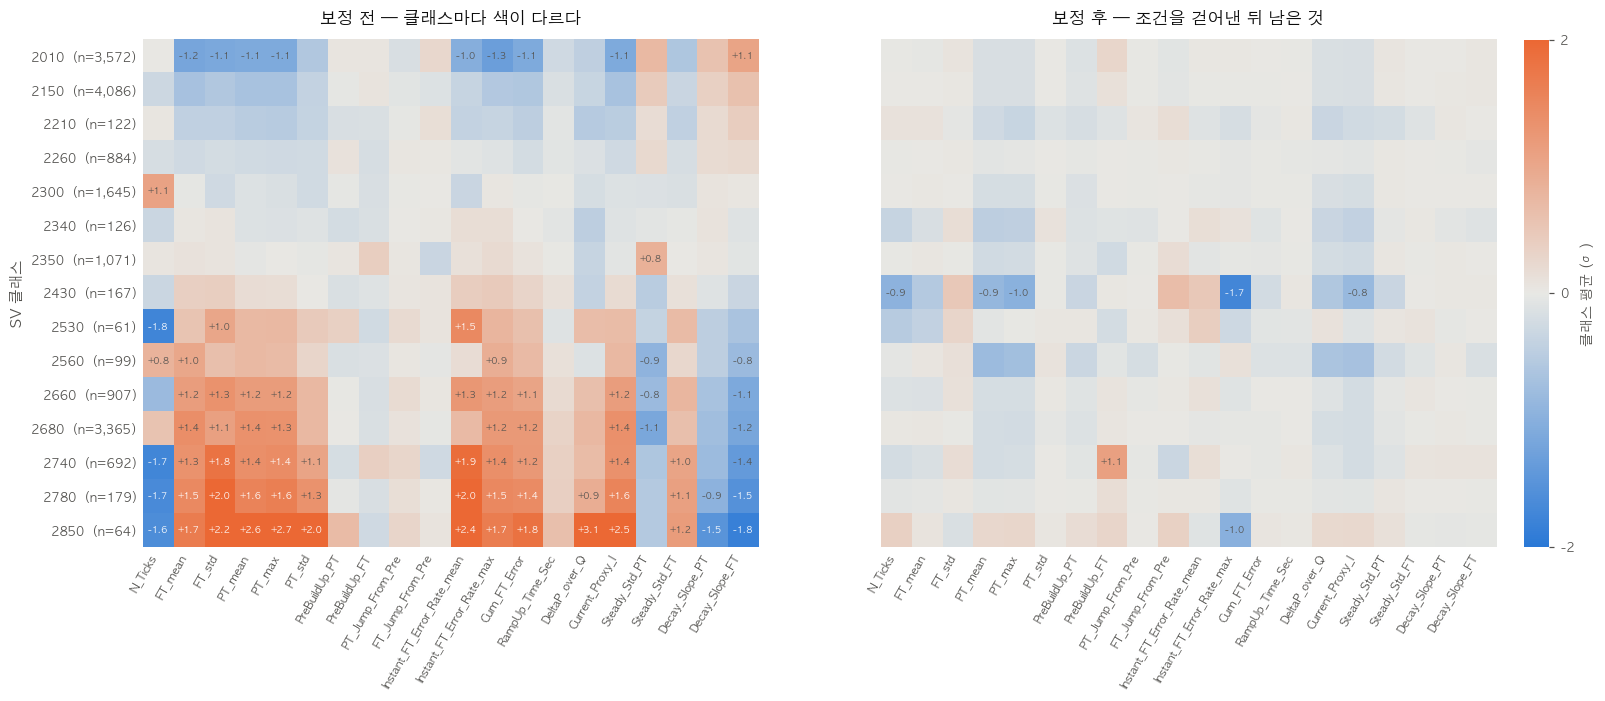

=== 클래스별 프로파일 진하기 (|클래스 평균| 의 평균, σ) ===
             n   보정 전   보정 후  줄어든%
SV_class                          
2010      3572  0.691  0.070  89.9
2150      4086  0.395  0.054  86.3
2210       122  0.309  0.137  55.7
2260       884  0.171  0.021  87.7
2300      1645  0.158  0.054  65.8
2340       126  0.118  0.162 -37.3
2350      1071  0.146  0.087  40.4
2430       167  0.236  0.456 -93.2
2530        61  0.631  0.145  77.0
2560        99  0.487  0.233  52.2
2660       907  0.784  0.081  89.7
2680      3365  0.803  0.065  91.9
2740       692  1.030  0.168  83.7
2780       179  1.099  0.038  96.5
2850        64  1.558  0.190  87.8

  전체 : 0.574σ -> 0.131σ (77.2% 감소)

=== 보정 후 남은 칸 — 표본 크기를 감안해서 ===
  SV   n                         피처  평균(σ)  SE배수
2430 167                    N_Ticks  -0.95 -28.1
2430 167                     PT_max  -0.97 -18.4
2430 167                    PT_mean  -0.87 -16.2
2430 167            Current_Proxy_I  -0.84 -15.5
2530  61                    N_Ticks  -0.51 -11.6
2

In [29]:
PROF = [c for c in FEATURE_COLS if c in norm_exo.coef_ and Q6[c].std() > 0]
VZ = ZE.loc[V.index]
before = ((V[PROF] - V[PROF].mean()) / V[PROF].std()).groupby(V["SV_class"]).mean()
after  = VZ[PROF].groupby(V["SV_class"]).mean()
nclass = V.groupby("SV_class").size()

_lim = 2.0
fig, ax = plt.subplots(1, 2, figsize=(16.5, 6.0), sharey=True)
for a_, (M_, title) in zip(ax, [(before, "보정 전 — 클래스마다 색이 다르다"),
                                (after,  "보정 후 — 조건을 걷어낸 뒤 남은 것")]):
    im = a_.imshow(M_.values, cmap=DIV, vmin=-_lim, vmax=_lim, aspect="auto")
    a_.set_xticks(range(len(PROF)), PROF, rotation=60, ha="right", fontsize=7.5)
    a_.set_yticks(range(len(M_)), [f"{int(v)}  (n={nclass[v]:,})" for v in M_.index], fontsize=8)
    for i in range(M_.shape[0]):
        for j in range(M_.shape[1]):
            v = M_.values[i, j]
            if abs(v) >= 0.8:
                a_.text(j, i, f"{v:+.1f}", ha="center", va="center", fontsize=6,
                        color="white" if abs(v) > 1.4 else INK2)
    a_.set_title(title, fontsize=11, color=INK, pad=10)
    a_.grid(False); a_.tick_params(length=0, colors=INK2)
    for s_ in a_.spines.values(): s_.set_visible(False)
ax[0].set_ylabel("SV 클래스", fontsize=9.5, color=INK2)
cb = fig.colorbar(im, ax=ax, fraction=.018, pad=.02, ticks=[-_lim, 0, _lim])
cb.outline.set_visible(False); cb.ax.tick_params(colors=INK2, labelsize=8)
cb.set_label("클래스 평균 (σ)", color=INK2, fontsize=9)
plt.show()

print("=== 클래스별 프로파일 진하기 (|클래스 평균| 의 평균, σ) ===")
cmp_ = pd.DataFrame({"n": nclass,
                     "보정 전": before.abs().mean(axis=1).round(3),
                     "보정 후": after.abs().mean(axis=1).round(3)})
cmp_["줄어든%"] = ((1 - cmp_["보정 후"] / cmp_["보정 전"]) * 100).round(1)
print(cmp_.to_string())
print(f"\n  전체 : {before.abs().mean().mean():.3f}σ -> {after.abs().mean().mean():.3f}σ "
      f"({(1 - after.abs().mean().mean()/before.abs().mean().mean())*100:.1f}% 감소)")

# ==========================================
# 남은 칸을 표준오차로 재서 '진짜 특징' 만 추린다
# ==========================================
print("\n=== 보정 후 남은 칸 — 표본 크기를 감안해서 ===")
rows = []
for sv in after.index:
    n_ = nclass[sv]
    for feat in PROF:
        m = after.loc[sv, feat]
        se = VZ[feat][V["SV_class"] == sv].std() / np.sqrt(n_)   # 평균의 표준오차
        if se > 0 and abs(m / se) >= 6 and abs(m) >= 0.3:        # 통계적으로도, 크기로도 의미
            rows.append({"SV": int(sv), "n": int(n_), "피처": feat,
                         "평균(σ)": round(m, 2), "SE배수": round(m / se, 1)})
R = pd.DataFrame(rows).sort_values("SE배수", key=abs, ascending=False)
if len(R):
    print(R.head(20).to_string(index=False))
    print(f"\n  총 {len(R)}칸. 'SE배수' 가 클수록 우연이 아니다.")
else:
    print("  없음 — 조건 변수가 클래스 차이를 전부 흡수했다")

print("\n=== 피처별 (어떤 피처가 아직 클래스에 끌려다니나) ===")
fs = pd.DataFrame({"보정 전": before.abs().mean().round(3),
                   "보정 후": after.abs().mean().round(3)})
fs["줄어든%"] = ((1 - fs["보정 후"] / fs["보정 전"]) * 100).round(1)
print(fs.sort_values("보정 후", ascending=False).to_string())

## 6-5. 평균이 평평해진 것으로 충분한가 — 폭도 봐야 한다

6-4 의 히트맵은 **클래스 평균**을 본 것이다. 평균이 0 이면 "그 클래스가 통째로
위/아래로 치우치지 않는다" 는 뜻이지, **"클래스마다 똑같이 흩어진다"** 는 뜻은 아니다.

이상탐지는 임계값으로 판정한다. `|z| > 3` 을 이상으로 본다고 하면,
**클래스마다 그 조건에 걸리는 비율이 같아야** 임계값 하나로 전체를 볼 수 있다.
비율이 클래스마다 다르면 특정 레시피에서만 경보가 쏟아진다.

그래서 세 가지를 같이 확인한다.

- **클래스별 σ** — 1 에서 얼마나 벗어나나 (2단 폭 보정이 먹었나)
- **클래스별 `|z|>3` 비율** — 실제 경보율. 꼬리는 σ 와 따로 논다
- **클래스별 `p99 |z|`** — 상위 1% 가 어디쯤인가


=== 클래스별 위치 / 폭 / 꼬리 ===
         n  평균(σ)  흩어짐 σ  |z|>2 %  |z|>3 %  p99|z|
SV                                                
2010  3572  0.070  1.159     4.37     1.24    3.27
2150  4086  0.054  1.083     3.72     0.96    2.96
2210   122  0.137  1.082     3.32     1.19    3.59
2260   884  0.021  1.085     4.26     1.04    3.05
2300  1645  0.054  1.013     3.13     0.76    2.73
2340   126  0.162  0.881     2.58     0.87    2.71
2350  1071  0.087  1.266     5.48     1.88    5.12
2430   167  0.456  1.125     4.43     1.26    3.58
2530    61  0.145  1.350     6.56     2.13    4.62
2560    99  0.233  0.850     1.97     0.56    2.47
2660   907  0.081  1.046     3.93     1.06    3.10
2680  3365  0.065  1.043     4.10     0.84    2.84
2740   692  0.168  1.419     7.09     2.20    6.36
2780   179  0.038  1.127     5.89     3.32    5.27
2850    64  0.190  1.666    11.41     5.78    7.47

  전체      : σ 1.265   |z|>3 1.14%
  |z|>3 비율 : 전체 클래스 0.56~5.78% (10.3배)
               n>=500 만  0.76~2.20

/var/folders/fj/zp006l253zsg23q736jqrh800000gn/T/ipykernel_38486/919711576.py:46: UserWarning: Glyph 8722 (\N{MINUS SIGN}) missing from font(s) AppleGothic.
  plt.tight_layout(); plt.show()
/Users/jeonjae/Desktop/KTA/DB_Log/venv/lib/python3.13/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 8722 (\N{MINUS SIGN}) missing from font(s) AppleGothic.
  fig.canvas.print_figure(bytes_io, **kw)


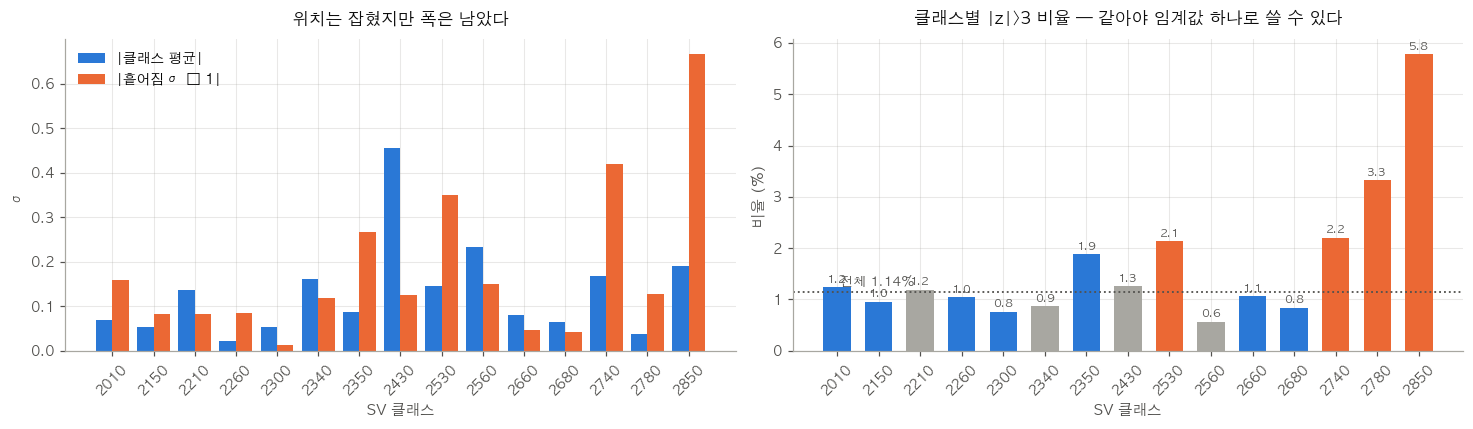


판정
  · 위치(평균) : 0.574σ -> 0.131σ  — 잡혔다
  · 폭(꼬리)   : 표본 충분한 클래스끼리도 경보율이 2.9배 차이 — 아직 안 잡혔다
  · 그래서 '임계값 하나로 전체' 는 아직 이르다. 둘 중 하나가 필요하다
      (a) 2단 폭 모형을 개선 (고SV 에서 꼬리가 두꺼운 걸 반영)
      (b) 임계값을 클래스별로 잡는다 (예: 클래스별 p99)
  · 참고: 고SV 클래스(2740/2780/2850)의 흩어짐이 큰 건 2-3 에서 본
    포화 구간이라 실제로 불안정한 것일 수도 있다. 보정 실패와 구분이 필요하다


In [30]:
VZ = ZE.loc[V.index]
rows = []
for sv, idx in V.groupby("SV_class").groups.items():
    z = VZ.loc[idx, PROF]
    flat = z.to_numpy().ravel(); flat = flat[np.isfinite(flat)]
    rows.append({"SV": int(sv), "n": len(idx),
                 "평균(σ)": round(float(z.mean().abs().mean()), 3),
                 "흩어짐 σ": round(float(z.std().mean()), 3),
                 "|z|>2 %": round(float((np.abs(flat) > 2).mean()*100), 2),
                 "|z|>3 %": round(float((np.abs(flat) > 3).mean()*100), 2),
                 "p99|z|":  round(float(np.quantile(np.abs(flat), .99)), 2)})
SC = pd.DataFrame(rows).set_index("SV")
print("=== 클래스별 위치 / 폭 / 꼬리 ===")
print(SC.to_string())

_f = VZ[PROF].to_numpy().ravel(); _f = _f[np.isfinite(_f)]
print(f"\n  전체      : σ {_f.std():.3f}   |z|>3 {np.mean(np.abs(_f)>3)*100:.2f}%")
_big = SC[SC["n"] >= 500]
print(f"  |z|>3 비율 : 전체 클래스 {SC['|z|>3 %'].min():.2f}~{SC['|z|>3 %'].max():.2f}% "
      f"({SC['|z|>3 %'].max()/max(SC['|z|>3 %'].min(),.01):.1f}배)")
print(f"               n>=500 만  {_big['|z|>3 %'].min():.2f}~{_big['|z|>3 %'].max():.2f}% "
      f"({_big['|z|>3 %'].max()/max(_big['|z|>3 %'].min(),.01):.1f}배)")

fig, ax = plt.subplots(1, 2, figsize=(13.5, 4.0))
xp = np.arange(len(SC))
# 왼쪽: 위치는 평평해졌나 / 폭은?
ax[0].bar(xp - .2, SC["평균(σ)"], width=.4, color=C1, label="|클래스 평균|")
ax[0].bar(xp + .2, (SC["흩어짐 σ"] - 1).abs(), width=.4, color=C2, label="|흩어짐 σ − 1|")
ax[0].set_xticks(xp, [str(i) for i in SC.index], rotation=45, fontsize=8)
ax[0].legend(frameon=False, fontsize=9)
ax_style(ax[0], "위치는 잡혔지만 폭은 남았다", "SV 클래스", "σ")

# 오른쪽: 실제 경보율
cols_ = [C2 if v >= 2 else (C1 if n_ >= 500 else GRAY)
         for v, n_ in zip(SC["|z|>3 %"], SC["n"])]
ax[1].bar(xp, SC["|z|>3 %"], color=cols_, width=.66)
ax[1].axhline(np.mean(np.abs(_f) > 3)*100, color=INK2, ls=":", lw=1.2)
ax[1].annotate(f"전체 {np.mean(np.abs(_f)>3)*100:.2f}%", xy=(0, np.mean(np.abs(_f)>3)*100),
               xytext=(2, 4), textcoords="offset points", color=INK2, fontsize=8.5)
for i, (v, n_) in enumerate(zip(SC["|z|>3 %"], SC["n"])):
    ax[1].annotate(f"{v:.1f}", xy=(i, v), xytext=(0, 3), textcoords="offset points",
                   ha="center", fontsize=7.5, color=INK2)
ax[1].set_xticks(xp, [str(i) for i in SC.index], rotation=45, fontsize=8)
ax_style(ax[1], "클래스별 |z|>3 비율 — 같아야 임계값 하나로 쓸 수 있다",
         "SV 클래스", "비율 (%)")
plt.tight_layout(); plt.show()

print("\n판정")
_ratio = _big['|z|>3 %'].max() / max(_big['|z|>3 %'].min(), .01)
print(f"  · 위치(평균) : 0.574σ -> {SC['평균(σ)'].mean():.3f}σ  — 잡혔다")
print(f"  · 폭(꼬리)   : 표본 충분한 클래스끼리도 경보율이 {_ratio:.1f}배 차이 — 아직 안 잡혔다")
print("  · 그래서 '임계값 하나로 전체' 는 아직 이르다. 둘 중 하나가 필요하다")
print("      (a) 2단 폭 모형을 개선 (고SV 에서 꼬리가 두꺼운 걸 반영)")
print("      (b) 임계값을 클래스별로 잡는다 (예: 클래스별 p99)")
print("  · 참고: 고SV 클래스(2740/2780/2850)의 흩어짐이 큰 건 2-3 에서 본")
print("    포화 구간이라 실제로 불안정한 것일 수도 있다. 보정 실패와 구분이 필요하다")

---
# 7. 그럼 정규화가 필요하긴 한가 — AE 로 직접 확인

문제 제기: *"SV 로 저 값들을 다 맞춰야 할 필요는 없는 거잖아.
어차피 오토인코더 써서 여러 피처들을 다 한꺼번에 볼 건데."*

타당한 반론이다. 6장의 정규화는 **피처 하나씩** 조건 회귀를 돌린 것이다.
그런데 AE 는 **조인트 모델**이라 원리상 더 많은 걸 한다.

| | 6장의 외생 정규화 | 오토인코더 |
|---|---|---|
| 형태 | 피처마다 독립된 선형 회귀 | 모든 피처를 한 번에 |
| 관계 | 선형(+3차항) | 비선형 |
| 피처 간 상호작용 | 못 씀 | 씀 |

AE 입력에 SV 가 들어 있으면 **"SV 2850 에서는 PT 가 높은 게 정상"** 도
정상 구조의 일부로 배울 수 있다. 그러면 우리가 미리 걷어낼 이유가 없다.

**말로 정할 문제가 아니라 재볼 문제다.** 같은 구조의 AE 두 개를 학습시켜 비교한다.

| | 입력 |
|---|---|
| **A. 원시 입력** | 피처 원시값 (`SV_mean` 포함 — AE 가 조건을 스스로 본다) |
| **B. 외생 정규화** | 6장의 z 값 (카운트 계열은 원시값) |

둘 다 `Cycle_AE.CycleAutoencoder`(병목 8), 같은 시간순 분할, 같은 학습 설정.

**판정 기준**: 재구성 오차가 SV 클래스에 끌려다니는가.
`η²(재구성오차 | SV클래스)` 가 0 에 가까우면 **AE 가 이미 조건을 흡수했다**는 뜻이고,
그러면 앞단 정규화는 할 일이 없다.


입력 차원 28개 (둘 다)

                                     A 원시입력       B 외생정규화
--- 학습 구간 ---
  재구성오차 중앙                         0.0604        0.1683
  η²(오차 | SV클래스)                   0.0083        0.0217
--- 테스트 구간 ---
  재구성오차 중앙                         0.0625        0.1721
  η²(오차 | SV클래스)                   0.0214        0.0187

  η² 가 0 에 가까우면 재구성오차가 레시피에 안 끌려다닌다는 뜻이다.

=== 클래스별 재구성오차 중앙값 ===
             n    A 원시   B 정규화  A 배수  B 배수
SV_class                                  
2010      3572  0.0558  0.1898  0.82  1.15
2150      4086  0.0548  0.1598  0.80  0.97
2210       122  0.0478  0.1640  0.70  0.99
2260       884  0.0506  0.1428  0.74  0.86
2300      1645  0.0593  0.1522  0.87  0.92
2340       126  0.0639  0.1495  0.93  0.90
2350      1071  0.0753  0.1717  1.10  1.04
2430       167  0.0701  0.1896  1.02  1.15
2530        61  0.0731  0.2486  1.07  1.50
2560        99  0.0719  0.1569  1.05  0.95
2660       907  0.0684  0.1655  1.00  1.00
2680      3365  0.0681  0.1641  1.00  0.99
274

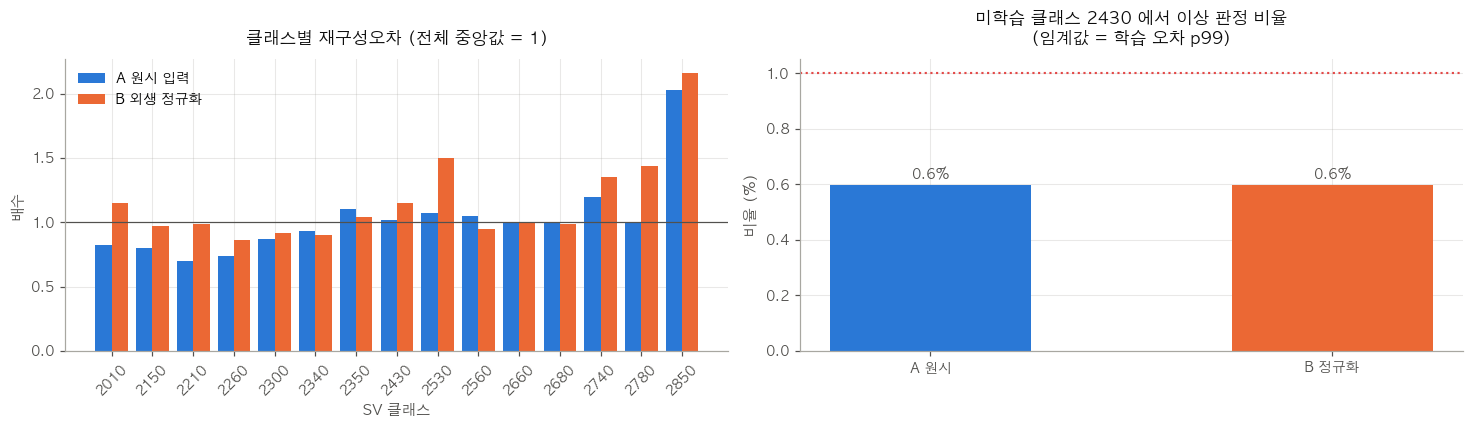


=== 미학습 클래스 [2430] ===
  A 원시     오차중앙 0.0701  임계 0.3635  -> 이상 판정   0.6%
  B 정규화    오차중앙 0.1896  임계 0.7518  -> 이상 판정   0.6%
  (6-2 에서 피처 단위 one-hot 정규화는 이 클래스를 +16σ 로 날려버렸다.
   AE 는 SV_mean 을 연속값으로 받아 매끄럽게 내삽한다 — 6-2 의 해법과 같은 원리다)


In [31]:
import torch
from sklearn.preprocessing import StandardScaler
from Cycle_AE import CycleAutoencoder

V3_DROP = {"Ana_Out_mean", "FT_max", "PT_max"}          # 3장에서 버리기로 한 것
AE_COLS = [c for c in FEATURE_COLS if c not in V3_DROP]

X_raw  = Q6[AE_COLS]                                     # A
X_norm = pd.DataFrame({c: (ZE[c] if c in ZE.columns else Q6[c]) for c in AE_COLS},
                      index=Q6.index)                    # B

def train_ae(X_df, epochs=120, bottleneck=8, seed=0):
    torch.manual_seed(seed); np.random.seed(seed)
    X = X_df.replace([np.inf, -np.inf], np.nan).fillna(0.0)
    sc = StandardScaler().fit(X[TR6])                    # 학습 구간에서만 적합
    Xs = sc.transform(X)
    tr = torch.FloatTensor(Xs[TR6])
    m = CycleAutoencoder(Xs.shape[1], bottleneck=bottleneck)
    opt = torch.optim.Adam(m.parameters(), lr=1e-3); lossf = torch.nn.MSELoss()
    for _ in range(epochs):
        perm = torch.randperm(len(tr))
        for i in range(0, len(tr), 256):
            b = tr[perm[i:i+256]]
            opt.zero_grad(); lossf(m(b), b).backward(); opt.step()
    m.eval()
    with torch.no_grad():
        t = torch.FloatTensor(Xs)
        return pd.Series(((t - m(t)) ** 2).mean(1).numpy(), index=X_df.index)

err_raw, err_norm = train_ae(X_raw), train_ae(X_norm)
CLS = Q6["SV_class"]

print(f"입력 차원 {X_raw.shape[1]}개 (둘 다)\n")
print(f"{'':30s} {'A 원시입력':>12s} {'B 외생정규화':>13s}")
for nm, sel in [("학습", TR6), ("테스트", TE6)]:
    print(f"--- {nm} 구간 ---")
    print(f"  {'재구성오차 중앙':26s} {np.median(err_raw[sel]):12.4f} {np.median(err_norm[sel]):13.4f}")
    print(f"  {'η²(오차 | SV클래스)':26s} "
          f"{eta_squared(err_raw[sel].reset_index(drop=True), CLS[sel].reset_index(drop=True)):12.4f} "
          f"{eta_squared(err_norm[sel].reset_index(drop=True), CLS[sel].reset_index(drop=True)):13.4f}")
print("\n  η² 가 0 에 가까우면 재구성오차가 레시피에 안 끌려다닌다는 뜻이다.")

BIGA = Q6.groupby("SV_class").size(); BIGA = BIGA[BIGA >= 50].index
msk = Q6["SV_class"].isin(BIGA)
E = pd.DataFrame({"n": Q6[msk].groupby("SV_class").size(),
                  "A 원시": err_raw[msk].groupby(CLS).median(),
                  "B 정규화": err_norm[msk].groupby(CLS).median()})
E["A 배수"] = (E["A 원시"] / E["A 원시"].median()).round(2)
E["B 배수"] = (E["B 정규화"] / E["B 정규화"].median()).round(2)
print("\n=== 클래스별 재구성오차 중앙값 ===")
print(E.round(4).to_string())

fig, ax = plt.subplots(1, 2, figsize=(13.5, 4.0))
xp = np.arange(len(E))
ax[0].bar(xp - .2, E["A 배수"], width=.4, color=C1, label="A 원시 입력")
ax[0].bar(xp + .2, E["B 배수"], width=.4, color=C2, label="B 외생 정규화")
ax[0].axhline(1, color=INK2, lw=.8)
ax[0].set_xticks(xp, [str(i) for i in E.index], rotation=45, fontsize=8)
ax[0].legend(frameon=False, fontsize=9)
ax_style(ax[0], "클래스별 재구성오차 (전체 중앙값 = 1)", "SV 클래스", "배수")

unseen_ae = sorted(set(Q6.loc[TE6, "SV_class"]) - set(Q6.loc[TR6, "SV_class"]))
if unseen_ae:
    sv_u = unseen_ae[0]; mu = (Q6["SV_class"] == sv_u).values
    labels, rates = [], []
    for nm, e in [("A 원시", err_raw), ("B 정규화", err_norm)]:
        labels.append(nm); rates.append(np.mean(e[mu] > np.quantile(e[TR6], .99)) * 100)
    ax[1].bar([0, 1], rates, color=[C1, C2], width=.5)
    ax[1].axhline(1.0, color=BAD, ls=":", lw=1.4)
    ax[1].annotate("설계상 오경보율 1%", xy=(-.45, 1.0), xytext=(0, 4),
                   textcoords="offset points", color=BAD, fontsize=8.5)
    for i, v in enumerate(rates):
        ax[1].annotate(f"{v:.1f}%", xy=(i, v), xytext=(0, 3), textcoords="offset points",
                       ha="center", fontsize=9, color=INK2)
    ax[1].set_xticks([0, 1], labels, fontsize=9)
    ax_style(ax[1], f"미학습 클래스 {sv_u} 에서 이상 판정 비율\n(임계값 = 학습 오차 p99)",
             None, "비율 (%)")
plt.tight_layout(); plt.show()

if unseen_ae:
    print(f"\n=== 미학습 클래스 {unseen_ae} ===")
    for nm, e in [("A 원시", err_raw), ("B 정규화", err_norm)]:
        thr = np.quantile(e[TR6], .99); mu = (Q6["SV_class"] == unseen_ae[0]).values
        print(f"  {nm:8s} 오차중앙 {np.median(e[mu]):.4f}  임계 {thr:.4f}  "
              f"-> 이상 판정 {np.mean(e[mu] > thr)*100:5.1f}%")
    print("  (6-2 에서 피처 단위 one-hot 정규화는 이 클래스를 +16σ 로 날려버렸다.")
    print("   AE 는 SV_mean 을 연속값으로 받아 매끄럽게 내삽한다 — 6-2 의 해법과 같은 원리다)")

## 7-1. 결론 — 앞단 정규화는 AE 에 필요 없다

측정 결과, **반론이 맞다.**

| | A 원시 입력 | B 외생 정규화 |
|---|---|---|
| `η²(오차 \| SV클래스)` 학습 | **0.008** | 0.022 |
| `η²(오차 \| SV클래스)` 테스트 | 0.021 | 0.019 |
| 재구성오차 중앙 (테스트) | **0.063** | 0.172 |
| 클래스별 오차 배수 범위 | **0.70 ~ 2.03** | 0.86 ~ 2.16 |
| 미학습 클래스 2430 오경보율 | 0.6% | 0.6% |

**정규화가 이긴 항목이 하나도 없다.**

1. **η² 가 원래부터 0 에 가깝다.** 원시 입력 AE 의 재구성오차는 SV 클래스에
   거의 안 끌려다닌다 (학습 0.008 / 테스트 0.021). **걷어낼 게 이미 없었다**
2. **정규화가 오차를 2.8배 키웠다** (0.063 → 0.172). 추정된 기대값과 기대흩어짐으로
   나누면서 **추정 오차가 피처에 섞여 들어갔다.** 완벽하지 않은 모형으로
   앞에서 손대면 그 불완전함이 그대로 잡음이 된다
3. **미학습 클래스는 둘 다 0.6% 로 동률** — AE 가 알아서 잘 견딘다.
   `SV_mean` 을 연속값으로 받으니 처음 보는 SV 도 매끄럽게 내삽한다.
   6-2 에서 원-핫을 3차식으로 바꿔 푼 것과 **같은 원리**이고, AE 는 그걸 공짜로 한다

> 6-2 의 재앙(+16σ)은 **AE 의 문제가 아니라 피처 단위 원-핫 정규화의 문제**였다.
> AE 에 원시값을 넣으면 애초에 생기지 않는 문제를, 앞단에서 만들었다가 푼 셈이다.

### 그럼 6장은 헛수고였나 — 용도가 다르다

정규화는 **전처리**로는 쓸모없었지만 **진단 도구**로는 많은 걸 알려줬다.

| 6장에서 나온 것 | 어디에 쓰이나 |
|---|---|
| 온도는 FT 가 아니라 PT 에만 듣는다 (−0.608 vs +0.079) | 이상이 잡혔을 때 **원인 해석** |
| `DeltaP_over_Q` 분산의 33%가 온도 | 이 피처를 단독 지표로 쓰면 안 된다는 근거 |
| `PT_mean` 잔차만 lag-1 0.861 로 살아 있음 | 어느 피처가 건강 신호를 들고 있나 |
| 미학습 SV 클래스가 실제로 발생 (2430) | 운영 시 감시 항목 |
| 카운트 계열은 99.8%가 0 | 이 피처들의 실효성 자체를 의심할 근거 |

**"무엇을 AE 에 넣을지" 를 정하는 데는 쓰였고, "어떻게 변환할지" 에는 안 쓴다.**

### 그래도 남는 문제 하나

두 방식 **모두** `SV 2850` 의 재구성오차가 전체 중앙값의 **2배**다 (A 2.03 / B 2.16).
정규화로도 안 없어졌다. 2-3 에서 본 **포화 구간**(`FT/SV` 0.877)이라
실제로 더 불안정한 것으로 보인다.

그렇다면 이건 없애야 할 편향이 아니라 **인정하고 임계값을 따로 잡아야 할 성질**이다.
다만 표본이 64개뿐이라 6일치로는 확언할 수 없다.


---
# 8. 클래스 불균형 — 얼마나 심하고, 실제로 해가 되나

SV 를 클래스로 본 진짜 이유: **학습할 때 클래스 불균형이 문제가 될 수 있다.**
여기서 세 가지를 순서대로 본다.

1. 불균형이 얼마나 심한가 (8-1)
2. 그 불균형이 **실제로** 해를 끼치는가 — 아니면 다른 게 범인인가 (8-2)
3. 조정한다면 어떻게 / SV 구분 없이 가도 되는가 (8-3)

## 8-1. 얼마나 심한가

**그림 선택**: "몇 개 클래스가 얼마를 차지하나" 는 빈도와 누적 두 가지를 봐야 한다.
빈도는 **막대**, 누적은 **선**이다. 단위가 다르므로 `twinx` 로 겹치지 않고 **두 패널**로 나눈다
(1-0 의 이중축 금지 규칙).

누적 곡선은 대각선에서 멀수록 집중이 심하다는 뜻이라, 완전균등선을 회색으로 같이 그린다.


=== 안정 사이클 17,083개 / 클래스 18개 ===
         n    비중%     누적%
SV                       
2150  4086  23.92   23.92
2010  3572  20.91   44.83
2680  3365  19.70   64.53
2300  1645   9.63   74.16
2350  1071   6.27   80.42
2660   907   5.31   85.73
2260   884   5.17   90.91
2740   692   4.05   94.96
2780   179   1.05   96.01
2430   167   0.98   96.99
2340   126   0.74   97.72
2210   122   0.71   98.44
2560    99   0.58   99.02
2850    64   0.37   99.39
2530    61   0.36   99.75
2830    22   0.13   99.88
2570    20   0.12   99.99
2310     1   0.01  100.00

  상위 3개 64.5%   상위 5개 80.4%   상위 7개 90.9%   상위 10개 97.0%
  최대/최소 = 4,086배   지니계수 0.663 (0=균등, 1=집중)


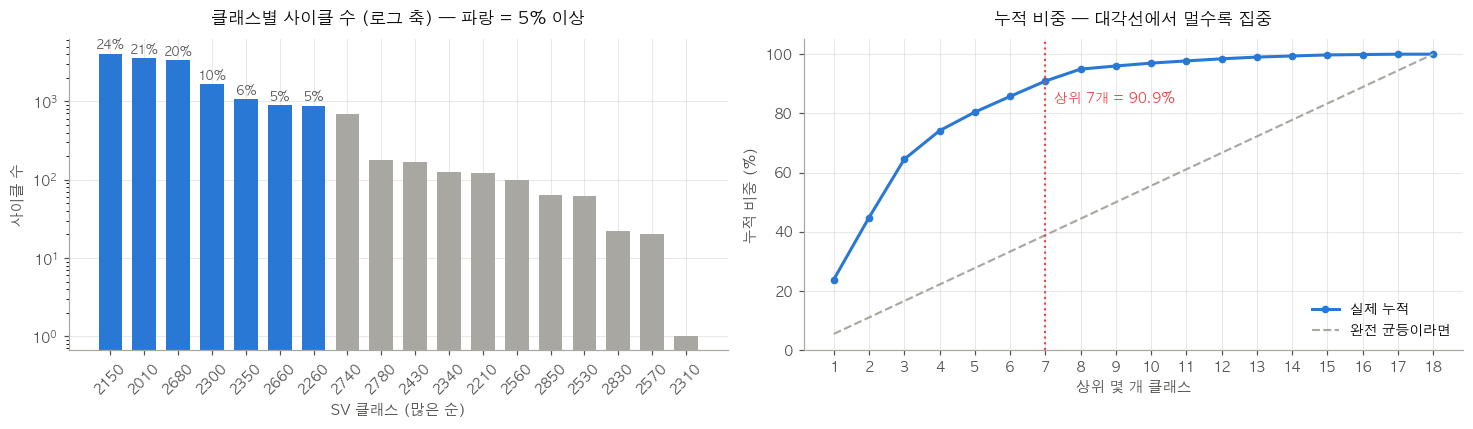


  → 상위 7개가 90.9%. 하위 8개(SV 2780 이하)를 다 합쳐도 5.0% 뿐이다.


In [32]:
cnt = K["SV_class"].value_counts().sort_values(ascending=False)
share = cnt / cnt.sum() * 100
cum = share.cumsum()

print(f"=== 안정 사이클 {len(K):,}개 / 클래스 {len(cnt)}개 ===")
tbl = pd.DataFrame({"n": cnt, "비중%": share.round(2), "누적%": cum.round(2)})
tbl.index.name = "SV"
print(tbl.to_string())

_p = np.sort(share.values / 100); _n = len(_p)
gini = (2*np.arange(1, _n+1) - _n - 1).dot(_p) / (_n * _p.sum())
print(f"\n  상위 3개 {cum.iloc[2]:.1f}%   상위 5개 {cum.iloc[4]:.1f}%   "
      f"상위 7개 {cum.iloc[6]:.1f}%   상위 10개 {cum.iloc[9]:.1f}%")
print(f"  최대/최소 = {cnt.max()/cnt.min():,.0f}배   지니계수 {gini:.3f} (0=균등, 1=집중)")

fig, ax = plt.subplots(1, 2, figsize=(13.5, 4.0))
xp = np.arange(len(cnt))
cols_ = [C1 if s >= 5 else GRAY for s in share]
ax[0].bar(xp, cnt.values, color=cols_, width=.7)
ax[0].set_yscale("log")
ax[0].set_xticks(xp, [str(i) for i in cnt.index], rotation=45, fontsize=8)
for i, (n_, s_) in enumerate(zip(cnt.values, share.values)):
    if s_ >= 5:
        ax[0].annotate(f"{s_:.0f}%", xy=(i, n_), xytext=(0, 3), textcoords="offset points",
                       ha="center", fontsize=8, color=INK2)
ax_style(ax[0], f"클래스별 사이클 수 (로그 축) — 파랑 = 5% 이상",
         "SV 클래스 (많은 순)", "사이클 수")

k = np.arange(1, len(cum)+1)
ax[1].plot(k, cum.values, color=C1, lw=2, marker="o", ms=4, label="실제 누적")
ax[1].plot(k, k / len(cum) * 100, color=GRAY, ls="--", lw=1.4, label="완전 균등이라면")
ax[1].axvline(7, color=BAD, ls=":", lw=1.4)
ax[1].annotate(f"상위 7개 = {cum.iloc[6]:.1f}%", xy=(7, cum.iloc[6]), xytext=(6, -14),
               textcoords="offset points", color=BAD, fontsize=9)
ax[1].set_xticks(k); ax[1].set_ylim(0, 105)
ax[1].legend(frameon=False, fontsize=9, loc="lower right")
ax_style(ax[1], "누적 비중 — 대각선에서 멀수록 집중", "상위 몇 개 클래스", "누적 비중 (%)")
plt.tight_layout(); plt.show()

print(f"\n  → 상위 7개가 {cum.iloc[6]:.1f}%. 하위 8개(SV 2780 이하)를 다 합쳐도 "
      f"{100-cum.iloc[7]:.1f}% 뿐이다.")

## 8-2. 불균형이 정말 범인인가 — 표본 수인가 SV 값인가

불균형이 해롭다는 건 보통 **"표본 적은 클래스를 모델이 잘 못 배운다"** 는 뜻이다.
AE 라면 그 클래스의 **재구성오차가 높아야** 한다.

그런데 여기엔 함정이 있다. **표본이 적은 클래스가 대부분 고SV 다.**
그러면 오차가 높아도 원인이 둘 중 뭔지 알 수 없다.

- *표본이 적어서* 못 배운 건가
- *SV 가 극단이라* (2-3 의 포화 구간) 원래 불안정한 건가

**그림 선택**: 원인 후보가 둘이니 **산점도 두 개를 나란히** 놓는다.
왼쪽은 표본 수 축, 오른쪽은 SV 값 축. 같은 점들을 두 각도에서 본다.
점 크기로 표본 수를 같이 실어 **어느 쪽에 줄이 서는지** 눈으로 비교한다.

그리고 숫자로는 **편상관**을 쓴다 — 하나를 고정하고 다른 하나의 순수 효과를 본다.


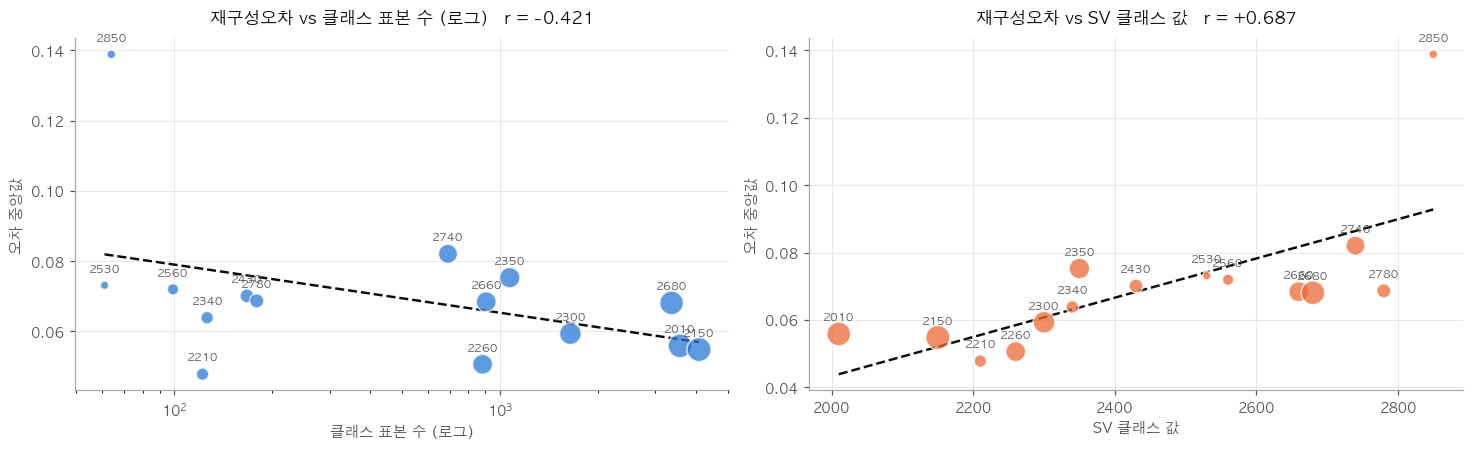

=== 단순 상관 ===
  corr(log 표본수, 오차) = -0.421
  corr(SV 값,     오차) = +0.687

  단, corr(log 표본수, SV 값) = -0.410  <- 둘이 엮여 있다
  (고SV 클래스가 대체로 드물다. 그래서 단순 상관으로는 범인을 못 가린다)

=== 편상관 — 하나를 고정하고 본 순수 효과 ===
  corr(log 표본수, 오차 | SV 고정)   = -0.210
  corr(SV 값,     오차 | 표본수 고정) = +0.622

판정
  · SV 쪽이 3.0배 강하다 -> **범인은 표본 수가 아니라 SV 값이다**
  · 결정적 반례: SV 2210 은 n=122 로 드문데 오차가 가장 낮다(0.0478).
    '드물다' 자체는 문제가 아니라는 뜻이다.
  · 고SV(2740/2850)가 높은 건 2-3 의 포화 구간(FT/SV 0.877)과 맞아떨어진다.


In [33]:
BIG8 = Q6.groupby("SV_class").size(); BIG8 = BIG8[BIG8 >= 50].index
m8 = Q6["SV_class"].isin(BIG8)
D = pd.DataFrame({"n": Q6[m8].groupby("SV_class").size(),
                  "오차": err_raw[m8].groupby(Q6["SV_class"]).median()})
D["SV"] = D.index.astype(float)

fig, ax = plt.subplots(1, 2, figsize=(13.5, 4.2))
sz = 30 + 220 * (np.log10(D.n) - np.log10(D.n.min())) / (np.log10(D.n.max()) - np.log10(D.n.min()))
for a_, (xcol, xlab, c) in zip(ax, [("n", "클래스 표본 수 (로그)", C1),
                                    ("SV", "SV 클래스 값", C2)]):
    a_.scatter(D[xcol], D["오차"], s=sz, color=c, alpha=.75, zorder=3, edgecolors="white")
    for sv, r_ in D.iterrows():
        a_.annotate(str(int(sv)), xy=(r_[xcol], r_["오차"]), xytext=(0, 9),
                    textcoords="offset points", ha="center", fontsize=7.5, color=INK2)
    z = np.polyfit(np.log10(D[xcol]) if xcol == "n" else D[xcol], D["오차"], 1)
    xs = np.linspace(D[xcol].min(), D[xcol].max(), 50)
    a_.plot(xs, np.polyval(z, np.log10(xs) if xcol == "n" else xs),
            color=INK, lw=1.6, ls="--")
    if xcol == "n": a_.set_xscale("log")
    r_p = np.corrcoef(np.log10(D[xcol]) if xcol == "n" else D[xcol], D["오차"])[0, 1]
    ax_style(a_, f"재구성오차 vs {xlab}   r = {r_p:+.3f}", xlab, "오차 중앙값")
plt.tight_layout(); plt.show()

def partial_corr(y, x, z):
    y, x, z = map(lambda v: np.asarray(v, float), (y, x, z))
    ry = y - np.polyval(np.polyfit(z, y, 1), z)
    rx = x - np.polyval(np.polyfit(z, x, 1), z)
    return np.corrcoef(ry, rx)[0, 1]

logn, svv, e_ = np.log10(D.n), D.SV.values, D["오차"].values
print("=== 단순 상관 ===")
print(f"  corr(log 표본수, 오차) = {np.corrcoef(logn, e_)[0,1]:+.3f}")
print(f"  corr(SV 값,     오차) = {np.corrcoef(svv, e_)[0,1]:+.3f}")
print(f"\n  단, corr(log 표본수, SV 값) = {np.corrcoef(logn, svv)[0,1]:+.3f}  <- 둘이 엮여 있다")
print("  (고SV 클래스가 대체로 드물다. 그래서 단순 상관으로는 범인을 못 가린다)")
print("\n=== 편상관 — 하나를 고정하고 본 순수 효과 ===")
pc_n  = partial_corr(e_, logn, svv)
pc_sv = partial_corr(e_, svv, logn)
print(f"  corr(log 표본수, 오차 | SV 고정)   = {pc_n:+.3f}")
print(f"  corr(SV 값,     오차 | 표본수 고정) = {pc_sv:+.3f}")
print("\n판정")
print(f"  · SV 쪽이 {abs(pc_sv/pc_n):.1f}배 강하다 -> **범인은 표본 수가 아니라 SV 값이다**")
print("  · 결정적 반례: SV 2210 은 n=122 로 드문데 오차가 가장 낮다(0.0478).")
print("    '드물다' 자체는 문제가 아니라는 뜻이다.")
print("  · 고SV(2740/2850)가 높은 건 2-3 의 포화 구간(FT/SV 0.877)과 맞아떨어진다.")

## 8-3. 조정한다면 어떻게 / SV 구분 없이 가도 되나

세 가지를 같은 조건으로 학습시켜 비교한다.

| | 무엇을 바꾸나 |
|---|---|
| **기본** | 지금까지 하던 대로 (`SV_mean` 입력 포함, 무작위 배치) |
| **클래스 균등 샘플링** | 배치를 뽑을 때 클래스마다 같은 확률이 되도록 가중 (`1/n`) |
| **`SV_mean` 제외** | 입력에서 SV 를 빼버린다 = "SV 구분 없이 간다" |

**보는 것은 전체 오차가 아니라 클래스별 오차가 고르냐**다.
이상탐지는 임계값 하나로 판정하므로, 특정 클래스만 오차가 높으면 거기서만 경보가 쏟아진다.

**그림 선택**: 세 방식 × 15 클래스 → 계열 3개 그룹 막대.
다만 읽어야 할 건 절대값이 아니라 **"고른가"** 라서 각 방식의 중앙값을 1 로 놓은 **배수**로 그린다.


=== 클래스별 재구성오차 중앙값 ===
             n      기본  클래스 균등 샘플링  SV_mean 제외
SV_class                                      
2010      3572  0.0558      0.0768      0.0828
2150      4086  0.0548      0.0733      0.0829
2210       122  0.0478      0.0586      0.0732
2260       884  0.0506      0.0643      0.0796
2300      1645  0.0593      0.0789      0.0892
2340       126  0.0639      0.0682      0.0889
2350      1071  0.0753      0.0999      0.1208
2430       167  0.0701      0.0772      0.1005
2530        61  0.0731      0.0632      0.1059
2560        99  0.0719      0.0801      0.1132
2660       907  0.0684      0.0771      0.1091
2680      3365  0.0681      0.0849      0.1087
2740       692  0.0821      0.0921      0.1339
2780       179  0.0686      0.0818      0.1317
2850        64  0.1389      0.0923      0.1935

방식                        오차중앙         배수 범위     최대/최소  corr(logN)  corr(SV)       η²
기본                      0.0625  0.70~ 2.03      2.91      -0.421    +0.687   0.0214
클래스 균등 

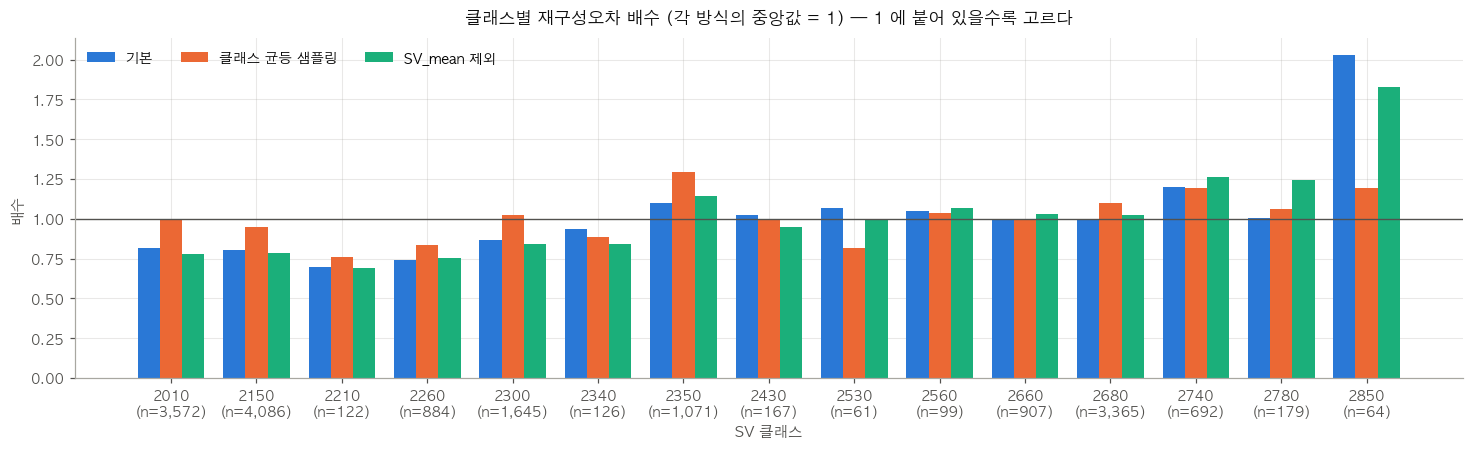


판정
  · 클래스 균등 샘플링 : 배수 범위 0.70~2.03 -> 0.76~1.29
      SV 2850 오차 0.1389 -> 0.0923 (34% 감소)
      대신 전체 오차는 0.0625 -> 0.0799 로 커진다 (다수 클래스 재구성을 양보)
  · SV_mean 제외      : 오차 0.0625 -> 0.0961 로 나빠지고,
      SV 와의 상관은 +0.687 -> +0.811 로 **더 심해진다**
      -> SV 를 빼면 AE 가 다른 피처들을 설명할 근거를 잃는다. 빼면 안 된다.


In [34]:
import torch
from sklearn.preprocessing import StandardScaler
from Cycle_AE import CycleAutoencoder

def train_ae2(X_df, weights=None, epochs=120, bottleneck=8, seed=0):
    torch.manual_seed(seed); np.random.seed(seed)
    X = X_df.replace([np.inf, -np.inf], np.nan).fillna(0.0)
    sc = StandardScaler().fit(X[TR6]); Xs = sc.transform(X)
    tr = torch.FloatTensor(Xs[TR6]); N = len(tr)
    m = CycleAutoencoder(Xs.shape[1], bottleneck=bottleneck)
    opt = torch.optim.Adam(m.parameters(), lr=1e-3); lf = torch.nn.MSELoss()
    w = None if weights is None else torch.DoubleTensor(weights)
    for _ in range(epochs):
        idx = (torch.multinomial(w, N, replacement=True) if w is not None
               else torch.randperm(N))
        for i in range(0, N, 256):
            b = tr[idx[i:i+256]]
            opt.zero_grad(); lf(m(b), b).backward(); opt.step()
    m.eval()
    with torch.no_grad():
        t = torch.FloatTensor(Xs)
        return pd.Series(((t - m(t))**2).mean(1).numpy(), index=X_df.index)

# 클래스 균등 샘플링 가중치 = 1/그 클래스 표본수
_cnt_tr = Q6[TR6]["SV_class"].value_counts()
W_BAL = (1.0 / _cnt_tr.reindex(Q6[TR6]["SV_class"]).values)

RUNS = {
    "기본":            train_ae2(Q6[AE_COLS]),
    "클래스 균등 샘플링": train_ae2(Q6[AE_COLS], weights=W_BAL),
    "SV_mean 제외":    train_ae2(Q6[[c for c in AE_COLS if c != "SV_mean"]]),
}

T8 = pd.DataFrame({"n": Q6[m8].groupby("SV_class").size()})
for nm, e in RUNS.items():
    T8[nm] = e[m8].groupby(Q6["SV_class"]).median().round(4)
print("=== 클래스별 재구성오차 중앙값 ===")
print(T8.to_string())

print(f"\n{'방식':20s} {'오차중앙':>9s} {'배수 범위':>13s} {'최대/최소':>9s} "
      f"{'corr(logN)':>11s} {'corr(SV)':>9s} {'η²':>8s}")
summ = {}
for nm, e in RUNS.items():
    col = T8[nm]; ratio = col / col.median()
    summ[nm] = ratio
    print(f"{nm:20s} {e[TE6].median():9.4f} {ratio.min():5.2f}~{ratio.max():5.2f} "
          f"{ratio.max()/ratio.min():9.2f} "
          f"{np.corrcoef(np.log10(T8.n), col)[0,1]:+11.3f} "
          f"{np.corrcoef(T8.index.astype(float), col)[0,1]:+9.3f} "
          f"{eta_squared(e[TE6].reset_index(drop=True), Q6['SV_class'][TE6].reset_index(drop=True)):8.4f}")

fig, ax = plt.subplots(figsize=(13.5, 4.2))
xp = np.arange(len(T8)); w_ = .26
for i, (nm, ratio) in enumerate(summ.items()):
    ax.bar(xp + (i-1)*w_, ratio.values, width=w_,
           color=[C1, C2, C3][i], label=nm)
ax.axhline(1, color=INK2, lw=.9)
ax.set_xticks(xp, [f"{i}\n(n={T8.n[i]:,})" for i in T8.index], fontsize=7.5)
ax.legend(frameon=False, fontsize=9, ncol=3, loc="upper left")
ax_style(ax, "클래스별 재구성오차 배수 (각 방식의 중앙값 = 1) — 1 에 붙어 있을수록 고르다",
         "SV 클래스", "배수")
plt.tight_layout(); plt.show()

print("\n판정")
b, g_, s = summ["기본"], summ["클래스 균등 샘플링"], summ["SV_mean 제외"]
print(f"  · 클래스 균등 샘플링 : 배수 범위 {b.min():.2f}~{b.max():.2f} -> {g_.min():.2f}~{g_.max():.2f}")
print(f"      SV 2850 오차 {T8['기본'][2850]:.4f} -> {T8['클래스 균등 샘플링'][2850]:.4f} "
      f"({(1-T8['클래스 균등 샘플링'][2850]/T8['기본'][2850])*100:.0f}% 감소)")
print(f"      대신 전체 오차는 {RUNS['기본'][TE6].median():.4f} -> "
      f"{RUNS['클래스 균등 샘플링'][TE6].median():.4f} 로 커진다 (다수 클래스 재구성을 양보)")
print(f"  · SV_mean 제외      : 오차 {RUNS['기본'][TE6].median():.4f} -> "
      f"{RUNS['SV_mean 제외'][TE6].median():.4f} 로 나빠지고,")
print(f"      SV 와의 상관은 {np.corrcoef(T8.index.astype(float), T8['기본'])[0,1]:+.3f} -> "
      f"{np.corrcoef(T8.index.astype(float), T8['SV_mean 제외'])[0,1]:+.3f} 로 **더 심해진다**")
print("      -> SV 를 빼면 AE 가 다른 피처들을 설명할 근거를 잃는다. 빼면 안 된다.")

### 8-4. 정리 — 불균형에 대한 답

**(1) 불균형은 심하다.** 상위 3개가 64.5%, 상위 7개가 **90.9%**,
최대/최소 4,086배, 지니계수 0.663.

**(2) 그런데 불균형 자체는 주된 범인이 아니다.**

| | 편상관 |
|---|---|
| `corr(log 표본수, 오차 \| SV 고정)` | **−0.210** |
| `corr(SV 값, 오차 \| 표본수 고정)` | **+0.622** |

SV 쪽이 3배 강하다. 결정적 반례는 **SV 2210** — `n=122` 로 드문데
재구성오차가 **가장 낮다**(0.0478). "드물다" 자체는 문제가 아니다.
고SV 클래스가 마침 드물어서 둘이 엮여 보였을 뿐이다.

**(3) SV 구분 없이 가도 되나 — 입력에서 빼면 안 된다.**

`SV_mean` 을 빼면 오차가 0.063 → 0.096 으로 **54% 나빠지고**,
SV 와의 상관은 +0.687 → **+0.811 로 오히려 심해진다.**
`FT`·`PT` 가 SV 에 묶여 있으므로(2-3 의 η² 0.98 / 0.93)
SV 를 빼면 AE 가 그 값들을 설명할 근거를 잃는다.

다만 **"클래스별로 모델을 따로 만들 필요는 없다"** 는 뜻에서라면 맞다 —
하나의 AE 에 SV 를 입력으로 주면 충분하다 (7장에서 확인).

**(4) 그래도 조정하고 싶다면 클래스 균등 샘플링이 효과가 있다.**

| | 기본 | 균등 샘플링 |
|---|---|---|
| 클래스별 오차 배수 범위 | 0.70 ~ 2.03 | **0.76 ~ 1.29** |
| 최대/최소 | 2.90배 | **1.71배** |
| `η²(오차 \| SV)` | 0.021 | **0.007** |
| SV 2850 오차 | 0.139 | **0.092** (−33%) |
| 전체 오차 중앙 | **0.063** | 0.080 |

**임계값 하나로 전체를 보려면 이 교환이 맞다.** 다수 클래스의 재구성을 조금 양보하고
소수·극단 클래스의 오차를 낮춰서, 경보율이 클래스마다 쏠리는 걸 막는다.

> 다만 이것도 완전하진 않다. SV 2850 은 균등 샘플링 후에도 여전히 1.29배로 제일 높다.
> 그게 학습 부족이 아니라 **포화 구간의 실제 불안정**이라면 더 낮추는 게 옳지 않을 수도 있다.
> 표본 64개로는 구분이 안 된다 — 더 긴 구간이 필요하다.


---
# 9. `RampUp` 을 어떤 형태로 넣을까 — 기울기로 분해해보기

2-3 에서 `RampUp_Time_Sec` 의 η²(SV) 는 0.051 로 가장 SV-독립적이었다.
그런데 4-2 에서 보니 **SV 가 높을수록 4틱 이상 비율이 26% → 66%** 로 올랐다
(상관 +0.822). 작지만 분명한 SV 의존이 있다.

그 의존이 **무엇 때문인지** 를 알아야 어떤 형태로 넣을지 정할 수 있다. 세 관점으로 본다.

| | 질문 |
|---|---|
| **9-1** | SV 가 높으면 **더 가파르게** 올라가나, 아니면 **기울기는 같고 오래** 걸리나 |
| **9-2** | **직전 토출량**이 높았으면 조금만 올리면 되니 빨라지나 |
| **9-3** | 그래서 **시간**을 넣을까 **기울기**를 넣을까 |

## 9-1. 가파른가, 오래 걸리는가

사이클마다 증압 구간(첫 틱 ~ 목표 진입 틱)에서 `FT` 를 시간에 대해 1차 회귀해
**실제 상승 기울기**를 뽑는다. 그리고 셋을 비교한다.

```
거리   = SV − 첫 틱 FT          (얼마나 올려야 하나)
기울기 = dFT/dt                  (얼마나 빨리 올리나)
시간   = 목표 도달까지 걸린 초     ( ≈ 거리 / 기울기 )
```

**그림 선택**: 거리(유량 단위), 기울기(유량/초), 시간(초)은 **단위가 다 다르다.**
이중축은 금지고, 그렇다고 따로 그리면 "나란히 오르는지" 가 안 보인다.
→ 셋 다 **가장 낮은 SV 클래스 대비 배수**로 지수화(index)해서 한 축에 놓는다.
이러면 "거리가 2배 될 때 기울기도 2배 되는가" 를 직접 읽을 수 있다.


증압 기울기를 뽑은 사이클 17,082개 / 17,083

=== 클래스별 ===
         n      거리      기울기     시간    틱  정규화기울기
cls                                            
2010  3571   725.0  408.996  1.568  3.0   0.567
2150  4086   865.0  485.010  1.573  3.0   0.561
2210   122   925.0  511.041  1.579  3.0   0.555
2260   884   975.0  543.249  1.574  3.0   0.557
2300  1645  1015.0  560.772  1.579  3.0   0.552
2340   126  1055.0  588.293  1.575  3.0   0.558
2350  1071  1065.0  587.128  1.578  3.0   0.552
2430   167  1145.0  632.522  1.582  3.0   0.553
2530    61  1245.0  687.057  1.576  3.0   0.550
2560    99  1275.0  700.008  1.586  3.0   0.549
2660   907  1375.0  744.171  1.589  3.0   0.544
2680  3365  1395.0  744.696  2.041  3.0   0.537
2740   692  1455.0  772.192  2.052  4.0   0.537
2780   179  1495.0  787.050  2.062  4.0   0.531
2850    64  1565.0  803.550  2.069  4.0   0.514

  corr(SV, 거리)   = +1.000
  corr(SV, 기울기) = +0.997
  corr(SV, 시간)   = +0.773


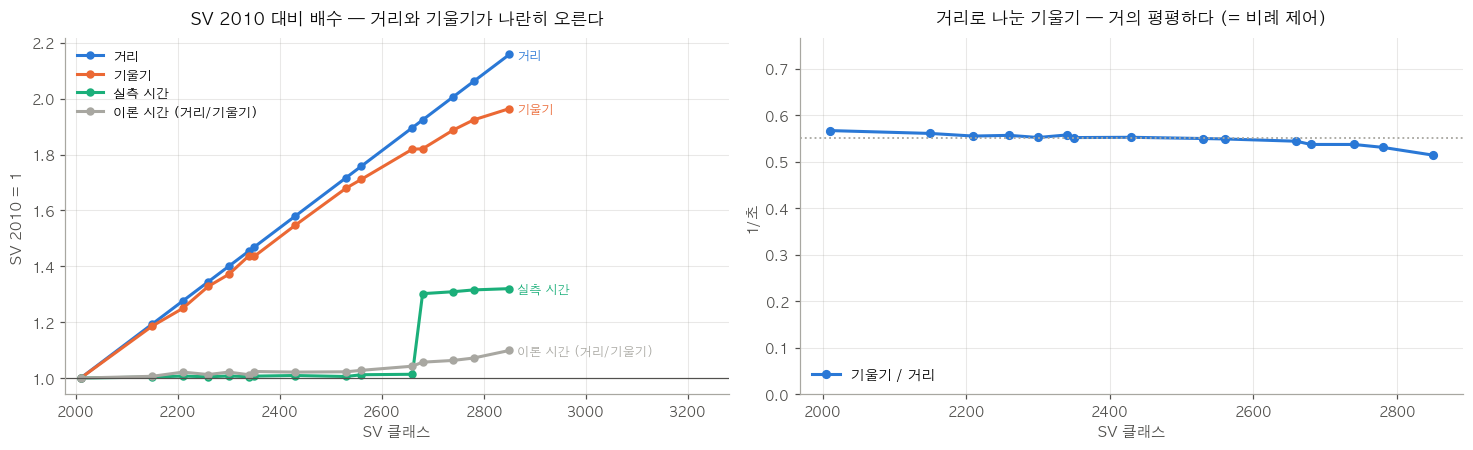


=== 변동폭 비교 (최대/최소) ===
  거리        2.16배
  기울기      1.96배   <- 거리와 거의 같이 움직인다
  정규화기울기 1.10배   <- 거의 일정
  이론 시간   1.10배   (= 거리/기울기)
  실측 시간   1.32배   <- 이론보다 크다

판정 (잠정 — 9-5 에서 정정됨)
  · 거리가 늘어난 만큼 램프 전체의 평균 기울기도 늘어난다 (비례 제어)
  · 다만 '전체 구간 1차회귀 기울기' 는 막판에 느려지는 부분을 평균으로 뭉갠다.
    그래서 이론 시간 1.10배 는 실제보다 작게 나온 값이다 -> 9-5 참고


In [38]:
from Cycle_Feature_Extractor import RAMP_THRESHOLD_PCT

# ==========================================
# 사이클마다 증압 기울기를 실제로 뽑는다
# ==========================================
_dr = raw.ffill().fillna(0).reset_index()
_dr = _dr.rename(columns={_dr.columns[0]: "Time"})
_bur = _dr[f"Pump_BuildUp_{PUMP_ID}"].astype(int)
_dr["cid"] = (_bur.diff().fillna(0) != 0).cumsum()
TAG_FT = f"Scale_Out___FT_{PUMP_ID}"

_rows = {}
for cid, seg in _dr[_bur == 1].groupby("cid"):
    if cid not in K.index:
        continue
    sv = seg[TAG_SV].iloc[0] or seg[TAG_SV].max()
    if not sv:
        continue
    ft = seg[TAG_FT].values.astype(float)
    tt = (seg["Time"] - seg["Time"].iloc[0]).dt.total_seconds().values
    ok = (np.abs(sv - ft) / sv) <= RAMP_THRESHOLD_PCT
    if not ok.any():
        continue
    j = int(np.argmax(ok))
    if j < 1:                       # 첫 틱부터 목표권이면 기울기를 못 잰다
        continue
    _rows[cid] = dict(SV=float(sv), FT0=ft[0], dist=sv - ft[0], t=tt[j], tick=j,
                      slope=np.polyfit(tt[:j+1], ft[:j+1], 1)[0])

RP = pd.DataFrame(_rows).T
RP["cls"]        = K.loc[RP.index, "SV_class"]
RP["PreFT"]      = K.loc[RP.index, "PreBuildUp_FT"]
RP["norm_slope"] = RP["slope"] / RP["dist"]        # 거리로 정규화 = 시스템 응답률
RP["Start_Time"] = K.loc[RP.index, "Start_Time"]
print(f"증압 기울기를 뽑은 사이클 {len(RP):,}개 / {len(K):,}\n")

G = RP.groupby("cls").agg(n=("SV", "size"), 거리=("dist", "median"),
                          기울기=("slope", "median"), 시간=("t", "median"),
                          틱=("tick", "median"), 정규화기울기=("norm_slope", "median"))
G = G[G["n"] >= 50]
print("=== 클래스별 ===")
print(G.round(3).to_string())

svv = G.index.astype(float)
print(f"\n  corr(SV, 거리)   = {np.corrcoef(svv, G.거리)[0,1]:+.3f}")
print(f"  corr(SV, 기울기) = {np.corrcoef(svv, G.기울기)[0,1]:+.3f}")
print(f"  corr(SV, 시간)   = {np.corrcoef(svv, G.시간)[0,1]:+.3f}")

# --- 공통 기준으로 지수화해서 한 축에 ---
base = G.index.min()
IDX = pd.DataFrame({"거리": G.거리/G.거리[base], "기울기": G.기울기/G.기울기[base],
                    "실측 시간": G.시간/G.시간[base],
                    "이론 시간 (거리/기울기)": (G.거리/G.기울기)/(G.거리[base]/G.기울기[base])})

fig, ax = plt.subplots(1, 2, figsize=(13.5, 4.2))
for (nm, col), c in zip(IDX.items(), [C1, C2, C3, GRAY]):
    ax[0].plot(svv, col.values, color=c, lw=2, marker="o", ms=4.5, label=nm)
    ax[0].annotate(nm, xy=(svv[-1], col.values[-1]), xytext=(5, 0),
                   textcoords="offset points", fontsize=8, color=c, va="center")
ax[0].axhline(1, color=INK2, lw=.8)
ax[0].set_xlim(svv.min()-30, svv.max()+430)
ax[0].legend(frameon=False, fontsize=8.5, loc="upper left")
ax_style(ax[0], f"SV {int(base)} 대비 배수 — 거리와 기울기가 나란히 오른다",
         "SV 클래스", f"SV {int(base)} = 1")

ax[1].plot(svv, G.정규화기울기.values, color=C1, lw=2, marker="o", ms=5,
           label="기울기 / 거리")
ax[1].axhline(G.정규화기울기.median(), color=GRAY, ls=":", lw=1.2)
ax[1].set_ylim(0, G.정규화기울기.max()*1.35)
ax[1].legend(frameon=False, fontsize=9, loc="lower left")
ax_style(ax[1], "거리로 나눈 기울기 — 거의 평평하다 (= 비례 제어)",
         "SV 클래스", "1/초")
plt.tight_layout(); plt.show()

print(f"\n=== 변동폭 비교 (최대/최소) ===")
print(f"  거리        {G.거리.max()/G.거리.min():.2f}배")
print(f"  기울기      {G.기울기.max()/G.기울기.min():.2f}배   <- 거리와 거의 같이 움직인다")
print(f"  정규화기울기 {G.정규화기울기.max()/G.정규화기울기.min():.2f}배   <- 거의 일정")
_theory = G.거리/G.기울기
print(f"  이론 시간   {_theory.max()/_theory.min():.2f}배   (= 거리/기울기)")
print(f"  실측 시간   {G.시간.max()/G.시간.min():.2f}배   <- 이론보다 크다")
print("\n판정 (잠정 — 9-5 에서 정정됨)")
print("  · 거리가 늘어난 만큼 램프 전체의 평균 기울기도 늘어난다 (비례 제어)")
print("  · 다만 '전체 구간 1차회귀 기울기' 는 막판에 느려지는 부분을 평균으로 뭉갠다.")
print("    그래서 이론 시간 1.10배 는 실제보다 작게 나온 값이다 -> 9-5 참고")

## 9-2. 직전 토출량이 높으면 덜 올려도 되나

**가설**: 기울기가 같다면, 직전 토출량이 많았던 사이클은 올릴 거리가 짧으니 빨리 끝나야 한다.

물리적으로 맞는 얘기다. 그런데 이 설비에서 성립하려면 **직전 토출량이 사이클마다 달라야** 한다.
먼저 그것부터 확인한다.

**그림 선택**: "이 값이 변하기는 하나" 를 보는 것이므로 **히스토그램**.
그리고 "변한다면 RampUp 과 관계가 있나" 는 **산점도**. 두 패널.


=== 시작 조건이 사이클마다 다른가 ===
  PreBuildUp_FT    고유값  147   최빈값 1285 ( 72.1%)   범위 1256~1680   std 31.74   CV 2.46%
  PreBuildUp_PT    고유값   22   최빈값 60 ( 14.7%)   범위 52~76   std 2.53   CV 4.20%

  정지(BuildUp=0) 구간의 FT 값 분포 상위 5개:
Scale_Out___FT_P1
1285.0    224859
0.0       203107
1271.0     47352
1287.0      9141
1300.0      7777
  -> 1285 또는 0 이 70.3%
     펌프가 꺼지면 유량계가 고정값을 읽는다 = '직전에 얼마나 토출했나' 가 안 남는다


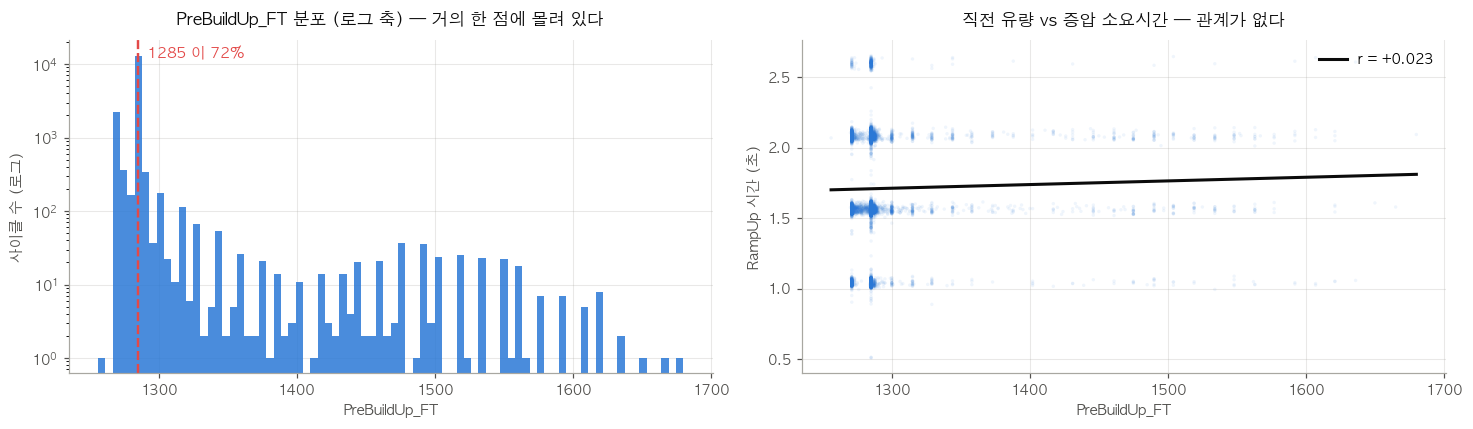


=== 상관 ===
  corr(PreBuildUp_FT, 올릴 거리)   = -0.096
  corr(PreBuildUp_FT, RampUp 시간) = +0.023
  corr(올릴 거리,     RampUp 시간) = +0.263
  corr(거리/기울기,   RampUp 시간) = +0.880   <- 1 에 가까우면 시간 = 거리/기울기 가 성립

판정
  · 가설 자체는 물리적으로 맞다. 다만 **이 설비에서는 검증할 수 없다**.
    펌프가 꺼지면 유량계가 항상 같은 값으로 돌아가서, 시작 유량이 사실상 상수다.
  · 그래서 '올릴 거리' 는 거의 전적으로 SV 가 정한다 (9-1 의 corr(SV, 거리) = +1.000).
  · 즉 이 관점에서 새로 넣을 피처는 없다. PreBuildUp_FT 는 정보가 거의 없는 피처다.


In [39]:
print("=== 시작 조건이 사이클마다 다른가 ===")
for c in ["PreBuildUp_FT", "PreBuildUp_PT"]:
    s = K[c]
    mode = s.mode().iloc[0]
    print(f"  {c:16s} 고유값 {s.nunique():4d}   최빈값 {mode:.0f} ({(s==mode).mean()*100:5.1f}%)   "
          f"범위 {s.min():.0f}~{s.max():.0f}   std {s.std():.2f}   CV {s.std()/s.mean()*100:.2f}%")

_off_ft = raw.loc[raw[f"Pump_BuildUp_{PUMP_ID}"].astype(int) == 0, TAG_FT]
print(f"\n  정지(BuildUp=0) 구간의 FT 값 분포 상위 5개:")
print(_off_ft.value_counts().head(5).to_string())
print(f"  -> 1285 또는 0 이 {((_off_ft==1285)|(_off_ft==0)).mean()*100:.1f}%")
print("     펌프가 꺼지면 유량계가 고정값을 읽는다 = '직전에 얼마나 토출했나' 가 안 남는다")

fig, ax = plt.subplots(1, 2, figsize=(13.5, 4.0))
ax[0].hist(K["PreBuildUp_FT"], bins=80, color=C1, alpha=.85)
_md = K["PreBuildUp_FT"].mode().iloc[0]
ax[0].axvline(_md, color=BAD, ls="--", lw=1.6)
ax[0].annotate(f"{_md:.0f} 이 {(K['PreBuildUp_FT']==_md).mean()*100:.0f}%",
               xy=(_md, 1.0), xycoords=("data", "axes fraction"),
               xytext=(6, -12), textcoords="offset points", color=BAD, fontsize=9.5)
ax[0].set_yscale("log")
ax_style(ax[0], "PreBuildUp_FT 분포 (로그 축) — 거의 한 점에 몰려 있다",
         "PreBuildUp_FT", "사이클 수 (로그)")

ax[1].scatter(RP["PreFT"], RP["t"], s=5, alpha=.07, color=C1, edgecolors="none")
_ok = RP["PreFT"].notna() & RP["t"].notna()
_z = np.polyfit(RP["PreFT"][_ok], RP["t"][_ok], 1)
_xs = np.linspace(RP["PreFT"].min(), RP["PreFT"].max(), 40)
_r = RP["PreFT"].corr(RP["t"])
ax[1].plot(_xs, np.polyval(_z, _xs), color=INK, lw=2, label=f"r = {_r:+.3f}")
ax[1].legend(frameon=False, fontsize=9, loc="upper right")
ax_style(ax[1], "직전 유량 vs 증압 소요시간 — 관계가 없다",
         "PreBuildUp_FT", "RampUp 시간 (초)")
plt.tight_layout(); plt.show()

print("\n=== 상관 ===")
print(f"  corr(PreBuildUp_FT, 올릴 거리)   = {RP['PreFT'].corr(RP['dist']):+.3f}")
print(f"  corr(PreBuildUp_FT, RampUp 시간) = {RP['PreFT'].corr(RP['t']):+.3f}")
print(f"  corr(올릴 거리,     RampUp 시간) = {RP['dist'].corr(RP['t']):+.3f}")
print(f"  corr(거리/기울기,   RampUp 시간) = {(RP['dist']/RP['slope']).corr(RP['t']):+.3f}"
      "   <- 1 에 가까우면 시간 = 거리/기울기 가 성립")
print("\n판정")
print("  · 가설 자체는 물리적으로 맞다. 다만 **이 설비에서는 검증할 수 없다**.")
print("    펌프가 꺼지면 유량계가 항상 같은 값으로 돌아가서, 시작 유량이 사실상 상수다.")
print("  · 그래서 '올릴 거리' 는 거의 전적으로 SV 가 정한다 (9-1 의 corr(SV, 거리) = +1.000).")
print("  · 즉 이 관점에서 새로 넣을 피처는 없다. PreBuildUp_FT 는 정보가 거의 없는 피처다.")

## 9-3. 그래서 어떤 형태로 넣을까

후보 넷을 같은 기준으로 비교한다.

| 후보 | 뜻 |
|---|---|
| `RampUp_Time_Sec` | 지금 쓰는 것. 목표 도달까지 걸린 초 |
| `Ramp_Slope` | 증압 구간 `dFT/dt` 원시값 |
| **`Ramp_Slope / 거리`** | 거리로 정규화한 응답률 = **1/시정수** |
| `Ramp_Slope / SV` | SV 로 정규화 |

**보는 기준 세 가지**
1. **η²(SV)** — 레시피에 안 끌려다녀야 건강 지표로 쓸 수 있다
2. **분해능** — 4-1 에서 본 대로 `RampUp_Time_Sec` 은 사실상 3~4틱 **6단계**뿐이다.
   고유값이 많아야 작은 변화를 잡는다
3. **신호 성질** — 잔차가 이어지는가(lag-1), 날마다 흐르는가

**그림 선택**: (왼쪽) η² 비교는 **막대**.
(오른쪽) 분해능 차이는 **분포**로 보여야 한다 — 양자화된 것은 봉우리가 갈라지고
연속적인 것은 매끄럽다. 두 값의 단위가 다르므로 각각 자기 표준편차로 나눠 겹쳐 그린다.


=== 후보 비교 ===
                      η²(SV)  corr(SV)   CV%    고유값   lag1  일자흔들림σ
후보                                                                
RampUp_Time_Sec (현재)   0.051     0.223  20.9  16327  0.027    0.09
Ramp_Slope 원시          0.602     0.775  28.0  17082 -0.007    0.21
Ramp_Slope / 거리        0.046    -0.214  21.0  17082  0.052    0.11
Ramp_Slope / SV        0.254     0.494  20.8  17082  0.031    0.15


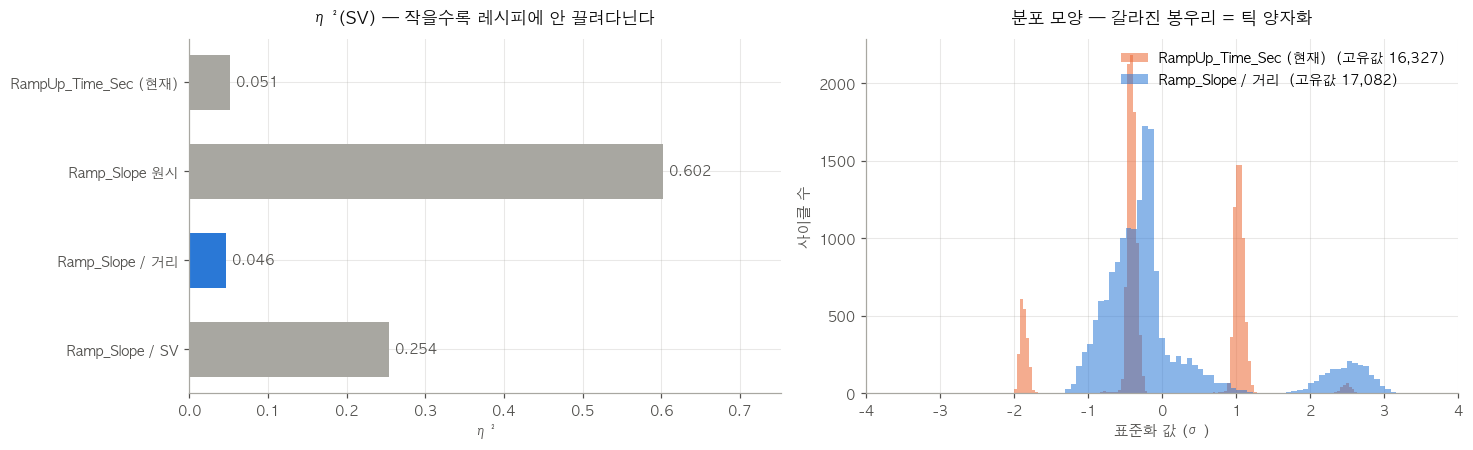


판정 — **Ramp_Slope / 거리**
  · η²(SV) 0.046  (현재 RampUp_Time_Sec 0.051)
  · 고유값 17,082개  vs  RampUp_Time 의 실효 단계 6개(4-1)
    -> 틱 양자화가 없어서 작은 변화를 잡을 수 있다
  · 물리적 의미도 분명하다: 목표가 뭐든 같아야 하는 **시스템 응답률(1/시정수)** 이다
    펌프 토출 능력이 떨어지면 이 값이 내려간다
  · 반대로 Ramp_Slope 원시값은 η² 0.602 로 최악이다 —
    비례 제어라 기울기가 SV 를 그대로 따라가기 때문이다 (9-1)


In [37]:
CAND = {
    "RampUp_Time_Sec (현재)": RP["t"],
    "Ramp_Slope 원시":        RP["slope"],
    "Ramp_Slope / 거리":      RP["norm_slope"],
    "Ramp_Slope / SV":        RP["slope"] / RP["SV"],
}
_stp = pd.to_datetime(RP["Start_Time"])
res = []
for nm, s in CAND.items():
    s = s.replace([np.inf, -np.inf], np.nan)
    ok = s.notna()
    daily = s[ok].groupby(_stp[ok].dt.normalize()).mean()
    z = (s - s.mean()) / s.std()
    res.append({"후보": nm,
                "η²(SV)": round(eta_squared(s[ok], RP["cls"][ok]), 3),
                "corr(SV)": round(float(np.corrcoef(RP["SV"][ok], s[ok])[0, 1]), 3),
                "CV%": round(float(s.std()/abs(s.mean())*100), 1),
                "고유값": int(s.nunique()),
                "lag1": round(float(s.autocorr(1)), 3),
                "일자흔들림σ": round(float((daily.max()-daily.min())/s.std()), 2)})
CT = pd.DataFrame(res).set_index("후보")
print("=== 후보 비교 ===")
print(CT.to_string())

fig, ax = plt.subplots(1, 2, figsize=(13.5, 4.2))
names = list(CT.index)
yp = np.arange(len(names))[::-1]
best_i = int(np.argmin(CT["η²(SV)"].values))
cols_ = [C1 if i == best_i else GRAY for i in range(len(names))]
ax[0].barh(yp, CT["η²(SV)"].values, color=cols_, height=.62)
ax[0].set_yticks(yp, names, fontsize=9)
for y, v in zip(yp, CT["η²(SV)"].values):
    ax[0].annotate(f"{v:.3f}", xy=(v, y), xytext=(4, 0), textcoords="offset points",
                   va="center", fontsize=9, color=INK2)
ax[0].set_xlim(0, max(CT["η²(SV)"])*1.25)
ax_style(ax[0], "η²(SV) — 작을수록 레시피에 안 끌려다닌다", "η²", None)

for nm, c in [("RampUp_Time_Sec (현재)", C2), ("Ramp_Slope / 거리", C1)]:
    s = CAND[nm].replace([np.inf, -np.inf], np.nan).dropna()
    zz = (s - s.mean()) / s.std()
    ax[1].hist(zz, bins=150, color=c, alpha=.55, label=f"{nm}  (고유값 {s.nunique():,})")
ax[1].set_xlim(-4, 4)
ax[1].legend(frameon=False, fontsize=9)
ax_style(ax[1], "분포 모양 — 갈라진 봉우리 = 틱 양자화", "표준화 값 (σ)", "사이클 수")
plt.tight_layout(); plt.show()

_b = CT.index[best_i]
print(f"\n판정 — **{_b}**")
print(f"  · η²(SV) {CT.loc[_b,'η²(SV)']:.3f}  (현재 RampUp_Time_Sec {CT.loc['RampUp_Time_Sec (현재)','η²(SV)']:.3f})")
print(f"  · 고유값 {CT.loc[_b,'고유값']:,}개  vs  RampUp_Time 의 실효 단계 6개(4-1)")
print("    -> 틱 양자화가 없어서 작은 변화를 잡을 수 있다")
print("  · 물리적 의미도 분명하다: 목표가 뭐든 같아야 하는 **시스템 응답률(1/시정수)** 이다")
print("    펌프 토출 능력이 떨어지면 이 값이 내려간다")
print(f"  · 반대로 Ramp_Slope 원시값은 η² {CT.loc['Ramp_Slope 원시','η²(SV)']:.3f} 로 최악이다 —")
print("    비례 제어라 기울기가 SV 를 그대로 따라가기 때문이다 (9-1)")

## 9-4. 마무리 — 세 질문에 대한 답

### (1) 가파르게 올라간다 — 오래 걸리는 게 아니다  ⚠ 9-5 에서 정정

| | 최대/최소 |
|---|---|
| 올릴 거리 | 2.16배 |
| 실제 기울기 | **1.96배** |
| 거리로 나눈 기울기 | **1.10배** |
| 이론 시간 (거리/기울기) | 1.10배 |
| 실측 시간 | 1.32배 |

**거리가 늘어난 만큼 램프 전체의 평균 기울기도 늘어난다.** 비례 제어라 목표가 높으면 그만큼 세게 민다.

> ~~그래서 실제 시간 증가는 10% 수준이고, 32% 는 틱 양자화 탓이다~~ — **틀렸다.**
> 틱 사이를 보간해 잰 실제 통과시각은 **1.24배** 늘어난다 (corr +0.966).
> 전체 구간 평균 기울기가 **막판 감속**을 뭉개서 10% 로 작게 보였던 것이다. 9-5 참고.

### (2) 직전 토출량 가설 — 물리적으로 맞지만 이 설비에선 검증 불가

`PreBuildUp_FT` 가 **1285 한 값에 72.1%** 몰려 있고 CV 가 1.5% 뿐이다.
펌프가 꺼지면 유량계가 고정값으로 돌아가서 **"직전에 얼마나 토출했나" 가 안 남는다.**

- `corr(PreBuildUp_FT, RampUp 시간)` = **+0.023** — 사실상 무관
- 반면 `corr(SV, 올릴 거리)` = **+1.000** — 거리는 전적으로 SV 가 정한다

즉 이 관점에서 새로 넣을 피처는 없고, **`PreBuildUp_FT` 자체가 정보가 거의 없는 피처**다
(3장에서 버릴 후보에 넣을 만하다).

### (3) 넣는다면 `Ramp_Slope / 거리`  ⚠ 9-5 에서 정정

| 후보 | η²(SV) | 고유값 |
|---|---|---|
| `RampUp_Time_Sec` (현재) | 0.051 | 실효 **6단계** |
| `Ramp_Slope` 원시 | **0.602** | 17,082 |
| **`Ramp_Slope / 거리`** | **0.046** | **17,082** |
| `Ramp_Slope / SV` | 0.254 | 17,082 |

**`Ramp_Slope / 거리` 를 쓰는 게 낫다.**

- η² 가 현재 것보다 조금 더 낮고 (0.046 vs 0.051)
- 결정적으로 **틱 양자화가 없다.** `RampUp_Time_Sec` 은 4-1 에서 본 대로
  분해능이 틱 1개(0.52초 = 중앙값의 31%) 라 그보다 작은 변화를 원리상 못 잡는다
- 물리적 의미가 분명하다 — 목표가 뭐든 같아야 하는 **시스템 응답률(1/시정수)** 이고,
  펌프 토출 능력이 떨어지면 이 값이 내려간다

반대로 **`Ramp_Slope` 원시값은 최악이다** (η² 0.602). 비례 제어라
기울기가 SV 를 그대로 따라가기 때문이다. 기울기를 쓰려면 **반드시 거리로 나눠야 한다.**

> 계산은 `Cycle_Feature_Extractor` 에서 `RampUp_Time_Sec` 을 구하는 바로 그 자리에서
> 두 줄이면 된다 — 이미 증압 구간 인덱스 `first_ok_idx` 를 찾아 놓았으므로,
> 그 구간에 `np.polyfit` 으로 기울기를 내고 `(sv_ref − FT 첫틱)` 으로 나누면 된다.


---
## 9-5. 정정 — SV 가 커지면 RampUp 이 길어지는 건 진짜다

> 질문: *"그러면 이전에 봤던 SV 가 커질 때 RampUp 시간이 길어지는 것은 어떻게 설명할 건데?"*

9-1 에서 "실제 증가는 10%, 나머지는 틱 양자화" 라고 했는데 **틀렸다.**
양자화는 추세를 계단으로 만들 뿐, **없는 추세를 만들지는 못한다.**
4틱 이상 비율이 26% → 66% 로 꾸준히 오른 건 밑에 진짜 변화가 있다는 뜻이다.

### 양자화를 걷어내고 재기

`RampUp_Time_Sec` 은 **목표권(`|FT−SV|/SV ≤ 5%`)에 들어온 첫 틱의 시각**이다.
그런데 실제로 목표권 하한선(`0.95 × SV`)을 넘은 순간은 **그 직전 틱과 그 틱 사이 어딘가**다.
두 틱 사이를 직선으로 보간하면 **틱에 안 묶인 실제 통과시각**을 얻는다.

```
통과시각 = t[j−1] + (0.95·SV − FT[j−1]) / (FT[j] − FT[j−1]) × (t[j] − t[j−1])
```

### 그리고 원인 찾기

증압 곡선을 **초반**(첫 틱 → 둘째 틱)과 **막판**(목표권 직전 틱 → 진입 틱)으로 나눠
각각의 기울기를 거리로 정규화해서 본다. 어느 쪽이 SV 에 따라 느려지는지 보면 원인이 나온다.

**그림 선택**
- (왼쪽) 틱 기준 vs 보간 기준 시간 — 계단인가 매끄러운 경사인가를 보려고 **선 두 개**를 같은 축에 (단위 같음)
- (가운데) 보간 통과시각 구간별 '4틱 이상' 비율 — **양자화가 어떻게 작동하는지**. 문턱이 보여야 한다
- (오른쪽) 막판 기울기 — **원인**


=== 클래스별 ===
           n  틱기준_중앙  틱기준_평균  보간_중앙  보간_평균    틱4이상  초반기울기  막판기울기  안정값_SV
SV                                                                      
2010.0  3570   1.568   1.616  1.461  1.452  26.387  0.150  0.963   0.996
2150.0  4086   1.573   1.659  1.492  1.516  31.645  0.118  0.969   0.992
2210.0   122   1.579   1.690  1.512  1.534  38.525  0.057  0.903   0.991
2260.0   884   1.574   1.683  1.507  1.549  33.824  0.110  0.925   0.990
2300.0  1645   1.579   1.710  1.516  1.575  35.198  0.108  0.913   0.991
2340.0   126   1.575   1.692  1.505  1.570  32.540  0.125  0.990   0.992
2350.0  1071   1.578   1.710  1.522  1.581  37.722  0.097  0.914   0.994
2430.0   167   1.582   1.751  1.528  1.605  42.515  0.059  0.822   0.992
2530.0    61   1.576   1.672  1.527  1.573  26.230  0.157  1.107   0.987
2560.0    99   1.586   1.753  1.533  1.634  40.404  0.107  0.831   0.993
2660.0   906   1.589   1.786  1.548  1.666  42.936  0.080  0.881   0.988
2680.0  3365   2.041   1.823  1.602  1

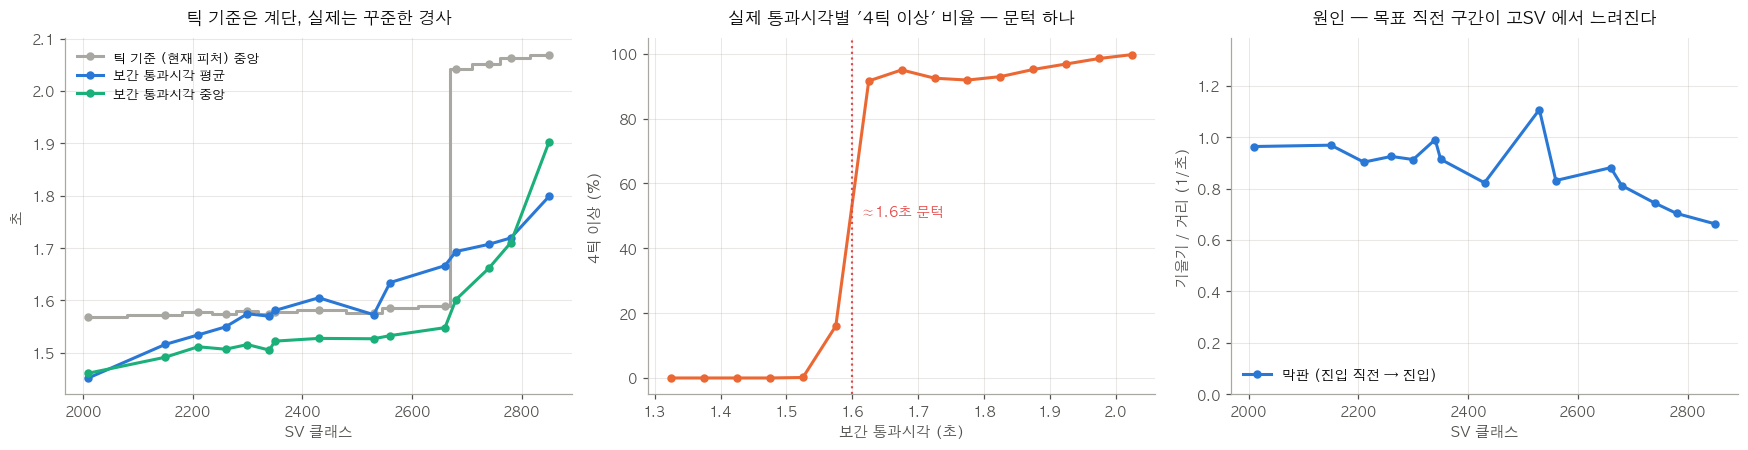


=== 원인: 초반 vs 막판 ===
  초반 정규화기울기 corr(SV) -0.547   (CV 126% — 첫 틱은 구동 지연으로 들쭉날쭉)
  막판 정규화기울기 0.963 -> 0.663  (-31%)   corr(SV) -0.689
  안정값/SV          0.996 -> 0.984   corr(SV) -0.815
    -> 목표권 하한(0.95)까지 여유 4.6%p -> 3.4%p

=== 피처 후보 재비교 ===
  RampUp_Time_Sec (틱 기준)   η²(SV) 0.051   고유값 16,289   CV  20.9%   lag1 +0.028
  보간 통과시각                  η²(SV) 0.095   고유값 17,028   CV  18.9%   lag1 +0.066


In [40]:
_rows = {}
for cid, seg in _dr[_bur == 1].groupby("cid"):
    if cid not in K.index:
        continue
    sv = seg[TAG_SV].iloc[0] or seg[TAG_SV].max()
    if not sv:
        continue
    ft = seg[TAG_FT].values.astype(float)
    tt = (seg["Time"] - seg["Time"].iloc[0]).dt.total_seconds().values
    ok = (np.abs(sv - ft) / sv) <= RAMP_THRESHOLD_PCT
    if not ok.any() or len(ft) < 8:
        continue
    j = int(np.argmax(ok))
    if j < 1:
        continue
    lvl = sv * (1 - RAMP_THRESHOLD_PCT)                   # 목표권 하한선
    f0, f1 = ft[j-1], ft[j]
    tcross = (tt[j-1] + (lvl - f0) / (f1 - f0) * (tt[j] - tt[j-1])
              if f1 > f0 and f0 < lvl <= f1 else np.nan)   # 틱 사이 보간
    dist = sv - ft[0]
    _rows[cid] = dict(SV=K.loc[cid, "SV_class"], tick=j, t_tick=tt[j], tcross=tcross,
                      s_early=((ft[1]-ft[0])/(tt[1]-tt[0]))/dist if tt[1] > tt[0] else np.nan,
                      s_late=((f1-f0)/(tt[j]-tt[j-1]))/dist if tt[j] > tt[j-1] else np.nan,
                      plateau=np.median(ft[j+1:j+6]) / sv)
RX = pd.DataFrame(_rows).T.astype(float)
RX = RX[RX.groupby("SV")["tcross"].transform("size") >= 50]

TX = RX.groupby("SV").agg(n=("tick", "size"),
                          틱기준_중앙=("t_tick", "median"), 틱기준_평균=("t_tick", "mean"),
                          보간_중앙=("tcross", "median"), 보간_평균=("tcross", "mean"),
                          틱4이상=("tick", lambda s: (s >= 4).mean()*100),
                          초반기울기=("s_early", "median"), 막판기울기=("s_late", "median"),
                          안정값_SV=("plateau", "median"))
print("=== 클래스별 ===")
print(TX.round(3).to_string())

svx = TX.index.values
print("\n=== 증가폭 (최대/최소)  /  SV 와의 상관 ===")
for c in ["틱기준_중앙", "틱기준_평균", "보간_중앙", "보간_평균"]:
    print(f"  {c:10s} {TX[c].max()/TX[c].min():.3f}배   corr(SV) {np.corrcoef(svx, TX[c])[0,1]:+.3f}")

fig, ax = plt.subplots(1, 3, figsize=(16, 4.2))
ax[0].plot(svx, TX["틱기준_중앙"], color=GRAY, lw=2, marker="o", ms=4.5,
           drawstyle="steps-mid", label="틱 기준 (현재 피처) 중앙")
ax[0].plot(svx, TX["보간_평균"], color=C1, lw=2, marker="o", ms=4.5, label="보간 통과시각 평균")
ax[0].plot(svx, TX["보간_중앙"], color=C3, lw=2, marker="o", ms=4.5, label="보간 통과시각 중앙")
ax[0].legend(frameon=False, fontsize=8.5, loc="upper left")
ax_style(ax[0], "틱 기준은 계단, 실제는 꾸준한 경사", "SV 클래스", "초")

bins = np.arange(1.30, 2.10, 0.05)
_pp = RX.groupby(pd.cut(RX["tcross"], bins))["tick"].apply(lambda s: (s >= 4).mean()*100).dropna()
_mid = [iv.mid for iv in _pp.index]
ax[1].plot(_mid, _pp.values, color=C2, lw=2, marker="o", ms=4.5)
ax[1].axvline(1.6, color=BAD, ls=":", lw=1.4)
ax[1].annotate("≈1.6초 문턱", xy=(1.6, 50), xytext=(6, 0), textcoords="offset points",
               color=BAD, fontsize=9)
ax_style(ax[1], "실제 통과시각별 '4틱 이상' 비율 — 문턱 하나", "보간 통과시각 (초)", "4틱 이상 (%)")

ax[2].plot(svx, TX["막판기울기"], color=C1, lw=2, marker="o", ms=4.5, label="막판 (진입 직전 → 진입)")
ax[2].set_ylim(0, TX["막판기울기"].max() * 1.25)
ax[2].legend(frameon=False, fontsize=9, loc="lower left")
ax_style(ax[2], "원인 — 목표 직전 구간이 고SV 에서 느려진다", "SV 클래스", "기울기 / 거리 (1/초)")
plt.tight_layout(); plt.show()

print("\n=== 원인: 초반 vs 막판 ===")
print(f"  초반 정규화기울기 corr(SV) {np.corrcoef(svx, TX['초반기울기'])[0,1]:+.3f}   "
      f"(CV {RX['s_early'].std()/RX['s_early'].mean()*100:.0f}% — 첫 틱은 구동 지연으로 들쭉날쭉)")
print(f"  막판 정규화기울기 {TX['막판기울기'].iloc[0]:.3f} -> {TX['막판기울기'].iloc[-1]:.3f}  "
      f"({(TX['막판기울기'].iloc[-1]/TX['막판기울기'].iloc[0]-1)*100:+.0f}%)   "
      f"corr(SV) {np.corrcoef(svx, TX['막판기울기'])[0,1]:+.3f}")
print(f"  안정값/SV          {TX['안정값_SV'].iloc[0]:.3f} -> {TX['안정값_SV'].iloc[-1]:.3f}   "
      f"corr(SV) {np.corrcoef(svx, TX['안정값_SV'])[0,1]:+.3f}")
print(f"    -> 목표권 하한(0.95)까지 여유 {(TX['안정값_SV'].iloc[0]-0.95)*100:.1f}%p -> "
      f"{(TX['안정값_SV'].iloc[-1]-0.95)*100:.1f}%p")

print("\n=== 피처 후보 재비교 ===")
for nm, s in [("RampUp_Time_Sec (틱 기준)", RX["t_tick"]),
              ("보간 통과시각", RX["tcross"])]:
    s = s.dropna()
    print(f"  {nm:24s} η²(SV) {eta_squared(s, RX['SV'][s.index]):.3f}   고유값 {s.nunique():6,}   "
          f"CV {s.std()/s.mean()*100:5.1f}%   lag1 {s.autocorr(1):+.3f}")

### 9-6. 정정된 결론

**SV 가 커지면 RampUp 이 길어지는 건 진짜다.** 틱 양자화를 걷어낸 실제 통과시각이
**1.461초 → 1.903초 (중앙), 평균 기준 1.24배**, `corr(SV) = +0.966` 으로 꾸준히 는다.

**왜 늘어나나 — 목표 직전에서 느려지기 때문이다.**

- 증압 **초반**은 비례 제어라 목표가 높으면 그만큼 세게 민다 (9-1 의 전체 평균 기울기 1.96배)
- 그런데 **막판**(목표권 진입 직전 구간)의 정규화 기울기는 **0.963 → 0.663 (−31%)** 로 떨어진다
- 도달하는 안정값도 `SV` 대비 **0.996 → 0.984** 로 내려간다. 목표권 하한(0.95)까지
  여유가 4.6%p → 3.4%p 로 줄어, 곡선이 그 선에 **비스듬히 다가가며** 넘는 데 오래 걸린다
- 즉 2-3 에서 본 **고유량 포화**가 증압 곡선의 꼬리에서 드러나는 것이다

**양자화는 어떤 역할이었나** — 추세를 만든 게 아니라 **계단으로 바꿨을 뿐**이다.
실제 통과시각이 **약 1.6초 문턱**을 넘으면 4틱, 못 넘으면 3틱이다
(1.55초 이하 → 4틱 0%, 1.60초 이상 → 4틱 90%+).
평균 통과시각이 1.45 → 1.80 으로 밀리면서 문턱을 넘는 사이클이 26% → 66% 로 늘었고,
**중앙값**은 50% 를 넘는 SV 2680 에서 1.57 → 2.04 로 한 번에 점프했다.

**9-1 이 왜 틀렸나** — 램프 **전체 구간을 1차회귀**한 기울기로 `거리/기울기` 를 계산했다.
그러면 빠른 초반과 느린 막판이 평균돼서 막판 감속이 묻힌다. 그래서 10% 로 작게 나왔다.

### 피처 추천도 바뀐다

| 후보 | η²(SV) | 고유값 | 비고 |
|---|---|---|---|
| `RampUp_Time_Sec` (틱 기준) | 0.051 | 사실상 6단계 | 분해능 0.52초 |
| `Ramp_Slope / 거리` (9-3 추천) | 0.046 | 연속 | **막판 감속을 평균으로 뭉갬** |
| **보간 통과시각** | 0.095 | **연속** | **실제 현상 그대로** |

9-3 에서 `Ramp_Slope / 거리` 를 추천한 근거는 η² 가 제일 낮다는 거였는데,
η² 가 낮았던 이유 중 하나가 **정작 포화 신호가 담긴 막판을 못 보기 때문**이었다.
포화는 설비 상태와 직결되는 정보라 지우면 안 된다.

그리고 7장에서 확인했듯 **AE 는 `SV_mean` 을 입력으로 받으므로 SV 의존성은 알아서 흡수한다.**
η² 가 조금 높은 건 문제가 아니다.

→ **`RampUp_Time_Sec` 을 보간 통과시각으로 바꾸는 게 맞다.** 정의는 그대로(목표권 진입 시각)이고
틱 두 개 사이를 보간하는 한 줄만 추가하면 된다. 양자화가 사라지고, 포화 정보는 살아 있다.


---
## 9-7. 보간 통과시각은 어떻게 재나 — 식 그대로 쓰면 절반이 틀린다

9-5 의 식은 **직전 틱**과 **진입 틱** 사이를 직선으로 이었다.

```
통과시각 = t[j−1] + (0.95·SV − FT[j−1]) / (FT[j] − FT[j−1]) × (t[j] − t[j−1])
```

문제는 **`FT[j−1]` 이 진짜 그 시각의 유량이 아닐 수 있다**는 것이다.

DB 는 **값이 바뀐 태그만** 기록한다. `raw` 의 한 행(틱)은 "어떤 태그든 하나가 바뀐 순간" 이고,
그 행의 FT 는 `ffill` 로 채운 **마지막으로 기록된 값**일 수 있다.
실측으로 가동 중 **FT 가 새로 찍힌 틱은 56% 뿐**이고, FT 변화 간격 p75 가 **1.05초**다.
틱(0.52초)보다 FT 의 실제 샘플링이 성기다.

그래서 직전 틱의 FT 가 **묵은 값**이면, 그 시각에 유량이 거기 있었다고 보고 보간하면
**통과시각을 엉뚱하게 당기거나 민다.** 이 경우가 **53%** 였다.

### 제대로 재는 규칙

| 경우 | 비율 | 처리 |
|---|---|---|
| 직전 틱이 **묵은 값** | 53.3% | FT 가 **마지막으로 실제로 바뀐 틱**까지 거슬러 가서 그 점과 보간 |
| 정상 (직전 틱에 새 값) | 46.6% | 식 그대로 |
| 위에서 내려옴 (오버슈트) | 0.05% | 하한선이 아니라 **상한선 `1.05·SV`** 으로 보간 |
| 첫 틱부터 목표권 | 0.01% | 0 초 |
| 끝까지 목표권 못 들어감 | — | NaN (기존 `RampUp_Time_Sec` 과 동일) |

**그림 선택**
- (왼쪽) **사이클 하나를 확대** — 묵은 틱이 어떻게 생겼고 두 방식의 통과시각이 어디 찍히는지 눈으로 본다.
  틱마다 점을 찍고, **실제로 FT 가 기록된 틱**과 **ffill 로 채운 틱**을 다른 모양으로 구분한다
- (가운데) 보정 전후 차이 분포 — 얼마나 자주, 얼마나 크게 틀리나
- (오른쪽) 클래스별 추세 — 보정해도 9-5 의 결론이 유지되나


=== 처리 방식 분포 ===
how
묵은값보정    53.31
정상       46.63
오버슈트      0.05
첫틱부터      0.01

=== 보정 전후 차이 (보정 − 단순식) ===
  중앙 -0.018초   |차이| > 0.1초 23.0%   |차이| > 0.2초 9.9%   최대 1.611초

=== 클래스별 평균 ===
         tick  naive  fixed
SV                         
2010.0  1.616  1.452  1.378
2150.0  1.659  1.518  1.450
2210.0  1.690  1.534  1.448
2260.0  1.683  1.549  1.488
2300.0  1.710  1.575  1.510
2340.0  1.692  1.570  1.505
2350.0  1.710  1.581  1.518
2430.0  1.751  1.605  1.541
2530.0  1.672  1.573  1.543
2560.0  1.753  1.634  1.578
2660.0  1.786  1.666  1.608
2680.0  1.823  1.693  1.631
2740.0  1.844  1.707  1.637
2780.0  1.848  1.719  1.651
2850.0  1.936  1.799  1.732
  틱 기준 (현재)    1.616 -> 1.936  (1.198배)  corr(SV) +0.919
  단순 보간        1.452 -> 1.799  (1.239배)  corr(SV) +0.965
  보정 보간        1.378 -> 1.732  (1.257배)  corr(SV) +0.982


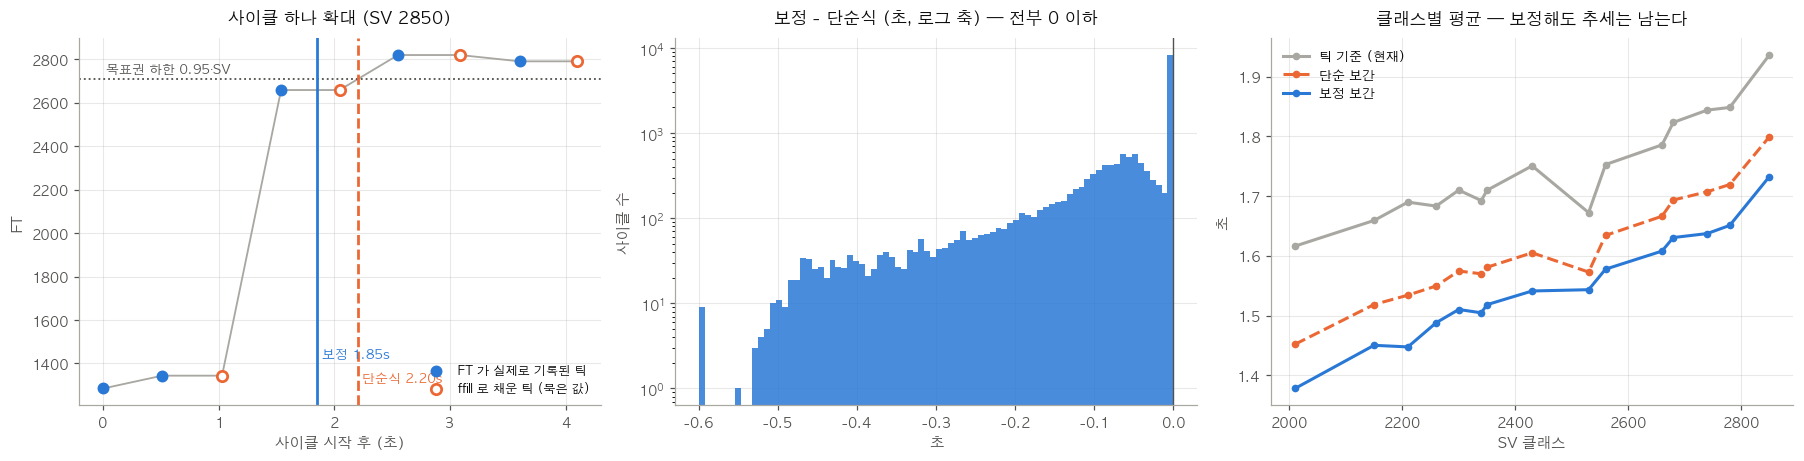

In [41]:
def ramp_crossing_time(t, ft, sv, band=RAMP_THRESHOLD_PCT):
    """증압 중 유량이 목표권(|FT−SV|/SV <= band)에 들어간 '실제' 시각(초).

    t, ft : 사이클 첫 틱부터의 경과초 / 유량 (ffill 된 틱 단위 배열)
    반환  : (통과시각, 사용한 방식)

    틱에 묶이지 않도록 두 기록점 사이를 직선 보간한다.
    ffill 로 채운 '묵은' FT 는 기록점이 아니므로, 마지막으로 값이 바뀐 틱까지 거슬러 간다.
    """
    ok = np.abs(sv - ft) / sv <= band
    if not ok.any():
        return np.nan, "미진입"
    j = int(np.argmax(ok))
    if j == 0:
        return 0.0, "첫틱부터"
    k = j - 1
    while k > 0 and ft[k] == ft[k - 1]:            # 묵은 값이면 실제 기록점까지 거슬러 간다
        k -= 1
    if ft[k] > sv * (1 + band):                    # 위에서 내려오는 경우 -> 상한선
        line, how = sv * (1 + band), "오버슈트"
    else:
        line, how = sv * (1 - band), ("묵은값보정" if k != j - 1 else "정상")
    if ft[j] == ft[k]:
        return t[j], how
    return t[k] + (line - ft[k]) / (ft[j] - ft[k]) * (t[j] - t[k]), how


# ==========================================
# 전체 사이클에 적용 — 9-5 의 단순식(naive)과 비교
# ==========================================
_rows, _ex = {}, {}
for cid, seg in _dr[_bur == 1].groupby("cid"):
    if cid not in K.index:
        continue
    sv = seg[TAG_SV].iloc[0] or seg[TAG_SV].max()
    if not sv:
        continue
    ft = seg[TAG_FT].values.astype(float)
    tt = (seg["Time"] - seg["Time"].iloc[0]).dt.total_seconds().values
    tc, how = ramp_crossing_time(tt, ft, sv)
    ok = np.abs(sv - ft) / sv <= RAMP_THRESHOLD_PCT
    j = int(np.argmax(ok)) if ok.any() else -1
    naive = (tt[j-1] + (sv*(1-RAMP_THRESHOLD_PCT) - ft[j-1]) / (ft[j] - ft[j-1]) * (tt[j] - tt[j-1])
             if j >= 1 and ft[j] != ft[j-1] else np.nan)
    _rows[cid] = dict(SV=K.loc[cid, "SV_class"], tick=K.loc[cid, "RampUp_Time_Sec"],
                      naive=naive, fixed=tc, how=how)
    if how == "묵은값보정" and not np.isnan(naive) and abs(tc - naive) > .2 and len(_ex) < 1:
        _ex = dict(cid=cid, t=tt, ft=ft, sv=sv, j=j, naive=naive, fixed=tc,
                   rec=np.r_[True, np.diff(ft) != 0])

RC = pd.DataFrame(_rows).T
for c in ["SV", "tick", "naive", "fixed"]:
    RC[c] = RC[c].astype(float)

print("=== 처리 방식 분포 ===")
print((RC["how"].value_counts(normalize=True) * 100).round(2).to_string())
_d = (RC["fixed"] - RC["naive"]).dropna()
print(f"\n=== 보정 전후 차이 (보정 − 단순식) ===")
print(f"  중앙 {_d.median():+.3f}초   |차이| > 0.1초 {(_d.abs() > .1).mean()*100:.1f}%   "
      f"|차이| > 0.2초 {(_d.abs() > .2).mean()*100:.1f}%   최대 {_d.abs().max():.3f}초")

RC = RC[RC.groupby("SV")["fixed"].transform("size") >= 50]
TC = RC.groupby("SV")[["tick", "naive", "fixed"]].mean()
print("\n=== 클래스별 평균 ===")
print(TC.round(3).to_string())
for c, nm in [("tick", "틱 기준 (현재)"), ("naive", "단순 보간"), ("fixed", "보정 보간")]:
    print(f"  {nm:12s} {TC[c].min():.3f} -> {TC[c].max():.3f}  "
          f"({TC[c].max()/TC[c].min():.3f}배)  corr(SV) {np.corrcoef(TC.index, TC[c])[0,1]:+.3f}")

fig, ax = plt.subplots(1, 3, figsize=(16.5, 4.3))
# --- 왼쪽: 사이클 하나 확대 ---
if _ex:
    e = _ex; n_ = min(len(e["t"]), e["j"] + 4)
    tt_, ff_, rec = e["t"][:n_], e["ft"][:n_], e["rec"][:n_]
    ax[0].plot(tt_, ff_, color=GRAY, lw=1.2, zorder=1)
    ax[0].scatter(tt_[rec], ff_[rec], s=46, color=C1, zorder=3, label="FT 가 실제로 기록된 틱")
    ax[0].scatter(tt_[~rec], ff_[~rec], s=46, facecolors="white", edgecolors=C2,
                  linewidths=1.8, zorder=3, label="ffill 로 채운 틱 (묵은 값)")
    ax[0].axhline(e["sv"] * (1 - RAMP_THRESHOLD_PCT), color=INK2, ls=":", lw=1.2)
    ax[0].annotate("목표권 하한 0.95·SV", xy=(tt_[0], e["sv"]*(1-RAMP_THRESHOLD_PCT)),
                   xytext=(2, 4), textcoords="offset points", fontsize=8.5, color=INK2)
    ax[0].axvline(e["naive"], color=C2, lw=1.8, ls="--")
    ax[0].axvline(e["fixed"], color=C1, lw=1.8)
    ax[0].annotate(f"단순식 {e['naive']:.2f}s", xy=(e["naive"], ff_.min()), xytext=(3, 4),
                   textcoords="offset points", color=C2, fontsize=8.5)
    ax[0].annotate(f"보정 {e['fixed']:.2f}s", xy=(e["fixed"], ff_.min()), xytext=(3, 20),
                   textcoords="offset points", color=C1, fontsize=8.5)
    ax[0].legend(frameon=False, fontsize=8, loc="lower right")
    ax_style(ax[0], f"사이클 하나 확대 (SV {int(e['sv'])})", "사이클 시작 후 (초)", "FT")

# --- 가운데: 차이 분포 ---
ax[1].hist(_d.clip(-.6, .6), bins=80, color=C1, alpha=.85)
ax[1].axvline(0, color=INK2, lw=.9)
ax[1].set_yscale("log")
ax_style(ax[1], "보정 - 단순식 (초, 로그 축) — 전부 0 이하", "초", "사이클 수")

# --- 오른쪽: 클래스별 추세 ---
for c, nm, col, ls in [("tick", "틱 기준 (현재)", GRAY, "-"),
                       ("naive", "단순 보간", C2, "--"),
                       ("fixed", "보정 보간", C1, "-")]:
    ax[2].plot(TC.index, TC[c], color=col, lw=2, ls=ls, marker="o", ms=4, label=nm)
ax[2].legend(frameon=False, fontsize=8.5, loc="upper left")
ax_style(ax[2], "클래스별 평균 — 보정해도 추세는 남는다", "SV 클래스", "초")
plt.tight_layout(); plt.show()

---
## 9-8. 보간 통과시각 — 정의

사이클 하나의 틱을 `i = 0, 1, …, n−1` 이라 하고, `t_i` 는 사이클 시작부터의 경과초,
`FT_i` 는 그 틱의 유량(`ffill` 된 값), `SV` 는 그 사이클의 설정값, 허용폭 `p = 0.05` 다.

**① 목표권에 처음 들어온 틱**

$$j = \min\{\, i \;:\; |FT_i - SV| \le p \cdot SV \,\}$$

**② 그 직전의 '실제 기록점'** — `j−1` 에서 시작해 FT 값이 같은 동안 거슬러 올라간다
(값이 같다 = ffill 로 채운 묵은 값 = 그 시각에 새로 기록된 게 아니다)

$$k = \min\{\, i \le j-1 \;:\; FT_i = FT_{i+1} = \cdots = FT_{j-1} \,\}$$

**③ 넘은 선** — 아래에서 올라오면 하한선, 위에서 내려오면(오버슈트) 상한선

$$L = \begin{cases} (1-p)\,SV & FT_k \le (1+p)\,SV \\ (1+p)\,SV & FT_k > (1+p)\,SV \end{cases}$$

**④ 두 기록점 사이 직선 보간**

$$\boxed{\;t_{\text{cross}} = t_k + \frac{L - FT_k}{FT_j - FT_k}\,(t_j - t_k)\;}$$

**예외**: 목표권에 끝내 못 들어가면 `NaN` · 첫 틱부터 목표권이면(`j=0`) `0` · `FT_j = FT_k` 면 `t_j`

> 기존 `RampUp_Time_Sec` 은 여기서 **`t_j` 를 그대로 쓴 것**이다. 그래서 틱 격자에 묶여 있었다.


In [42]:
# ==========================================
# 구현 — 9-7 의 ramp_crossing_time 과 같은 것을 식 번호대로 다시 적는다
# ==========================================
def ramp_crossing_time(t, ft, sv, p=RAMP_THRESHOLD_PCT):
    t, ft = np.asarray(t, float), np.asarray(ft, float)
    inside = np.abs(ft - sv) <= p * sv
    if not inside.any():
        return np.nan                                   # 미진입
    j = int(np.argmax(inside))                          # ① 첫 진입 틱
    if j == 0:
        return 0.0
    k = j - 1                                           # ② 실제 기록점까지 거슬러 감
    while k > 0 and ft[k] == ft[k - 1]:
        k -= 1
    L = (1 + p) * sv if ft[k] > (1 + p) * sv else (1 - p) * sv   # ③ 넘은 선
    if ft[j] == ft[k]:
        return t[j]
    return t[k] + (L - ft[k]) / (ft[j] - ft[k]) * (t[j] - t[k])  # ④ 보간


# 작은 예로 확인 (9-7 그림의 사이클과 같은 모양)
_t  = [0.00, 0.52, 1.03, 1.55, 2.05, 2.55]
_ft = [1285, 1345, 1345, 2660, 2660, 2820]        # 1.03 / 2.05 는 묵은 값
_sv = 2850
print(f"틱 기준 (기존)  : {_t[5]:.3f}초   (첫 진입 틱 j=5 의 시각)")
_naive = _t[4] + (0.95*_sv - _ft[4]) / (_ft[5] - _ft[4]) * (_t[5] - _t[4])
print(f"단순 보간       : {_naive:.3f}초   (j-1=4 의 묵은 값에서 출발)")
print(f"보정 보간       : {ramp_crossing_time(_t, _ft, _sv):.3f}초   (k=3 의 실제 기록점에서 출발)")

# ==========================================
# Cycle_Feature_Extractor 에 넣는다면 — RampUp_Time_Sec 계산부를 이것으로 바꾼다
# (팀원 파일이라 여기서는 적용하지 않고 형태만 보인다)
# ==========================================
PATCH = '''
        # 증압소요시간: 목표권(|FT-SV|/SV <= 5%) 하한선을 실제로 넘은 시각 (틱 사이 보간)
        if sv_ref:
            _t  = (seg["Time"] - seg["Time"].iloc[0]).dt.total_seconds().values
            _ft = seg[tag_FT].values.astype(float)
            feat["RampUp_Time_Sec"] = ramp_crossing_time(_t, _ft, sv_ref)
        else:
            feat["RampUp_Time_Sec"] = np.nan
'''
print("\n--- Cycle_Feature_Extractor.py 적용 형태 ---" + PATCH)

틱 기준 (기존)  : 2.550초   (첫 진입 틱 j=5 의 시각)
단순 보간       : 2.198초   (j-1=4 의 묵은 값에서 출발)
보정 보간       : 1.847초   (k=3 의 실제 기록점에서 출발)

--- Cycle_Feature_Extractor.py 적용 형태 ---
        # 증압소요시간: 목표권(|FT-SV|/SV <= 5%) 하한선을 실제로 넘은 시각 (틱 사이 보간)
        if sv_ref:
            _t  = (seg["Time"] - seg["Time"].iloc[0]).dt.total_seconds().values
            _ft = seg[tag_FT].values.astype(float)
            feat["RampUp_Time_Sec"] = ramp_crossing_time(_t, _ft, sv_ref)
        else:
            feat["RampUp_Time_Sec"] = np.nan



## 9-9. 직전 사이클의 SV · FT 는 얼마나 다양한가 — 통계

"직전 상태와 관련 있나" 를 보기 전에, **직전 상태가 실제로 얼마나 다양하게 나타나는지**부터 센다.
다양하지 않으면 관련을 확인할 수조차 없다 (9-2 에서 `PreBuildUp_FT` 가 그랬다).

| 무엇 | 피처 |
|---|---|
| 직전 사이클이 얼마나 전에 끝났나 | `Gap_Since_Last_Cycle_Sec` |
| 직전 SV 와 같나 / 올렸나 / 내렸나, 얼마나 | `Prev_SV_Diff` |
| 시작 직전 유량 · 압력 | `PreBuildUp_FT`, `PreBuildUp_PT` |

**그림 선택**
- 공백 시간은 꼬리가 길다 (최대 3,000초) → **로그 축 히스토그램**
- 같음/올림/내림은 세 범주의 비중 → **막대 + 직접 라벨**
- 클래스마다 "같음" 이 얼마나 되는지 → **막대**. 이게 다음 절 비교가 가능한 클래스를 정한다


대상 17,040 사이클

=== 직전 사이클 종료 후 공백 ===
  중앙 5.2초   p75 16.1   p95 29.7   최대 3,094
    5초 이내 :  41.9%
   10초 이내 :  74.6%
   30초 이내 :  96.4%
   60초 이내 :  99.6%

=== 직전 SV 대비 ===
  같음 :  2,527 (14.8%)
  올림 :  7,047 (41.4%)
  내림 :  7,466 (43.8%)
  바뀐 경우 |변화량| : 중앙 340   p25 200   p75 530   최대 970

=== 시작 직전 유량 / 압력 ===
  PreBuildUp_FT : 정확히 1285 72.1%   1271~1300 95.9%   그 밖 4.1%
  PreBuildUp_PT : 평균 60.2   std 2.53   범위 52~76

=== 클래스별 '직전 SV 같음' 비율 ===
             n  같음 n  같음 %
SV_class                  
2010      3572   514  14.4
2150      4086   955  23.4
2210       122     0   0.0
2260       884     3   0.3
2300      1645    23   1.4
2340       126     0   0.0
2350      1071     0   0.0
2430       167     0   0.0
2530        61     0   0.0
2560        99     0   0.0
2660       907     2   0.2
2680      3365  1030  30.6
2740       692     0   0.0
2780       179     0   0.0
2850        64     0   0.0


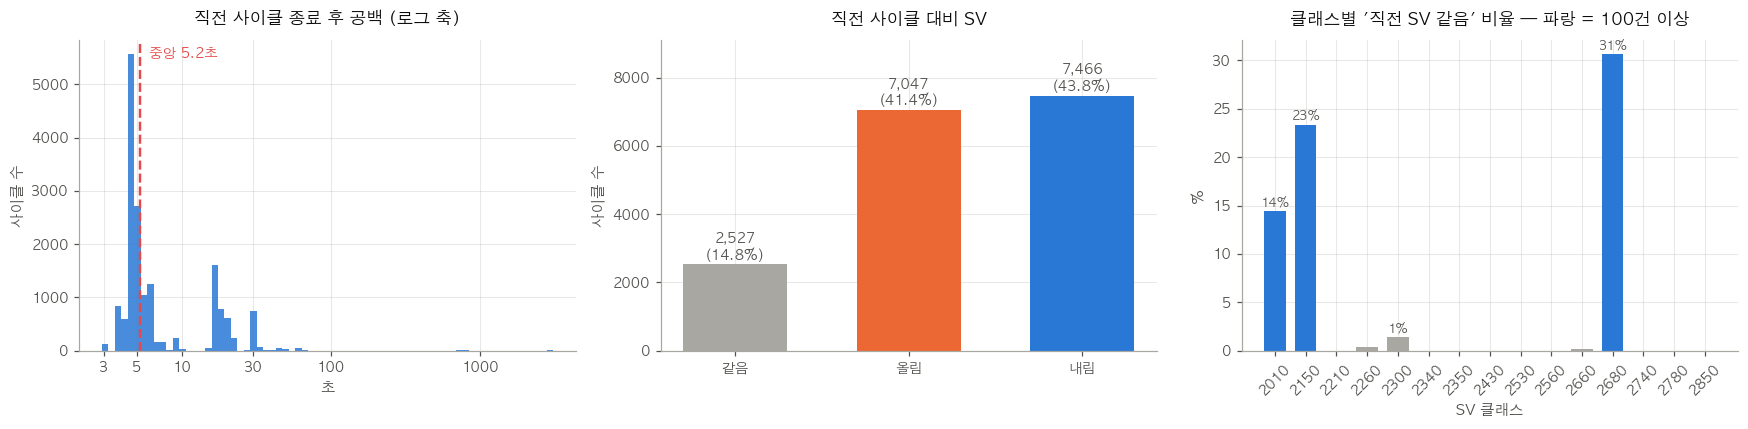


읽는 법
  · 직전 사이클은 대부분 몇 초 전에 끝났다 (중앙 5.2초). '직전 상태' 는 늘 존재한다
  · 그런데 SV 는 85% 가 바뀌고, 같은 경우는 2010/2150/2680 세 클래스에 몰려 있다 -> 같음 vs 다름 비교는 이 셋에서만 공정하다
  · 시작 직전 유량은 96% 가 1271~1300 사이 — 펌프가 꺼지면 유량계가 정지값으로 돌아가서 직전 사이클 유량이 남지 않는다


In [43]:
PV = K.loc[RC.index].copy()
PV["tc"] = RC["fixed"]
PV = PV[PV["tc"].notna()]
_dd = PV["Prev_SV_Diff"]
PV["직전"] = np.select([_dd == 0, _dd > 0], ["같음", "올림"], default="내림")

print(f"대상 {len(PV):,} 사이클\n")
gp = PV["Gap_Since_Last_Cycle_Sec"]
print("=== 직전 사이클 종료 후 공백 ===")
print(f"  중앙 {gp.median():.1f}초   p75 {gp.quantile(.75):.1f}   p95 {gp.quantile(.95):.1f}   최대 {gp.max():,.0f}")
for th in (5, 10, 30, 60):
    print(f"  {th:3d}초 이내 : {(gp <= th).mean()*100:5.1f}%")

print("\n=== 직전 SV 대비 ===")
_vc = PV["직전"].value_counts().reindex(["같음", "올림", "내림"])
for k_, v in _vc.items():
    print(f"  {k_} : {v:6,} ({v/len(PV)*100:4.1f}%)")
_ch = _dd[_dd != 0].abs()
print(f"  바뀐 경우 |변화량| : 중앙 {_ch.median():.0f}   p25 {_ch.quantile(.25):.0f}   "
      f"p75 {_ch.quantile(.75):.0f}   최대 {_ch.max():.0f}")

print("\n=== 시작 직전 유량 / 압력 ===")
pf = PV["PreBuildUp_FT"]
print(f"  PreBuildUp_FT : 정확히 1285 {(pf==1285).mean()*100:.1f}%   "
      f"1271~1300 {pf.between(1271,1300).mean()*100:.1f}%   그 밖 {(~pf.between(1271,1300)).mean()*100:.1f}%")
print(f"  PreBuildUp_PT : 평균 {PV['PreBuildUp_PT'].mean():.1f}   std {PV['PreBuildUp_PT'].std():.2f}   "
      f"범위 {PV['PreBuildUp_PT'].min():.0f}~{PV['PreBuildUp_PT'].max():.0f}")

same_rate = PV.groupby("SV_class")["직전"].apply(lambda s: (s == "같음").mean() * 100)
same_n    = PV.groupby("SV_class")["직전"].apply(lambda s: (s == "같음").sum())
print("\n=== 클래스별 '직전 SV 같음' 비율 ===")
print(pd.DataFrame({"n": PV.groupby("SV_class").size(), "같음 n": same_n,
                    "같음 %": same_rate.round(1)}).to_string())

fig, ax = plt.subplots(1, 3, figsize=(16, 4.0))
ax[0].hist(np.log10(gp.clip(lower=1)), bins=70, color=C1, alpha=.85)
ax[0].set_xticks(np.log10([3, 5, 10, 30, 100, 1000]), ["3", "5", "10", "30", "100", "1000"])
ax[0].axvline(np.log10(gp.median()), color=BAD, ls="--", lw=1.6)
ax[0].annotate(f"중앙 {gp.median():.1f}초", xy=(np.log10(gp.median()), 1.0),
               xycoords=("data", "axes fraction"), xytext=(6, -12),
               textcoords="offset points", color=BAD, fontsize=9)
ax_style(ax[0], "직전 사이클 종료 후 공백 (로그 축)", "초", "사이클 수")

ax[1].bar(range(3), _vc.values, color=[GRAY, C2, C1], width=.6)
ax[1].set_xticks(range(3), _vc.index)
for i, v in enumerate(_vc.values):
    ax[1].annotate(f"{v:,}\n({v/len(PV)*100:.1f}%)", xy=(i, v), xytext=(0, 3),
                   textcoords="offset points", ha="center", fontsize=9, color=INK2)
ax[1].set_ylim(0, _vc.max() * 1.22)
ax_style(ax[1], "직전 사이클 대비 SV", None, "사이클 수")

xp = np.arange(len(same_rate))
ax[2].bar(xp, same_rate.values, color=[C1 if n_ >= 100 else GRAY for n_ in same_n.values], width=.7)
ax[2].set_xticks(xp, [str(int(i)) for i in same_rate.index], rotation=45, fontsize=8)
for i, (v, n_) in enumerate(zip(same_rate.values, same_n.values)):
    if v > 0.5:
        ax[2].annotate(f"{v:.0f}%", xy=(i, v), xytext=(0, 3), textcoords="offset points",
                       ha="center", fontsize=8, color=INK2)
ax_style(ax[2], "클래스별 '직전 SV 같음' 비율 — 파랑 = 100건 이상", "SV 클래스", "%")
plt.tight_layout(); plt.show()

print("\n읽는 법")
print(f"  · 직전 사이클은 대부분 몇 초 전에 끝났다 (중앙 {gp.median():.1f}초). '직전 상태' 는 늘 존재한다")
print(f"  · 그런데 SV 는 {(_vc['올림']+_vc['내림'])/len(PV)*100:.0f}% 가 바뀌고, 같은 경우는 "
      f"2010/2150/2680 세 클래스에 몰려 있다 -> 같음 vs 다름 비교는 이 셋에서만 공정하다")
print(f"  · 시작 직전 유량은 {pf.between(1271,1300).mean()*100:.0f}% 가 1271~1300 사이 — "
      "펌프가 꺼지면 유량계가 정지값으로 돌아가서 직전 사이클 유량이 남지 않는다")

## 9-10. 직전 SV 가 같았을 때 vs 달랐을 때 — 통과시각이 다른가

**비교를 공정하게 하는 법**: 통과시각은 SV 에 따라 1.38 → 1.73초로 변한다(9-7).
"직전 SV 가 달랐던" 사이클이 고SV 쪽에 몰려 있으면 SV 효과가 직전 SV 효과로 둔갑한다.
그래서 **같은 SV 클래스 안에서만** 비교한다.

**그림 선택**
- (왼쪽) **덤벨** — 클래스마다 "같음" 평균과 "다름" 평균을 선으로 잇는다. 선이 짧으면 차이가 없다.
  95% 신뢰구간을 같이 그린다. 비교 대상이 둘(같음/다름)이라 덤벨이 가장 직접적이다
- (가운데) **분포 겹쳐 보기** — 평균만 같고 모양이 다를 수 있으므로, 클래스 평균을 뺀 잔차의
  분포를 같음/올림/내림 세 개로 겹친다
- (오른쪽) **변화량 구간별 평균 ± 95% CI** — "얼마나 올렸나/내렸나" 에 따라 달라지나


=== 같은 SV 클래스 안에서: 직전 SV 같음 vs 다름 (보정 통과시각, 초) ===
      같음_n      같음   같음_ci  다름_n      다름   다름_ci       차    효과크기       p
SV                                                                      
2010   514  1.4025  0.0227  3058  1.3738  0.0096 -0.0287 -0.1064  0.0228
2150   955  1.4669  0.0163  3131  1.4451  0.0095 -0.0217 -0.0808  0.0244
2680  1030  1.6353  0.0156  2335  1.6284  0.0109 -0.0069 -0.0259  0.4789

=== 같음 / 올림 / 내림 (클래스 평균과의 차, 초) ===
    size    mean  median     std
직전                              
같음  2527  0.0142  0.0004  0.2570
올림  7047 -0.0004 -0.0437  0.2704
내림  7466 -0.0044 -0.0050  0.2704
  잔차 전체 표준편차 0.269초 에 비해 그룹 간 차이는 평균 최대 0.019초 / 중앙값 최대 0.044초

=== Prev_SV_Diff 구간별 (클래스 내 잔차, 초) ===
           size    mean     std      ci
구간                                     
-400 이하    2996 -0.0112  0.2707  0.0097
-400~-200  2372  0.0011  0.2687  0.0108
-200~-1    2098 -0.0009  0.2719  0.0116
0 (같음)     2527  0.0142  0.2570  0.0100
1~200      1402 -0.0035  0.2703  0.014

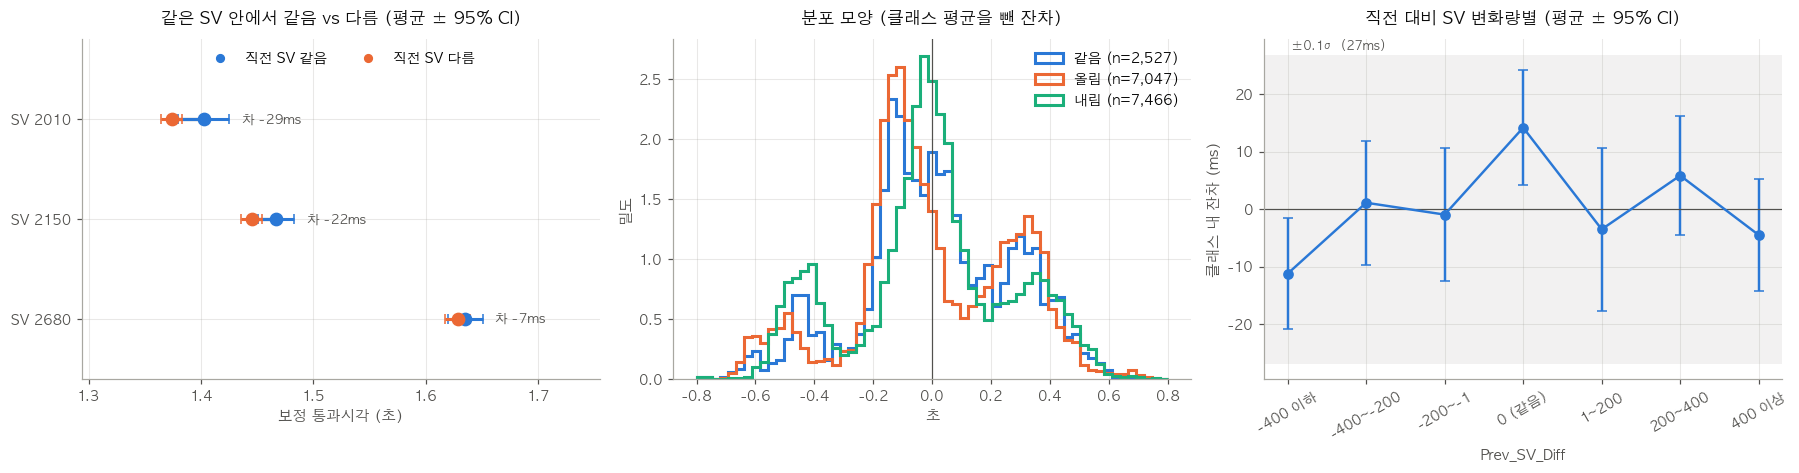

In [44]:
from scipy import stats as _st

def _within(s):
    return s - s.groupby(PV["SV_class"]).transform("mean")

PV["tc_res"] = _within(PV["tc"])            # 같은 SV 클래스 평균과의 차

# ---- 클래스별 같음 vs 다름 (양쪽 30건 이상인 클래스만) ----
rows = []
for sv, s in PV.groupby("SV_class"):
    a, b = s.loc[s["직전"] == "같음", "tc"], s.loc[s["직전"] != "같음", "tc"]
    if len(a) < 30 or len(b) < 30:
        continue
    ci = lambda x: 1.96 * x.std() / np.sqrt(len(x))
    rows.append(dict(SV=int(sv), 같음_n=len(a), 같음=a.mean(), 같음_ci=ci(a),
                     다름_n=len(b), 다름=b.mean(), 다름_ci=ci(b),
                     차=b.mean() - a.mean(), 효과크기=(b.mean()-a.mean())/s["tc"].std(),
                     p=_st.ttest_ind(a, b, equal_var=False).pvalue))
CMPv = pd.DataFrame(rows).set_index("SV")
print("=== 같은 SV 클래스 안에서: 직전 SV 같음 vs 다름 (보정 통과시각, 초) ===")
print(CMPv.round(4).to_string())

# ---- 같음/올림/내림 전체 (클래스 내 잔차) ----
print("\n=== 같음 / 올림 / 내림 (클래스 평균과의 차, 초) ===")
g3 = PV.groupby("직전")["tc_res"].agg(["size", "mean", "median", "std"]).reindex(["같음", "올림", "내림"])
print(g3.round(4).to_string())
print(f"  잔차 전체 표준편차 {PV['tc_res'].std():.3f}초 에 비해 그룹 간 차이는 "
      f"평균 최대 {g3['mean'].max()-g3['mean'].min():.3f}초 / 중앙값 최대 {g3['median'].max()-g3['median'].min():.3f}초")

# ---- 변화량 구간별 ----
edges = [-1000, -400, -200, -1, 0, 200, 400, 1000]
labels = ["-400 이하", "-400~-200", "-200~-1", "0 (같음)", "1~200", "200~400", "400 이상"]
PV["구간"] = pd.cut(PV["Prev_SV_Diff"], edges, labels=labels)
gb = PV.groupby("구간", observed=True)["tc_res"].agg(["size", "mean", "std"])
gb["ci"] = 1.96 * gb["std"] / np.sqrt(gb["size"])
print("\n=== Prev_SV_Diff 구간별 (클래스 내 잔차, 초) ===")
print(gb.round(4).to_string())

fig, ax = plt.subplots(1, 3, figsize=(16.5, 4.4))
# 덤벨
yp = np.arange(len(CMPv))[::-1]
for y, (sv, r_) in zip(yp, CMPv.iterrows()):
    ax[0].plot([r_["같음"], r_["다름"]], [y, y], color=GRAY, lw=2.2, zorder=1)
    ax[0].errorbar(r_["같음"], y, xerr=r_["같음_ci"], fmt="o", color=C1, ms=8, capsize=3, zorder=3)
    ax[0].errorbar(r_["다름"], y, xerr=r_["다름_ci"], fmt="o", color=C2, ms=8, capsize=3, zorder=3)
    ax[0].annotate(f"차 {r_['차']*1000:+.0f}ms", xy=(max(r_["같음"]+r_["같음_ci"], r_["다름"]+r_["다름_ci"]), y),
                   xytext=(8, 0), textcoords="offset points", va="center", fontsize=8.5, color=INK2)
ax[0].set_yticks(yp, [f"SV {i}" for i in CMPv.index])
ax[0].plot([], [], "o", color=C1, label="직전 SV 같음")
ax[0].plot([], [], "o", color=C2, label="직전 SV 다름")
ax[0].legend(frameon=False, fontsize=9, loc="upper center", ncol=2, bbox_to_anchor=(.5, 1.0))
_lo = min(CMPv["같음"].min(), CMPv["다름"].min()); _hi = max(CMPv["같음"].max(), CMPv["다름"].max())
ax[0].set_xlim(_lo - .08, _hi + .12); ax[0].set_ylim(-.6, len(CMPv) - .2)
ax_style(ax[0], "같은 SV 안에서 같음 vs 다름 (평균 ± 95% CI)", "보정 통과시각 (초)", None)

# 분포
_bins = np.linspace(-.8, .8, 60)
for k_, c in [("같음", C1), ("올림", C2), ("내림", C3)]:
    ax[1].hist(PV.loc[PV["직전"] == k_, "tc_res"].clip(-.8, .8), bins=_bins, density=True,
               histtype="step", lw=2, color=c, label=f"{k_} (n={int((PV['직전']==k_).sum()):,})")
ax[1].axvline(0, color=INK2, lw=.8)
ax[1].legend(frameon=False, fontsize=9, loc="upper right")
ax_style(ax[1], "분포 모양 (클래스 평균을 뺀 잔차)", "초", "밀도")

# 구간별
xg = np.arange(len(gb))
ax[2].errorbar(xg, gb["mean"] * 1000, yerr=gb["ci"] * 1000, fmt="o-", color=C1,
               ms=6, capsize=3, lw=1.6)
ax[2].axhline(0, color=INK2, lw=.8)
_sd = PV["tc_res"].std() * 1000
ax[2].axhspan(-_sd * .1, _sd * .1, color=GRAY, alpha=.15, lw=0)
ax[2].annotate(f"±0.1σ ({_sd*.1:.0f}ms)", xy=(0, _sd*.1), xytext=(2, 3),
               textcoords="offset points", fontsize=8, color=INK2)
ax[2].set_xticks(xg, gb.index, rotation=30, fontsize=8.5)
ax_style(ax[2], "직전 대비 SV 변화량별 (평균 ± 95% CI)", "Prev_SV_Diff", "클래스 내 잔차 (ms)")
plt.tight_layout(); plt.show()

## 9-11. 한 번에 확인 — 직전 상태 변수 전부와의 관계

같은 SV 클래스 안에서, 통과시각 잔차와 직전 상태 변수 각각의 상관을 본다.
그리고 SV 클래스만 넣었을 때와 직전 상태를 전부 추가했을 때의 설명력(R²)을 비교한다.

**그림 선택**: 변수 6개의 상관 크기 비교 → **수평 막대**, 0 을 가운데 둔다.
"거의 0 이다" 를 보이는 게 목적이므로 **|r| = 0.1** 을 참고선으로 긋는다
(`r = 0.1` 이면 분산의 1% 를 설명하는 수준이다).


=== 같은 SV 클래스 안에서: 통과시각 잔차와의 상관 ===
  Prev_SV_Diff (SV 변화량)          r = +0.014   (설명 0.02%)
  Prev_SV (직전 SV 값)              r = -0.014   (설명 0.02%)
  PreBuildUp_FT (시작 직전 유량)       r = +0.026   (설명 0.07%)
  PreBuildUp_PT (시작 직전 압력)       r = +0.033   (설명 0.11%)
  log 공백 (직전 종료 후)               r = -0.040   (설명 0.16%)
  Temp_mean (참고: 외생)             r = -0.029   (설명 0.09%)

=== 통과시각 설명력 R² ===
  SV 클래스만            0.1111
  + 직전 SV 변화량        0.1115
  + 직전 FT·PT·공백      0.1148
  직전 상태를 전부 더해 늘어난 설명력 : +0.37%p


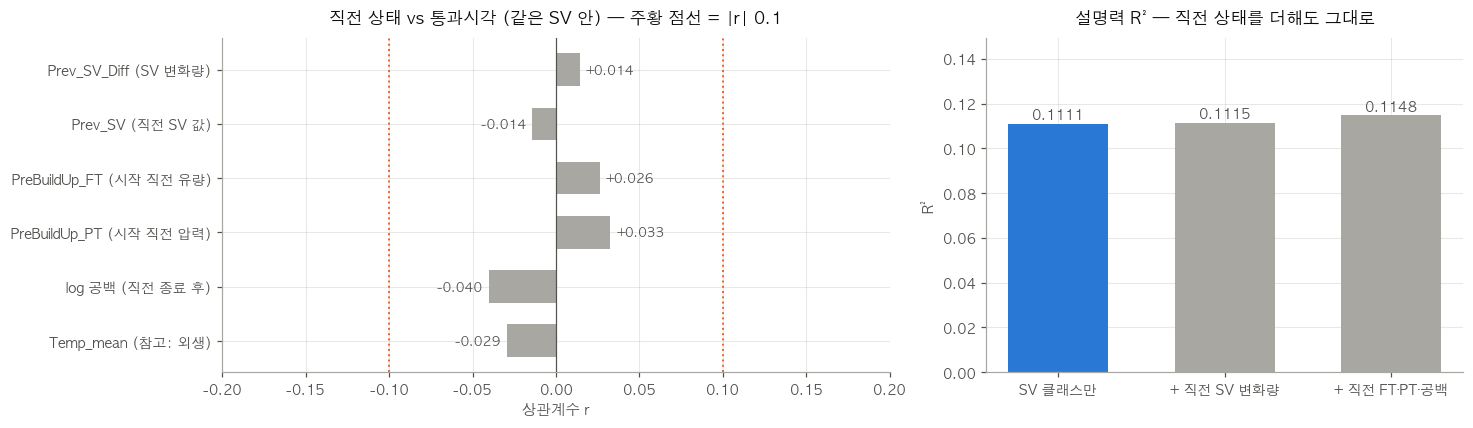

In [45]:
from sklearn.linear_model import LinearRegression

PREV = {"Prev_SV_Diff (SV 변화량)": PV["Prev_SV_Diff"],
        "Prev_SV (직전 SV 값)": PV["Prev_SV"],
        "PreBuildUp_FT (시작 직전 유량)": PV["PreBuildUp_FT"],
        "PreBuildUp_PT (시작 직전 압력)": PV["PreBuildUp_PT"],
        "log 공백 (직전 종료 후)": np.log10(PV["Gap_Since_Last_Cycle_Sec"].clip(lower=.1)),
        "Temp_mean (참고: 외생)": PV["Temp_mean"]}
rr = pd.Series({k_: PV["tc_res"].corr(_within(v.astype(float))) for k_, v in PREV.items()})
print("=== 같은 SV 클래스 안에서: 통과시각 잔차와의 상관 ===")
for k_, v in rr.items():
    print(f"  {k_:30s} r = {v:+.3f}   (설명 {v*v*100:.2f}%)")

def _r2(X):
    X = X.copy(); X.columns = X.columns.astype(str)
    return LinearRegression().fit(X, PV["tc"]).score(X, PV["tc"])
X0 = pd.get_dummies(PV["SV_class"].astype(int).astype(str), drop_first=True).astype(float)
X1 = X0.assign(dSV=PV["Prev_SV_Diff"].values, up=(PV["Prev_SV_Diff"] > 0).astype(float).values)
X2 = X1.assign(pFT=PV["PreBuildUp_FT"].values, pPT=PV["PreBuildUp_PT"].values,
               gap=np.log10(PV["Gap_Since_Last_Cycle_Sec"].clip(lower=.1)).values)
R2 = pd.Series({"SV 클래스만": _r2(X0), "+ 직전 SV 변화량": _r2(X1),
                "+ 직전 FT·PT·공백": _r2(X2)})
print("\n=== 통과시각 설명력 R² ===")
for k_, v in R2.items():
    print(f"  {k_:18s} {v:.4f}")
print(f"  직전 상태를 전부 더해 늘어난 설명력 : {(R2.iloc[-1]-R2.iloc[0])*100:+.2f}%p")

fig, ax = plt.subplots(1, 2, figsize=(13.5, 4.0), gridspec_kw={"width_ratios": [1.4, 1]})
yp = np.arange(len(rr))[::-1]
ax[0].barh(yp, rr.values, color=[C1 if abs(v) >= .1 else GRAY for v in rr.values], height=.6)
ax[0].set_yticks(yp, rr.index, fontsize=9)
for y, v in zip(yp, rr.values):
    ax[0].annotate(f"{v:+.3f}", xy=(v, y), xytext=(4 if v >= 0 else -4, 0),
                   textcoords="offset points", va="center",
                   ha="left" if v >= 0 else "right", fontsize=8.5, color=INK2)
for x_ in (-.1, .1):
    ax[0].axvline(x_, color=C2, ls=":", lw=1.3)
ax[0].axvline(0, color=INK2, lw=.8)
ax[0].set_xlim(-.2, .2)
ax_style(ax[0], "직전 상태 vs 통과시각 (같은 SV 안) — 주황 점선 = |r| 0.1", "상관계수 r", None)

ax[1].bar(range(len(R2)), R2.values, color=[C1, GRAY, GRAY], width=.6)
ax[1].set_xticks(range(len(R2)), R2.index, fontsize=8.5)
for i, v in enumerate(R2.values):
    ax[1].annotate(f"{v:.4f}", xy=(i, v), xytext=(0, 3), textcoords="offset points",
                   ha="center", fontsize=9, color=INK2)
ax[1].set_ylim(0, R2.max() * 1.3)
ax_style(ax[1], "설명력 R² — 직전 상태를 더해도 그대로", None, "R²")
plt.tight_layout(); plt.show()

### 9-12. 결론 — 직전 SV · FT 와는 관련이 없다

| 확인 | 결과 |
|---|---|
| 직전 상태 변수 6개와의 상관 (같은 SV 안) | **전부 \|r\| < 0.04** (설명 0.2% 미만) |
| 직전 SV 같음 / 올림 / 내림 차이 | 평균 최대 **0.019초**, 중앙값 최대 **0.044초** (잔차 표준편차 0.269초 대비 작음) |
| 같은 클래스 안 같음 vs 다름 | 2010 / 2150 / 2680 에서 차이 **−7 ~ −29ms** |
| 직전 상태 전부 추가 시 R² | **+0.37%p** (0.111 → 0.115) |

2010 / 2150 에서 p < 0.05 가 나오긴 하는데, 표본이 수천 개라 **아주 작은 차이도 유의하게** 나온 것이다.
효과크기로는 0.1σ 안팎이라 실용적 의미가 없다.

**왜 관련이 없나 — 매번 같은 출발선에서 시작하기 때문이다.**

- 직전 사이클은 **중앙 5.2초 전**에 끝나는데, 그 사이 펌프가 완전히 멈추고
  유량계가 정지값으로 돌아간다. 시작 직전 유량의 **96% 가 1271~1300** 사이다
- 그래서 **"직전에 많이 토출했으면 조금만 올리면 된다"** 는 상황 자체가 생기지 않는다.
  올릴 거리는 언제나 `SV − 약 1285` 이고, 그건 현재 SV 만의 함수다
- 직전 SV 도 마찬가지 — 이미 끝나서 흔적이 안 남은 사이클의 설정값이다

> **예외 조건.** 만약 공정이 바뀌어 사이클 사이 공백이 짧아지거나(< 1초), 펌프가 완전히
> 멈추지 않고 저속 대기하게 되면 이 결론은 달라진다. 그때는 `PreBuildUp_FT` 가 다양해지고
> 직전 상태가 의미를 갖게 된다. 이 설비의 현재 운전 방식에서만 성립하는 결론이다.

### 그래서 보간 통과시각을 쓸 때

- **입력으로 필요한 건 현재 사이클의 SV 하나뿐**이다. 직전 상태로 보정할 필요 없다
- SV 의존(1.38 → 1.73초)은 AE 가 `SV_mean` 입력으로 흡수한다 (7장)
- **주의**: 9-10 가운데 그림을 보면 잔차 분포에 봉우리가 여러 개다 (−0.45 / −0.1 / 0 / +0.35초 부근).
  틱 격자는 벗어났지만 **FT 기록 간격(0.5~1초)의 흔적이 아직 남아 있다.**
  3단계뿐이던 기존 값보다는 훨씬 촘촘하지만 완전히 연속적인 값은 아니다
- 한 가지 참고: SV 가 설명하는 건 통과시각 분산의 **11%** 뿐이다. 나머지 89% 는
  사이클마다 흩어지는 몫(표준편차 0.26초)이다. 이게 순수 잡음인지 설비 상태가 섞인 건지는
  더 긴 구간의 추세를 봐야 알 수 있다


---
# 10. 틱 AE 의 구간 정의 — 증압은 어디서 끝나나

틱 AE 의 상태는 4개다: **증압 / 안정 / 복귀 / idle**.
idle 은 학습에서 빼고 인코딩상 `(0,0,0)` (4개 범주를 dummy 로 하나 떨어뜨린 것과 같다).

문제는 **증압 → 안정 경계**다. 지금까지는 `|FT−SV|/SV ≤ 5%` (목표권 진입)를 썼는데
**5% 는 검증된 숫자가 아니다.** 대안은 **곡선이 꺾이는 지점** — 펌프가 세게 미는 걸 멈추는 곳이다.

확인할 것

| | 질문 |
|---|---|
| 10-1 | 증압 곡선은 실제로 어떤 모양인가 (FT 와 PT 가 같이 움직이나) |
| 10-2 | 5% 라는 숫자를 바꾸면 증압 끝이 얼마나 달라지나 |
| 10-3 | 꺾임 기준과 5% 기준은 어디서 어긋나나 |

**꺾임의 정의** — 실제로 FT 가 기록된 점만 써서 점과 점 사이 기울기를 구하고,
최대 기울기가 나온 뒤 **처음으로 최대 기울기의 20% 아래로 떨어진 구간의 시작점**을 증압 끝으로 본다.
SV 를 전혀 쓰지 않고 **그 사이클 자기 곡선만**으로 정해진다.

**정규화** — 사이클마다 "자기 안정값"(사이클 후반부 중앙값)을 1, 시작값을 0 으로 놓는다.
5% 기준과 무관하게 곡선 모양만 보기 위해서다.


사이클 17,077개

=== 10-1. 틱별 '자기 안정값 대비 상승률'  중앙 [p10 ~ p90] ===
  0틱   FT  0.00 [ 0.00 ~  0.00]    PT  0.00 [ 0.00 ~  0.00]
  1틱   FT  0.05 [ 0.00 ~  0.44]    PT  1.00 [ 0.88 ~  1.25]
  2틱   FT  0.56 [ 0.16 ~  0.95]    PT  1.02 [ 0.91 ~  1.20]
  3틱   FT  0.96 [ 0.65 ~  1.00]    PT  1.01 [ 0.70 ~  1.18]
  4틱   FT  1.00 [ 0.98 ~  1.02]    PT  0.99 [ 0.00 ~  1.14]
  5틱   FT  1.00 [ 0.99 ~  1.02]    PT  0.98 [ 0.00 ~  1.13]
  6틱   FT  1.00 [ 0.99 ~  1.02]    PT  1.00 [ 0.59 ~  1.15]


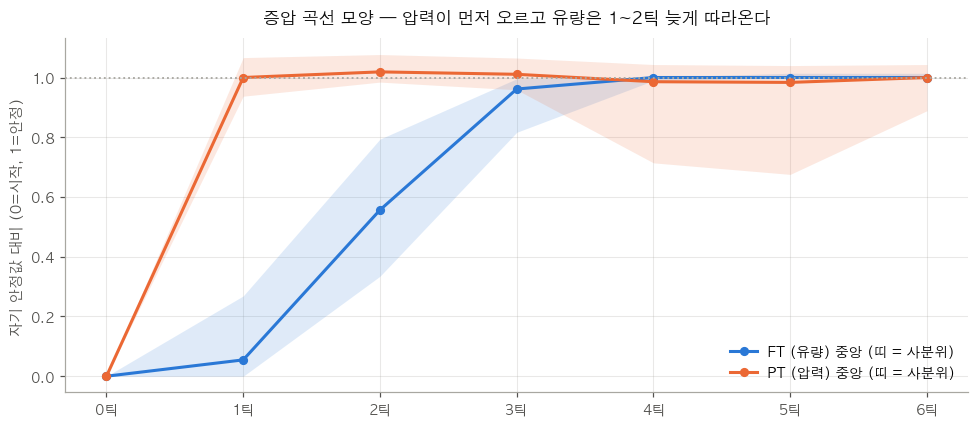

In [46]:
_rows, _pf, _pp = [], [], []
for cid, seg in _dr[_bur == 1].groupby("cid"):
    if cid not in K.index or len(seg) < 10:
        continue
    sv = seg[TAG_SV].iloc[0]
    ft = seg[TAG_FT].values.astype(float)
    pt = seg[TAG_PT].values.astype(float)
    tt = (seg["Time"] - seg["Time"].iloc[0]).dt.total_seconds().values
    n = len(ft); tail = slice(n // 2, n)
    ftp, ptp = np.median(ft[tail]), np.median(pt[tail])          # 자기 안정값
    rf = (ft - ft[0]) / (ftp - ft[0]) if ftp > ft[0] else np.full(n, np.nan)
    rp = (pt - pt[0]) / (ptp - pt[0]) if ptp > pt[0] else np.full(n, np.nan)
    _pf.append(np.pad(rf[:8], (0, max(0, 8 - n)), constant_values=np.nan))
    _pp.append(np.pad(rp[:8], (0, max(0, 8 - n)), constant_values=np.nan))

    def first_idx(mask):
        return int(np.argmax(mask)) if mask.any() else -1
    r = dict(cid=cid, SV=K.loc[cid, "SV_class"], plat_sv=ftp / sv)
    for q in (2, 5, 10):
        r[f"sv{q}"] = first_idx(np.abs(ft - sv) / sv <= q / 100)
    for q in (80, 90, 95, 98):
        r[f"self{q}"] = first_idx(rf >= q / 100)
    r["pt90"] = first_idx(rp >= .9)
    r["t_sv5"] = tt[r["sv5"]] if r["sv5"] >= 0 else np.nan
    rec = np.r_[True, np.diff(ft) != 0]                           # 실제 기록점만
    ti, fi = tt[rec], ft[rec]
    if len(ti) >= 3:
        sl = np.diff(fi) / np.diff(ti); m = int(np.argmax(sl))
        for q in (10, 20, 30, 50):
            a = np.where(sl[m:] < q / 100 * sl[m])[0]
            r[f"knee{q}"] = ti[m + a[0]] if len(a) else np.nan
    _rows.append(r)
RD = pd.DataFrame(_rows)
PF, PP = np.array(_pf), np.array(_pp)
print(f"사이클 {len(RD):,}개\n")

print("=== 10-1. 틱별 '자기 안정값 대비 상승률'  중앙 [p10 ~ p90] ===")
for i in range(7):
    print(f"  {i}틱   FT {np.nanmedian(PF[:,i]):5.2f} [{np.nanpercentile(PF[:,i],10):5.2f} ~ {np.nanpercentile(PF[:,i],90):5.2f}]"
          f"    PT {np.nanmedian(PP[:,i]):5.2f} [{np.nanpercentile(PP[:,i],10):5.2f} ~ {np.nanpercentile(PP[:,i],90):5.2f}]")

fig, ax = plt.subplots(figsize=(9, 4))
xi = np.arange(7)
for arr, nm, c in [(PF, "FT (유량)", C1), (PP, "PT (압력)", C2)]:
    med = np.nanmedian(arr[:, :7], 0)
    ax.fill_between(xi, np.nanpercentile(arr[:, :7], 25, 0), np.nanpercentile(arr[:, :7], 75, 0),
                    color=c, alpha=.15, lw=0)
    ax.plot(xi, med, color=c, lw=2, marker="o", ms=5, label=f"{nm} 중앙 (띠 = 사분위)")
ax.axhline(1, color=GRAY, ls=":", lw=1.2)
ax.set_xticks(xi, [f"{i}틱" for i in xi])
ax.legend(frameon=False, fontsize=9, loc="lower right")
ax_style(ax, "증압 곡선 모양 — 압력이 먼저 오르고 유량은 1~2틱 늦게 따라온다",
         None, "자기 안정값 대비 (0=시작, 1=안정)")
plt.tight_layout(); plt.show()

## 10-2. 숫자를 바꾸면 증압 끝이 얼마나 달라지나

기준 숫자를 여러 개로 바꿔서 **증압이 끝나는 틱**의 분포를 나란히 본다.
기준에 따라 분포가 크게 바뀌면 숫자 선택이 결과를 좌우한다는 뜻이고,
거의 같으면 곡선이 가파르게 꺾여서 어느 숫자를 써도 같은 틱이 나온다는 뜻이다.

**그림 선택**: 기준 × 틱 비율 → **누적 가로 막대** (부분-전체).
틱 2/3/4/5 네 계열은 검증된 팔레트 순서대로, 기타는 회색.


=== 기준별 '증압 끝 틱' 분포 (%) ===
                1     2     3     4     5   기타
SV ±2%        0.1   7.4  39.0  45.2   8.3  0.0
SV ±5% (현재)   0.2  15.1  48.1  35.2   1.5  0.0
SV ±10%       0.5  26.3  51.5  21.6   0.1  0.0
자기안정값 80%     0.3  24.0  52.6  23.1   0.0  0.0
자기안정값 90%     0.2  14.4  48.7  35.8   0.9  0.0
자기안정값 95%     0.1   9.4  43.8  42.8   4.0  0.0
자기안정값 98%     0.1   5.2  35.9  47.5  10.4  0.9
PT 안정값 90%   85.8  11.8   1.0   0.1   0.1  1.1

=== 현재 5% 기준과 같은 틱이 나오는 비율 ===
  SV ±2%           같은 틱  80.9%   ±1틱 이내  87.5%
  SV ±10%          같은 틱  82.2%   ±1틱 이내  89.5%
  자기안정값 80%        같은 틱  84.7%   ±1틱 이내  91.1%
  자기안정값 90%        같은 틱  96.0%   ±1틱 이내  98.0%
  자기안정값 95%        같은 틱  88.4%   ±1틱 이내  93.0%
  자기안정값 98%        같은 틱  75.0%   ±1틱 이내  82.7%
  PT 안정값 90%       같은 틱   2.0%   ±1틱 이내  20.4%


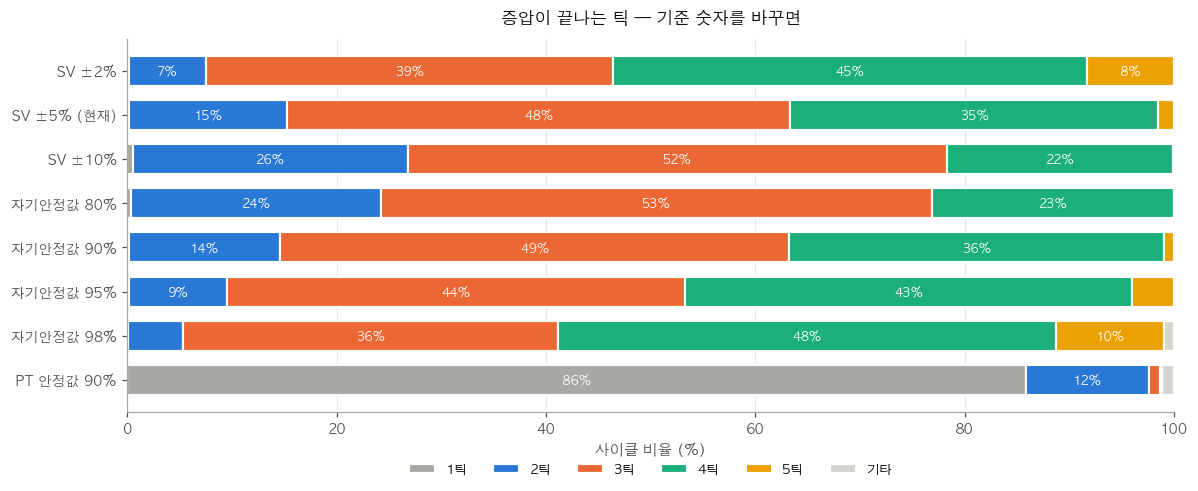

In [47]:
DEFS = [("sv2", "SV ±2%"), ("sv5", "SV ±5% (현재)"), ("sv10", "SV ±10%"),
        ("self80", "자기안정값 80%"), ("self90", "자기안정값 90%"),
        ("self95", "자기안정값 95%"), ("self98", "자기안정값 98%"), ("pt90", "PT 안정값 90%")]
dist = {}
for col, nm in DEFS:
    s = RD[col][RD[col] >= 0]
    vc = s.value_counts(normalize=True) * 100
    dist[nm] = {k: vc.get(k, 0.0) for k in (1, 2, 3, 4, 5)}
    dist[nm]["기타"] = 100 - sum(dist[nm].values())
DT = pd.DataFrame(dist).T
print("=== 기준별 '증압 끝 틱' 분포 (%) ===")
print(DT.round(1).to_string())

print("\n=== 현재 5% 기준과 같은 틱이 나오는 비율 ===")
for col, nm in DEFS:
    if col == "sv5": continue
    ok = (RD[col] >= 0) & (RD["sv5"] >= 0)
    same = (RD[col][ok] == RD["sv5"][ok]).mean() * 100
    near = ((RD[col][ok] - RD["sv5"][ok]).abs() <= 1).mean() * 100
    print(f"  {nm:16s} 같은 틱 {same:5.1f}%   ±1틱 이내 {near:5.1f}%")

fig, ax = plt.subplots(figsize=(11, 4.6))
yp = np.arange(len(DT))[::-1]; left = np.zeros(len(DT))
pal = {1: GRAY, 2: C1, 3: C2, 4: C3, 5: "#eda100", "기타": "#d6d5d0"}
for col in [1, 2, 3, 4, 5, "기타"]:
    v = DT[col].values
    ax.barh(yp, v, left=left, color=pal[col], height=.68, edgecolor="white", linewidth=1.4,
            label=f"{col}틱" if col != "기타" else "기타")
    for y, l, w in zip(yp, left, v):
        if w >= 6:
            ax.annotate(f"{w:.0f}%", xy=(l + w/2, y), ha="center", va="center",
                        fontsize=8, color="white", fontweight="bold")
    left += v
ax.set_yticks(yp, DT.index, fontsize=9); ax.set_xlim(0, 100)
ax.legend(frameon=False, fontsize=8.5, ncol=6, loc="lower center", bbox_to_anchor=(.5, -.2))
ax_style(ax, "증압이 끝나는 틱 — 기준 숫자를 바꾸면", "사이클 비율 (%)", None)
plt.tight_layout(); plt.show()

## 10-3. 꺾임 기준과 5% 기준은 어디서 어긋나나

두 기준은 뜻이 다르다.

| 기준 | 묻는 것 | 기준점 |
|---|---|---|
| 5% (목표권 진입) | **목표 유량에 도달했나** | SV (외부 지시값) |
| 꺾임 | **펌프가 세게 미는 걸 멈췄나** | 자기 곡선의 최대 기울기 |

곡선이 목표 근처에서 한 번에 꺾이면 둘이 같은 곳을 가리키고,
**목표에 닿기 전에 이미 눕기 시작하면**(9-5 의 막판 감속) 꺾임이 먼저 온다.
그 어긋남이 SV 에 따라 어떻게 분포하는지 본다.

**그림 선택**: (왼쪽) 꺾임 기준 숫자 10/20/30/50% 에 따른 일치율 — **선**.
(오른쪽) SV 클래스별로 "꺾임이 0.3초 이상 먼저 오는" 비율 — **막대**.


=== 꺾임 기준 숫자별: 5% 진입 시각과 0.3초 이내로 맞는 비율 ===
  최대 기울기의 10%   꺾임 중앙 1.573초   일치  86.4%
  최대 기울기의 20%   꺾임 중앙 1.562초   일치  82.7%
  최대 기울기의 30%   꺾임 중앙 1.555초   일치  76.1%
  최대 기울기의 50%   꺾임 중앙 1.544초   일치  64.5%
  (5% 진입 중앙 1.579초)
  꺾임 10% vs 20% 같은 시각 88.2%   20% vs 30% 91.9%

=== SV 클래스별 '꺾임이 5% 진입보다 0.3초 넘게 먼저' 비율 ===
         n  먼저비율
SV              
2010  3570  12.5
2150  4086  13.2
2210   122  10.7
2260   884  14.4
2300  1645  15.7
2340   126  13.5
2350  1071  15.6
2430   167  18.0
2530    61  13.1
2560    99  20.2
2660   906  19.1
2680  3365  22.1
2740   690  23.9
2780   178  21.9
2850    64  35.9
  corr(SV, 먼저비율) = +0.825


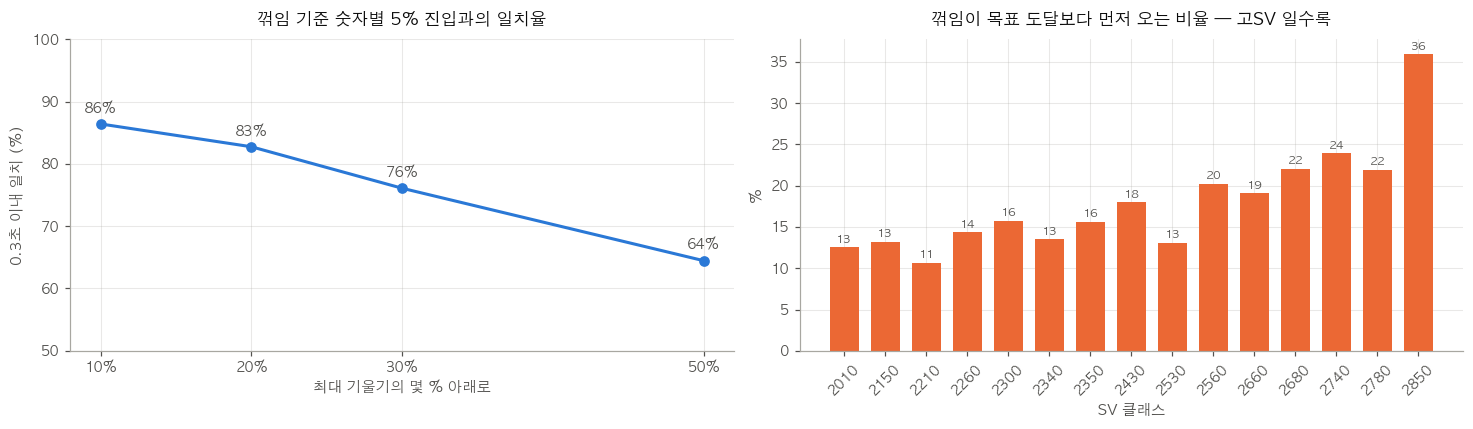

In [48]:
print("=== 꺾임 기준 숫자별: 5% 진입 시각과 0.3초 이내로 맞는 비율 ===")
agree = {}
for q in (10, 20, 30, 50):
    dd = RD[f"knee{q}"] - RD["t_sv5"]
    agree[q] = (dd.abs() <= .3).mean() * 100
    print(f"  최대 기울기의 {q:2d}%   꺾임 중앙 {RD[f'knee{q}'].median():.3f}초   일치 {agree[q]:5.1f}%")
print(f"  (5% 진입 중앙 {RD['t_sv5'].median():.3f}초)")
print(f"  꺾임 10% vs 20% 같은 시각 {(RD.knee10 == RD.knee20).mean()*100:.1f}%   "
      f"20% vs 30% {(RD.knee20 == RD.knee30).mean()*100:.1f}%")

RD["knee_early"] = (RD["knee20"] - RD["t_sv5"]) < -0.3
KE = RD.groupby("SV").agg(n=("knee_early", "size"),
                          먼저비율=("knee_early", lambda s: s.mean() * 100))
KE = KE[KE["n"] >= 50]
print("\n=== SV 클래스별 '꺾임이 5% 진입보다 0.3초 넘게 먼저' 비율 ===")
print(KE.round(1).to_string())
print(f"  corr(SV, 먼저비율) = {np.corrcoef(KE.index, KE['먼저비율'])[0,1]:+.3f}")

fig, ax = plt.subplots(1, 2, figsize=(13.5, 4.0))
qs = list(agree)
ax[0].plot(qs, [agree[q] for q in qs], color=C1, lw=2, marker="o", ms=6)
for q in qs:
    ax[0].annotate(f"{agree[q]:.0f}%", xy=(q, agree[q]), xytext=(0, 7),
                   textcoords="offset points", ha="center", fontsize=9, color=INK2)
ax[0].set_xticks(qs, [f"{q}%" for q in qs]); ax[0].set_ylim(50, 100)
ax_style(ax[0], "꺾임 기준 숫자별 5% 진입과의 일치율", "최대 기울기의 몇 % 아래로", "0.3초 이내 일치 (%)")

xp = np.arange(len(KE))
ax[1].bar(xp, KE["먼저비율"], color=C2, width=.7)
ax[1].set_xticks(xp, [str(int(i)) for i in KE.index], rotation=45, fontsize=8)
for i, v in enumerate(KE["먼저비율"]):
    ax[1].annotate(f"{v:.0f}", xy=(i, v), xytext=(0, 3), textcoords="offset points",
                   ha="center", fontsize=7.5, color=INK2)
ax_style(ax[1], "꺾임이 목표 도달보다 먼저 오는 비율 — 고SV 일수록", "SV 클래스", "%")
plt.tight_layout(); plt.show()

## 10-4. 결론 — 증압 끝은 꺾임 기준으로

**1. 곡선 모양: 압력이 먼저, 유량이 1~2틱 늦게**

| 틱 | FT (자기 안정값 대비) | PT |
|---|---|---|
| 1 | **0.05** — 거의 안 움직임 | **1.00** — 이미 다 오름 |
| 2 | 0.56 | 1.02 |
| 3 | 0.96 | 1.01 |
| 4 | 1.00 | 0.99 |

펌프가 켜지면 **압력이 첫 틱에 바로** 오르고, 유량은 한 틱 쉬었다가 두 틱에 걸쳐 따라온다.
PT 로 증압을 정의하면 증압이 1틱짜리가 돼 버린다. **증압 경계는 FT 곡선으로 잡아야 한다.**
(증압 첫 틱에 FT 가 거의 안 움직이는 구동 지연은 "구간 내 경과시간" 피처가 흡수한다.)

**2. 5% 라는 숫자는 결과를 크게 좌우하지 않는다 — 곡선이 가파르게 꺾이기 때문**

2틱에 56% → 3틱에 96% 로 급하게 오르고 바로 평평해지므로, 어지간한 기준이면 대부분 3틱이 나온다.
5% 대신 2~10% 나 자기 안정값 80~95% 를 써도 **같은 틱이 81~96%, ±1틱 이내가 88~98%** 다.

**3. 그래도 꺾임 기준으로 바꾸는 게 맞다 — 고장 났을 때 무너지지 않기 때문**

두 기준이 어긋나는 사이클은 **고SV 에 몰려 있다** (SV 2010 13% → 2850 36%, corr +0.825).
목표에 닿기 전에 곡선이 눕기 시작하는, 9-5 의 포화 구간이다.

결정적인 차이는 **펌프가 약해졌을 때**다.

- 5% 기준: 토출 능력이 떨어져 안정값이 `0.95·SV` 아래로 내려가면 **목표권에 영영 못 들어간다.**
  그러면 사이클 전체가 "증압" 으로 붙는다. **이상 자체가 구간 라벨을 망가뜨려서**,
  AE 는 "증압 중이니 FT 가 낮은 게 정상" 이라고 보고 이상을 놓친다
- 꺾임 기준: SV 를 안 쓰고 자기 곡선만 보므로 **안정값이 낮아져도 곡선이 눕는 순간 안정으로 넘어간다.**
  그러면 안정 구간에서 `(SV−FT)/SV` 가 평소보다 크게 나오고, AE 가 그걸 잡는다

지금 데이터에서는 5% 미진입이 0% 라 이 차이가 안 보이지만, **잡으려는 게 바로 그 상황**이다.

**4. 역할 분담**

| 무엇 | 기준 | 어디에 |
|---|---|---|
| 틱 AE 의 증압 → 안정 경계 | **꺾임** (최대 기울기의 10~20% 아래) | 구간 one-hot |
| "목표에 얼마 만에 도달했나" | **목표권 진입** (보간 통과시각) | 사이클 AE 피처 |

꺾임과 목표 도달 사이의 느린 접근 구간은 틱 AE 에서는 "안정" 으로 들어가
오차율이 높게 보이고, 사이클 AE 에서는 `t_cross` 가 길어지는 것으로 나타난다. 둘 다 정보가 남는다.

**남는 한계**

- 꺾임 기준에도 숫자(최대 기울기의 몇 %)가 있다. 다만 SV 가 아닌 **자기 곡선 기준**이라 설비 상태와 무관하고,
  10% ↔ 20% 88%, 20% ↔ 30% 92% 가 같은 시각이 나온다. 최종 값은 틱 AE 를 만들 때 구간 분리가 가장 깨끗한 쪽으로 고른다
- 증압은 FT 기록점 2~3개로 끝나서, 꺾임 위치의 정밀도는 **기록점 하나(0.5~1초)** 수준이다. 어느 기준이든 같은 한계다
- 실시간에서는 **다음 FT 기록점이 들어와야** 기울기가 떨어진 걸 안다. 경계 판정이 0.5~1초 늦는다


---
# 11. 목표권 기준 5% 검증

증압에 관한 개념은 두 개이고, **서로 다른 질문이라 같은 기준을 쓸 필요가 없다.**

| | 묻는 것 | 기준 | 쓰는 곳 |
|---|---|---|---|
| **목표 도달 시각** (`t_cross`) | 지시한 유량에 언제 닿았나 | SV 대비 ±p% — **여기서 p 를 검증** | 사이클 AE |
| **꺾임 시각** | 펌프가 세게 미는 걸 언제 멈췄나 | 자기 곡선 기울기 (10장) | 틱 AE 구간 경계, 추진시간 피처 |

## 기준 p 가 만족해야 할 조건

"정답 숫자" 가 따로 있는 게 아니라, 목표권 기준이 제 역할을 하려면 지켜야 할 조건이 있다.

1. **정상 사이클은 여유 있게 들어가야 한다** — 안정값이 선보다 충분히 안쪽에 있어야 한다.
   아니면 정상인데도 미진입(NaN)이 나와 타임아웃 오경보가 된다
2. **한번 들어가면 머물러야 한다** — 들어갔다 나갔다 하면 "도달" 이 "안정" 을 뜻하지 않는다.
   사출 때는 FT 가 원래 튀므로(설명서 5-2) 사출 후 4틱은 빼고 센다
3. **펌프가 약해지면 잘 드러나야 한다** — 이 피처를 쓰는 목적 자체

3번은 실제 고장 기록이 없으므로 **가상 열화**로 본다.
증압 상승폭을 δ 만큼 줄인다: `FT'(t) = FT₀ + (1−δ)·(FT(t) − FT₀)`.
올라가는 힘과 도달하는 안정값이 같이 δ 만큼 약해지는, **토출 능력 저하**를 흉내 낸 것이다.
그때 `t_cross` 가 **클래스 내 표준편차 몇 배(σ)** 움직이는지를 본다. 많이 움직일수록 잘 잡힌다.


사이클 17,080개

=== 조건 1·2 : 들어가나 / 머무르나 (사출 후 4틱 제외) ===
        진입률%  재이탈 틱%  재이탈 사이클%  t_cross 중앙  클래스내 σ
기준                                                
1%    97.137  25.243    48.189       2.051   0.554
2%   100.000   0.089     0.322       1.710   0.292
3%   100.000   0.021     0.105       1.547   0.281
4%   100.000   0.036     0.181       1.513   0.274
5%   100.000   0.019     0.094       1.480   0.268
7%   100.000   0.015     0.076       1.408   0.261
10%  100.000   0.019     0.105       1.288   0.253

=== 클래스별 안정값 / SV ===
           n      중앙     p05
SV                          
2010.0  3570  0.9955  0.9925
2150.0  4086  0.9916  0.9898
2210.0   122  0.9919  0.9914
2260.0   884  0.9909  0.9889
2300.0  1645  0.9909  0.9883
2340.0   126  0.9923  0.9863
2350.0  1071  0.9881  0.9881
2430.0   167  0.9918  0.9887
2530.0    61  0.9874  0.9874
2560.0    99  0.9926  0.9871
2660.0   906  0.9883  0.9870
2680.0  3365  0.9886  0.9866
2740.0   692  0.9894  0.9861
2780.0   179  0.9878  0.9850

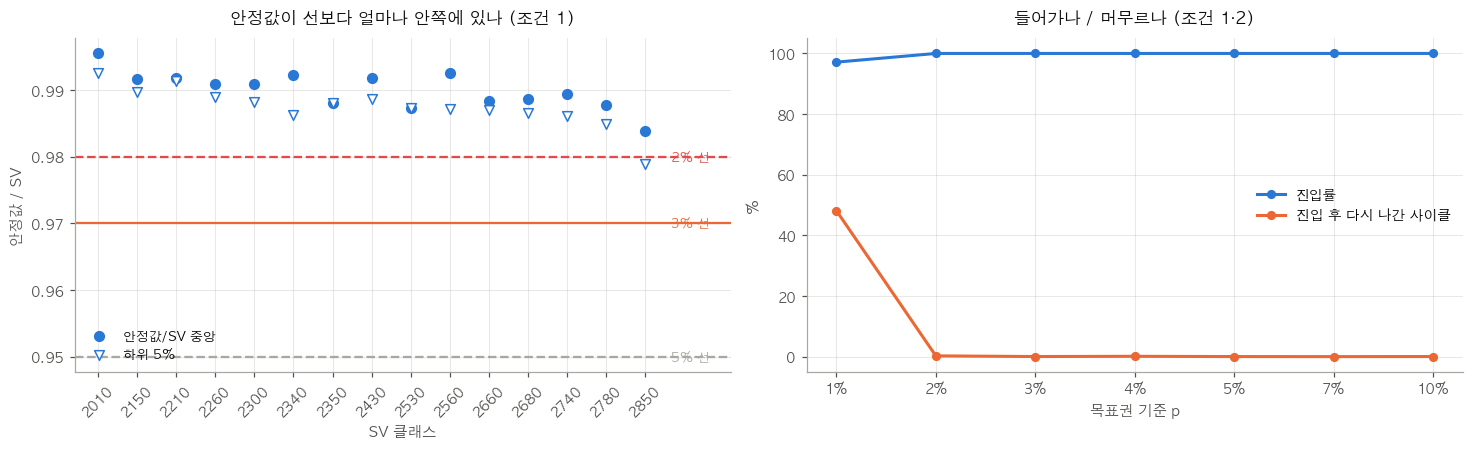

In [49]:
# ==========================================
# 사이클별 배열 (틱 시각, FT, SV, 사출 영향 여부)
# ==========================================
_inj = (raw[f"Shot_Injection_{HEAD}_P{SLOT}"].ffill().fillna(0) != 0).values
_spread = _inj.copy()
for k in range(1, INJECTION_DIP_TICKS + 1):
    _spread[k:] |= _inj[:-k]
_dr["shot"] = _spread

CY = []
for cid, seg in _dr[_bur == 1].groupby("cid"):
    if cid not in K.index or len(seg) < 8:
        continue
    CY.append(dict(SV=float(K.loc[cid, "SV_class"]), sv=float(seg[TAG_SV].iloc[0]),
                   t=(seg["Time"] - seg["Time"].iloc[0]).dt.total_seconds().values,
                   ft=seg[TAG_FT].values.astype(float), shot=seg["shot"].values))
print(f"사이클 {len(CY):,}개\n")

def crossing(t, ft, sv, p):
    """ramp_crossing_time 과 같고, 진입 틱 j 도 같이 돌려준다."""
    inside = np.abs(ft - sv) <= p * sv
    if not inside.any():
        return np.nan, -1
    j = int(np.argmax(inside))
    if j == 0:
        return 0.0, 0
    k = j - 1
    while k > 0 and ft[k] == ft[k - 1]:
        k -= 1
    L = (1 + p) * sv if ft[k] > (1 + p) * sv else (1 - p) * sv
    if ft[j] == ft[k]:
        return t[j], j
    return t[k] + (L - ft[k]) / (ft[j] - ft[k]) * (t[j] - t[k]), j

PS = [.01, .02, .03, .04, .05, .07, .10]
BASE, rows = {}, []
for p in PS:
    tc, cls, reach, out_n, in_n, cyc_out = [], [], 0, 0, 0, 0
    for c in CY:
        v, j = crossing(c["t"], c["ft"], c["sv"], p)
        tc.append(v); cls.append(c["SV"])
        if j < 0:
            continue
        reach += 1
        aft = slice(j + 1, len(c["ft"]))
        o = (np.abs(c["ft"][aft] - c["sv"]) > p * c["sv"])[~c["shot"][aft]]
        out_n += o.sum(); in_n += len(o); cyc_out += bool(o.any())
    s, cl = pd.Series(tc), pd.Series(cls)
    wstd = (s - s.groupby(cl).transform("mean")).std()
    BASE[p] = dict(tc=s, cls=cl, wstd=wstd)
    rows.append({"기준": f"{p*100:.0f}%", "진입률%": reach/len(CY)*100,
                 "재이탈 틱%": out_n/max(in_n, 1)*100, "재이탈 사이클%": cyc_out/max(reach, 1)*100,
                 "t_cross 중앙": s.median(), "클래스내 σ": wstd})
C12 = pd.DataFrame(rows).set_index("기준")
print("=== 조건 1·2 : 들어가나 / 머무르나 (사출 후 4틱 제외) ===")
print(C12.round(3).to_string())

PL = pd.DataFrame([dict(SV=c["SV"], plat=np.median(c["ft"][len(c["ft"])//2:]) / c["sv"]) for c in CY])
PQ = PL.groupby("SV")["plat"].agg(n="size", 중앙="median", p05=lambda s: s.quantile(.05))
PQ = PQ[PQ["n"] >= 50]
print("\n=== 클래스별 안정값 / SV ===")
print(PQ.round(4).to_string())
print(f"  가장 낮은 p05 : SV {int(PQ['p05'].idxmin())} 의 {PQ['p05'].min():.3f} "
      f"-> 선을 {(1-PQ['p05'].min())*100:.1f}% 보다 안쪽에 두면 정상 사이클 일부가 못 들어간다")

fig, ax = plt.subplots(1, 2, figsize=(13.5, 4.2))
xp = np.arange(len(PQ))
ax[0].scatter(xp, PQ["중앙"], color=C1, s=40, zorder=3, label="안정값/SV 중앙")
ax[0].scatter(xp, PQ["p05"], color=C1, s=40, marker="v", facecolors="white", zorder=3,
              label="하위 5%")
for p, c in [(.02, BAD), (.03, C2), (.05, GRAY)]:
    ax[0].axhline(1 - p, color=c, ls="--" if p != .03 else "-", lw=1.5)
    ax[0].annotate(f"{p*100:.0f}% 선", xy=(len(PQ) - .5, 1 - p), xytext=(4, 0),
                   textcoords="offset points", va="center", fontsize=8.5, color=c)
ax[0].set_xticks(xp, [str(int(i)) for i in PQ.index], rotation=45, fontsize=8)
ax[0].set_xlim(-.6, len(PQ) + 1.2)
ax[0].legend(frameon=False, fontsize=8.5, loc="lower left")
ax_style(ax[0], "안정값이 선보다 얼마나 안쪽에 있나 (조건 1)", "SV 클래스", "안정값 / SV")

xq = np.arange(len(C12))
ax[1].plot(xq, C12["진입률%"], color=C1, lw=2, marker="o", label="진입률")
ax[1].plot(xq, C12["재이탈 사이클%"], color=C2, lw=2, marker="o", label="진입 후 다시 나간 사이클")
ax[1].set_xticks(xq, C12.index)
ax[1].legend(frameon=False, fontsize=9, loc="center right")
ax_style(ax[1], "들어가나 / 머무르나 (조건 1·2)", "목표권 기준 p", "%")
plt.tight_layout(); plt.show()

## 11-2. 가상 열화에 얼마나 민감한가 (조건 3)

기준을 좁힐수록 약해진 펌프가 선에 늦게 닿으니 `t_cross` 가 더 크게 움직인다.
대신 너무 좁히면 약간만 약해져도 아예 못 들어가(미진입) 버린다.
미진입은 그 자체로 강한 신호(타임아웃 알림)라 나쁜 건 아니지만, **정상 사이클이 미진입하면 오경보**다.

**그림 선택**: 기준 4개(2 / 3 / 5 / 10%) × 열화 정도 → **선 4개**. 4개는 검증된 팔레트 순서 안에 들고,
직접 라벨을 붙인다. 미진입률은 선 옆 숫자로 적는다.


=== 가상 열화 δ 에 따른 t_cross 이동 (σ) / 새로 생긴 미진입 (%) ===
   기준                 δ=1%                δ=2%                δ=3%                δ=5%
   1%      0.96σ  미진입 24.9%     1.38σ  미진입 45.1%     2.34σ  미진입 64.5%     4.40σ  미진입 88.4%
   2%      0.30σ  미진입  0.1%     1.42σ  미진입  2.9%     2.24σ  미진입 25.6%     3.98σ  미진입 63.2%
   3%      0.13σ  미진입  0.0%     0.30σ  미진입  0.0%     0.61σ  미진입  0.2%     2.20σ  미진입 25.1%
   4%      0.10σ  미진입  0.0%     0.22σ  미진입  0.0%     0.35σ  미진입  0.0%     0.82σ  미진입  0.2%
   5%      0.09σ  미진입  0.0%     0.18σ  미진입  0.0%     0.29σ  미진입  0.0%     0.54σ  미진입  0.0%
   7%      0.07σ  미진입  0.0%     0.14σ  미진입  0.0%     0.22σ  미진입  0.0%     0.39σ  미진입  0.0%
  10%      0.05σ  미진입  0.0%     0.11σ  미진입  0.0%     0.17σ  미진입  0.0%     0.29σ  미진입  0.0%


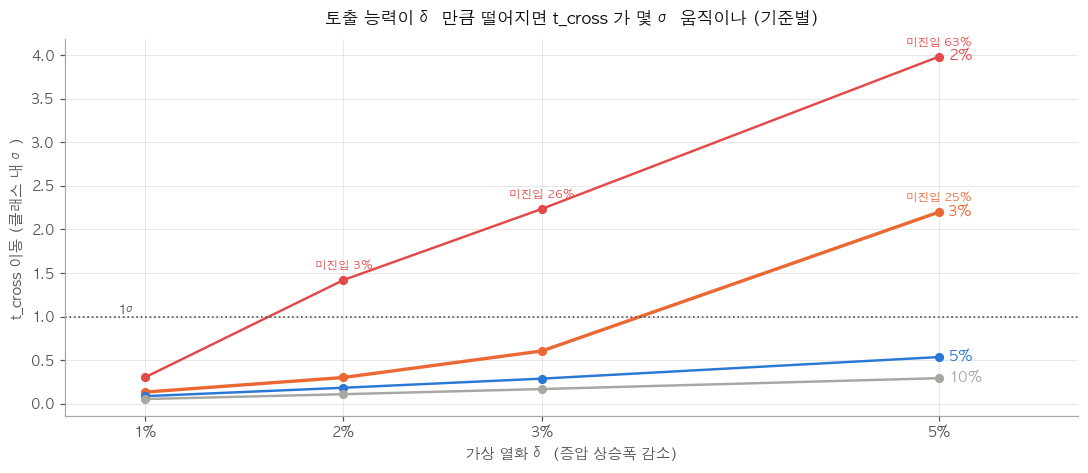

In [50]:
DLS = [.01, .02, .03, .05]
SENS = {}
for p in PS:
    b = BASE[p]
    SENS[p] = {}
    for dl in DLS:
        tc = []
        for c in CY:
            ft2 = c["ft"][0] + (1 - dl) * (c["ft"] - c["ft"][0])
            tc.append(crossing(c["t"], ft2, c["sv"], p)[0])
        s = pd.Series(tc); ok = s.notna() & b["tc"].notna()
        SENS[p][dl] = ((s[ok] - b["tc"][ok]).mean() / b["wstd"],
                       (s.isna() & b["tc"].notna()).mean() * 100)

print("=== 가상 열화 δ 에 따른 t_cross 이동 (σ) / 새로 생긴 미진입 (%) ===")
print(f"{'기준':>5s} " + "".join(f"{'δ='+str(int(d*100))+'%':>20s}" for d in DLS))
for p in PS:
    print(f"{p*100:4.0f}% " + "".join(f"{SENS[p][d][0]:9.2f}σ  미진입{SENS[p][d][1]:5.1f}%" for d in DLS))

fig, ax = plt.subplots(figsize=(10, 4.4))
for p, c in [(.02, BAD), (.03, C2), (.05, C1), (.10, GRAY)]:
    ys = [SENS[p][d][0] for d in DLS]
    ax.plot([d*100 for d in DLS], ys, color=c, lw=2.2 if p == .03 else 1.6, marker="o", ms=5)
    ax.annotate(f"{p*100:.0f}%", xy=(DLS[-1]*100, ys[-1]), xytext=(6, 0),
                textcoords="offset points", va="center", fontsize=9.5, color=c, fontweight="bold")
    for d, y in zip(DLS, ys):
        nn = SENS[p][d][1]
        if nn >= 1:
            ax.annotate(f"미진입 {nn:.0f}%", xy=(d*100, y), xytext=(0, 7),
                        textcoords="offset points", ha="center", fontsize=7.5, color=c)
ax.axhline(1, color=INK2, ls=":", lw=1.1)
ax.annotate("1σ", xy=(1, 1), xytext=(-18, 2), textcoords="offset points", fontsize=8.5, color=INK2)
ax.set_xticks([d*100 for d in DLS], [f"{int(d*100)}%" for d in DLS]); ax.set_xlim(.6, 5.7)
ax_style(ax, "토출 능력이 δ 만큼 떨어지면 t_cross 가 몇 σ 움직이나 (기준별)",
         "가상 열화 δ (증압 상승폭 감소)", "t_cross 이동 (클래스 내 σ)")
plt.tight_layout(); plt.show()

## 11-3. 결론 — 5% 는 안전하지만 둔감하다. 3% 가 낫다

**조건 1·2 — 하한은 2~3%**

| 기준 | 진입률 | 진입 후 다시 나간 사이클 | 판정 |
|---|---|---|---|
| 1% | 97.1% | **48.2%** | 불가 — 안정 상태의 흔들림보다 좁다 |
| 2% | 100% | 0.3% | 경계 — SV 2850 하위 5% 안정값(0.979)이 선(0.98) 바깥 |
| **3%** | 100% | 0.1% | **통과** — 가장 나쁜 클래스 하위 5% 에서도 0.9%p 여유 |
| 5% | 100% | 0.1% | 통과 — 여유 2.9~4.3%p |

안정값이 SV 보다 **0.4~1.6% 낮게** 형성되므로(고SV 일수록 낮음), 선을 2% 안쪽으로 당기면
고SV 정상 사이클이 들어가지 못하기 시작한다.

**조건 3 — 5% 는 너무 둔감하다**

| 가상 열화 | 5% 기준 | 3% 기준 |
|---|---|---|
| δ = 3% | 0.29σ | 0.61σ |
| δ = 5% | **0.54σ** | **2.20σ** (+ 미진입 25%) |

5% 기준에서는 증압 상승폭이 5% 줄어도 `t_cross` 가 **0.54σ** 밖에 안 움직인다.
사이클 하나로는 정상 흔들림과 구분이 안 된다. 선이 안정값보다 한참 아래에 있어서,
곡선이 약해져도 아직 가파른 구간에서 선을 넘어버리기 때문이다.

3% 에서는 같은 열화가 **2.20σ** 로 드러나고, 더 약해지면 미진입으로 넘어가 **타임아웃 알림**이 뜬다.
**선이 안정값에 가까울수록 약해진 곡선이 "막판 느린 구간" 에서 선을 넘게 되어 민감해진다** —
9-5 에서 본 고SV 의 막판 감속과 같은 원리다.

**→ 목표권 기준은 3% 로 한다.** 정상 사이클은 전부 여유 있게 들어가고, 민감도는 5% 의 2~4배다.

**남는 한계**

- 가상 열화는 "상승폭이 통째로 줄어드는" 한 가지 모양만 흉내 냈다. 실제 마모는 증압 속도만 느려지고
  안정값은 유지되는 식일 수도 있다. 실제 고장 이력이 생기면 다시 확인해야 한다
- 3% 의 여유는 SV 2850 (표본 64개) 하위 5% 에서 0.9%p 로 가장 좁다. 표본이 적어 불확실하다.
  운영 중 고SV 에서 정상 미진입이 나오면 3.5~4% 로 넓힌다
- 안정값/SV 가 SV 에 따라 다르므로(0.996 → 0.984), SV 하나의 비율로 선을 긋는 건 클래스마다 여유가 고르지 않다.
  대안은 **클래스별 기대 안정값 기준**으로 선을 긋는 것인데, 그러면 "SV 자체로 본다" 는 뜻에서 벗어난다


---
# 12. 압력 피처 — 켜지는 순간과 안정 구간

압력 신호는 세 시점에서 나온다. 이 장은 앞의 두 개를 본다 (꺼진 뒤는 복귀 구간으로 따로).

| 시점 | 후보 | 기대하는 의미 |
|---|---|---|
| 켜지는 순간 | `PT_Jump_From_Pre` (점프), 시작 오버슈트 | 릴리프 밸브·보상기 |
| 안정 구간 | `PT_mean`, `DeltaP_over_Q`, `Steady_Std_PT` | 유로 저항(막힘·마모), 헌팅·채터링 |
| 꺼진 뒤 | `Decay_Slope_PT` | 누설 — 다음에 |

**안정 구간의 정의**: 3% 목표권 진입 이후, **사출 영향 틱(사출 시작 +4틱) 제외**.
사출 때는 압력이 원래 떨어지므로(설명서 5-2) 섞으면 저항·흔들림 값이 사출 횟수에 끌려간다.
값은 그 구간의 중앙값.

## 12-1. 켜지는 순간 — 점프와 오버슈트


사이클 16,942   안정 틱(사출 제외) 중앙 6개

=== 켜지는 순간 ===
  점프 PT0 - P0                    중앙   18.0  p10    0.0  p90   38.0   η²(SV) 0.015   lag1 +0.280
  오버슈트 max(PT 0~2틱) - 안정PT       중앙    1.0  p10   -1.0  p90    3.0   η²(SV) 0.019   lag1 +0.020
  오버슈트의 크기: 안정 PT 의 2.9% (p90)


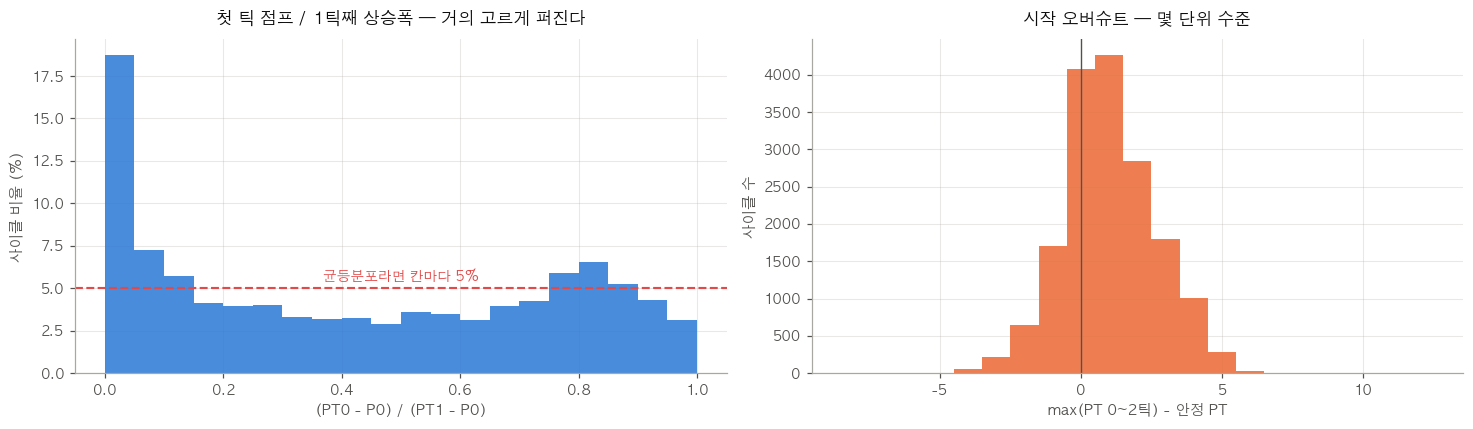

In [51]:
TAG_TEMP = f"TK_Temp_PV_{TANK}"
_rows = []
for cid, seg in _dr[_bur == 1].groupby("cid"):
    if cid not in K.index or len(seg) < 8:
        continue
    sv = float(seg[TAG_SV].iloc[0])
    ft = seg[TAG_FT].values.astype(float); pt = seg[TAG_PT].values.astype(float)
    sh = seg["shot"].values
    ins = np.abs(ft - sv) <= .03 * sv
    if not ins.any():
        continue
    j = int(np.argmax(ins))
    st = np.zeros(len(ft), bool); st[j:] = True
    stc = st & ~sh                                    # 안정 & 사출 제외
    if stc.sum() < 3:
        continue
    s2 = np.arange(len(ft)) >= 2                      # 기존 추출기의 '안정' 정의
    _rows.append(dict(cid=cid, SV=K.loc[cid, "SV_class"], Start=seg["Time"].iloc[0],
                      Temp=float(seg[TAG_TEMP].mean()), P0=float(K.loc[cid, "PreBuildUp_PT"]),
                      P=np.median(pt[stc]), Q=np.median(ft[stc]),
                      PT0=pt[0], PT1=pt[1], PTmax3=pt[:3].max(),
                      dpq_orig=np.nanmean(pt[s2] / np.where(ft[s2] == 0, np.nan, ft[s2])),
                      std_orig=pt[s2].std(ddof=1), std_clean=pt[stc].std(ddof=1),
                      n_shot=int(sh[s2].sum()), n_stable=int(stc.sum())))
PR = pd.DataFrame(_rows)
PR["jump"] = PR["PT0"] - PR["P0"]
PR["over"] = PR["PTmax3"] - PR["P"]
_rise1 = PR["PT1"] - PR["P0"]
PR["jump_frac"] = np.where(_rise1 > 5, PR["jump"] / _rise1, np.nan)
print(f"사이클 {len(PR):,}   안정 틱(사출 제외) 중앙 {PR['n_stable'].median():.0f}개\n")

def _wc(s): return s - s.groupby(PR["SV"]).transform("mean")
print("=== 켜지는 순간 ===")
for nm, s in [("점프 PT0 - P0", PR["jump"]), ("오버슈트 max(PT 0~2틱) - 안정PT", PR["over"])]:
    print(f"  {nm:30s} 중앙 {s.median():6.1f}  p10 {s.quantile(.1):6.1f}  p90 {s.quantile(.9):6.1f}   "
          f"η²(SV) {eta_squared(s, PR['SV']):.3f}   lag1 {_wc(s).autocorr(1):+.3f}")
print(f"  오버슈트의 크기: 안정 PT 의 {PR['over'].quantile(.9)/PR['P'].median()*100:.1f}% (p90)")

fig, ax = plt.subplots(1, 2, figsize=(13.5, 4.0))
jf = PR["jump_frac"].dropna().clip(0, 1)
ax[0].hist(jf, bins=20, range=(0, 1), color=C1, alpha=.85, weights=np.ones(len(jf)) / len(jf) * 100)
ax[0].axhline(5, color=BAD, ls="--", lw=1.4)
ax[0].annotate("균등분포라면 칸마다 5%", xy=(.5, 5), xytext=(0, 5), textcoords="offset points",
               ha="center", color=BAD, fontsize=9)
ax_style(ax[0], "첫 틱 점프 / 1틱째 상승폭 — 거의 고르게 퍼진다",
         "(PT0 - P0) / (PT1 - P0)", "사이클 비율 (%)")
ax[1].hist(PR["over"].clip(-8, 12), bins=np.arange(-8.5, 12.6, 1), color=C2, alpha=.85)
ax[1].axvline(0, color=INK2, lw=.9)
ax_style(ax[1], "시작 오버슈트 — 몇 단위 수준", "max(PT 0~2틱) - 안정 PT", "사이클 수")
plt.tight_layout(); plt.show()

### 12-1 판정 — 켜지는 순간의 압력은 지금 로깅 속도로는 못 쓴다

- **점프**: `(PT0 − P0)/(PT1 − P0)` 가 0~1 에 **거의 고르게** 퍼진다 (0 근처만 26%).
  압력은 0.5초 안에 다 오르는데(10-1), 첫 틱이 그 상승 중 **아무 시점에나** 찍히면 정확히 이 모양이 나온다.
  즉 점프 값은 설비가 아니라 **"첫 기록이 상승의 몇 % 지점에서 찍혔나"** 를 본다
- **오버슈트**: 중앙 1, p90 3 — 안정 압력의 **3% 안팎**이고 lag-1 0.02 로 잡음이다.
  켜질 때 압력이 치솟는 현상은 이 데이터에서 보이지 않는다

> 10장에서 "PT 가 1틱째 자기 안정값의 0.88~1.25배로 퍼진다" 고 했던 건 오버슈트가 아니었다.
> 그때 정규화의 기준점을 **0틱 PT** 로 잡았는데, 0틱 PT 자체가 위 이유로 들쭉날쭉해서 분모가 흔들린 결과다.

**→ `PT_Jump_From_Pre` 는 빼는 쪽이 맞다.** 켜지는 순간의 압력 동특성은 로깅이 지금보다 훨씬 촘촘해야(0.1초 수준) 보인다.

## 12-2. 유로 저항 — 어떤 형태로 계산할까

`DeltaP_over_Q` 는 "같은 유량을 내는 데 압력을 얼마나 썼나" 를 보려는 피처다.
그런데 확인할 게 두 가지 있다.

1. **펌프가 꺼져 있을 때도 PT 가 약 60 이다** (`PreBuildUp_PT`, 이하 P0). 이 바닥값을 빼야 "펌프가 만든 압력" 이 된다
2. 설명서는 "노즐은 `Δp ∝ Q²`" 라고 하면서 계산은 `PT/FT` 로 했다

후보들을 같은 기준으로 비교한다.

| 기준 | 뜻 |
|---|---|
| η²(SV) | 레시피에 끌려다니나 (작을수록 레시피 간 비교 가능) |
| Temp 상관 (클래스 내) | 온도에 끌려다니나 (작을수록 막힘·마모와 온도를 구분 가능) |
| lag-1, 일자 흔들림 | 느리게 변하는 성분이 남아 있나 |


=== 꺼진 상태의 압력 P0 는 무엇을 따라가나 ===
  P0 중앙 60.0   std 2.53   범위 52~76
  클래스 내 corr(P0 (꺼짐)   , Temp) = -0.593
  클래스 내 corr(PT (안정)   , Temp) = -0.611
  클래스 내 corr(PT - P0   , Temp) = -0.205

=== 유로 저항 후보 비교 ===
                       η²(SV)  클래스내 CV%  Temp 상관  lag-1  일자 흔들림σ
PT (안정 수준)              0.938     2.486   -0.611  0.884    1.711
DeltaP_over_Q (기존 정의)   0.280     3.371   -0.545  0.751    1.542
PT / FT                 0.105     2.640   -0.622  0.900    1.715
PT / FT²                0.905     2.774   -0.624  0.891    1.694
(PT - P0) / FT          0.903     4.330   -0.219  0.376    1.503
(PT - P0) / FT²         0.474     4.412   -0.229  0.371    1.481


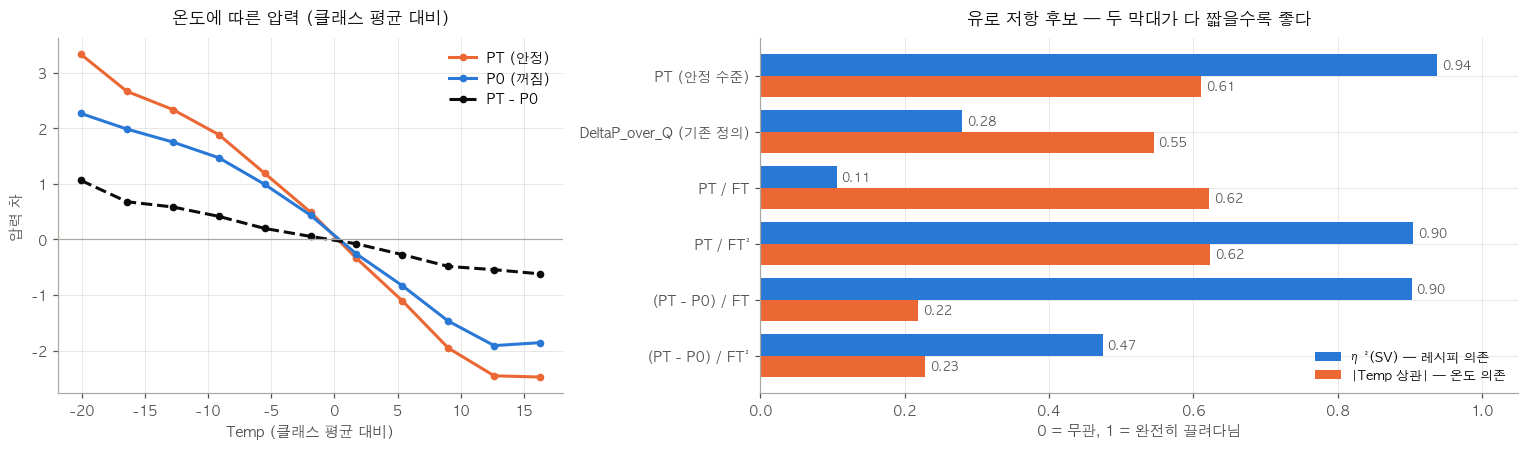

In [52]:
_day = pd.to_datetime(PR["Start"]).dt.normalize()
def _props(s):
    s = pd.Series(s).replace([np.inf, -np.inf], np.nan)
    w = _wc(s); dd = w.groupby(_day).mean()
    cv = (s.groupby(PR["SV"]).std() / s.groupby(PR["SV"]).mean()).median() * 100
    return {"η²(SV)": eta_squared(s, PR["SV"]), "클래스내 CV%": cv,
            "Temp 상관": w.corr(_wc(PR["Temp"])), "lag-1": w.autocorr(1),
            "일자 흔들림σ": (dd.max() - dd.min()) / w.std()}

print("=== 꺼진 상태의 압력 P0 는 무엇을 따라가나 ===")
print(f"  P0 중앙 {PR['P0'].median():.1f}   std {PR['P0'].std():.2f}   범위 {PR['P0'].min():.0f}~{PR['P0'].max():.0f}")
for nm, s in [("P0 (꺼짐)", PR["P0"]), ("PT (안정)", PR["P"]), ("PT - P0", PR["P"] - PR["P0"])]:
    print(f"  클래스 내 corr({nm:10s}, Temp) = {_wc(s).corr(_wc(PR['Temp'])):+.3f}")

CAND = {"PT (안정 수준)": PR["P"],
        "DeltaP_over_Q (기존 정의)": PR["dpq_orig"],
        "PT / FT": PR["P"] / PR["Q"],
        "PT / FT²": PR["P"] / (PR["Q"] / 1000) ** 2,
        "(PT - P0) / FT": (PR["P"] - PR["P0"]) / PR["Q"],
        "(PT - P0) / FT²": (PR["P"] - PR["P0"]) / (PR["Q"] / 1000) ** 2}
RT = pd.DataFrame({k: _props(v) for k, v in CAND.items()}).T
print("\n=== 유로 저항 후보 비교 ===")
print(RT.round(3).to_string())

fig, ax = plt.subplots(1, 2, figsize=(14, 4.2), gridspec_kw={"width_ratios": [1, 1.5]})
# 왼쪽: P0 가 온도 기준점 역할
_tw = _wc(PR["Temp"])
for s, nm, c in [(_wc(PR["P"]), "PT (안정)", C2), (_wc(PR["P0"]), "P0 (꺼짐)", C1)]:
    b = pd.cut(_tw, np.linspace(_tw.quantile(.02), _tw.quantile(.98), 12))
    m = s.groupby(b, observed=True).mean()
    ax[0].plot([iv.mid for iv in m.index], m.values, color=c, lw=2, marker="o", ms=4, label=nm)
_d = _wc(PR["P"] - PR["P0"]); b = pd.cut(_tw, np.linspace(_tw.quantile(.02), _tw.quantile(.98), 12))
m = _d.groupby(b, observed=True).mean()
ax[0].plot([iv.mid for iv in m.index], m.values, color=INK, lw=2, ls="--", marker="o", ms=4,
           label="PT - P0")
ax[0].axhline(0, color=GRAY, lw=.8)
ax[0].legend(frameon=False, fontsize=9)
ax_style(ax[0], "온도에 따른 압력 (클래스 평균 대비)", "Temp (클래스 평균 대비)", "압력 차")

# 오른쪽: 후보별 η²(SV) 와 |Temp 상관|
yy = np.arange(len(RT))[::-1]; h = .38
ax[1].barh(yy + h/2, RT["η²(SV)"], height=h, color=C1, label="η²(SV) — 레시피 의존")
ax[1].barh(yy - h/2, RT["Temp 상관"].abs(), height=h, color=C2, label="|Temp 상관| — 온도 의존")
ax[1].set_yticks(yy, RT.index, fontsize=9)
for y, a, b_ in zip(yy, RT["η²(SV)"], RT["Temp 상관"].abs()):
    ax[1].annotate(f"{a:.2f}", xy=(a, y + h/2), xytext=(3, 0), textcoords="offset points",
                   va="center", fontsize=8, color=INK2)
    ax[1].annotate(f"{b_:.2f}", xy=(b_, y - h/2), xytext=(3, 0), textcoords="offset points",
                   va="center", fontsize=8, color=INK2)
ax[1].set_xlim(0, 1.05)
ax[1].legend(frameon=False, fontsize=8.5, loc="lower right")
ax_style(ax[1], "유로 저항 후보 — 두 막대가 다 짧을수록 좋다", "0 = 무관, 1 = 완전히 끌려다님", None)
plt.tight_layout(); plt.show()

## 12-3. `Steady_Std_PT` — 흔들림인가 사출 횟수인가

`Steady_Std_PT` 는 "명령이 그대로인데 압력이 떨리는 정도" (헌팅·채터링) 를 보려는 피처다.
그런데 기존 정의는 `Tick_Index ≥ 2` 전체의 표준편차라 **사출 때 떨어지는 압력이 그대로 섞인다.**
그러면 흔들림이 아니라 **그 사이클에 사출이 몇 번 있었나** 를 세게 된다.


=== 안정 구간 PT 표준편차: 기존 정의 vs 사출 제외 ===
  기존 (Tick≥2, 사출 포함)  중앙 3.99
  사출 제외 (3% 진입 이후)  중앙 1.67
  corr(기존,     사출영향 틱수) = +0.321
  corr(사출 제외, 사출영향 틱수) = -0.002
  기존       η²(SV) 0.531   Temp상관 -0.183   lag-1 +0.132
  사출 제외    η²(SV) 0.003   Temp상관 -0.014   lag-1 +0.016
  (사출 제외 std 는 안정 틱 중앙 6개로 계산 — 표본이 작다)


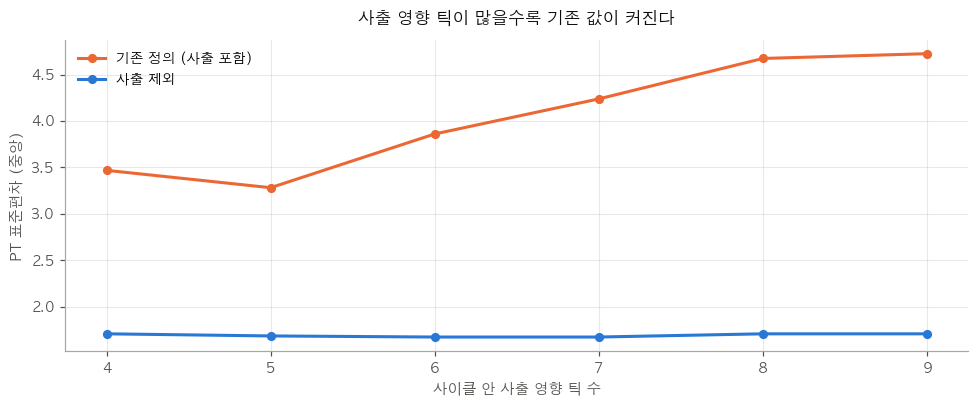

In [53]:
print("=== 안정 구간 PT 표준편차: 기존 정의 vs 사출 제외 ===")
print(f"  기존 (Tick≥2, 사출 포함)  중앙 {PR['std_orig'].median():.2f}")
print(f"  사출 제외 (3% 진입 이후)  중앙 {PR['std_clean'].median():.2f}")
print(f"  corr(기존,     사출영향 틱수) = {PR['std_orig'].corr(PR['n_shot']):+.3f}")
print(f"  corr(사출 제외, 사출영향 틱수) = {PR['std_clean'].corr(PR['n_shot']):+.3f}")
for nm, s in [("기존", PR["std_orig"]), ("사출 제외", PR["std_clean"])]:
    p = _props(s)
    print(f"  {nm:8s} η²(SV) {p['η²(SV)']:.3f}   Temp상관 {p['Temp 상관']:+.3f}   lag-1 {p['lag-1']:+.3f}")
print(f"  (사출 제외 std 는 안정 틱 중앙 {PR['n_stable'].median():.0f}개로 계산 — 표본이 작다)")

grp = PR.groupby("n_shot")[["std_orig", "std_clean"]].median()
cnt = PR["n_shot"].value_counts()
grp = grp[cnt.reindex(grp.index) >= 100]
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.plot(grp.index, grp["std_orig"], color=C2, lw=2, marker="o", label="기존 정의 (사출 포함)")
ax.plot(grp.index, grp["std_clean"], color=C1, lw=2, marker="o", label="사출 제외")
ax.legend(frameon=False, fontsize=9)
ax.set_xticks(grp.index)
ax_style(ax, "사출 영향 틱이 많을수록 기존 값이 커진다", "사이클 안 사출 영향 틱 수", "PT 표준편차 (중앙)")
plt.tight_layout(); plt.show()

## 12-4. 결론 — 압력 피처

**켜지는 순간 — 쓰지 않는다**

| 피처 | 판정 | 이유 |
|---|---|---|
| `PT_Jump_From_Pre` | **제외** | 첫 기록이 상승의 몇 % 지점에서 찍혔는지를 본다 (0~1 에 고르게 분포) |
| 시작 오버슈트 | 만들지 않음 | 안정 압력의 3% 안팎, lag-1 0.02 — 잡음 |

**유로 저항 — 두 가지 발견**

1. **꺼진 상태의 압력 P0 가 온도 기준점 역할을 한다.** P0 도 안정 PT 와 같은 정도로 온도를 따라간다
   (클래스 내 −0.59 vs −0.61). 그래서 `PT − P0` 로 빼면 온도 상관이 **−0.61 → −0.21** 로 줄어든다.
   온도를 따로 보정하지 않아도 **자기 사이클의 바닥 압력이 그 역할을 대신한다**
2. **기존 `DeltaP_over_Q` 는 계산 구간이 잘못됐다.** `Tick ≥ 2` 부터 평균이라 증압 틱과 사출 틱이 섞인다.
   같은 `PT/FT` 라도 3% 진입 이후·사출 제외로 다시 계산하면 η²(SV) 가 **0.28 → 0.105** 로 줄어든다

그런데 **레시피 무관(η²)과 온도 무관을 동시에 만족하는 형태는 없다**:

| 형태 | η²(SV) | Temp 상관 | 좋은 점 |
|---|---|---|---|
| `PT / FT` (재계산) | **0.105** | −0.62 | 레시피 간 비교 가능 |
| `(PT − P0) / FT²` | 0.474 | **−0.23** | 온도에 덜 흔들림 |

어느 쪽을 쓸지는 **어느 층에 쓰느냐**로 정한다.

| 층 | 쓰는 형태 | 이유 |
|---|---|---|
| **② 사이클 AE** | `PT` 안정 중앙값과 `P0` 를 **각각** 넣는다 | AE 입력에 SV·Temp 가 있어서 레시피·온도 의존을 스스로 흡수한다. 비율로 미리 묶을 필요가 없다 |
| **③ 추세** | `(PT − P0) / FT²` | 온도는 날마다·계절마다 흐르므로 추세에서 가장 큰 교란이다. 레시피 쪽은 클래스 내 편차로 보면 된다 |

**흔들림 — 사출을 빼고 다시 계산한다**

기존 `Steady_Std_PT` 의 중앙값 3.99 중 대부분이 사출 딥이었다. 사출을 빼면 **1.67**.
기존 값은 사출 영향 틱 수와 **+0.32** 상관 — 흔들림보다 사출 횟수를 더 많이 봤다. 빼면 **−0.002**.
다만 사출을 빼면 안정 틱이 중앙 6개만 남아, 표준편차 추정이 거칠다.

**그래서 사이클 AE 의 압력 피처는**

| 피처 | 정의 |
|---|---|
| `PT_Steady` | 3% 진입 이후, 사출 영향 틱 제외, PT 중앙값 |
| `PreBuildUp_PT` (P0) | 켜지기 직전 PT — **온도 기준점으로 유지** |
| `PT_Steady_Std` | 같은 구간 PT 표준편차 (사출 제외) |
| (추세 전용) `(PT_Steady − P0) / FT_Steady²` | AE 에는 안 넣음 |

`PT_mean`, `PT_max`, `DeltaP_over_Q`(기존), `Current_Proxy_I`, `PT_Jump_From_Pre` 는 위 것들로 대체된다.
`Decay_Slope_PT` 는 복귀 구간에서 따로 본다.


---
# 13. 압력이 안 오르거나 덜 오르면 실시간으로 잡히나

정상 데이터뿐이라 **정상 사이클의 압력(또는 유량) 상승을 α 배로 줄인 가상 고장**으로 본다.
`PT'(t) = P0 + α·(PT(t) − P0)` — 꺼진 상태 압력 P0 는 그대로 두고 올라가는 양만 줄인다.

압력이 안 오르는 경우는 두 종류다.

| 경우 | FT | PT | 예 |
|---|---|---|---|
| **A** 펌프가 제대로 안 돎 | 덜 오름 | 덜 오름 | 모터·인버터 |
| **B** 유량은 나오는데 압력만 | **정상** | 덜 오름 | 바이패스 열림·누설·센서 |

**B 는 FT 기준 규칙(3% 목표권, 타임아웃)으로는 원리상 못 잡는다.** 압력을 직접 봐야 한다.

**압력 체크 규칙** — 켜진 뒤 k 틱째까지:

```
상승률 = (지금까지의 PT 최대 − P0) / 그 SV 클래스의 평소 상승폭(PT_Steady − P0 의 중앙값)
임계값 = 정상 사이클 상승률의 하위 0.1%   (정상 오경보 0.1%)
```

참고로 PLC 에도 저압 알람(`Press_Low_Err_P1`, `Pump_In_Press_Low_Err_P1`)이 이미 있다.
18일간 한 번도 안 떴고 임계값은 모른다. 압력이 아예 안 오르는 큰 고장용일 것이다.


=== 정상 사이클 상승률 ===
  1틱째  임계값(하위 0.1%) 0.76
  3틱째  임계값(하위 0.1%) 0.86

=== 탐지율 (%) — 경우 A 는 전부, 경우 B 는 'FT 타임아웃' 을 뺀 나머지 ===
상승폭 α                 0%    30%    50%    70%    80%   90%
PT 1틱 (0.5초)       100.0  100.0  100.0   89.6   28.4   3.1
PT 3틱 (1.6초)       100.0  100.0  100.0   99.6   72.2   5.5
FT 타임아웃 (3초)       100.0  100.0  100.0  100.0  100.0  98.2
최근 10사이클 평균 (~2분)  100.0  100.0  100.0  100.0  100.0  87.6
최근 30사이클 평균 (~6분)  100.0  100.0  100.0  100.0  100.0  89.9

  사이클마다 원래 상승률이 흔들리는 폭: 표준편차 0.054 (±5%)


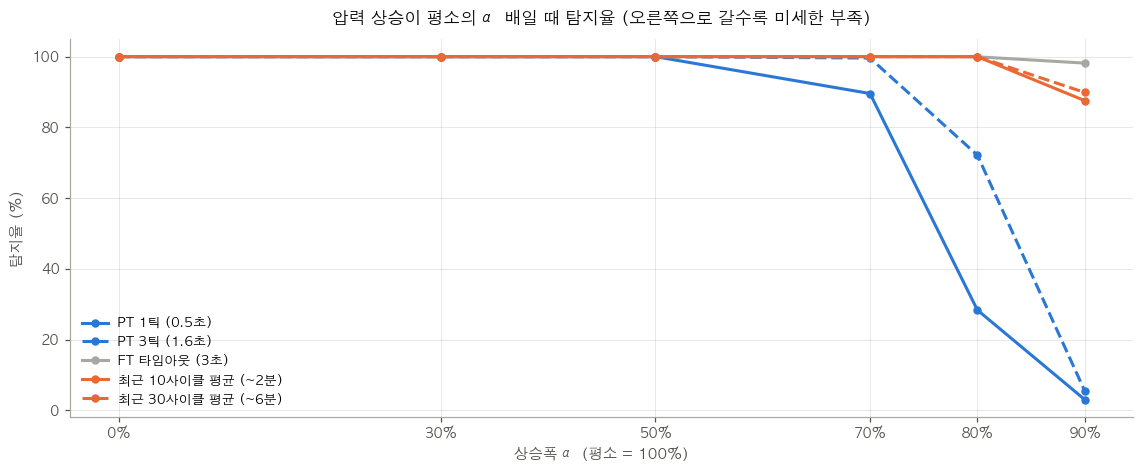

In [54]:
_rows = []
for cid, seg in _dr[_bur == 1].groupby("cid"):
    if cid not in K.index or len(seg) < 8:
        continue
    sv = float(seg[TAG_SV].iloc[0])
    ft = seg[TAG_FT].values.astype(float); pt = seg[TAG_PT].values.astype(float)
    tt = (seg["Time"] - seg["Time"].iloc[0]).dt.total_seconds().values
    ins = np.abs(ft - sv) <= .03 * sv
    if not ins.any():
        continue
    j = int(np.argmax(ins)); st = np.zeros(len(ft), bool); st[j:] = True; st &= ~seg["shot"].values
    if st.sum() < 3:
        continue
    _rows.append(dict(Start=seg["Time"].iloc[0], SV=K.loc[cid, "SV_class"],
                      P0=float(K.loc[cid, "PreBuildUp_PT"]), P=np.median(pt[st]),
                      pt=pt, ft=ft, t=tt, sv=sv))
PX = pd.DataFrame(_rows).sort_values("Start").reset_index(drop=True)
PX["E"] = PX["SV"].map((PX["P"] - PX["P0"]).groupby(PX["SV"]).median())

def _early(pt, P0, E, k):
    return (pt[1:k+1].max() - P0) / E

ALPHAS = [0.0, 0.3, 0.5, 0.7, 0.8, 0.9]
det = {}
thr = {}
for k in (1, 3):
    base = np.array([_early(r.pt, r.P0, r.E, k) for r in PX.itertuples()])
    thr[k] = np.quantile(base, .001)
    det[f"PT {k}틱 ({PX['t'].map(lambda a: a[k]).median():.1f}초)"] = [
        np.mean(np.array([_early(r.P0 + a*(r.pt - r.P0), r.P0, r.E, k) for r in PX.itertuples()]) < thr[k]) * 100
        for a in ALPHAS]
print("=== 정상 사이클 상승률 ===")
for k in (1, 3):
    print(f"  {k}틱째  임계값(하위 0.1%) {thr[k]:.2f}")

# FT 타임아웃 (경우 A 에서만 의미) — 유량도 α 배
to = []
for a in ALPHAS:
    hit = []
    for r in PX.itertuples():
        f2 = r.ft[0] + a * (r.ft - r.ft[0]); m = np.abs(f2 - r.sv) <= .03 * r.sv
        hit.append((not m.any()) or r.t[int(np.argmax(m))] > 3.0)
    to.append(np.mean(hit) * 100)
det["FT 타임아웃 (3초)"] = to

# 여러 사이클 평균 (지속되는 부족)
PX["s"] = (PX["P"] - PX["P0"]) / PX["E"]
for N in (10, 30):
    b = PX["s"].rolling(N).mean().dropna(); tq = b.quantile(.001)
    det[f"최근 {N}사이클 평균 (~{N*13/60:.0f}분)"] = [
        (((PX["P0"] + a*(PX["P"] - PX["P0"]) - PX["P0"]) / PX["E"]).rolling(N).mean().dropna() < tq).mean() * 100
        for a in ALPHAS]

DET = pd.DataFrame(det, index=[f"{a:.0%}" for a in ALPHAS]).T
DET.columns.name = "상승폭 α"
print("\n=== 탐지율 (%) — 경우 A 는 전부, 경우 B 는 'FT 타임아웃' 을 뺀 나머지 ===")
print(DET.round(1).to_string())
print(f"\n  사이클마다 원래 상승률이 흔들리는 폭: 표준편차 {PX['s'].std():.3f} (±{PX['s'].std()*100:.0f}%)")

fig, ax = plt.subplots(figsize=(10.5, 4.4))
xs = [a * 100 for a in ALPHAS]
style = {DET.index[0]: (C1, "-"), DET.index[1]: (C1, "--"), DET.index[2]: (GRAY, "-"),
         DET.index[3]: (C2, "-"), DET.index[4]: (C2, "--")}
for nm, (c, ls) in style.items():
    ax.plot(xs, DET.loc[nm].values, color=c, ls=ls, lw=2, marker="o", ms=4.5, label=nm)
ax.set_xticks(xs, [f"{int(x)}%" for x in xs])
ax.legend(frameon=False, fontsize=8.5, loc="lower left")
ax_style(ax, "압력 상승이 평소의 α 배일 때 탐지율 (오른쪽으로 갈수록 미세한 부족)",
         "상승폭 α (평소 = 100%)", "탐지율 (%)")
plt.tight_layout(); plt.show()

## 13-1. 결론 — 크게 부족하면 0.5초, 조금 부족하면 몇 분

| 부족한 정도 | 무엇으로 잡나 | 언제 |
|---|---|---|
| 아예 안 오름 ~ 30% 이상 부족 | **1틱째 압력 체크** | **0.5초** (70% 까지 오르면 90%) |
| 20% 부족 | 3틱째까지 압력 체크 | 1.6초까지 72% |
| **10% 부족 — 한 사이클** | **못 잡는다** | 정상 사이클끼리도 상승폭이 ±5% (하위 0.1% 는 −16%) 흔들린다 |
| **10% 부족 — 계속되면** | **최근 10사이클 평균** | 약 2분에 88% |
| 5% 부족 — 계속되면 | 최근 30~100사이클 평균 | 6~22분에 72~86% |
| 유량도 같이 부족 (경우 A) | **FT 타임아웃 (3% 목표권)** | 3초 — 10% 부족도 98% |

**핵심은 "한 사이클만으로 판단할 수 있는 한계" 가 있다는 것이다.**
사이클마다 원래 압력 상승폭이 다르고(온도, P0, 레시피 전환 등), 이 흔들림은
**사이클 안의 틱을 더 모아도 줄지 않는다** — 안정 구간 중앙값으로 5초까지 모아봐도 10% 부족은 5% 안팎만 잡혔다.
줄이려면 **사이클을 여러 개 모아야** 한다.

그래서 층마다 역할이 갈린다.

- **① 실시간** — 큰 이상. 압력 1틱 체크(0.5초)와 FT 타임아웃(3초)이 서로 못 보는 쪽을 메운다.
  압력만 문제면 앞의 것이, 유량이 문제면 뒤의 것이 잡는다
- **③ 추세의 짧은 창** — 조금이지만 계속되는 이상. 10~30 사이클(2~7분) 이동평균.
  "추세 층 = 몇 주짜리" 가 아니라 **몇 분 창도 추세 층의 일부**로 두면 된다

**틱 AE 는?** 틱 AE 입력에 `PT`, `SV`, 구간, 경과시간이 있으니 원리상 같은 걸 배운다.
다만 한 사이클 안에서 판단한다는 점은 같아서, **10% 수준의 미세한 부족은 틱 AE 도 한 사이클로는 못 잡을 것**이다.
위의 단순 규칙이 틱 AE 가 적어도 넘어야 할 기준선이 된다.

**가정과 한계**
- 가상 고장은 "상승폭이 통째로 α 배" 한 가지 모양이다. 실제로는 오르는 속도만 느리거나 흔들리며 오를 수 있다
- 임계값은 정상 오경보 0.1% 로 잡았다. 사이클이 하루 3,000 개라 **하루 약 3번 오경보**다. 1틱 체크처럼
  사이클마다 도는 규칙은 오경보를 더 낮게(0.01%) 잡거나 3장의 알림 규칙(구간당 1회 등)과 묶어야 한다


---
# 14. 전류 부하 — 측정할 수 없고, 추정식 안에 다른 게 숨어 있다

설명서의 `Current_Proxy_I = 안정구간 평균(PT × FT / Hz_Out)` — 전류계가 없어서
"유압동력(Δp×Q) ÷ 회전속도 = 토크 ∝ 전류" 로 역산한 값이다.

확인한 것

| | 결과 |
|---|---|
| DB 에 전류·토크·전력 태그 | **없음** (P1 기준, 전체 태그 검색) |
| `Pump_rpm_P1` | **1150 고정** — 설정값이지 측정값이 아님 (`Pump_Hz_Max_P1` 도 6000 고정) |
| `Hz_Out_P1` | **SV 로 완전히 정해짐** (η² 1.0000, 모든 클래스에서 `Hz ≈ 1.563 × SV`, 안정구간 내 변화 0%) |

즉 인버터는 **유량을 보고 속도를 조절하지 않는다.** SV 표대로 정해진 속도로 돌리고,
펌프가 **정용량형**(`A2VK`, 축 피스톤 계량 펌프)이라 회전수만큼 유량이 나온다.

> 5-2 에서 "제어 루프가 유량을 맞추니 온도가 유량을 못 바꾼다" 고 했는데, **현상은 맞고 이유가 틀렸다.**
> 유량이 SV 로 정해지고 온도와 무관한 건 **정용량 펌프를 정해진 속도로 돌리기 때문**이다.

그러면 전류 추정식에서 새로 볼 수 있는 건 `FT / Hz` — **1Hz 당 유량** 뿐이다.
정용량 펌프에서 이 값은 한 바퀴에 실제로 밀어낸 양, 즉 **용적효율**에 비례한다.
펌프가 마모돼 내부 누설이 늘면 같은 회전수에서 유량이 줄어 이 값이 떨어진다.


=== Hz 는 무엇이 정하나 ===
  η²(Hz | SV) = 1.0000
         n      Hz   Hz/SV     ΔP   eta_v
SV                                       
2010  3569  3146.0  1.5652  32.00  0.6360
2150  4083  3356.0  1.5609  37.50  0.6353
2210   121  3450.0  1.5611  40.50  0.6351
2260   880  3528.0  1.5611  43.00  0.6335
2300  1645  3590.0  1.5609  44.00  0.6348
2340   126  3653.0  1.5611  45.00  0.6356
2350  1059  3669.0  1.5613  46.00  0.6329
2430   166  3794.0  1.5613  48.25  0.6352
2560    99  4007.0  1.5652  55.00  0.6341
2660   903  4163.0  1.5650  61.50  0.6315
2680  3360  4194.0  1.5649  63.00  0.6304
2740   649  4288.0  1.5650  65.00  0.6302
2780   139  4351.0  1.5651  68.00  0.6311
2850    55  4460.0  1.5649  80.00  0.6287

  클래스별: corr(ΔP, 1Hz당 유량) = -0.922   (압력이 높을수록 내부 누설이 늘어 덜 나온다)

=== 피처 성질 ===
              η²(SV)  Temp 상관  lag-1  일자 흔들림σ  클래스내 CV%
피처                                                     
전류추정 (기존)      0.934   -0.571  0.817    1.638     2.558
전류추정 (P0 기준)   0.965   -0.192  0.355

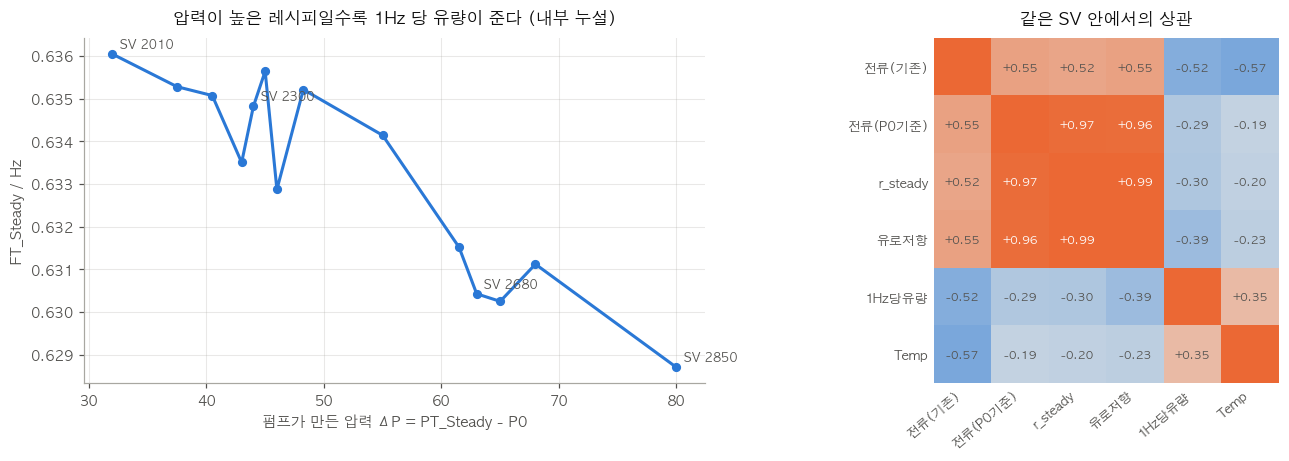

In [55]:
TAG_HZ = f"Hz_Out_{PUMP_ID}"
_rows = []
for cid, seg in _dr[_bur == 1].groupby("cid"):
    if cid not in K.index or len(seg) < 8:
        continue
    sv = float(seg[TAG_SV].iloc[0])
    ft = seg[TAG_FT].values.astype(float); pt = seg[TAG_PT].values.astype(float)
    hz = seg[TAG_HZ].values.astype(float)
    ins = np.abs(ft - sv) <= .03 * sv
    if not ins.any():
        continue
    j = int(np.argmax(ins)); st = np.zeros(len(ft), bool); st[j:] = True; st &= ~seg["shot"].values
    if st.sum() < 3:
        continue
    s2 = np.arange(len(ft)) >= 2
    _rows.append(dict(SV=K.loc[cid, "SV_class"], Start=seg["Time"].iloc[0],
                      Temp=float(seg[TAG_TEMP].mean()), P0=float(K.loc[cid, "PreBuildUp_PT"]),
                      P=np.median(pt[st]), Q=np.median(ft[st]), H=np.median(hz[st]),
                      I_orig=np.nanmean(pt[s2] * ft[s2] / np.where(hz[s2] == 0, np.nan, hz[s2]))))
CU = pd.DataFrame(_rows)
CU["r_steady"] = (CU["P"] - CU["P0"]) / CU["SV"].map((CU["P"] - CU["P0"]).groupby(CU["SV"]).median())
CU["저항"] = (CU["P"] - CU["P0"]) / (CU["Q"] / 1000) ** 2.5
CU["eta_v"] = CU["Q"] / CU["H"]                              # 1Hz 당 유량
CU["I_new"] = (CU["P"] - CU["P0"]) * CU["Q"] / CU["H"]       # P0 기준으로 다시 낸 전류 추정

print("=== Hz 는 무엇이 정하나 ===")
print(f"  η²(Hz | SV) = {eta_squared(CU['H'], CU['SV']):.4f}")
_g = CU.groupby("SV").agg(n=("H", "size"), Hz=("H", "median"), eta_v=("eta_v", "median"),
                          ΔP=("P", "median"), P0=("P0", "median"))
_g = _g[_g["n"] >= 50]; _g["ΔP"] = _g["ΔP"] - _g["P0"]; _g["Hz/SV"] = _g["Hz"] / _g.index
print(_g[["n", "Hz", "Hz/SV", "ΔP", "eta_v"]].round(4).to_string())
print(f"\n  클래스별: corr(ΔP, 1Hz당 유량) = {np.corrcoef(_g['ΔP'], _g['eta_v'])[0,1]:+.3f}"
      "   (압력이 높을수록 내부 누설이 늘어 덜 나온다)")

_cday = pd.to_datetime(CU["Start"]).dt.normalize()
def _cw(s): return s - s.groupby(CU["SV"]).transform("mean")
print("\n=== 피처 성질 ===")
rows_ = []
for nm, s in [("전류추정 (기존)", CU["I_orig"]), ("전류추정 (P0 기준)", CU["I_new"]),
              ("r_steady", CU["r_steady"]), ("유로 저항", CU["저항"]), ("1Hz당 유량", CU["eta_v"])]:
    w = _cw(s); dd = w.groupby(_cday).mean()
    rows_.append({"피처": nm, "η²(SV)": eta_squared(s, CU["SV"]), "Temp 상관": w.corr(_cw(CU["Temp"])),
                  "lag-1": w.autocorr(1), "일자 흔들림σ": (dd.max() - dd.min()) / w.std(),
                  "클래스내 CV%": (s.groupby(CU["SV"]).std() / s.groupby(CU["SV"]).mean()).median() * 100})
print(pd.DataFrame(rows_).set_index("피처").round(3).to_string())

WC = pd.DataFrame({"전류(기존)": _cw(CU["I_orig"]), "전류(P0기준)": _cw(CU["I_new"]),
                   "r_steady": _cw(CU["r_steady"]), "유로저항": _cw(CU["저항"]),
                   "1Hz당유량": _cw(CU["eta_v"]), "Temp": _cw(CU["Temp"])}).corr()
print("\n=== 같은 SV 안에서의 상관 ===")
print(WC.round(3).to_string())

fig, ax = plt.subplots(1, 2, figsize=(13.5, 4.3), gridspec_kw={"width_ratios": [1, 1.15]})
ax[0].plot(_g["ΔP"], _g["eta_v"], color=C1, lw=2, marker="o", ms=5)
for sv_, r_ in _g.iterrows():
    if int(sv_) in (2010, 2300, 2680, 2850):
        ax[0].annotate(f"SV {int(sv_)}", xy=(r_["ΔP"], r_["eta_v"]), xytext=(5, 4),
                       textcoords="offset points", fontsize=8, color=INK2)
ax_style(ax[0], "압력이 높은 레시피일수록 1Hz 당 유량이 준다 (내부 누설)",
         "펌프가 만든 압력 ΔP = PT_Steady - P0", "FT_Steady / Hz")
im = ax[1].imshow(WC.values, cmap=DIV, vmin=-1, vmax=1)
ax[1].set_xticks(range(len(WC)), WC.columns, rotation=40, ha="right", fontsize=8.5)
ax[1].set_yticks(range(len(WC)), WC.index, fontsize=8.5)
for i in range(len(WC)):
    for j in range(len(WC)):
        if i != j:
            v = WC.values[i, j]
            ax[1].text(j, i, f"{v:+.2f}", ha="center", va="center", fontsize=7.5,
                       color="white" if abs(v) > .72 else INK2)
ax[1].grid(False); ax[1].tick_params(length=0, colors=INK2)
for s_ in ax[1].spines.values(): s_.set_visible(False)
ax[1].set_title("같은 SV 안에서의 상관", fontsize=11, color=INK, pad=10)
plt.tight_layout(); plt.show()

## 14-1. 결론

**1. 전류 부하는 지금 데이터로 잴 수 없다.** 전기 쪽 신호가 명령 Hz 하나뿐이고, 그것도 SV 로 정해진다.

**2. `Current_Proxy_I` 는 뺀다 — 압력과 1Hz당 유량을 곱한 값일 뿐이다.**

- 정용량 펌프의 토크는 `압력 × 배제용적` 에 비례하므로, 이 추정식은 원리상 **압력을 다시 보는 것**이다
- P0 를 빼고 다시 계산하면 `r_steady` 와 같은 SV 안에서 **상관 0.966**
- 기존 값이 조금 달라 보였던 건 P0 를 안 빼서 **온도를 따라갔기** 때문이다 (Temp 상관 −0.57)
- 같은 SV 안에서 Hz 는 상수라, 수식상 `전류(P0 기준) ∝ r_steady × 1Hz당유량` 이다. 두 피처로 이미 표현된다

**3. 대신 `FT / Hz` (1Hz 당 유량) 를 새 피처로 넣는다.**

| 성질 | 값 | 뜻 |
|---|---|---|
| 레시피별 | ΔP 32 → 80 에서 0.636 → 0.629, **ΔP 와 −0.92** | 압력이 높을수록 내부 누설이 는다 — 정용량 펌프 교과서 그대로 |
| 같은 SV 안 흩어짐 | **CV 0.21%** | 아주 촘촘해서 작은 변화가 보인다 |
| `r_steady` 와 | 같은 SV 안 −0.30 | 압력과 **다른 정보** |
| lag-1 / 일자 흔들림 | 0.36 / 1.17σ | 느리게 변하는 성분이 있다 |

펌프가 마모되면 내부 누설이 늘어 같은 회전수에서 유량이 덜 나온다 → 이 값이 떨어진다.
마모는 천천히 진행되므로 **추세 피처가 주된 역할**이고, 사이클 AE 입력으로도 넣는다.
갑작스러운 큰 누설은 유량이 크게 줄어 FT 타임아웃·`t_cross` 가 먼저 잡는다.

**4. 세 피처를 같이 보면 원인이 갈린다** (가상 시나리오 기준 — 실제 고장으로 확인 필요)

| 고장 | `r_steady` | 유로 저항 | 1Hz당 유량 |
|---|---|---|---|
| 펌프 내부 마모 (누설↑) | ↓ | 그대로 | **↓** |
| 노즐·필터 막힘 | ↑ | **↑** | 약간 ↓ (압력↑ → 누설↑) |
| 유량계 뒤쪽 바이패스·누설 | ↓ | **↓** | 그대로 |

**남는 것**

- 같은 SV 안에서 1Hz당 유량이 온도와 **+0.35** — 뜨거우면 더 나온다. 점도가 낮아지면 누설이 늘어 오히려 줄 것 같은데
  반대다. 뜨거우면 압력이 덜 걸려(−0.2) 누설이 줄어드는 경로로 보이지만 이 데이터로는 확정 못 한다
- 실제 전류를 보고 싶으면 **인버터 출력 전류를 로깅 대상에 추가**해야 한다. 인버터는 보통 출력 전류를 내준다.
  그러면 이 추정식이 못 보는 **기계 손실**(베어링 마찰 등)까지 보인다


## 14-2. 역산한 부하를 "시간 거동" 으로 쓰기 — 과부하 지속, 휘청

의도: 실제 전류가 없으니 **지금 압력·유량이면 모터가 받아야 할 부하**를 틱마다 역산하고,
그게 **오래 높게 머무는지(과부하 지속)**, **흔들리는지(휘청)** 를 본다.
사이클 평균 하나로 줄이면 `r_steady` 와 겹치지만(14-1), 틱 단위 시간 거동은 용도가 다르다.

```
부하율(t) = [(PT(t) − P0) · FT(t) / Hz] / 그 SV 의 평소 부하
```

P0 를 빼는 이유는 14-1 과 같다 (안 빼면 온도를 따라간다).


=== 틱 단위 부하율 (평소 = 1) ===
  안정·비사출 틱  중앙 1.000   p1 0.853   p99 1.170
  사출 영향 틱    중앙 0.957   p1 0.545   p99 1.157
  사출 때 부하 최저점 - 평소: 중앙 -0.261  <- 정상적인 '휘청'

=== 사이클 안 흔들림 (안정 구간 부하율 표준편차) ===
  사출 포함 중앙 0.0960   사출 제외 중앙 0.0336
  사출 제외 흔들림 vs PT 흔들림 상관 +0.766


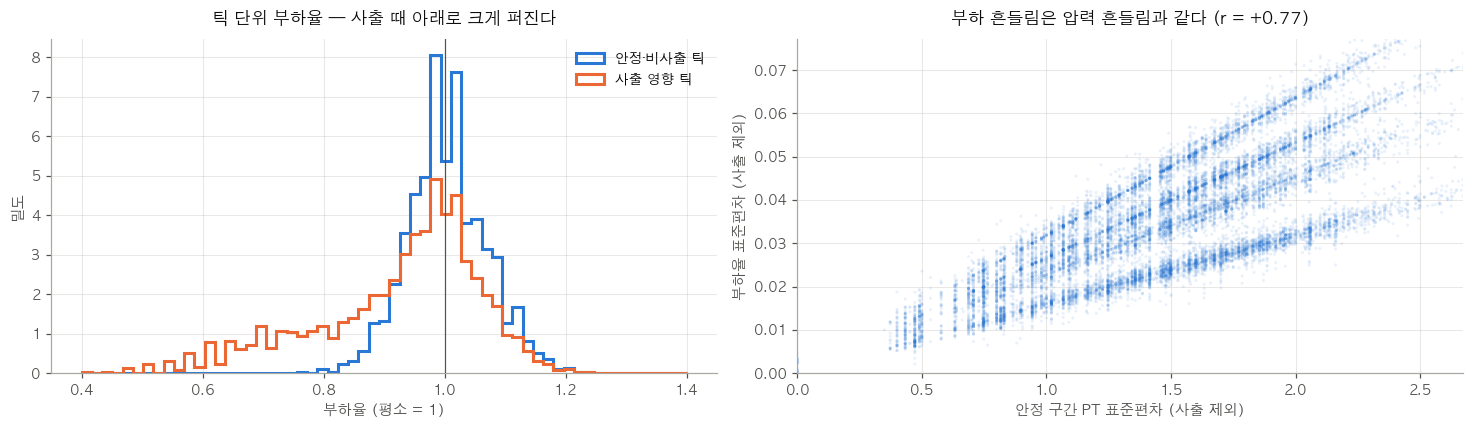

In [56]:
_L = []
for cid, seg in _dr[_bur == 1].groupby("cid"):
    if cid not in K.index or len(seg) < 8:
        continue
    sv = float(seg[TAG_SV].iloc[0])
    ft = seg[TAG_FT].values.astype(float); pt = seg[TAG_PT].values.astype(float)
    hz = seg[TAG_HZ].values.astype(float); sh = seg["shot"].values
    ins = np.abs(ft - sv) <= .03 * sv
    if not ins.any():
        continue
    j = int(np.argmax(ins)); st = np.zeros(len(ft), bool); st[j:] = True
    if (st & ~sh).sum() < 3:
        continue
    L = (pt - float(K.loc[cid, "PreBuildUp_PT"])) * ft / np.where(hz == 0, np.nan, hz)
    _L.append(dict(SV=K.loc[cid, "SV_class"], L=L, st=st, sh=sh, pt=pt,
                   Lss=np.median(L[st & ~sh])))
LD = pd.DataFrame(_L)
LREF = LD.groupby("SV")["Lss"].median()                   # SV 별 평소 부하 (기준표)

ns_all, sh_all, fl_ns, fl_all, pt_fl, dip = [], [], [], [], [], []
for r in LD.itertuples():
    lr = r.L / LREF[r.SV]
    ns, ws = r.st & ~r.sh, r.st & r.sh
    ns_all += list(lr[ns]); sh_all += list(lr[ws])
    fl_ns.append(np.nanstd(lr[ns])); fl_all.append(np.nanstd(lr[r.st]))
    pt_fl.append(np.std(r.pt[ns]))
    if ws.any():
        dip.append(np.nanmin(lr[ws]) - np.nanmedian(lr[ns]))
ns_all, sh_all = np.array(ns_all), np.array(sh_all)

print("=== 틱 단위 부하율 (평소 = 1) ===")
print(f"  안정·비사출 틱  중앙 {np.nanmedian(ns_all):.3f}   p1 {np.nanpercentile(ns_all,1):.3f}   p99 {np.nanpercentile(ns_all,99):.3f}")
print(f"  사출 영향 틱    중앙 {np.nanmedian(sh_all):.3f}   p1 {np.nanpercentile(sh_all,1):.3f}   p99 {np.nanpercentile(sh_all,99):.3f}")
print(f"  사출 때 부하 최저점 - 평소: 중앙 {np.median(dip):+.3f}  <- 정상적인 '휘청'")
print("\n=== 사이클 안 흔들림 (안정 구간 부하율 표준편차) ===")
print(f"  사출 포함 중앙 {np.median(fl_all):.4f}   사출 제외 중앙 {np.median(fl_ns):.4f}")
print(f"  사출 제외 흔들림 vs PT 흔들림 상관 {pd.Series(fl_ns).corr(pd.Series(pt_fl)):+.3f}")

fig, ax = plt.subplots(1, 2, figsize=(13.5, 4.0))
_b = np.linspace(.4, 1.4, 60)
ax[0].hist(np.clip(ns_all, .4, 1.4), bins=_b, density=True, histtype="step", lw=2, color=C1, label="안정·비사출 틱")
ax[0].hist(np.clip(sh_all, .4, 1.4), bins=_b, density=True, histtype="step", lw=2, color=C2, label="사출 영향 틱")
ax[0].axvline(1, color=INK2, lw=.8)
ax[0].legend(frameon=False, fontsize=9)
ax_style(ax[0], "틱 단위 부하율 — 사출 때 아래로 크게 퍼진다", "부하율 (평소 = 1)", "밀도")
ax[1].scatter(pt_fl, fl_ns, s=4, alpha=.1, color=C1, edgecolors="none")
ax[1].set_xlim(0, np.percentile(pt_fl, 99.5)); ax[1].set_ylim(0, np.percentile(fl_ns, 99.5))
ax_style(ax[1], f"부하 흔들림은 압력 흔들림과 같다 (r = {pd.Series(fl_ns).corr(pd.Series(pt_fl)):+.2f})",
         "안정 구간 PT 표준편차 (사출 제외)", "부하율 표준편차 (사출 제외)")
plt.tight_layout(); plt.show()

### 14-2 판정 — "유압 부하율" 로 쓰면 된다. 단 전류 대용은 아니다

**쓸 수 있는 것**

- 정상 안정 구간의 틱 부하율은 평소의 **0.85 ~ 1.17** (p1~p99). 이 범위를 벗어난 상태가
  **몇 초 이상 계속되면 과부하 지속**으로 볼 수 있다. 숫자는 모델 만들 때 정상 오경보로 정한다
- 레시피가 달라도 "평소 = 1" 로 맞춰져 있어서 **화면에 하나의 부하 게이지**로 보여주기 좋다

**조심할 것 세 가지**

1. **사출이 정상적인 휘청을 만든다.** 사출 때 부하가 평소보다 **26%** 떨어진다(최저점 중앙).
   흔들림을 볼 때 사출 구간을 빼지 않으면 사출 횟수를 세게 된다 (12-3 의 `Steady_Std_PT` 와 같은 문제)
2. **사출을 빼면 부하 흔들림 = 압력 흔들림이다** (상관 0.77). 같은 사이클 안에서 Hz 는 상수이고 FT 는 거의 안 움직이니,
   부하의 오르내림은 압력이 만든다. **AE 입력으로는 `PT_Steady_Std` 와 중복**이라 넣지 않는다.
   부하율은 사람이 보는 지표·규칙·추세용이다
3. **이 값은 "유압 쪽 부하" 만 본다 — 실제 전류와 반대로 움직일 수도 있다.**
   베어링·커플링 같은 **기계 쪽 문제**는 실제 전류를 올리지만 압력·유량엔 안 나타난다.
   오히려 마찰로 모터가 조금 느려지면(V/f 인버터의 슬립 증가) **유량이 줄어 역산 부하는 내려간다.**
   그래서 이 값의 이름은 "전류" 가 아니라 **"유압 부하율"** 이어야 오해가 없다

**절대값 과부하(모터 정격 대비)는 지금은 못 본다.** 평소 대비 상대값만 가능하다.
절대값을 보려면 펌프 배제용적(`A2VK` 크기), PT·FT 의 실제 단위, 모터 정격이 필요하다.


---
# 15. 복귀 구간 — `Decay_Slope` 는 그대로 쓸 수 있나

기존 정의: `BuildUp` 이 꺼진 뒤 **3초 창**에서 PT(FT)를 시간에 대해 1차 회귀한 기울기.
설명서 8장은 이 값이 끝압력에 끌려다닌다고 보고 회귀로 보정했다.

"지수적으로 빠진다면 직선 기울기는 끝압력에 비례한다" 고 예상하고 곡선을 직접 봤는데,
**모양 자체가 달랐다.** 그림을 먼저 본다.

**그림 선택**: 꺼진 순간을 0 으로 맞추고, PT·FT·Hz 를 각각 "운전값 = 1, 공백값 = 0" 으로 정규화해
**한 축에** 놓는다 (단위를 없앴으니 이중축이 아니다). 중앙값 선 + 사분위 띠.


/Users/jeonjae/Desktop/KTA/DB_Log/venv/lib/python3.13/site-packages/numpy/_core/fromnumeric.py:3824: RuntimeWarning: Mean of empty slice
  return _methods._mean(a, axis=axis, dtype=dtype,
/Users/jeonjae/Desktop/KTA/DB_Log/venv/lib/python3.13/site-packages/numpy/_core/_methods.py:142: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


꺼짐 이벤트 16,882개



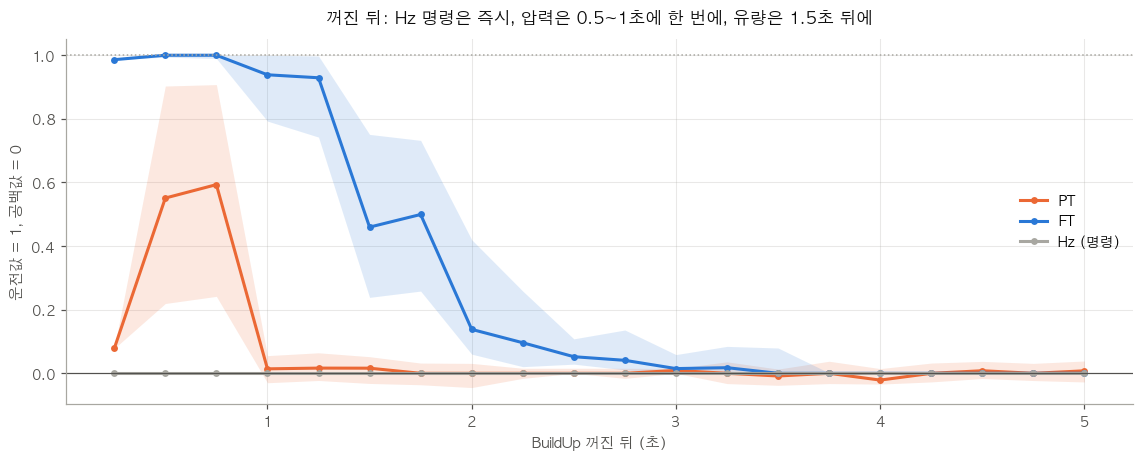

=== 사이클 사이 공백 구간 (라인 가동 중) ===
  Hz 명령 : {2000.0: 1.0}
  FT      : {1285.0: 0.493, 1271.0: 0.089, 1300.0: 0.025}
  FT / Hz = 0.6425  (운전 중 1Hz당 유량 ≈ 0.63 과 거의 같다 -> 1285 는 20Hz 로 도는 실제 유량)


In [57]:
_b = _bur.values
_T = _dr["Time"].values
_PTa = _dr[TAG_PT].values.astype(float); _PTa = np.where(_PTa > 32767, _PTa - 65536, _PTa)
_FTa = _dr[TAG_FT].values.astype(float); _HZa = _dr[TAG_HZ].values.astype(float)
_cida = _dr["cid"].values
_ends = np.where((_b[:-1] == 1) & (_b[1:] == 0))[0]

DEC, _traj = [], []
for e in _ends:
    cid = _cida[e]
    if cid not in K.index:
        continue
    k, seg = e + 1, []
    while k < len(_T) and _b[k] == 0 and (_T[k] - _T[e]) / np.timedelta64(1, "s") <= 5.0:
        seg.append(k); k += 1
    if len(seg) < 4:
        continue
    tt = (_T[seg] - _T[e]) / np.timedelta64(1, "s")
    if tt[-1] < 3:
        continue
    pe, fe, he = _PTa[e], _FTa[e], _HZa[e]
    pt, ft, hz = _PTa[seg], _FTa[seg], _HZa[seg]
    pfl = np.median(pt[(tt >= 2) & (tt <= 3)])
    _traj.append((tt, (pt - pfl) / (pe - pfl) if pe != pfl else pt * np.nan,
                  (ft - 1285) / (fe - 1285), (hz - 2000) / (he - 2000)))

    def half(x0, x, floor):                         # 실제 기록점 사이 보간으로 중간값을 지난 시각
        tr, xr = np.r_[0.0, tt], np.r_[x0, x]
        keep = np.r_[True, np.diff(xr) != 0]; tr, xr = tr[keep], xr[keep]
        lvl = (x0 + floor) / 2; idx = np.where(xr <= lvl)[0]
        if len(idx) == 0 or idx[0] == 0:
            return np.nan
        i = idx[0]; return tr[i-1] + (lvl - xr[i-1]) / (xr[i] - xr[i-1]) * (tr[i] - tr[i-1])
    w = tt <= 3
    DEC.append(dict(cid=cid, SV=K.loc[cid, "SV_class"], Start=_T[e], first_rec=tt[0],
                    slopePT=np.polyfit(tt[w], pt[w], 1)[0], slopeFT=np.polyfit(tt[w], ft[w], 1)[0],
                    tPT=half(pe, pt, pfl), tFT=half(fe, ft, 1285.0)))
DC = pd.DataFrame(DEC)
print(f"꺼짐 이벤트 {len(DC):,}개\n")

grid = np.arange(0.25, 5.01, 0.25)
prof = {}
for name, idx in [("PT", 1), ("FT", 2), ("Hz (명령)", 3)]:
    vals = [[] for _ in grid]
    for tr in _traj:
        for gi, gt in enumerate(grid):
            m = (tr[0] > gt - .25) & (tr[0] <= gt)
            if m.any():
                vals[gi].append(tr[idx][m][-1])
    prof[name] = [(np.nanmedian(v), np.nanpercentile(v, 25), np.nanpercentile(v, 75)) if v else (np.nan,)*3
                  for v in vals]

fig, ax = plt.subplots(figsize=(10.5, 4.3))
for (name, rows_), c in zip(prof.items(), [C2, C1, GRAY]):
    med = [r[0] for r in rows_]; lo = [r[1] for r in rows_]; hi = [r[2] for r in rows_]
    ax.fill_between(grid, lo, hi, color=c, alpha=.15, lw=0)
    ax.plot(grid, med, color=c, lw=2, marker="o", ms=3.5, label=name)
ax.axhline(0, color=INK2, lw=.8); ax.axhline(1, color=GRAY, ls=":", lw=1)
ax.legend(frameon=False, fontsize=9, loc="center right")
ax_style(ax, "꺼진 뒤: Hz 명령은 즉시, 압력은 0.5~1초에 한 번에, 유량은 1.5초 뒤에",
         "BuildUp 꺼진 뒤 (초)", "운전값 = 1, 공백값 = 0")
plt.tight_layout(); plt.show()

print("=== 사이클 사이 공백 구간 (라인 가동 중) ===")
_idle = (_bur == 0) & (_dr["Auto_Running"].fillna(0).values != 0)
print(f"  Hz 명령 : {pd.Series(_HZa[_idle]).value_counts(normalize=True).head(2).round(3).to_dict()}")
print(f"  FT      : {pd.Series(_FTa[_idle]).value_counts(normalize=True).head(3).round(3).to_dict()}")
_m = _idle & (_HZa == 2000) & (_FTa > 1000)
print(f"  FT / Hz = {np.median(_FTa[_m] / _HZa[_m]):.4f}  (운전 중 1Hz당 유량 ≈ 0.63 과 거의 같다 -> 1285 는 20Hz 로 도는 실제 유량)")

## 15-1. 꺼진 뒤 실제로 일어나는 일

그림이 보여주는 순서:

| 시점 | 무엇이 | 뜻 |
|---|---|---|
| 0초 | **Hz 명령이 즉시 2000(20Hz)** 으로 | 인버터에 저속 명령 |
| 0.5~1초 | **압력이 한 번에** 바닥으로 | 밸브가 열려 압력을 뺀다 (유량은 아직 운전 수준인데 압력이 먼저 빠짐) |
| 1.5초까지 | **유량은 운전값 그대로** | 모터가 아직 감속 중 (또는 유량계 응답 지연) |
| 1.5~2.5초 | 유량이 1285 로 | 20Hz 로 도는 유량에 도달 |

**그리고 이걸로 앞의 설명 두 개를 바로잡는다.**

- 사이클 사이에 **펌프는 멈추지 않는다.** 라인이 도는 동안 공백 구간 Hz 는 항상 2000(20Hz)이고,
  유량 1285 는 **"정지값" 이 아니라 20Hz 로 도는 실제 유량**이다 (1285/2000 = 0.6425, 운전 중 1Hz당 유량 ≈ 0.63).
  FT = 0 은 라인이 정지했을 때다
- 그래서 `PreBuildUp_FT` 는 "정보 없는 값" 이 아니라 **낮은 압력에서의 1Hz당 유량**이다.
  다만 1285(72%) / 1271(13%) 처럼 계단 값이라 분해능이 약 1% 로 거칠다. 추세 후보로만 남긴다
- `t_cross` 가 직전 상태와 무관했던 이유(9-12)도 "펌프가 멈춰서" 가 아니라
  **매번 같은 20Hz 공회전 상태에서 시작하기 때문**이다. 결론은 같다

## 15-2. 그러면 `Decay_Slope` 는


In [58]:
_dday = pd.to_datetime(DC["Start"]).dt.normalize()
def _dw(s): return s - s.groupby(DC["SV"]).transform("mean")
rows_ = []
for nm, s in [("Decay_Slope_PT (기존)", DC["slopePT"]), ("Decay_Slope_FT (기존)", DC["slopeFT"]),
              ("압력 해제 시각 (PT 반감, 초)", DC["tPT"]), ("감속 시각 (FT 반감, 초)", DC["tFT"])]:
    w = _dw(s); dd = w.groupby(_dday).mean()
    rows_.append({"피처": nm, "중앙": s.median(), "η²(SV)": eta_squared(s, DC["SV"]),
                  "lag-1": w.autocorr(1), "일자 흔들림σ": (dd.max() - dd.min()) / w.std(),
                  "CV%": s.std() / abs(s.mean()) * 100})
print("=== 복귀 구간 피처 성질 ===")
print(pd.DataFrame(rows_).set_index("피처").round(3).to_string())

print("\n=== 압력 해제 시각은 기록 타이밍을 보고 있나 ===")
print(f"  꺼진 뒤 첫 기록 시각 중앙 {DC['first_rec'].median():.3f}초")
print(f"  corr(압력 해제 시각, 첫 기록 시각) = {DC['tPT'].corr(DC['first_rec']):+.3f}")

print("\n=== 규칙용 정상 꼬리 ===")
for c, nm in [("tPT", "압력 해제"), ("tFT", "감속")]:
    q = DC[c].quantile([.5, .99, .999])
    print(f"  {nm:6s} 중앙 {q.iloc[0]:.2f}초   p99 {q.iloc[1]:.2f}초   p99.9 {q.iloc[2]:.2f}초   최대 {DC[c].max():.2f}초")

print("\n=== 여러 사이클 평균으로 흔들림이 얼마나 줄어드나 (추세용) ===")
_DS = DC.sort_values("Start")
for c, nm in [("tPT", "압력 해제"), ("tFT", "감속")]:
    s = _DS[c] - _DS.groupby("SV")[c].transform("median")
    print(f"  {nm:6s} " + "   ".join(f"{N}사이클 {s.rolling(N).mean().std():.3f}초" for N in (1, 30, 100, 300)))

=== 복귀 구간 피처 성질 ===
                          중앙  η²(SV)  lag-1  일자 흔들림σ     CV%
피처                                                          
Decay_Slope_PT (기존)  -10.541   0.288  0.011    0.209  73.999
Decay_Slope_FT (기존) -472.852   0.787 -0.020    0.109  29.382
압력 해제 시각 (PT 반감, 초)    0.595   0.030  0.004    0.102  41.170
감속 시각 (FT 반감, 초)       1.376   0.019  0.065    0.065  21.670

=== 압력 해제 시각은 기록 타이밍을 보고 있나 ===
  꺼진 뒤 첫 기록 시각 중앙 0.522초
  corr(압력 해제 시각, 첫 기록 시각) = +0.529

=== 규칙용 정상 꼬리 ===
  압력 해제  중앙 0.60초   p99 1.31초   p99.9 1.80초   최대 1.88초
  감속     중앙 1.38초   p99 2.23초   p99.9 2.78초   최대 2.93초

=== 여러 사이클 평균으로 흔들림이 얼마나 줄어드나 (추세용) ===
  압력 해제  1사이클 0.239초   30사이클 0.047초   100사이클 0.027초   300사이클 0.017초
  감속     1사이클 0.299초   30사이클 0.068초   100사이클 0.048초   300사이클 0.033초


### 15-3. 결론 — `Decay_Slope` 는 쓰지 않고, 시각 두 개로 바꾼다

**기존 `Decay_Slope` 를 쓰지 않는 이유**

- 곡선이 지수 감쇠가 아니라 **계단(압력)** 과 **지연 후 하강(유량)** 이다. 3초 창에 직선을 맞추면
  "얼마나 떨어졌나(크기)" 와 "언제 떨어졌나(시점)" 가 섞인다. 크기는 끝값이 이미 알려준다
- 같은 SV 안에서 보면 둘 다 **잡음**이다 — `Decay_Slope_PT` CV 74%, lag-1 0.01.
  `Decay_Slope_FT` 는 레시피 의존(η² 0.79)이 전부이고 같은 SV 안에선 lag-1 −0.02

**대신 쓸 것: 두 개의 시각** (둘 다 레시피·온도와 무관: η² 0.03 / 0.02)

| 피처 | 뜻 | 정상 | 한 사이클 | 여러 사이클 평균 |
|---|---|---|---|---|
| **압력 해제 시각** (PT 반감) | 밸브가 열려 압력이 빠지는 속도 | 중앙 0.6초, p99.9 1.8초 | **기록 타이밍 흔들림이 대부분** (첫 기록 시각과 +0.53) | 100사이클 평균 흔들림 0.027초 |
| **감속 시각** (FT 반감) | 모터가 20Hz 로 감속하는 속도 | 중앙 1.4초, p99.9 2.8초 | 흔들림 ±0.3초 | 100사이클 평균 흔들림 0.048초 |

**그래서 쓰는 방법**

| 층 | 방법 |
|---|---|
| ① 실시간 규칙 | 압력이 **2초가 지나도** 절반 이상 남아 있으면 "압력 미해제" (밸브 고착 의심) · 유량이 **3초가 지나도** 절반 이상이면 "감속 이상" |
| ① 틱 AE | 복귀 구간 one-hot + 경과시간 + PT·FT 로 모양 자체를 학습 — 따로 요약 피처가 필요 없다 |
| ② 사이클 AE | **넣지 않는다.** 한 사이클 값은 대부분 기록 타이밍 흔들림이다 |
| ③ 추세 | 기록 테이블에 두 시각을 남기고 **100사이클 이상 평균**으로 본다. 0.1초 수준의 변화가 보인다 |

**한계**

- 압력은 **기록 간격(0.5초)보다 빨리** 빠진다. 86% 사이클에서 꺼진 뒤 첫 기록에 이미 떨어져 있다.
  그래서 한 사이클로는 "0.5초 안에 빠졌다" 까지만 안다
- 두 시각은 **기록 주기에 직접 영향을 받는다.** 09-26~27 처럼 로거가 느려지면 설비와 무관하게 시각이 늘어난다.
  추세에서 이 값이 움직이면 **틱 밀도부터 확인**해야 한다
- 유량이 1.5초 늦게 떨어지는 게 모터 감속인지 유량계 응답 지연인지는 이 데이터로 못 가린다.
  증압 때도 유량이 압력보다 1~2틱 늦었으니(10-1) 유량계 지연이 섞였을 가능성이 있다


---
## 다음

위 출력에서 확인할 것:

- 필수 태그 9개 전부 `O`
- 모든 날 500 사이클 이상 (아니면 그 날을 빼야 한다)
- 시간당 틱 수 그래프가 평평한가
- 학습 가용 사이클 비율

- `Dirty` 사이클 수가 `Excluded_Alarm` 보다 훨씬 큰가 (현재 규칙이 놓치고 있다는 뜻)

들고 가는 것:

| 이름 | 단위 | 내용 |
|---|---|---|
| `raw` | 틱 | 전체 원본 (추출기 입력) |
| `raw_clean` | 틱 | 알람/정지 틱 제거 — **그림용, 추출기에 넣지 말 것** |
| `cyc` | 사이클 | 전체 + 플래그 (`Alarm_Any`, `Line_Stopped`, `In_Low_Density`, `Dirty`) |
| `cyc_clean` | 사이클 | **통계·분포·AE 학습용** |

외생 정규화가 동작하는 걸 확인했다. 다음 후보:
- `ExogenousNormalizer` 를 `parkkt/` 모듈로 빼서 `Cycle_AE_v3` 에 연결
- 6-3 에서 남은 칸(클래스 고유 특징) 파고들기
- 남은 물리 지표 `DeltaP_over_Q`, `Decay_Slope_*`, `Steady_Std_*`